# Momentum outliers — v7: corrected profitability inference and survivorship sensitivity

**Goal:** Recheck the historical outlier-risk result, interpret trading claims using **a one-sided test of positive net returns with directions frozen before 2016**, and quantify how large *unobserved missing-stock effects* would have to be to change the result. The missing-stock scenarios are **NOT empirical estimates** of survivorship bias.

### What changed in v7

- Section 30 now uses **one-sided positive-return p-values**, BH-adjusted *within the fixed-direction 44 headline tests and 16 post-hoc tests*. It keeps two-sided p-values as diagnostics, so large negative t statistics cannot make unrelated positive results appear significant by changing BH ranks. Borrow-rate sensitivity grids are exploratory; **100 bps/year** is the designated reference.
- Section 36 only provides opening-price significance tests when *all required formation-weighted opening fills are observed*. Otherwise it reports coverage and illustrative scenarios but **does not claim implementable profits**.
- Section 41 provides a **quantitative missing-stock sensitivity analysis** (assumed fraction excluded, assumed missing-stock hit rates, and tipping-point fractions), and distinguishes it from a measured direct bias estimate.
- Section 42 regenerates camera figures from **fixed-direction** results and the newer **52-week-volatility-adjusted** association. The camera scorecard from earlier exploratory sections is overwritten with the corrected recent-period one.
- Optionally, sections 37–39 still accept an institutionally authorized, delisting-inclusive CRSP point-in-time security panel for a **direct** comparison; no such dataset is bundled, fetched or assumed.

### Run it

Use **Run All** with your existing `data_momentum/` cache. `UPDATE_PRICES_TO` defaults to **2026-10-16** to request updated prices after your last cached week; set it back to `None` if you don't want the extra downloads. This does **not** download licensed historical-security databases. All new outputs are written to `outputs_v7/` (older output directories are untouched).



In [1]:
# Run once if needed:
# %pip install -q yfinance statsmodels scipy lxml requests matplotlib

In [2]:
import io, re, json, time, zipfile, hashlib, warnings, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 500)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

VERSION = "v7"             # new figures and tables; never overwrite older runs
DATA_DIR = Path("data_momentum"); DATA_DIR.mkdir(exist_ok=True)      # same cache as v1 and v2
OUT_DIR = Path(f"outputs_{VERSION}"); OUT_DIR.mkdir(exist_ok=True)

# ---- Universe and download (unchanged since v1)
SEC_USER_AGENT = "Your Name your.email@example.com"   # SEC asks for a real name and email in every request
UNIVERSE = "us_all"        # "us_all": every NYSE / Nasdaq company in the SEC's ticker list; "sp500": only today's S&P 500 (quick test)
MAX_TICKERS = None         # e.g. 300 for a first pass; None = everything
REFRESH_UNIVERSE = False   # False: reuse the cached SEC ticker list, so the price chunks match and nothing re-downloads.
                           # True: fetch today's list (changes the chunks, so all prices download again)
EXCLUDE_FOREIGN_INC = True
START, END = "1990-01-01", None
CHUNK = 100
IND_N = 49

# ---- Design (fix these before looking at results)
WEEK = "W-FRI"
LOOKBACKS = {"1w": (1, 0), "1m": (4, 0), "1m-1w": (4, 1), "3m": (13, 0), "3m-1m": (13, 4),
             "6m": (26, 0), "6m-1m": (26, 4), "12-1": (52, 4)}   # (weeks back, most recent weeks skipped)
MAIN_LBS = ["1w", "1m", "12-1"]
Z_OUTLIER = 2.0            # stock outlier: |robust z| > 2
Z = Z_OUTLIER
Z_IND = 1.5                # industry outlier threshold (a 49-industry cross-section is thin)
HOLDS = [1, 2, 4, 8, 13]   # holding periods in weeks (overlapping cohorts)
GRID_HOLDS = [1, 4, 13]    # holds used in the big outlier grid (section 19 uses all of HOLDS)
RECENT_YEARS = 10
MIN_PRICE = 5.0
MIN_DVOL_PCTILE = 0.20
BETA_WINDOW, BETA_MIN = 104, 52

# ---- Costs
COST_MODEL = "ar_pooled"   # "ar_pooled": Abdi & Ranaldo pooled by liquidity x volatility group (default);
                           # "ar": per-stock Abdi & Ranaldo (v2 default); "cs_adj": Corwin & Schultz with overnight adjustment; "cs_raw": v1's estimate
POOL_WINDOW = 52           # weeks of stock-days pooled in each group's estimate
POOL_DV_BUCKETS, POOL_VOL_BUCKETS = 10, 3   # dollar-volume deciles x volatility terciles (within each decile) = 30 groups a week
COST_WINDOW = 13           # weeks behind each per-stock estimate ("ar", "cs_adj")
COST_FLOOR_BPS = 1.0       # one-way floor on the estimated half-spread
COST_CAP = 0.05            # one-way cap (5%)
COMMISSION_BPS = 0.0       # per side, on top of the half-spread
FLAT_COST_GRID_BPS = [0, 10, 25, 50]
IND_COST_BPS = 5.0         # per side for industry portfolios (e.g. sector ETFs)
BORROW_BPS_PER_YEAR = 0.0

# ---- News (section 13)
NEWS = True                # 8-K histories from EDGAR (cached by v2; a fresh fetch takes ~30 min)
NEWS_START = "2005-01-01"  # 8-K Item 2.02 (earnings releases) is tagged reliably from late 2004

# ---- Checks and on-camera tables
LOOSE_MIN_PRICE = 1.0      # price floor for the "loose" replication universe (section 7)
CAMERA_MIN_DVOL_M = 10.0   # on-camera outlier lists: 13-week median dollar volume of at least $10M a day
MIN_IND_STOCKS = 15        # current-industry table: hide industries with fewer eligible stocks

# Plain-English names for the Fama–French 49 industries (camera figures and the snapshot; moved here in v4.1)
FF49_NAMES = {"Agric": "Agriculture", "Food": "Food products", "Soda": "Candy & soda", "Beer": "Beer & liquor",
              "Smoke": "Tobacco", "Toys": "Recreation", "Fun": "Entertainment", "Books": "Printing & publishing",
              "Hshld": "Consumer goods", "Clths": "Apparel", "Hlth": "Healthcare", "MedEq": "Medical equipment",
              "Drugs": "Pharmaceuticals", "Chems": "Chemicals", "Rubbr": "Rubber & plastics", "Txtls": "Textiles",
              "BldMt": "Construction materials", "Cnstr": "Construction", "Steel": "Steel", "FabPr": "Fabricated products",
              "Mach": "Machinery", "ElcEq": "Electrical equipment", "Autos": "Autos & trucks", "Aero": "Aircraft",
              "Ships": "Ships & railroad equipment", "Guns": "Defense", "Gold": "Precious metals", "Mines": "Mining",
              "Coal": "Coal", "Oil": "Oil & gas", "Util": "Utilities", "Telcm": "Communication",
              "PerSv": "Personal services", "BusSv": "Business services", "Hardw": "Computer hardware",
              "Softw": "Software", "Chips": "Electronic equipment & chips", "LabEq": "Measuring & control equipment",
              "Paper": "Business supplies", "Boxes": "Shipping containers", "Trans": "Transportation",
              "Whlsl": "Wholesale", "Rtail": "Retail", "Meals": "Restaurants & hotels", "Banks": "Banking",
              "Insur": "Insurance", "RlEst": "Real estate", "Fin": "Trading & finance"}

# ---- v4: big-stock momentum, thread, snapshot, refresh
LW_CAP = 0.05              # capped liquidity weighting: no stock above 5% of a cohort (raised to 1/n for cohorts under 20 names)
THREAD_TICKER = "NVDA"     # the stock that runs through the video (section 23)
AS_OF = None               # date of the "this week" snapshot (section 24); None = the latest complete week
UPDATE_PRICES_TO = "2026-10-16"  # update old Yahoo chunks through this completed Friday; set None to keep cache unchanged
NEWS_MAX_AGE_DAYS = None   # e.g. 7: re-fetch 8-K histories cached more than this many days ago (section 13, about 30 min)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / name, dpi=150)
    plt.show()


# ---- camera figures (section 25 and the thread chart): 1920 x 1080, large type, recessive axes.
# Colors are set once here; change them to match your thumbnails.
CAM_DIR = OUT_DIR / "camera"; CAM_DIR.mkdir(exist_ok=True)
INK, INK2, GRID, SURFACE, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]      # fixed order: blue, orange, aqua, violet
POS, NEG = "#2a78d6", "#e34948"                            # up / down
CAM_RC = {"figure.figsize": (12.8, 7.2), "figure.dpi": 100, "savefig.dpi": 150,
          "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
          "font.size": 17, "axes.titlesize": 24, "axes.titleweight": "bold", "axes.titlelocation": "left",
          "axes.titlecolor": INK, "axes.labelsize": 18, "axes.labelcolor": INK2, "text.color": INK,
          "xtick.labelsize": 15, "ytick.labelsize": 15, "xtick.color": INK2, "ytick.color": INK2,
          "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
          "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1.0,
          "legend.fontsize": 15, "legend.frameon": False, "lines.linewidth": 2.5}

def _cam_texts(fig):
    """A figure's titles and figure-level text: the text that can run past the edge of the canvas."""
    out = list(fig.texts) + [getattr(fig, "_suptitle", None)]
    for ax in fig.axes:
        out += [ax.title, getattr(ax, "_left_title", None), getattr(ax, "_right_title", None)]
    return [t for t in out if t is not None and t.get_visible() and t.get_text().strip()]

def _fit_text(fig, txt, renderer, shrink_to=0.8, pad_px=10):
    """Keep a text inside the canvas: shrink it (to no less than `shrink_to` of its size), then wrap it.

    Jupyter previews figures with a tight bounding box, so text past the edge still shows in the notebook,
    but the saved 1920 x 1080 PNG cuts it off. In v4 that clipped most camera titles and source lines."""
    W = fig.bbox.width
    def too_wide():
        bb = txt.get_window_extent(renderer)
        return bb.x0 < pad_px - 1 or bb.x1 > W - pad_px + 1
    if not too_wide():
        return
    floor = shrink_to * txt.get_fontsize()
    while too_wide() and txt.get_fontsize() > floor + 1e-6:
        txt.set_fontsize(max(txt.get_fontsize() - 0.5, floor))
    lines = txt.get_text().split("\n")
    width = max(len(l) for l in lines)
    while too_wide() and width > 20:
        width = int(width * 0.9)
        txt.set_text("\n".join(textwrap.fill(l, width) for l in lines))

def cam_save(fig, name, note=None, top=1.0, **layout):
    """Save a camera figure at 1920 x 1080. `note` goes bottom-left in small grey type (sample, data source).

    v4.1: any title or note wider than the canvas is shrunk, then wrapped, so nothing is cut off the saved PNG,
    and a wrapped note gets the room it needs. Extra keyword arguments go to tight_layout (e.g. w_pad=3)."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer() if hasattr(fig.canvas, "get_renderer") else fig._get_renderer()
    bottom = 0.0
    if note:
        nt = fig.text(0.01, 0.01, note, fontsize=12, color=INK2, ha="left", va="bottom")
        _fit_text(fig, nt, renderer)
        bottom = max(0.04, (nt.get_window_extent(renderer).y1 + 8) / fig.bbox.height)
    for _ in range(2):                      # lay out, fit the text, lay out again (a wrapped title is taller)
        fig.tight_layout(rect=(0, bottom, 1, top), **layout)
        for t in _cam_texts(fig):
            _fit_text(fig, t, renderer)
    fig.savefig(CAM_DIR / name)
    plt.show()

## 1. Universe

Unchanged since v1. Built from SEC EDGAR: the company ticker list (NYSE and Nasdaq), warrants/rights/units/preferreds/ADRs/funds dropped, then each company's current SIC code and state of incorporation. Commodity trusts, funds and SPACs (SIC 6221, 6722, 6726, 6770) and non-US incorporations are dropped.

In [3]:
def cached_get(url, path, headers=None, max_age_days=None):
    """Download once and cache on disk."""
    path = Path(path)
    if path.exists() and (max_age_days is None or time.time() - path.stat().st_mtime < max_age_days * 86400):
        return path.read_bytes()
    r = requests.get(url, headers=headers or {"User-Agent": "Mozilla/5.0 (research notebook)"}, timeout=60)
    r.raise_for_status()
    path.write_bytes(r.content)
    return r.content

def _num(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan

if "example.com" in SEC_USER_AGENT:
    raise ValueError("Set SEC_USER_AGENT in the config cell to your name and email; SEC refuses anonymous requests.")
SEC_HDR = {"User-Agent": SEC_USER_AGENT}
FUNDLIKE_SIC = {6221, 6722, 6726, 6770}
FUND_NAME = re.compile(r"\betfs?\b|\bfunds?\b|acquisition corp|ishares|spdr|proshares", re.IGNORECASE)

def sec_json(url, fname, max_age_days=7):
    return json.loads(cached_get(url, DATA_DIR / fname, headers=SEC_HDR, max_age_days=max_age_days))

def load_sec_listed():
    """SEC ticker list (NYSE and Nasdaq), cleaned of warrants, rights, units, preferreds, Nasdaq ADRs and funds."""
    j = sec_json("https://www.sec.gov/files/company_tickers_exchange.json", "company_tickers_exchange.json",
                 max_age_days=7 if REFRESH_UNIVERSE else None)
    df = pd.DataFrame(j["data"], columns=j["fields"]).rename(columns={"ticker": "symbol"})
    df = df.dropna(subset=["symbol"])
    df["symbol"] = df["symbol"].astype(str).str.upper()
    df["exchange"] = df["exchange"].fillna("").astype(str)
    ex = df["exchange"].str.upper()
    df = df[(ex == "NASDAQ") | ex.str.startswith("NYSE")].copy()
    df["yahoo"] = df["symbol"].str.replace(".", "-", regex=False)
    suffix = df["yahoo"].str.split("-", n=1).str[1].fillna("")
    nasdaq_5th = (df["exchange"].str.upper() == "NASDAQ") & (df["yahoo"].str.len() == 5) & df["yahoo"].str[-1].isin(list("WRUY"))
    df = df[(suffix.str.len() <= 1) & ~nasdaq_5th & ~df["yahoo"].str.contains(r"[$^+=/]", regex=True)]
    try:
        mf = sec_json("https://www.sec.gov/files/company_tickers_mf.json", "company_tickers_mf.json",
                      max_age_days=30 if REFRESH_UNIVERSE else None)
        fund_syms = {str(r[-1]).upper() for r in mf["data"]}
        df = df[~df["symbol"].isin(fund_syms)]
    except Exception as e:
        print("SEC fund ticker list unavailable, skipping that filter:", e)
    df = df[~df["name"].astype(str).str.contains(FUND_NAME)]
    return df.drop_duplicates("yahoo")

def load_sp500_symbols():
    html = cached_get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies", DATA_DIR / "sp500.html", max_age_days=7).decode("utf-8")
    return set(pd.read_html(io.StringIO(html))[0]["Symbol"].astype(str).str.replace(".", "-", regex=False))

def load_sec_meta(ciks):
    """Current SIC code and state of incorporation for each CIK (cached in data_momentum/sec_meta.json)."""
    cache = DATA_DIR / "sec_meta.json"
    meta = json.loads(cache.read_text()) if cache.exists() else {}
    todo = [c for c in ciks if str(c) not in meta]
    print(f"SEC company lookups needed: {len(todo):,} (cached: {len(meta):,}), about {len(todo) * 0.12 / 60:.0f} min")
    fails = 0
    for k, c in enumerate(todo):
        try:
            r = requests.get(f"https://data.sec.gov/submissions/CIK{int(c):010d}.json", headers=SEC_HDR, timeout=30)
            if r.ok:
                j = r.json()
                meta[str(c)] = {"sic": j.get("sic"), "state": j.get("stateOfIncorporation"), "entity": j.get("entityType")}
                fails = 0
            elif r.status_code == 404:
                meta[str(c)] = {}
            else:
                fails += 1
        except Exception:
            fails += 1
        if fails >= 25:
            print("SEC is refusing requests; stopping here. Re-run this cell in a few minutes to continue.")
            break
        time.sleep(0.12)
        if k % 250 == 0:
            cache.write_text(json.dumps(meta))
    cache.write_text(json.dumps(meta))
    return meta

universe = load_sec_listed()
print(f"{len(universe):,} NYSE / Nasdaq tickers after ticker-convention and fund filters")
if UNIVERSE == "sp500":
    universe = universe[universe["yahoo"].isin(load_sp500_symbols())]
if MAX_TICKERS:
    universe = universe.sample(min(MAX_TICKERS, len(universe)), random_state=0)
meta = load_sec_meta(sorted(universe["cik"].unique()))
universe["sic"] = universe["cik"].map(lambda c: _num(meta.get(str(c), {}).get("sic")))
universe["state"] = universe["cik"].map(lambda c: str(meta.get(str(c), {}).get("state") or ""))
n0 = len(universe)
universe = universe[~universe["sic"].isin(FUNDLIKE_SIC)]
print(f"dropped {n0 - len(universe):,} funds, commodity trusts and SPACs by SIC code")
if EXCLUDE_FOREIGN_INC:
    n0 = len(universe)
    universe = universe[~universe["state"].str.contains(r"\d", regex=True)]
    print(f"dropped {n0 - len(universe):,} companies incorporated outside the US")
universe = universe.sort_values("yahoo").reset_index(drop=True)
tickers = universe["yahoo"].tolist()
NAMES = universe.set_index("yahoo")["name"]
print(f"{len(tickers):,} tickers in the final universe ({UNIVERSE}); SIC code known for {universe['sic'].notna().mean():.0%}")
universe["exchange"].value_counts()

5,856 NYSE / Nasdaq tickers after ticker-convention and fund filters
SEC company lookups needed: 0 (cached: 5,471), about 0 min
dropped 125 funds, commodity trusts and SPACs by SIC code
dropped 1,230 companies incorporated outside the US
4,501 tickers in the final universe (us_all); SIC code known for 96%


exchange
Nasdaq    2585
NYSE      1916
Name: count, dtype: int64

## 2. Prices from yfinance → weekly and monthly features

Same download and cache as v1 (`data_momentum/raw`), so nothing is downloaded again. `auto_adjust=False` keeps **Close/High/Low** (split-adjusted) and **Adj Close** (split- and dividend-adjusted, for total returns).

Each stock's daily data are reduced to weekly features straight away (new in v3 in bold), plus three monthly features for the Ken French replication in section 7:

| Feature | Used for |
|---|---|
| `ret` | weekly total log return |
| `d1` | log return on the first trading day of the week (skip-a-day test, section 15) |
| **`dl`** | log return on the last trading day of the week (skip-a-day placebo, section 15) |
| `npos`, `nneg`, `ndays` | up days, down days, trading days (path smoothness) |
| `ss` | sum of squared daily log returns (realized volatility) |
| `price` | actual traded price at week end (later splits undone), for the $5 filter |
| `dvol` | average daily dollar volume |
| `cs_raw` | Corwin–Schultz spread as in v1 (no overnight adjustment) |
| `cs_adj` | Corwin–Schultz spread with their overnight-gap adjustment |
| `ar_sum`, `ar_n` | Abdi–Ranaldo ingredients: summed over a window (per stock, or pooled across similar stocks), then square-rooted (section 4) |
| `rsplit` | 1 if the stock did a reverse split that week (flags shells and distressed names) |
| `ret_m`, `price_m`, `dvol_m` | monthly log return, month-end price, monthly dollar volume |

One-day round trips (a move of more than 100% that fully reverses the next day) are treated as bad ticks and dropped.

**Refreshing (new in v4).** Set `UPDATE_PRICES_TO` (a date) to append recent daily bars to each cached chunk without re-downloading history. Yahoo restates past prices after splits and dividends, so the cached history is rescaled to the new download's basis. The scaling uses the overlapping days: one constant factor per stock and field, which leaves past returns unchanged. Updates are cached as `update_<key>_<date>.pkl` next to the chunks.

In [4]:
RAW_DIR = DATA_DIR / "raw"; RAW_DIR.mkdir(exist_ok=True)
KEEP = ["High", "Low", "Close", "Adj Close", "Volume", "Stock Splits"]

def download_chunk(tks, start, end, tries=3):
    """Daily bars for a list of tickers, as {field: DataFrame(dates x tickers)}."""
    raw = None
    for i in range(tries):
        try:
            raw = yf.download(tks, start=start, end=end, auto_adjust=False, actions=True,
                              group_by="column", threads=True, progress=False)
            break
        except Exception as e:
            print(f"  retry {i + 1}: {e}")
            time.sleep(10 * (i + 1))
    out = {}
    if raw is None or raw.empty:
        return out
    raw.index = pd.to_datetime(raw.index)
    if raw.index.tz is not None:
        raw.index = raw.index.tz_localize(None)
    if isinstance(raw.columns, pd.MultiIndex):
        have = set(raw.columns.get_level_values(0))
        for f in KEEP:
            if f in have:
                out[f] = raw[f].astype("float32")
    else:
        for f in KEEP:
            if f in raw.columns:
                out[f] = raw[[f]].rename(columns={f: tks[0]}).astype("float32")
    return out

def chunk_path(tks):
    key = hashlib.md5(f"{START}|{END}|{','.join(tks)}".encode()).hexdigest()[:12]
    return RAW_DIR / f"chunk_{key}.pkl"

chunks = [tickers[i:i + CHUNK] for i in range(0, len(tickers), CHUNK)]
t0 = time.time()
for j, tks in enumerate(chunks):
    p = chunk_path(tks)
    if p.exists():
        continue
    d = download_chunk(tks, START, END)
    if not d:
        print(f"chunk {j + 1}/{len(chunks)}: empty (rate limit?). Re-run this cell later to retry.")
        continue
    pd.to_pickle(d, p)
    n_ok = int(d["Adj Close"].notna().any().sum()) if "Adj Close" in d else 0
    print(f"chunk {j + 1}/{len(chunks)}: {n_ok}/{len(tks)} tickers with data ({time.time() - t0:,.0f} s)")
    time.sleep(1)
print("Downloads done.")

# ---- optional: append recent prices to the cache (v4)
def update_path(tks):
    key = hashlib.md5(f"{START}|{END}|{','.join(tks)}".encode()).hexdigest()[:12]
    return RAW_DIR / f"update_{key}_{UPDATE_PRICES_TO}.pkl"

def splice(old, new):
    """Cached daily bars with newer bars appended. Yahoo restates history after splits (prices and volume) and
    dividends (Adj Close), so the cached history is rescaled to the new download's basis with one factor per stock
    and field, estimated on the overlapping days (past returns are unchanged). New bars win where the two overlap."""
    out = {}
    for f in set(old) | set(new):
        if f not in new or f not in old:
            out[f] = old[f] if f in old else new[f]
            continue
        cols = old[f].columns.union(new[f].columns)
        o = old[f].reindex(columns=cols).astype("float64")
        n = new[f].reindex(columns=cols).astype("float64")
        first_new = n.dropna(how="all").index.min()
        if pd.isna(first_new):
            out[f] = old[f]
            continue
        if f != "Stock Splits":
            ov = o.index.intersection(n.index)
            ratio = (n.loc[ov] / o.loc[ov]).replace([np.inf, -np.inf], np.nan).median()
            o = o * ratio.where(ratio > 0).fillna(1.0)
        out[f] = pd.concat([o[o.index < first_new], n[n.index >= first_new]]).astype("float32")
    return out

if UPDATE_PRICES_TO:
    upd_end = (pd.Timestamp(UPDATE_PRICES_TO) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # yfinance's end is exclusive
    t0 = time.time()
    for j, tks in enumerate(chunks):
        p, pu = chunk_path(tks), update_path(tks)
        if pu.exists() or not p.exists():
            continue
        old = pd.read_pickle(p)
        if "Adj Close" not in old:
            continue
        upd_start = (old["Adj Close"].dropna(how="all").index.max() - pd.Timedelta(days=10)).strftime("%Y-%m-%d")
        d = download_chunk(tks, upd_start, upd_end)
        if not d:
            print(f"update {j + 1}/{len(chunks)}: empty (rate limit?). Re-run this cell later to retry.")
            continue
        pd.to_pickle(d, pu)
        print(f"update {j + 1}/{len(chunks)} done ({time.time() - t0:,.0f} s)")
        time.sleep(1)
    print(f"Price update through {UPDATE_PRICES_TO} done.")

Downloads done.
update 1/46 done (2 s)
update 2/46 done (5 s)
update 3/46 done (8 s)
update 4/46 done (11 s)
update 5/46 done (14 s)
update 6/46 done (17 s)
update 7/46 done (20 s)
update 8/46 done (24 s)
update 9/46 done (28 s)
update 10/46 done (31 s)
update 11/46 done (35 s)
update 12/46 done (38 s)
update 13/46 done (41 s)
update 14/46 done (45 s)
update 15/46 done (48 s)
update 16/46 done (51 s)
update 17/46 done (54 s)
update 18/46 done (58 s)
update 19/46 done (61 s)
update 20/46 done (65 s)
update 21/46 done (68 s)
update 22/46 done (71 s)
update 23/46 done (74 s)
update 24/46 done (77 s)
update 25/46 done (80 s)
update 26/46 done (83 s)
update 27/46 done (87 s)
update 28/46 done (90 s)
update 29/46 done (93 s)
update 30/46 done (96 s)
update 31/46 done (99 s)
update 32/46 done (103 s)
update 33/46 done (106 s)


$QRVO: possibly delisted; no price data found  (1d 2026-10-05 -> 2026-10-17)

1 Failed download:
['QRVO']: possibly delisted; no price data found  (1d 2026-10-05 -> 2026-10-17)


update 34/46 done (110 s)
update 35/46 done (113 s)
update 36/46 done (117 s)
update 37/46 done (120 s)
update 38/46 done (123 s)
update 39/46 done (126 s)
update 40/46 done (130 s)
update 41/46 done (133 s)
update 42/46 done (136 s)
update 43/46 done (139 s)


$WHLRL: possibly delisted; no price data found  (1d 2026-10-05 -> 2026-10-17)

1 Failed download:
['WHLRL']: possibly delisted; no price data found  (1d 2026-10-05 -> 2026-10-17)


update 44/46 done (143 s)
update 45/46 done (146 s)
update 46/46 done (147 s)
Price update through 2026-10-16 done.


In [5]:
try:                                   # month-end alias: "ME" in pandas >= 2.2, "M" before
    pd.Series([0.0], index=pd.DatetimeIndex(["2020-01-31"])).resample("ME").sum()
    MONTH = "ME"
except ValueError:
    MONTH = "M"

def cs_spread(high, low, close=None):
    """Corwin & Schultz (2012) spread from two-day high/low ranges, as a fraction of price.
    With `close`, applies their overnight adjustment: if day t's range sits entirely above (below) day t-1's close,
    day t's high and low are shifted down (up) by the gap before the two-day range is formed."""
    h0, l0 = high.shift(1), low.shift(1)                       # day t-1 (unadjusted)
    h1, l1 = high, low                                         # day t
    if close is not None:
        c0 = close.shift(1)
        adj = (l1 - c0).where(l1 > c0, 0.0) - (c0 - h1).where(h1 < c0, 0.0)
        h1, l1 = h1 - adj, l1 - adj
    beta = np.log(h0 / l0) ** 2 + np.log(h1 / l1) ** 2
    gamma = np.log(np.maximum(h0, h1) / np.minimum(l0, l1)) ** 2
    k = 3 - 2 * np.sqrt(2)
    alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / k - np.sqrt(gamma / k)
    s = 2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha))
    return s.clip(lower=0)                                     # negative two-day estimates set to zero, as in the paper

def ar_product(high, low, close):
    """Abdi & Ranaldo (2017): 4 (c_{t-1} - eta_{t-1})(c_{t-1} - eta_t), all in logs, eta = (log high + log low) / 2.
    Its average over a window estimates the squared spread. Written with day t-1's close so it uses data through day t only."""
    eta = (np.log(high) + np.log(low)) / 2
    c = np.log(close)
    return 4 * (c.shift(1) - eta.shift(1)) * (c.shift(1) - eta)

def period_features(d):
    """Weekly features (dict of DataFrames) and monthly features for one chunk of daily data."""
    adj = d["Adj Close"].astype("float64")
    def get(f):
        if f in d:
            return d[f].astype("float64").reindex_like(adj)
        return pd.DataFrame(np.nan, index=adj.index, columns=adj.columns)
    close, high, low, vol = get("Close"), get("High"), get("Low"), get("Volume")
    splits = get("Stock Splits").fillna(0.0)
    high, low, close = high.where(high > 0), low.where(low > 0), close.where(close > 0)
    bad = high < low                                            # occasional bad bars
    high, low = high.mask(bad), low.mask(bad)

    la = np.log(adj.where(adj > 0))
    lr = la.ffill(limit=5).diff().where(la.notna())             # daily total log return; a gap's return lands on the next valid day
    nxt = lr.shift(-1)
    spike = (lr.abs() > np.log(2)) & (lr * nxt < 0) & ((lr + nxt).abs() < 0.1 * lr.abs())
    lr = lr.mask(spike | spike.shift(1, fill_value=False))      # one-day round trips are bad ticks

    later_splits = splits.replace(0.0, 1.0).iloc[::-1].cumprod().iloc[::-1].shift(-1).fillna(1.0)
    nominal = close * later_splits                              # the price actually traded that day
    dvol = close * vol                                          # split adjustments cancel: nominal dollar volume
    arp = ar_product(high, low, close)

    rs = lambda x: x.resample(WEEK)
    valid = lr.notna()
    wk = {
        "ret": rs(lr).sum(min_count=1),
        "d1": rs(lr).first(),
        "dl": rs(lr).last(),
        "npos": rs((lr > 0).astype(float).where(valid)).sum(min_count=1),
        "nneg": rs((lr < 0).astype(float).where(valid)).sum(min_count=1),
        "ndays": rs(valid.astype(float)).sum(min_count=1),
        "ss": rs(lr ** 2).sum(min_count=1),
        "price": rs(nominal).last(),
        "dvol": rs(dvol).mean(),
        "cs_raw": rs(cs_spread(high, low)).mean(),
        "cs_adj": rs(cs_spread(high, low, close)).mean(),
        "ar_sum": rs(arp).sum(min_count=1),
        "ar_n": rs(arp.notna().astype(float)).sum(),
        "rsplit": rs(((splits > 0) & (splits < 1)).astype(float)).max(),
    }
    rm = lambda x: x.resample(MONTH)
    mo = {"ret_m": rm(lr).sum(min_count=1), "price_m": rm(nominal).last(), "dvol_m": rm(dvol).mean()}
    return ({k: v.astype("float32") for k, v in wk.items()}, {k: v.astype("float32") for k, v in mo.items()})

parts, mparts, last_day = {}, {}, None
for tks in chunks:
    p = chunk_path(tks)
    if not p.exists():
        continue
    d = pd.read_pickle(p)
    if UPDATE_PRICES_TO and update_path(tks).exists():
        d = splice(d, pd.read_pickle(update_path(tks)))
    if "Adj Close" not in d:
        continue
    dmax = d["Adj Close"].dropna(how="all").index.max()
    last_day = dmax if last_day is None else max(last_day, dmax)
    wk, mo = period_features(d)
    for k, v in wk.items():
        parts.setdefault(k, []).append(v)
    for k, v in mo.items():
        mparts.setdefault(k, []).append(v)
    del d, wk, mo

def stack(pp):
    out = {}
    for k, v in pp.items():
        x = pd.concat(v, axis=1).sort_index()
        out[k] = x.loc[:, ~x.columns.duplicated()]
    return out

W, M = stack(parts), stack(mparts)
del parts, mparts
idx = W["ret"].index
keep = W["ret"].columns[W["ret"].notna().sum() >= 26]
W = {k: v.reindex(index=idx, columns=keep) for k, v in W.items()}
if W["ret"].index[-1] > last_day:                               # drop an unfinished final week
    W = {k: v.iloc[:-1] for k, v in W.items()}
M = {k: v.reindex(columns=keep) for k, v in M.items()}
if M["ret_m"].index[-1] > last_day:                             # and an unfinished final month
    M = {k: v.iloc[:-1] for k, v in M.items()}
print(f"{len(keep):,} stocks, {len(W['ret']):,} weeks: {W['ret'].index[0].date()} to {W['ret'].index[-1].date()}; "
      f"{len(M['ret_m']):,} months")

4,381 stocks, 1,920 weeks: 1990-01-05 to 2026-10-16; 441 months


## 3. Market, factors and survivorship-free benchmarks (Ken French)

From the Ken French Data Library (built from CRSP, so delisted stocks are included):
- **daily:** Fama–French 5 factors, momentum (UMD), short-term reversal (STREV), risk-free rate; value-weighted industry portfolios,
- **monthly:** momentum (prior 12-2) and short-term reversal (prior 1-0) deciles, value- and equal-weighted; UMD and STREV; value-weighted industry portfolios (for the Moskowitz–Grinblatt check in section 17).

Ken French's files lag by a month or two, so the market return is extended with VTI and the risk-free rate with 13-week T-bill yields (^IRX) after the last Ken French date. Factor regressions only use weeks Ken French covers.

In [6]:
KF = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"

def kf_read(fname, block=0, monthly=False):
    """One block of a Ken French CSV zip (0 = first block, usually value-weighted; 1 = second, usually equal-weighted).
    Daily files have YYYYMMDD dates, monthly files YYYYMM; annual blocks are skipped automatically."""
    raw = cached_get(KF + fname, DATA_DIR / fname, max_age_days=30)
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        txt = z.read(z.namelist()[0]).decode("latin-1")
    pat, fmt = (r"\d{6}", "%Y%m") if monthly else (r"\d{8}", "%Y%m%d")
    lines = txt.splitlines()
    blocks, cur = [], None
    for i, ln in enumerate(lines):
        parts = [p.strip() for p in ln.split(",")]
        if re.fullmatch(pat, parts[0]):
            if cur is None:
                j = i - 1
                while j >= 0 and not lines[j].strip():
                    j -= 1
                cur = {"header": [p.strip() for p in lines[j].split(",")], "rows": []}
            cur["rows"].append(parts)
        elif cur is not None:
            blocks.append(cur)
            cur = None
    if cur is not None:
        blocks.append(cur)
    b = blocks[block]
    ncol = len(b["rows"][0]) - 1
    df = pd.DataFrame([r[1:ncol + 1] for r in b["rows"]], columns=b["header"][-ncol:],
                      index=pd.to_datetime([r[0] for r in b["rows"]], format=fmt))
    if monthly:
        df.index = df.index.to_period("M")
    df = df.apply(pd.to_numeric, errors="coerce")
    return df.mask(df <= -99.99) / 100.0          # percent -> decimal; -99.99 / -999 mean missing

def to_weekly(x):
    return (1 + x).resample(WEEK).prod(min_count=1) - 1

# ---- daily
ff5 = kf_read("F-F_Research_Data_5_Factors_2x3_daily_CSV.zip")
umd = kf_read("F-F_Momentum_Factor_daily_CSV.zip").iloc[:, [0]].set_axis(["UMD"], axis=1)
strev = kf_read("F-F_ST_Reversal_Factor_daily_CSV.zip").iloc[:, [0]].set_axis(["STREV"], axis=1)
fac_d = ff5.join([umd, strev], how="inner")
kf_end = fac_d.index.max()

ext = download_chunk(["VTI", "^IRX"], "2001-06-01", END)
vti_d = ext["Adj Close"]["VTI"].astype("float64").pct_change(fill_method=None)
irx_d = (1 + ext["Close"]["^IRX"].astype("float64").ffill() / 100) ** (1 / 252) - 1
mkt_d = pd.concat([fac_d["Mkt-RF"] + fac_d["RF"], vti_d[vti_d.index > kf_end].dropna()])
rf_d = pd.concat([fac_d["RF"], irx_d[irx_d.index > kf_end].dropna()])

mkt_w, rf_w = to_weekly(mkt_d), to_weekly(rf_d)
fac_w = to_weekly(fac_d.drop(columns=["Mkt-RF", "RF"]))
fac_w.insert(0, "Mkt-RF", to_weekly(fac_d["Mkt-RF"] + fac_d["RF"]) - to_weekly(fac_d["RF"]))
fac_w = fac_w[fac_w.index <= kf_end]           # drop a partial final week
kf_ind_vw = kf_read(f"{IND_N}_Industry_Portfolios_daily_CSV.zip", block=0)

# ---- monthly (index = calendar month)
kf_mom_m = {"VW": kf_read("10_Portfolios_Prior_12_2_CSV.zip", 0, monthly=True),
            "EW": kf_read("10_Portfolios_Prior_12_2_CSV.zip", 1, monthly=True)}
kf_rev_m = {"VW": kf_read("10_Portfolios_Prior_1_0_CSV.zip", 0, monthly=True),
            "EW": kf_read("10_Portfolios_Prior_1_0_CSV.zip", 1, monthly=True)}
umd_m = kf_read("F-F_Momentum_Factor_CSV.zip", monthly=True).iloc[:, 0].rename("UMD")
strev_m = kf_read("F-F_ST_Reversal_Factor_CSV.zip", monthly=True).iloc[:, 0].rename("STREV")
kf_ind_m = kf_read(f"{IND_N}_Industry_Portfolios_CSV.zip", 0, monthly=True)
print(f"Ken French daily data through {kf_end.date()}, monthly through {kf_mom_m['EW'].index.max()}; "
      f"market extended with VTI and ^IRX after that.")

Ken French daily data through 2026-08-31, monthly through 2026-08; market extended with VTI and ^IRX after that.


## 4. Panel: eligibility, beta, industries, costs

**Eligible at week t:** traded price ≥ $5, 13-week median dollar volume above the bottom 20% of the cross-section, a return this week, and at least 52 weeks of history for beta. Everything uses data through week t only.

**Decomposition of each stock's weekly excess return:** market part (last week's beta × market excess return) + industry part (industry peers' beyond-market return, excluding the stock) + stock-specific part (the rest).

**Costs.** Four estimates of each stock's one-way cost (half the spread), all using data up to and including the trade week:

| Model | How |
|---|---|
| **`ar_pooled`** (default, new) | Each week, stocks are put in 30 groups: dollar-volume decile × volatility tercile within the decile. A group's squared spread is the Abdi–Ranaldo daily product averaged over **all** its stocks' days in the past `POOL_WINDOW` weeks; every stock in the group is charged half of its square root |
| `ar` | v2: Abdi–Ranaldo per stock, `COST_WINDOW` weeks (negative estimates set to zero) |
| `cs_adj` | Corwin–Schultz with the overnight adjustment, per stock, `COST_WINDOW` weeks |
| `cs_raw` | v1: Corwin–Schultz, per stock, 4 weeks |

Why pool: the Abdi–Ranaldo product is unbiased for the squared spread but very noisy for a single volatile stock over a few weeks, so a per-stock estimate swings between zero (clipped, then floored) and huge values; v2 charged NVDA 55 bps and SanDisk 1 bp. Averaging thousands of stock-days from similar stocks keeps what drives spreads (liquidity and volatility) and averages out the noise. Corwin–Schultz is not pooled because its problem is bias (it reads volatility as spread), which pooling does not fix.

Each estimate is floored at `COST_FLOOR_BPS`, capped at `COST_CAP`, and a missing one takes that week's cross-sectional median. `COST_MODEL` picks the one used everywhere; section 20 reruns the headline strategies under all four.

**Also built here:** skip-a-day returns and the drop-last-day placebo (section 15), liquidity terciles (section 14), abnormal dollar volume (section 13) and a reverse-split flag.

In [7]:
FF12_FALLBACK = {
    "NoDur": [(100, 999), (2000, 2399), (2700, 2749), (2770, 2799), (3100, 3199), (3940, 3989)],
    "Durbl": [(2500, 2519), (2590, 2599), (3630, 3659), (3710, 3711), (3714, 3714), (3716, 3716), (3750, 3751), (3792, 3792), (3900, 3939), (3990, 3999)],
    "Manuf": [(2520, 2589), (2600, 2699), (2750, 2769), (3000, 3099), (3200, 3569), (3580, 3629), (3700, 3709), (3712, 3713), (3715, 3715), (3717, 3749), (3752, 3791), (3793, 3799), (3830, 3839), (3860, 3899)],
    "Enrgy": [(1200, 1399), (2900, 2999)],
    "Chems": [(2800, 2829), (2840, 2899)],
    "BusEq": [(3570, 3579), (3660, 3692), (3694, 3699), (3810, 3829), (7370, 7379)],
    "Telcm": [(4800, 4899)],
    "Utils": [(4900, 4949)],
    "Shops": [(5000, 5999), (7200, 7299), (7600, 7699)],
    "Hlth": [(2830, 2839), (3693, 3693), (3840, 3859), (8000, 8099)],
    "Money": [(6000, 6999)],
}

def ff_ranges(n):
    """SIC ranges for the Fama–French n-industry scheme, parsed from Ken French's Siccodes file."""
    try:
        raw = cached_get(KF + f"Siccodes{n}.zip", DATA_DIR / f"Siccodes{n}.zip", max_age_days=365)
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            txt = z.read(z.namelist()[0]).decode("latin-1")
        ranges, cur = [], None
        for ln in txt.splitlines():
            m = re.match(r"^\s*(\d{4})-(\d{4})", ln)
            if m and cur:
                ranges.append((int(m.group(1)), int(m.group(2)), cur))
                continue
            m = re.match(r"^\s*\d{1,2}\s+([A-Za-z]\w*)\s", ln)
            if m:
                cur = m.group(1)
        if ranges:
            return ranges
    except Exception as e:
        print("Could not read the Siccodes file:", e)
    print("Using the built-in Fama–French 12-industry table for stocks.")
    return [(lo, hi, name) for name, rr in FF12_FALLBACK.items() for lo, hi in rr]

def sic_to_ff(sic, ranges):
    def one(s):
        if pd.isna(s):
            return "Other"
        for lo, hi, name in ranges:
            if lo <= s <= hi:
                return name
        return "Other"
    return sic.map(one)

def loo_group_mean(X, groups):
    """Each stock's industry-peer average that week, excluding the stock itself."""
    g = groups.reindex(X.columns).fillna("Other")
    S = X.T.groupby(g).transform("sum").T
    N = X.notna().astype(float).T.groupby(g).transform("sum").T
    own, own_n = X.fillna(0.0), X.notna().astype(float)
    return (S - own) / (N - own_n).where(lambda z: z > 0)

def rolling_beta(X, m, win, minp):
    Mm = pd.DataFrame(np.repeat(m.values[:, None], X.shape[1], axis=1), index=X.index, columns=X.columns).where(X.notna())
    roll = lambda Z: Z.rolling(win, min_periods=minp).mean()
    Ex, Em = roll(X), roll(Mm)
    return (roll(X * Mm) - Ex * Em) / (roll(Mm * Mm) - Em ** 2)

In [8]:
weeks = W["ret"].index.intersection(mkt_w.dropna().index).intersection(rf_w.dropna().index)
weeks = weeks[weeks >= pd.Timestamp(START)]
LR = W["ret"].loc[weeks].astype("float64")          # weekly total log returns
R = np.expm1(LR)                                     # weekly total simple returns
mkt, rf = mkt_w.loc[weeks], rf_w.loc[weeks]
mx = mkt - rf
XR = R.sub(rf, axis=0)
FW = {k: W[k].loc[weeks].astype("float64") for k in ["npos", "nneg", "ndays", "ss"]}

beta = rolling_beta(XR, mx, BETA_WINDOW, BETA_MIN).clip(-2, 5)
price = W["price"].loc[weeks].astype("float64")
DV = W["dvol"].loc[weeks].astype("float64")
dvol13 = DV.rolling(13, min_periods=8).median()
liq_cut = dvol13.where(price >= MIN_PRICE).quantile(MIN_DVOL_PCTILE, axis=1)
ELIG = (price >= MIN_PRICE) & dvol13.ge(liq_cut, axis=0) & R.notna() & beta.notna()

# ---- periods (used everywhere from here on)
RECENT_START = weeks[-1] - pd.DateOffset(years=RECENT_YEARS)
PERIODS = {"full": slice(None, None),
           "discovery": slice(None, RECENT_START),
           "recent": slice(RECENT_START + pd.Timedelta(days=1), None)}
print(f"Discovery: {weeks[0].date()} to {RECENT_START.date()}; last {RECENT_YEARS} years: after {RECENT_START.date()}")

# ---- one-way trading costs under four estimates
def to_cost(half_spread):
    c = half_spread.clip(lower=COST_FLOOR_BPS / 1e4, upper=COST_CAP)
    c = c.T.fillna(c.median(axis=1)).T + COMMISSION_BPS / 1e4
    return c.astype("float32")

def pooled_ar():
    """Abdi–Ranaldo pooled within groups of similar stocks (dollar-volume decile x volatility tercile within the decile).
    Returns (half-spread per stock-week, group per stock-week, half-spread per group-week)."""
    mp = max(4, POOL_WINDOW // 2)
    S = W["ar_sum"].loc[weeks].astype("float64").rolling(POOL_WINDOW, min_periods=mp).sum()
    N = W["ar_n"].loc[weeks].astype("float64").rolling(POOL_WINDOW, min_periods=mp).sum()
    nd13 = FW["ndays"].rolling(13, min_periods=8).sum()
    vol13 = np.sqrt(FW["ss"].rolling(13, min_periods=8).sum() / nd13.where(nd13 > 0))     # daily volatility, last 13 weeks
    have = dvol13.notna() & vol13.notna() & S.notna() & (N > 0)
    dq = np.ceil(dvol13.where(have).rank(axis=1, pct=True) * POOL_DV_BUCKETS).clip(1, POOL_DV_BUCKETS)
    group = pd.DataFrame(np.nan, index=weeks, columns=LR.columns)
    for d in range(1, POOL_DV_BUCKETS + 1):
        in_d = dq == d
        vq = np.ceil(vol13.where(in_d).rank(axis=1, pct=True) * POOL_VOL_BUCKETS).clip(1, POOL_VOL_BUCKETS)
        group = group.mask(in_d, (d - 1) * POOL_VOL_BUCKETS + vq)
    G, Sv, Nv = group.to_numpy(), S.to_numpy(), N.to_numpy()
    half, est = np.full(G.shape, np.nan), {}
    for g in range(1, POOL_DV_BUCKETS * POOL_VOL_BUCKETS + 1):
        m = G == g
        num = np.where(m, Sv, 0.0).sum(axis=1)
        den = np.where(m, Nv, 0.0).sum(axis=1)
        s2 = np.divide(num, den, out=np.full(len(den), np.nan), where=den > 0)
        est[g] = np.sqrt(np.clip(s2, 0, None)) / 2
        half = np.where(m, est[g][:, None], half)
    return pd.DataFrame(half, index=weeks, columns=LR.columns), group, pd.DataFrame(est, index=weeks)

_pooled_half, COST_GROUP, GROUP_COST = pooled_ar()
_win = dict(window=COST_WINDOW, min_periods=max(2, COST_WINDOW // 3))
_ar = (W["ar_sum"].loc[weeks].astype("float64").rolling(**_win).sum()
       / W["ar_n"].loc[weeks].astype("float64").rolling(**_win).sum().where(lambda v: v > 0))
COSTS = {
    "ar_pooled": to_cost(_pooled_half),
    "ar": to_cost(np.sqrt(_ar.clip(lower=0)) / 2),
    "cs_adj": to_cost(W["cs_adj"].loc[weeks].astype("float64").rolling(**_win).mean() / 2),
    "cs_raw": to_cost(W["cs_raw"].loc[weeks].astype("float64").rolling(4, min_periods=2).mean() / 2),
}
del _ar, _pooled_half
cost1 = COSTS[COST_MODEL]
print(f"Cost model in use: {COST_MODEL}")

# ---- skip-a-day returns: hold the market on the week's first trading day, then the stock from that close to Friday
MD1 = np.log1p(mkt_d).resample(WEEK).first().reindex(weeks)
D1 = W["d1"].loc[weeks].astype("float64")
R_FIRST = np.expm1(LR.sub(D1).add(MD1, axis=0))
# ---- placebo: hold the stock from Friday's close to Thursday's close, then the market on the last trading day
MDL = np.log1p(mkt_d).resample(WEEK).last().reindex(weeks)
DL = W["dl"].loc[weeks].astype("float64")
R_DROP_LAST = np.expm1(LR.sub(DL).add(MDL, axis=0))

# ---- liquidity terciles (1 = least liquid) among eligible stocks, abnormal dollar volume, reverse splits
LIQ_T = np.ceil(dvol13.where(ELIG).rank(axis=1, pct=True) * 3).clip(1, 3)

def abnormal_volume(L):
    """Average dollar volume over the last L weeks relative to the median of the 13 weeks before that window."""
    return DV.rolling(L, min_periods=L).mean() / DV.shift(L).rolling(13, min_periods=8).median()

RSPLIT52 = W["rsplit"].loc[weeks].fillna(0).rolling(52, min_periods=1).max() > 0

# ---- industries, from the SEC SIC codes gathered in section 1
sic = universe.set_index("yahoo")["sic"].reindex(LR.columns)
ind = sic_to_ff(sic, ff_ranges(IND_N))
print(f"SIC code known for {sic.notna().mean():.0%} of stocks; {ind.nunique()} industries")

# ---- decomposition of weekly excess returns
MKTC = beta.shift(1).mul(mx, axis=0).where(R.notna())      # what the market explains this week (last week's beta)
E = XR - MKTC                                               # beyond the market
INDC = loo_group_mean(E.where(ELIG), ind).fillna(0.0).where(E.notna())
SPEC = E - INDC
COMPONENTS = {"total": LR, "market": MKTC, "industry": INDC, "specific": SPEC, "residual": E}
del XR
for k in ["cs_raw", "cs_adj", "ar_sum", "ar_n", "d1", "dl"]:
    W.pop(k, None)
print(f"Panel: {LR.shape[1]:,} stocks x {LR.shape[0]:,} weeks; median eligible per week: {int(ELIG.sum(axis=1).median()):,}")

Discovery: 1990-01-05 to 2016-10-16; last 10 years: after 2016-10-16
Cost model in use: ar_pooled
SIC code known for 96% of stocks; 49 industries
Panel: 4,381 stocks x 1,920 weeks; median eligible per week: 1,301


## 4b. Are the cost estimates believable?

Things to look for:
- costs should fall sharply after decimalization (2001) and keep falling through the 2000s, with spikes in crises (2008–09, March 2020),
- cost should fall steadily from the least to the most liquid dollar-volume decile; the most liquid decile should cost a few bps at most in recent years,
- **outlier premium:** the cost of last week's 1-week outliers (|z| > 2) divided by the cost of all eligible stocks. Spreads really do widen after big moves, so it should be above 1, but an estimator that reads volatility as spread will make it far larger,
- the most liquid stocks in the latest week: a mega-cap should cost about 1 bp, not 50.

For scale, quoted half-spreads for large US stocks today are on the order of a few bps and for small caps tens of bps. These are estimates from daily prices, not quotes; treat them as approximate.

**Known limitation (v3 result).** The pooled estimate still fails at the liquid end. In v3 it charged TSLA, MU and AMD about 37 bps per side and AAPL 17 bps, when their real costs are about 1 bp. It also put the most liquid deciles at the 1 bp floor in 1990–94. The cause: for a stock with a 1–2 bp spread, the high/low signal is hundreds of times smaller than ordinary daily price noise. Part of that noise is market-wide, so pooling stocks doesn't cancel it.

What that means for the results:
- Net returns for equal-weighted strategies are roughly right.
- For liquidity-weighted strategies, net returns are too pessimistic recently and too optimistic in the early 1990s.
- **On camera, quote break-even costs.** They don't depend on the estimate. Treat estimated net returns as approximate.

Section 26 reports the liquid-decile check as a known limitation rather than a failure.

Median one-way cost of eligible stocks (bps), by year


,ar_pooled,ar,cs_adj,cs_raw
1990,27.4000,1.0000,29.8000,24.7000
1991,28.8000,21.2000,27.3000,24.4000
1992,34.9000,25.2000,27.1000,24.8000
1993,36.7000,25.0000,28.2000,25.9000
1994,38.1000,30.5000,28.8000,26.1000
1995,39.1000,29.9000,29.1000,26.8000
1996,32.3000,28.1000,29.8000,27.4000
1997,28.0000,24.0000,30.4000,27.8000
1998,19.4000,18.8000,31.1000,28.6000
1999,28.2000,33.8000,38.6000,34.4000


Median one-way cost (bps) by dollar-volume decile


,"ar_pooled, first 5 years","ar_pooled, last 3 years","ar, first 5 years","ar, last 3 years","cs_adj, first 5 years","cs_adj, last 3 years","cs_raw, first 5 years","cs_raw, last 3 years"
dollar-volume decile (10 = most liquid),,,,,,,,
1,102.2000,29.7000,64.3000,21.8000,32.5000,41.9000,27.7000,37.9000
2,92.3000,24.2000,70.7000,20.6000,44.6000,40.4000,39.4000,36.3000
3,77.2000,21.8000,52.0000,19.8000,37.9000,40.1000,33.9000,37.4000
4,53.4000,20.2000,40.8000,16.3000,35.6000,38.8000,32.5000,36.6000
5,41.2000,14.8000,32.8000,15.6000,33.0000,37.9000,30.7000,34.6000
6,35.3000,18.8000,24.0000,14.2000,31.0000,35.2000,28.3000,32.5000
7,19.1000,18.8000,11.2000,13.8000,25.0000,33.2000,23.0000,31.1000
8,1.0000,19.1000,1.0000,14.0000,22.6000,31.5000,20.6000,29.4000
9,1.0000,11.8000,5.5000,9.9000,22.5000,28.9000,20.1000,27.0000


Median one-way cost (bps) by liquidity tercile (1 = least liquid), and for 1-week outliers


,model,period,liquidity tercile 1,liquidity tercile 2,liquidity tercile 3,all eligible,1w outliers,outlier premium (x)
0,ar_pooled,full,43.5200,23.5200,11.6700,25.2400,26.3400,1.0900
1,ar_pooled,discovery,53.0500,26.8500,11.9900,28.1700,32.8800,1.1500
2,ar_pooled,recent,25.9800,17.8300,11.2800,17.5600,16.3300,1.0000
3,ar,full,34.1500,19.5300,11.4700,21.2600,10.1400,0.9200
4,ar,discovery,41.0200,21.5900,12.3300,23.1300,16.1400,0.9300
5,ar,recent,19.4900,12.2100,8.1900,13.0400,1.0000,0.8300
6,cs_adj,full,38.2500,32.7700,27.5500,31.4700,49.7700,1.4700
7,cs_adj,discovery,37.6700,31.6500,26.9200,30.8000,48.5200,1.4500
8,cs_adj,recent,40.7800,36.1600,29.2500,35.0000,53.7100,1.5000
9,cs_raw,full,34.3800,29.8700,24.9600,28.7400,43.9400,1.4500


Most liquid stocks in the week ending 2026-10-16: one-way cost (bps) under each model


,ar_pooled,ar,cs_adj,cs_raw
Ticker,,,,
MU,36.6000,106.7000,59.4000,38.3000
NVDA,12.2000,39.1000,31.6000,22.5000
SNDK,36.6000,1.0000,74.4000,59.3000
AAPL,16.4000,1.0000,24.7000,21.2000
TSLA,36.6000,30.6000,36.1000,9.5000
AMD,36.6000,1.0000,45.1000,34.4000
MSFT,12.2000,45.3000,28.7000,30.0000
INTC,36.6000,4.7000,63.6000,45.7000


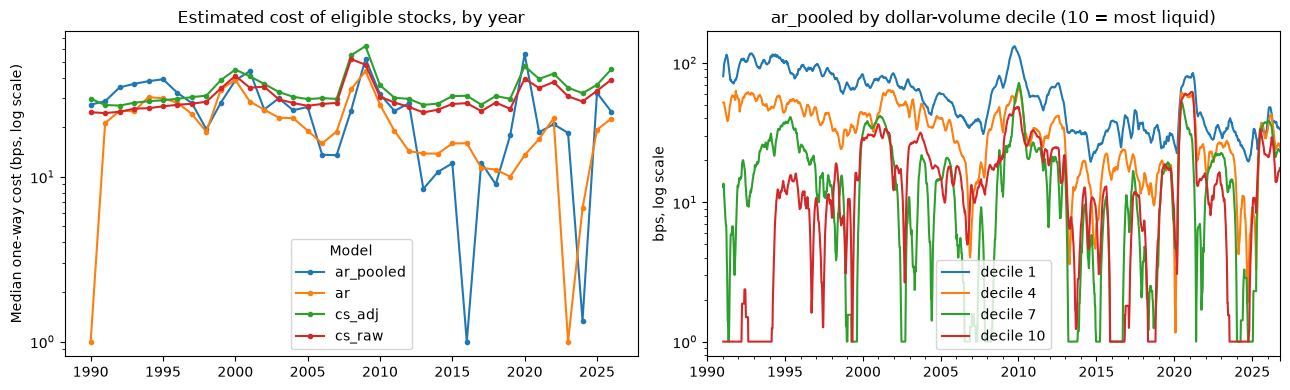

In [9]:
yr = pd.Series(weeks.year, index=weeks)
cost_year = pd.DataFrame({name: (C.where(ELIG).median(axis=1) * 1e4).groupby(yr).median() for name, C in COSTS.items()})
print("Median one-way cost of eligible stocks (bps), by year")
display(cost_year.round(1))

DQ = np.ceil(dvol13.where(ELIG).rank(axis=1, pct=True) * 10).clip(1, 10)       # dollar-volume decile among eligible stocks
first5 = slice(None, weeks[0] + pd.DateOffset(years=5))
last3 = slice(weeks[-1] - pd.DateOffset(years=3), None)
rows = []
for d in range(1, 11):
    row = {"dollar-volume decile (10 = most liquid)": d}
    for name, C in COSTS.items():
        Cd = (C * 1e4).where(DQ == d)
        row[f"{name}, first 5 years"] = Cd.loc[first5].median(axis=1).median()
        row[f"{name}, last 3 years"] = Cd.loc[last3].median(axis=1).median()
    rows.append(row)
cost_dec = pd.DataFrame(rows).set_index("dollar-volume decile (10 = most liquid)")
print("Median one-way cost (bps) by dollar-volume decile")
display(cost_dec.round(1))

_x = LR.where(ELIG)
_med = _x.median(axis=1)
_z1w = _x.sub(_med, axis=0).div(_x.sub(_med, axis=0).abs().median(axis=1) * 1.4826, axis=0)
OUT1W = _z1w.abs() > Z_OUTLIER
del _x, _z1w, _med
rows = []
for name, C in COSTS.items():
    Ce = C.where(ELIG) * 1e4
    for per, sl in PERIODS.items():
        row = {"model": name, "period": per}
        for k in [1, 2, 3]:
            row[f"liquidity tercile {k}"] = Ce.where(LIQ_T == k).loc[sl].median(axis=1).median()
        all_med = Ce.loc[sl].median(axis=1)
        out_med = Ce.where(OUT1W).loc[sl].median(axis=1)
        row["all eligible"] = all_med.median()
        row["1w outliers"] = out_med.median()
        row["outlier premium (x)"] = (out_med / all_med).median()
        rows.append(row)
cost_diag = pd.DataFrame(rows)
print("Median one-way cost (bps) by liquidity tercile (1 = least liquid), and for 1-week outliers")
display(cost_diag.round(2))

top_now = dvol13.iloc[-1].where(ELIG.iloc[-1]).nlargest(8).index
print(f"Most liquid stocks in the week ending {weeks[-1].date()}: one-way cost (bps) under each model")
display(pd.DataFrame({name: (C.iloc[-1] * 1e4).reindex(top_now) for name, C in COSTS.items()}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cost_year.plot(ax=axes[0], marker=".")
axes[0].set_yscale("log"); axes[0].set_ylabel("Median one-way cost (bps, log scale)")
axes[0].set_title("Estimated cost of eligible stocks, by year"); axes[0].legend(title="Model")
for d in [1, 4, 7, 10]:
    (COSTS["ar_pooled"].where(DQ == d).median(axis=1) * 1e4).rolling(13, min_periods=4).mean().plot(ax=axes[1], label=f"decile {d}")
axes[1].set_yscale("log"); axes[1].set_title("ar_pooled by dollar-volume decile (10 = most liquid)")
axes[1].set_ylabel("bps, log scale"); axes[1].legend()
save(fig, "04b_costs.png")

## 5. Signals, outliers and the portfolio engine

- **Momentum** over a lookback = sum of weekly log returns from t−L+1 to t−skip. Lookbacks: `1w`, `1m`, `3m`, `6m`, `12-1`, plus versions that skip the most recent weeks: `1m-1w` (weeks t−3…t−1), `3m-1m` (t−12…t−4), `6m-1m` (t−25…t−4).
- **Components:** `total`, `market`, `industry`, `specific`, `residual`, plus `volscaled` (momentum ÷ realized volatility over the same window) and `id` (information discreteness, Da, Gurun & Warachka 2014: sign(momentum) × (% down days − % up days); lower = built from many small moves, higher = a few jumps).
- **Robust z:** (x − weekly median) / (1.4826 × weekly MAD) among eligible stocks.
- **Portfolio engine:** overlapping cohorts (Jegadeesh & Titman). Each week's selections form a cohort held for K weeks; capital is split equally across live cohorts. Turnover is the sum of absolute weight changes; trading cost is turnover times each traded stock's one-way cost from the trade week. Options:
  - `weights=`: weight stocks within a cohort by a formation-week variable (13-week median dollar volume = **liquidity-weighted**),
  - `R_first=`: returns for a cohort's **first** week (skip-a-day returns; later weeks earn normal returns).
  - `cap=` (new in v4): no stock above this weight within a cohort; the excess is spread over the other names in proportion (the cap rises to 1/n for cohorts with fewer than 1/cap names).
- `MEMBERS` holds named selections and `get_port(name, K, variant)` builds and caches their portfolios (`variant`: `base`, `lw` liquidity-weighted, `lwcap` liquidity-weighted with no stock above `LW_CAP` of a cohort (new in v4), `skip1` enter a day late, `droplast` placebo, `xrs` excluding stocks with a reverse split in the past 52 weeks, a cost model name, or `t1`/`t2`/`t3` for a liquidity tercile).

In [10]:
def window_sum(X, L, skip=0):
    """Sum over weeks t-L+1 ... t-skip (inclusive). Uses only data through week t."""
    n = L - skip
    return X.rolling(n, min_periods=n).sum().shift(skip)

def signal(lb, comp):
    L, skip = LOOKBACKS[lb]
    if comp in COMPONENTS:
        return window_sum(COMPONENTS[comp], L, skip)
    if comp == "volscaled":
        vol = np.sqrt(window_sum(FW["ss"], L, skip))
        return window_sum(LR, L, skip) / vol.where(vol > 0)
    if comp == "id":
        nd = window_sum(FW["ndays"], L, skip)
        return np.sign(window_sum(LR, L, skip)) * (window_sum(FW["nneg"], L, skip) - window_sum(FW["npos"], L, skip)) / nd.where(nd > 0)
    raise ValueError(comp)

def robust_z(X, mask):
    Y = X.where(mask)
    med = Y.median(axis=1)
    mad = Y.sub(med, axis=0).abs().median(axis=1) * 1.4826
    return Y.sub(med, axis=0).div(mad.where(mad > 0), axis=0)

def zscore(lb, comp="total"):
    s = signal(lb, comp)
    return robust_z(s, ELIG & s.notna()).astype("float32")

def decile_members(X, mask, bp_cols=None, q=0.1):
    """(top, bottom) membership using cross-sectional breakpoints (optionally NYSE-only breakpoints)."""
    Y = X.where(mask)
    ref = Y if bp_cols is None else Y[bp_cols]
    lo, hi = ref.quantile(q, axis=1), ref.quantile(1 - q, axis=1)
    return Y.ge(hi, axis=0), Y.le(lo, axis=0)

def cap_weights(Wn, cap, iters=200):
    """Cap each row's weights (rows sum to 1, or are empty) at `cap`, spreading the excess over the uncapped names
    in proportion to their weights. A row with fewer than 1/cap names ends up equal-weighted (its cap rises to 1/n)."""
    W = np.array(Wn, dtype="float64", copy=True)
    npos = (W > 0).sum(axis=1)
    c = np.maximum(cap, 1.0 / np.maximum(npos, 1))[:, None]
    for _ in range(iters):
        over = W > c + 1e-12
        if not over.any():
            break
        excess = np.where(over, W - c, 0.0).sum(axis=1, keepdims=True)
        W = np.where(over, c, W)
        free = np.where((W > 0) & (W < c - 1e-12), W, 0.0)
        fs = free.sum(axis=1, keepdims=True)
        W = W + np.divide(free * excess, fs, out=np.zeros_like(W), where=fs > 0)
    return W

def cohort_portfolio(member, R, K=1, cost=None, flat_bps=0.0, weights=None, R_first=None, cap=None):
    """Overlapping-cohort portfolio.
    member[t] = selected at the close of week t. Week s holds the K most recent non-empty cohorts equally.
    Within a cohort stocks are equal-weighted, or proportional to `weights` at formation. A held stock with a
    missing return is skipped that week (its weight is spread over the others: OPTIMISTIC legacy assumption). With `R_first`, each cohort's
    first week earns R_first instead of R. Returns weekly gross, turnover, trading cost, net, and names held."""
    Wc = member.reindex(index=R.index, columns=R.columns, fill_value=False).to_numpy(dtype="float64", copy=True)   # writable copy (pandas 3 returns read-only arrays)
    if weights is not None:
        Wc *= np.clip(np.nan_to_num(weights.reindex(index=R.index, columns=R.columns).to_numpy(dtype="float64")), 0, None)
    n = Wc.sum(axis=1)
    np.divide(Wc, n[:, None], out=Wc, where=n[:, None] > 0)
    if cap is not None:
        Wc = cap_weights(Wc, cap)
    T = len(Wc)
    Wt, cnt = np.zeros_like(Wc), np.zeros(T)
    for k in range(1, K + 1):
        Wt[k:] += Wc[:-k]
        cnt[k:] += n[:-k] > 0
    denom = np.where(cnt > 0, cnt, 1.0)[:, None]
    Wt /= denom
    Rv = R.to_numpy(dtype="float64")
    okR = ~np.isnan(Rv)
    if R_first is None:
        held = Wt * okR
        num = (held * np.where(okR, Rv, 0.0)).sum(axis=1)
    else:
        W1 = np.zeros_like(Wc)
        W1[1:] = Wc[:-1]
        W1 /= denom
        Rf = R_first.reindex(index=R.index, columns=R.columns).to_numpy(dtype="float64")
        okF = ~np.isnan(Rf)
        h1, h2 = W1 * okF, (Wt - W1) * okR
        held = h1 + h2
        num = (h1 * np.where(okF, Rf, 0.0)).sum(axis=1) + (h2 * np.where(okR, Rv, 0.0)).sum(axis=1)
        del W1, Rf, okF, h1, h2
    wsum = held.sum(axis=1)
    ok = wsum > 0
    gross = np.full(T, np.nan)
    gross[ok] = num[ok] / wsum[ok]
    dW = np.abs(np.diff(Wt, axis=0, prepend=np.zeros((1, Wt.shape[1]))))
    turnover = dW.sum(axis=1)
    if cost is not None:
        C = cost.reindex(index=R.index, columns=R.columns).shift(1).to_numpy(dtype="float64")
        C = np.where(np.isnan(C), np.nanmedian(C), C)
        tcost = (dW * C).sum(axis=1)
    else:
        tcost = turnover * flat_bps / 1e4
    out = pd.DataFrame({"gross": gross, "turnover": turnover, "tcost": tcost, "names": (Wt > 0).sum(axis=1)}, index=R.index)
    out.loc[~ok, ["turnover", "tcost"]] = np.nan
    out["net"] = out["gross"] - out["tcost"]
    return out

def long_short(up, dn):
    out = pd.DataFrame({"gross": up["gross"] - dn["gross"],
                        "turnover": up["turnover"] + dn["turnover"],
                        "tcost": up["tcost"] + dn["tcost"],
                        "names": up["names"] + dn["names"]})
    out["net"] = out["gross"] - out["tcost"] - BORROW_BPS_PER_YEAR / 1e4 / 52
    return out

MEMBERS, PORTS = {}, {}

def get_port(name, K=1, variant="base"):
    """Portfolio for a named selection in MEMBERS, built once and cached."""
    if variant == COST_MODEL:
        variant = "base"
    key = (name, K, variant)
    if key not in PORTS:
        m, kw = MEMBERS[name], {"cost": cost1}
        if variant == "lw":
            kw["weights"] = dvol13
        elif variant == "lwcap":
            kw["weights"], kw["cap"] = dvol13, LW_CAP
        elif variant == "skip1":
            kw["R_first"] = R_FIRST
        elif variant == "droplast":
            kw["R_first"] = R_DROP_LAST
        elif variant == "xrs":
            m = m & ~RSPLIT52
        elif variant in COSTS:
            kw["cost"] = COSTS[variant]
        elif variant in ("t1", "t2", "t3"):
            m = m & (LIQ_T == int(variant[1]))
        elif variant != "base":
            raise ValueError(variant)
        PORTS[key] = cohort_portfolio(m, R, K, **kw)
    return PORTS[key]

## 6. Statistics (Newey–West throughout)

- `nw_mean`: mean of a weekly series with a NW t and p.
- `nw_alpha`: alpha against FF7 = Fama–French 5 + momentum (UMD) + short-term reversal (STREV). FF5 alone has no momentum factor, so it flatters any momentum strategy.
- `capm`: CAPM alpha and the **appraisal ratio** (alpha ÷ residual volatility, annualized), the information ratio that does not reward market beta.
- `sharpe`: annualized Sharpe (√52), plus Lo's (2002) autocorrelation-corrected version. `sharpe_diff`: Ledoit–Wolf-style HAC test of a Sharpe difference.
- `max_drawdown`: worst peak-to-trough loss of the compounded series.
- `summarize`: one row per period with gross and net returns (always both), Sharpe, CAPM and FF7 alphas, drawdown, turnover, cost per side, break-even cost, and the NW test of last 10 years vs earlier.

**Best direction after costs.** A strategy that loses money before costs can still be worth trading the other way round. For every test, `best_net` takes the better direction before costs and then charges the same costs: best = sign(gross) × gross − costs. The verdicts in section 21 use it.

In [11]:
def nw_lags(T, K=1):
    return max(int(np.floor(4 * (T / 100) ** (2 / 9))), K - 1, 1)

def _hac(y, X, K):
    return sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": nw_lags(len(y), K)})

_NAN_MEAN = {"mean": np.nan, "se": np.nan, "t": np.nan, "p": np.nan}

def nw_mean(x, K=1):
    x = pd.Series(x).dropna()
    if len(x) < 30 or x.std() == 0:
        return {**_NAN_MEAN, "n": len(x)}
    r = _hac(x.values, np.ones((len(x), 1)), K)
    return {"mean": r.params[0], "se": r.bse[0], "t": r.tvalues[0], "p": r.pvalues[0], "n": len(x)}

FF5 = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
FF7 = FF5 + ["UMD", "STREV"]

def nw_alpha(y, cols=FF7, K=1):
    d = pd.concat([y.rename("y"), fac_w[cols]], axis=1, join="inner").dropna()
    if len(d) < 52:
        return {"alpha_ann": np.nan, "t": np.nan, "p": np.nan}
    r = _hac(d["y"], sm.add_constant(d[cols]), K)
    return {"alpha_ann": r.params["const"] * 52, "t": r.tvalues["const"], "p": r.pvalues["const"]}

def capm(y, K=1):
    """CAPM on excess returns y: annualized alpha, NW t, beta, and appraisal ratio (alpha / residual SD, annualized)."""
    d = pd.concat([pd.Series(y).rename("y"), mx.rename("m")], axis=1, join="inner").dropna()
    if len(d) < 52:
        return {"alpha_ann": np.nan, "t": np.nan, "p": np.nan, "beta": np.nan, "appraisal": np.nan}
    r = _hac(d["y"], sm.add_constant(d["m"]), K)
    a, sd = r.params["const"], r.resid.std()
    return {"alpha_ann": a * 52, "t": r.tvalues["const"], "p": r.pvalues["const"], "beta": r.params["m"],
            "appraisal": a / sd * np.sqrt(52) if sd > 0 else np.nan}

def sharpe(x, q=52):
    x = pd.Series(x).dropna()
    if len(x) < 52 or x.std() == 0:
        return np.nan, np.nan
    sr = x.mean() / x.std()
    rho = np.array([x.autocorr(k) for k in range(1, q)])
    denom = q + 2 * np.nansum((q - np.arange(1, q)) * rho)
    return sr * np.sqrt(q), (sr * q / np.sqrt(denom) if denom > 0 else np.nan)

def sharpe_diff(a, b, K=1):
    """Sharpe(a) - Sharpe(b), annualized, with a Newey–West delta-method 95% CI and p-value."""
    d = pd.concat([a, b], axis=1).dropna().values
    T = len(d)
    if T < 104:
        return {"diff": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan}
    v = np.column_stack([d[:, 0], d[:, 1], d[:, 0] ** 2, d[:, 1] ** 2])
    mu = v.mean(axis=0)
    u = v - mu
    L = nw_lags(T, K)
    S = u.T @ u / T
    for l in range(1, L + 1):
        G = u[l:].T @ u[:-l] / T
        S += (1 - l / (L + 1)) * (G + G.T)
    m1, m2, g1, g2 = mu
    s1, s2 = np.sqrt(g1 - m1 ** 2), np.sqrt(g2 - m2 ** 2)
    grad = np.array([g1 / s1 ** 3, -g2 / s2 ** 3, -0.5 * m1 / s1 ** 3, 0.5 * m2 / s2 ** 3])
    diff = m1 / s1 - m2 / s2
    se = np.sqrt(grad @ S @ grad / T)
    k = np.sqrt(52)
    return {"diff": diff * k, "lo": (diff - 1.96 * se) * k, "hi": (diff + 1.96 * se) * k, "p": 2 * norm.sf(abs(diff / se))}

def max_drawdown(x):
    w = (1 + pd.Series(x).fillna(0)).cumprod()
    return (w / w.cummax() - 1).min()

def period_diff(x, K=1):
    x = pd.Series(x).dropna()
    D = pd.DataFrame({"const": 1.0, "recent": (x.index > RECENT_START).astype(float)}, index=x.index)
    if D["recent"].nunique() < 2:
        return np.nan, np.nan
    r = _hac(x, D, K)
    return r.params["recent"] * 52, r.pvalues["recent"]

def summarize(port, label, K=1, kind="ls"):
    """kind='ls': zero-cost long-short. kind='lo': long-only, judged against the market (active return),
    with Sharpe and alphas on returns over T-bills."""
    rows = []
    for per, sl in PERIODS.items():
        p = port.loc[sl].dropna(subset=["gross"])
        if len(p) < 104:
            continue
        if kind == "ls":
            g, n = p["gross"], p["net"]
            yg, yn = g, n
        else:
            m, f = mkt.reindex(p.index), rf.reindex(p.index)
            g, n = p["gross"] - m, p["net"] - m
            yg, yn = p["gross"] - f, p["net"] - f
        s = 1.0 if g.mean() >= 0 else -1.0
        best = s * g - (g - n)
        tg, tn, tb = nw_mean(g, K), nw_mean(n, K), nw_mean(best, K)
        sr, sr_lo = sharpe(yn)
        cp = capm(yn, K)
        a7g, a7n = nw_alpha(yg, FF7, K), nw_alpha(yn, FF7, K)
        to = p["turnover"].mean()
        row = {**label, "period": per, "weeks": len(p), "names": p["names"].mean(),
               "gross_ann": g.mean() * 52, "t_gross": tg["t"], "p_gross": tg["p"],
               "net_ann": n.mean() * 52, "t_net": tn["t"], "p_net": tn["p"],
               "direction": "as built" if s > 0 else "reversed",
               "best_net_ann": best.mean() * 52, "t_best": tb["t"], "p_best": tb["p"],
               "ir_best": best.mean() / best.std() * np.sqrt(52) if best.std() > 0 else np.nan,
               "sharpe_gross": sharpe(yg)[0], "sharpe": sr, "sharpe_lo": sr_lo,
               "alpha_capm_ann": cp["alpha_ann"], "t_alpha_capm": cp["t"], "beta": cp["beta"], "appraisal": cp["appraisal"],
               "alpha7_gross_ann": a7g["alpha_ann"], "t_alpha7_gross": a7g["t"], "p_alpha7_gross": a7g["p"],
               "alpha7_ann": a7n["alpha_ann"], "t_alpha7": a7n["t"], "p_alpha7": a7n["p"],
               "maxdd": max_drawdown(p["net"]),
               "turnover": to,
               "cost_bps_per_side": p["tcost"].mean() / to * 1e4 if to > 0 else np.nan,
               "breakeven_bps": s * g.mean() / to * 1e4 if to > 0 else np.nan,
               "breakeven_asbuilt_bps": g.mean() / to * 1e4 if to > 0 else np.nan}
        if kind == "lo":
            mex = (mkt - rf).reindex(p.index)
            sd = sharpe_diff(yn, mex, K)
            row.update({"sharpe_mkt": sharpe(mex)[0], "sharpe_diff": sd["diff"], "sharpe_diff_lo": sd["lo"],
                        "sharpe_diff_hi": sd["hi"], "p_sharpe_diff": sd["p"]})
        if per == "full":
            dg, pg = period_diff(g, K)
            dn_, pn = period_diff(n, K)
            row.update({"recent_minus_disc_gross": dg, "p_recent_vs_disc_gross": pg,
                        "recent_minus_disc_net": dn_, "p_recent_vs_disc_net": pn})
        rows.append(row)
    return rows

def add_bh(df, pcols, by="period"):
    """Benjamini–Hochberg q-values from NW p-values, within each group (default: each period)."""
    df = df.copy()
    for c in pcols:
        q = "q" + c[1:]
        df[q] = np.nan
        for _, g in df.groupby(by):
            g = g[g[c].notna()]
            if len(g):
                df.loc[g.index, q] = multipletests(g[c].values, method="fdr_bh")[1]
    return df

def fmt_cell(g, t, n):
    """'gross (t) | net' as % per year, for compact pivot tables."""
    if pd.isna(g):
        return ""
    return f"{g:+.1%} ({t:+.1f}) | {n:+.1%}"

SHOW = ["period", "names", "gross_ann", "t_gross", "net_ann", "t_net", "sharpe", "alpha7_gross_ann", "t_alpha7_gross",
        "appraisal", "maxdd", "cost_bps_per_side", "breakeven_bps"]

## 7. Validation: survivorship bias and replication against Ken French

**7a.** Compare our present-day-listing universe against Ken French's CRSP-history-based market. These are **diagnostics, not estimates of survivorship bias**: the universes differ in market-cap versus liquidity weights, size, foreign incorporation, price floors, exchanges, formation conventions, and handling of delistings. Even a tiny gap cannot rule out survivor bias because winner and loser distortions may offset. The only direct bias estimate requires a security-level point-in-time universe, stable IDs and delisting-inclusive returns (optional section 33).

**7b. Replication, rebuilt.** v1 compared weekly-formed spreads with Ken French's *daily* equal-weighted deciles compounded to weeks. Daily equal-weighted returns are rebalanced to equal weights every day, which builds bid-ask bounce from low-priced stocks into the returns (Blume & Stambaugh 1983), and v1 formed portfolios weekly while Ken French forms them monthly. That is why Ken French's reversal spread came out near −148% a year and the levels could not be compared. Since v2 the notebook copies Ken French's design:

- formed at each month end, held one month, monthly returns compounded from our daily data,
- 12-1 = cumulative return over months t−12 to t−2 (his "Prior 12-2"); 1-month = last month's return ("Prior 1-0"),
- NYSE breakpoints (using today's NYSE listing),
- two universes: **loose** (price ≥ `LOOSE_MIN_PRICE`, closest to Ken French; v2 had no floor and bad penny-stock data swamped it) and **filtered** (our $5 and liquidity filters, the one the rest of the notebook uses),
- equal-weighted against his equal-weighted deciles; liquidity-weighted (**not equivalent to market cap**) against his value-weighted deciles,
- compared leg by leg with the level gap tested directly (NW t), not just correlation.

**Reading the gaps.** A positive gap on a leg means that our *different portfolio construction and survivor universe jointly* generated a higher return than Ken French's portfolio. The gap does **not** isolate survivorship bias. The intuitive guess is that missing delisted losers flatter the loser legs most, but in v2 the gap showed up mainly in the **winner** legs (about +2 to +7% a year), with loser legs near zero: today's survivors include past winners that kept going, while winners that later collapsed and delisted are missing. That left the 12-1 spread roughly unbiased and made our 1-month reversal look weaker than Ken French's. Check that it still holds; the consistency checks use the filtered universe and correlation with UMD.

,period,series,CAGR,vol,weeks,t_gap,p_gap
0,full,"universe, equal-weighted",0.1460,0.1904,1868,NaN,NaN
1,full,"universe, liquidity-weighted",0.1452,0.2052,1868,NaN,NaN
2,full,Ken French market,0.1093,0.1696,1920,NaN,NaN
3,full,"gap: liquidity-weighted minus market (mean, pe...",0.0337,NaN,1868,3.6483,0.0003
4,discovery,"universe, equal-weighted",0.1585,0.1793,1346,NaN,NaN
5,discovery,"universe, liquidity-weighted",0.1304,0.2004,1346,NaN,NaN
6,discovery,Ken French market,0.0934,0.1670,1398,NaN,NaN
7,discovery,"gap: liquidity-weighted minus market (mean, pe...",0.0333,NaN,1346,3.1479,0.0016
8,recent,"universe, equal-weighted",0.1144,0.2164,522,NaN,NaN
9,recent,"universe, liquidity-weighted",0.1844,0.2172,522,NaN,NaN


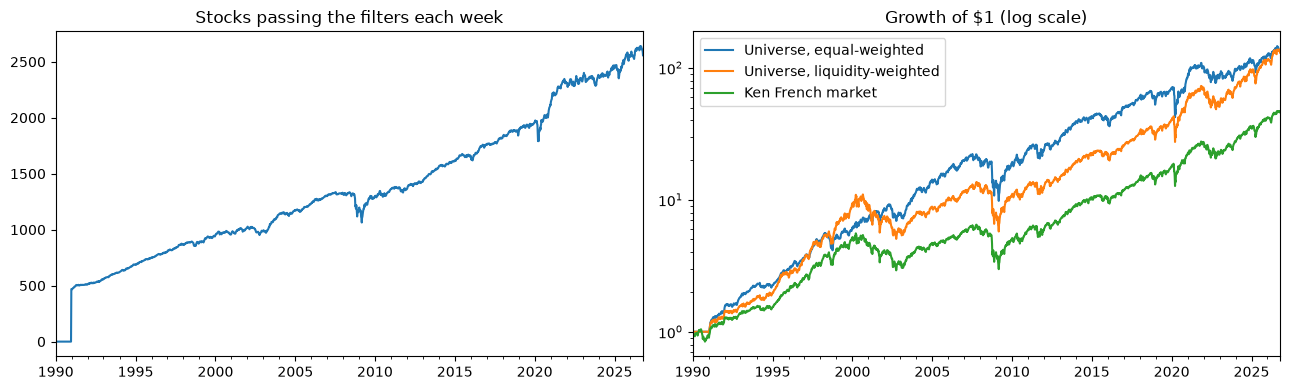

In [12]:
n_elig = ELIG.sum(axis=1)
w_prev = dvol13.where(ELIG).shift(1)
ew_univ = R.where(ELIG.shift(1, fill_value=False)).mean(axis=1)
lw_univ = (R * w_prev).sum(axis=1, min_count=1) / w_prev.where(R.notna()).sum(axis=1)

def growth_stats(x):
    x = x.dropna()
    return {"CAGR": (1 + x).prod() ** (52 / len(x)) - 1, "vol": x.std() * np.sqrt(52), "weeks": len(x)}

surv_rows = []
for per, sl in PERIODS.items():
    for name, s in [("universe, equal-weighted", ew_univ), ("universe, liquidity-weighted", lw_univ), ("Ken French market", mkt)]:
        surv_rows.append({"period": per, "series": name, **growth_stats(s.loc[sl])})
    g = nw_mean((lw_univ - mkt).loc[sl])
    surv_rows.append({"period": per, "series": "gap: liquidity-weighted minus market (mean, per year)",
                      "CAGR": g["mean"] * 52, "t_gap": g["t"], "p_gap": g["p"], "weeks": g["n"]})
surv = pd.DataFrame(surv_rows)
display(surv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
n_elig.plot(ax=axes[0], title="Stocks passing the filters each week")
for name, s in [("Universe, equal-weighted", ew_univ), ("Universe, liquidity-weighted", lw_univ), ("Ken French market", mkt)]:
    (1 + s.fillna(0)).cumprod().plot(ax=axes[1], label=name)
axes[1].set_yscale("log"); axes[1].set_title("Growth of $1 (log scale)"); axes[1].legend()
save(fig, "07_universe_vs_market.png")

Breakpoints: NYSE (1879 stocks)
Monthly replication: annualized returns, ours minus Ken French (gap) with NW t


,lookback,universe,weighting,leg,ours_ann,kf_ann,gap_ann,t_gap,corr,months,corr_with_UMD,corr_with_STREV
0,12-1,loose,equal-weighted vs KF EW,winners,0.2234,0.1838,0.0397,4.5013,0.9786,428,NaN,NaN
1,12-1,loose,equal-weighted vs KF EW,losers,0.1628,0.1080,0.0549,2.3448,0.9239,428,NaN,NaN
2,12-1,loose,equal-weighted vs KF EW,spread,0.0606,0.0758,-0.0152,-0.6711,0.8392,428,0.8846,NaN
3,12-1,loose,liquidity-weighted vs KF VW,winners,0.2228,0.1732,0.0496,2.7150,0.9399,428,NaN,NaN
4,12-1,loose,liquidity-weighted vs KF VW,losers,0.1060,0.0814,0.0245,1.1723,0.9322,428,NaN,NaN
5,12-1,loose,liquidity-weighted vs KF VW,spread,0.1169,0.0918,0.0251,0.8418,0.8802,428,0.8113,NaN
6,12-1,filtered,equal-weighted vs KF EW,winners,0.2041,0.1838,0.0203,2.1031,0.9677,428,NaN,NaN
7,12-1,filtered,equal-weighted vs KF EW,losers,0.1364,0.1080,0.0285,0.8564,0.8415,428,NaN,NaN
8,12-1,filtered,equal-weighted vs KF EW,spread,0.0677,0.0758,-0.0081,-0.2732,0.7189,428,0.9121,NaN
9,12-1,filtered,liquidity-weighted vs KF VW,winners,0.2265,0.1732,0.0533,2.8677,0.9395,428,NaN,NaN


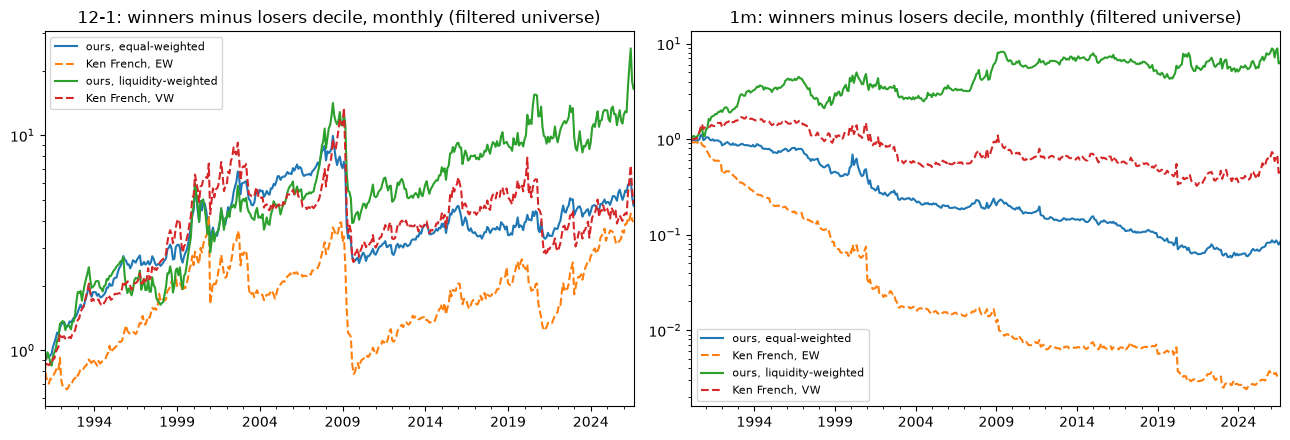

In [13]:
# ---- 7b. monthly replication against Ken French's deciles
LRM = M["ret_m"].astype("float64")
LRM.index = LRM.index.to_period("M")
RM = np.expm1(LRM)
PM = M["price_m"].astype("float64").set_axis(LRM.index)
DVM = M["dvol_m"].astype("float64").set_axis(LRM.index)

ex = universe.set_index("yahoo")["exchange"].str.upper().reindex(RM.columns)
nyse_cols = list(ex.index[ex == "NYSE"]) if (ex == "NYSE").sum() >= 200 else None
print("Breakpoints:", f"NYSE ({len(nyse_cols)} stocks)" if nyse_cols else "all stocks (too few NYSE names)")

_liq_m = DVM.where(PM >= MIN_PRICE).quantile(MIN_DVOL_PCTILE, axis=1)
UNIV_M = {"loose": PM >= LOOSE_MIN_PRICE,
          "filtered": (PM >= MIN_PRICE) & DVM.ge(_liq_m, axis=0)}

def monthly_legs(sig, elig, weights=None):
    """Winner and loser decile returns in month t for portfolios formed at the end of month t-1."""
    top, bot = decile_members(sig, elig & sig.notna(), [c for c in nyse_cols if c in sig.columns] if nyse_cols else None)
    out = {}
    for leg, mm in [("winners", top), ("losers", bot)]:
        m1 = mm.shift(1, fill_value=False)
        if weights is None:
            out[leg] = RM.where(m1).mean(axis=1)
        else:
            w = weights.shift(1).where(m1)
            out[leg] = (RM * w).sum(axis=1, min_count=1) / w.where(RM.notna()).sum(axis=1)
    out["spread"] = out["winners"] - out["losers"]
    return out

REP_SIGNALS = {"12-1": (window_sum(LRM, 12, 1), kf_mom_m, umd_m, "UMD"),
               "1m": (window_sum(LRM, 1, 0), kf_rev_m, strev_m, "STREV")}
rep_rows, REP_SERIES = [], {}
for lb, (sig, kf_pf, fac, fac_name) in REP_SIGNALS.items():
    for uname, uel in UNIV_M.items():
        for wname, wts, kfw in [("equal-weighted", None, "EW"), ("liquidity-weighted", DVM, "VW")]:
            ours = monthly_legs(sig, uel, wts)
            kf = {"winners": kf_pf[kfw].iloc[:, -1], "losers": kf_pf[kfw].iloc[:, 0]}
            kf["spread"] = kf["winners"] - kf["losers"]
            REP_SERIES[(lb, uname, wname)] = (ours["spread"], kf["spread"])
            for leg in ["winners", "losers", "spread"]:
                d = pd.concat([ours[leg].rename("ours"), kf[leg].rename("kf")], axis=1).dropna()
                gap = nw_mean(d["ours"] - d["kf"])
                row = {"lookback": lb, "universe": uname, "weighting": f"{wname} vs KF {kfw}", "leg": leg,
                       "ours_ann": d["ours"].mean() * 12, "kf_ann": d["kf"].mean() * 12,
                       "gap_ann": gap["mean"] * 12, "t_gap": gap["t"], "corr": d["ours"].corr(d["kf"]), "months": len(d)}
                if leg == "spread":
                    row[f"corr_with_{fac_name}"] = d["ours"].corr(fac.reindex(d.index))
                rep_rows.append(row)
rep = pd.DataFrame(rep_rows)
print("Monthly replication: annualized returns, ours minus Ken French (gap) with NW t")
display(rep)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, lb in zip(axes, ["12-1", "1m"]):
    for (l, u, w), (o, k) in REP_SERIES.items():
        if l != lb or u != "filtered":
            continue
        d = pd.concat([o.rename("o"), k.rename("k")], axis=1).dropna()
        d.index = d.index.to_timestamp()
        (1 + d["o"]).cumprod().plot(ax=ax, label=f"ours, {w}")
        (1 + d["k"]).cumprod().plot(ax=ax, ls="--", label=f"Ken French, {'EW' if w.startswith('equal') else 'VW'}")
    ax.set_yscale("log"); ax.set_title(f"{lb}: winners minus losers decile, monthly (filtered universe)"); ax.legend(fontsize=8)
save(fig, "07_replication_monthly.png")

## 8. Baseline: momentum by lookback (does the sign flip?)

Top-minus-bottom decile on each lookback's total momentum, held 1, 4 and 13 weeks. Expect short lookbacks to reverse and long ones to continue. The skipped lookbacks (`1m-1w`, `3m-1m`, `6m-1m`) show whether 3m and 6m only looked weak in v1 because they contained last week's reversal.

Every table from here on shows **gross** (before costs) and **net** side by side, plus the break-even cost: the one-way cost in bps that would wipe out the gross edge.

,lookback,period,names,gross_ann,t_gross,net_ann,t_net,sharpe,alpha7_gross_ann,t_alpha7_gross,appraisal,maxdd,cost_bps_per_side,breakeven_bps
0,1w,full,279.1279,-0.2839,-8.5061,-0.9059,-19.1463,-4.5133,-0.1471,-5.6737,-4.5529,-1.0000,34.8940,15.9296
2,1w,recent,436.1456,-0.1282,-1.6276,-0.5098,-6.1188,-2.2247,-0.0673,-1.2216,-2.0933,-0.9960,21.6750,7.2786
9,1m,full,279.1146,-0.1931,-6.0546,-0.5253,-14.0094,-2.4919,0.0053,0.2339,-2.4495,-1.0000,35.3707,20.5651
11,1m,recent,436.1418,-0.0844,-1.4839,-0.2857,-4.7161,-1.2180,-0.0078,-0.1991,-1.0041,-0.9583,22.0675,9.2469
18,1m-1w,full,279.1172,-0.0590,-2.0305,-0.4368,-13.1857,-2.2953,0.0879,3.1807,-2.2245,-1.0000,35.1642,5.4940
20,1m-1w,recent,436.1437,-0.0517,-1.0365,-0.2819,-5.2279,-1.3228,0.0077,0.1747,-1.1481,-0.9536,21.9659,4.9383
27,3m,full,279.1146,-0.1043,-2.5860,-0.2995,-7.1280,-1.2725,-0.0148,-0.4283,-1.1578,-1.0000,36.5040,19.5131
29,3m,recent,436.1418,-0.0508,-0.7790,-0.1690,-2.5684,-0.6434,-0.0069,-0.1445,-0.4053,-0.8802,22.9670,9.8812
36,3m-1m,full,279.1146,0.0362,1.0138,-0.1943,-5.2687,-0.9379,0.0171,0.5775,-0.8649,-0.9996,36.1643,5.6846
38,3m-1m,recent,436.1418,0.0190,0.3332,-0.1205,-2.1068,-0.5309,0.0003,0.0066,-0.4315,-0.7942,22.6955,3.0965


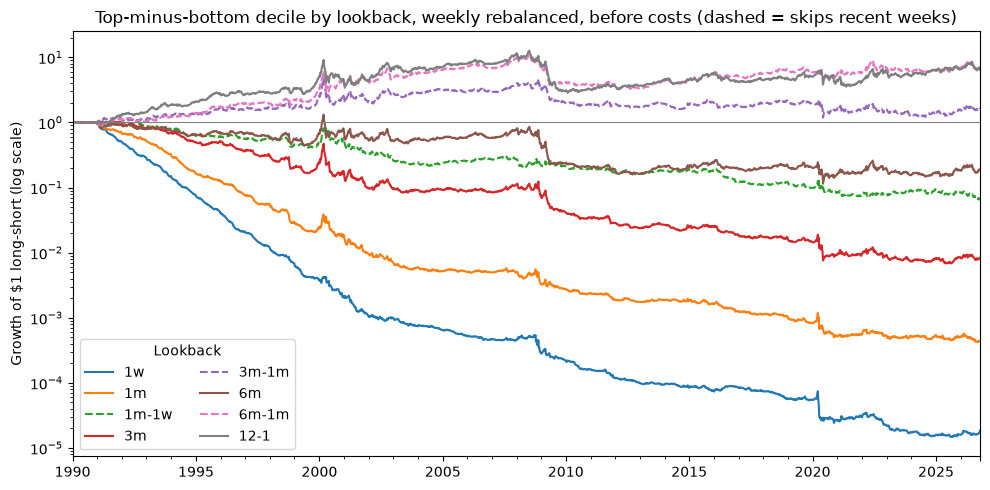

In [14]:
base_rows, base_curves = [], {}
for lb in LOOKBACKS:
    s = signal(lb, "total")
    top, bot = decile_members(s, ELIG & s.notna())
    if lb in MAIN_LBS:
        MEMBERS[f"{lb} top decile"], MEMBERS[f"{lb} bottom decile"] = top, bot
    for K in GRID_HOLDS:
        pt, pb = cohort_portfolio(top, R, K, cost1), cohort_portfolio(bot, R, K, cost1)
        if lb in MAIN_LBS:
            PORTS[(f"{lb} top decile", K, "base")], PORTS[(f"{lb} bottom decile", K, "base")] = pt, pb
        ls = long_short(pt, pb)
        base_rows += summarize(ls, {"test": "decile", "lookback": lb, "component": "total", "leg": "top minus bottom",
                                    "hold": K, "variant": "base"}, K)
        if K == 1:
            base_curves[lb] = ls
    del s, top, bot
base = pd.DataFrame(base_rows)
display(base.query("hold == 1 and period in ['full', 'recent']")[["lookback"] + SHOW].round(4))

fig, ax = plt.subplots(figsize=(10, 5))
for lb, ls in base_curves.items():
    (1 + ls["gross"].fillna(0)).cumprod().plot(ax=ax, label=lb, ls="--" if "-" in lb[1:] and lb != "12-1" else "-")
ax.set_yscale("log"); ax.axhline(1, color="grey", lw=0.8)
ax.set_title("Top-minus-bottom decile by lookback, weekly rebalanced, before costs (dashed = skips recent weeks)")
ax.set_ylabel("Growth of $1 long-short (log scale)"); ax.legend(title="Lookback", ncol=2)
save(fig, "08_momentum_by_lookback.png")

## 9. Which part of the past matters? Fama–MacBeth on non-overlapping windows

The lookbacks in section 8 overlap, so a 3-month signal mixes last week's reversal with genuine 3-month momentum. Here each week's cross-section of next-week returns is regressed on momentum over four windows that do not overlap:

| Variable | Weeks |
|---|---|
| `r_1w` | t |
| `r_1m_ex1w` | t−3 … t−1 |
| `r_3m_ex1m` | t−12 … t−4 |
| `r_12m_ex3m` | t−51 … t−13 |

Each variable is a robust z-score within that week's eligible stocks, clipped at ±5, so a slope reads as "next-week return per year for one robust SD more of that window's momentum". Weekly slopes are averaged over time with NW t-statistics (Fama & MacBeth 1973). Specifications: each window alone; all four together; all four plus controls (log 13-week dollar volume and 13-week realized volatility). The joint model is repeated with skip-a-day returns and within each liquidity tercile.

This is a linear, whole-cross-section view; the outlier tests (sections 10–11) look at the tails.


Fama–MacBeth slopes, % per year per 1 robust SD (NW t), period = full


spec               alone          joint                                                                            joint + controls
returns       same close     same close                                                                 skip a day       same close
stocks               all            all liquidity tercile 1 liquidity tercile 2 liquidity tercile 3            all              all
variable                                                                                                                           
r_1w        -6.1% (-8.3)  -6.5% (-10.0)       -7.2% (-10.2)        -5.8% (-8.6)        -5.2% (-6.9)  -5.3% (-10.2)    -6.9% (-10.7)
r_1m_ex1w   -1.4% (-2.2)   -2.0% (-3.4)        -2.2% (-3.5)        -2.5% (-3.5)        -1.1% (-1.5)   -2.4% (-5.0)     -2.6% (-4.7)
r_3m_ex1m   +0.3% (+0.4)   +0.3% (+0.4)        +1.2% (+1.5)        -0.8% (-0.9)        +0.3% (+0.4)   -0.7% (-1.0)     +0.4% (+0.6)
r_12m_ex3m  +1.5% (+2.0)   +1.2% (+1.6)        +1.2% (+1.8)        +0.8% (+0.9)        +1.6% (+1.6)   +0.6% (+0.8)     +1.6% (+2.3)
log_dvol             NaN            NaN                 NaN                 NaN                 NaN            NaN     -0.4% (-0.6)
rvol_13w             NaN            NaN                 NaN                 NaN                 NaN            NaN     +0.7% (+0.7)


Fama–MacBeth slopes, % per year per 1 robust SD (NW t), period = recent


spec               alone         joint                                                                           joint + controls
returns       same close    same close                                                                skip a day       same close
stocks               all           all liquidity tercile 1 liquidity tercile 2 liquidity tercile 3           all              all
variable                                                                                                                         
r_1w        -3.2% (-1.8)  -2.0% (-1.5)        -2.3% (-1.7)        -2.2% (-1.6)        -0.6% (-0.5)  -2.0% (-1.6)     -2.2% (-1.7)
r_1m_ex1w   -1.3% (-1.2)  -0.9% (-1.0)        -0.2% (-0.2)        -1.2% (-1.2)        -1.0% (-0.8)  -0.7% (-0.9)     -1.0% (-1.3)
r_3m_ex1m   +0.0% (+0.0)  +0.6% (+0.5)        +0.7% (+0.6)        -0.3% (-0.2)        +1.7% (+1.1)  -0.3% (-0.3)     +1.1% (+1.1)
r_12m_ex3m  +1.9% (+1.4)  +1.9% (+1.6)        +1.5% (+1.3)        +1.2% (+1.0)        +3.4% (+2.0)  +1.2% (+1.2)     +1.8% (+1.6)
log_dvol             NaN           NaN                 NaN                 NaN                 NaN           NaN     +1.6% (+1.6)
rvol_13w             NaN           NaN                 NaN                 NaN                 NaN           NaN     +0.5% (+0.2)

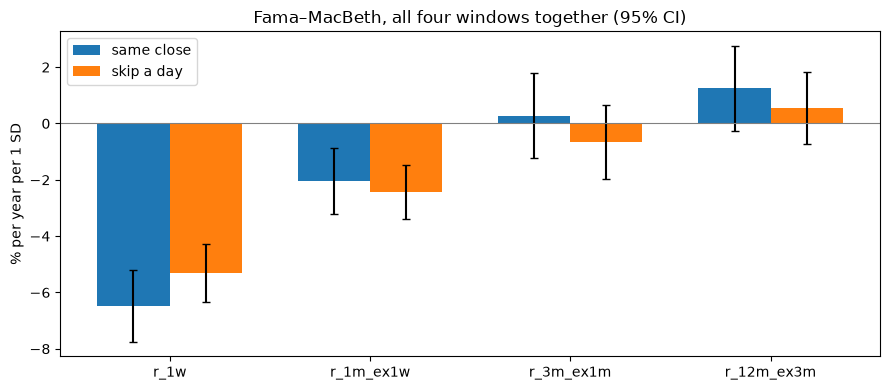

In [15]:
FM_WINDOWS = {"r_1w": (1, 0), "r_1m_ex1w": (4, 1), "r_3m_ex1m": (13, 4), "r_12m_ex3m": (52, 13)}
FM_WIN = list(FM_WINDOWS)

def rz_clip(X, mask, clip=5.0):
    return robust_z(X, mask & X.notna()).clip(-clip, clip).astype("float32")

FMX = {k: rz_clip(window_sum(LR, L, s), ELIG) for k, (L, s) in FM_WINDOWS.items()}
FMX["log_dvol"] = rz_clip(np.log(dvol13.where(dvol13 > 0)), ELIG)
FMX["rvol_13w"] = rz_clip(np.sqrt(window_sum(FW["ss"], 13, 0)), ELIG)
Y_NEXT = R.shift(-1)              # next week's return, on the formation week's row
Y_NEXT_SKIP = R_FIRST.shift(-1)

def fama_macbeth(y, names, mask, min_n=100):
    """Weekly cross-sectional OLS of y on the named FMX variables; returns the weekly slope series."""
    Y = y.to_numpy(dtype="float64")
    Xs = [FMX[k].to_numpy(dtype="float64") for k in names]
    Mk = mask.reindex(index=y.index, columns=y.columns, fill_value=False).to_numpy(dtype=bool)
    out = np.full((len(y), len(names) + 1), np.nan)
    for t in range(len(y)):
        X = np.column_stack([x[t] for x in Xs])
        ok = Mk[t] & np.isfinite(Y[t]) & np.isfinite(X).all(axis=1)
        if ok.sum() < min_n:
            continue
        A = np.column_stack([np.ones(ok.sum()), X[ok]])
        out[t] = np.linalg.lstsq(A, Y[t, ok], rcond=None)[0]
    return pd.DataFrame(out, index=y.index, columns=["const"] + names)

def fm_rows(slopes, label):
    rows = []
    for c in slopes.columns.drop("const"):
        for per, sl in PERIODS.items():
            s = nw_mean(slopes[c].loc[sl])
            rows.append({**label, "variable": c, "period": per, "slope_ann": s["mean"] * 52, "se_ann": s["se"] * 52,
                         "t": s["t"], "p": s["p"], "weeks": s["n"]})
    return rows

fm_list = []
for k in FM_WIN:
    fm_list += fm_rows(fama_macbeth(Y_NEXT, [k], ELIG), {"spec": "alone", "returns": "same close", "stocks": "all"})
FM_JOINT = fama_macbeth(Y_NEXT, FM_WIN, ELIG)        # kept for the evergreen check (section 22)
fm_list += fm_rows(FM_JOINT, {"spec": "joint", "returns": "same close", "stocks": "all"})
fm_list += fm_rows(fama_macbeth(Y_NEXT, FM_WIN + ["log_dvol", "rvol_13w"], ELIG),
                   {"spec": "joint + controls", "returns": "same close", "stocks": "all"})
fm_list += fm_rows(fama_macbeth(Y_NEXT_SKIP, FM_WIN, ELIG), {"spec": "joint", "returns": "skip a day", "stocks": "all"})
for k in [1, 2, 3]:
    fm_list += fm_rows(fama_macbeth(Y_NEXT, FM_WIN, ELIG & (LIQ_T == k), min_n=50),
                       {"spec": "joint", "returns": "same close", "stocks": f"liquidity tercile {k}"})
fm = add_bh(pd.DataFrame(fm_list), ["p"])
fm["cell"] = [f"{a:+.1%} ({t:+.1f})" if pd.notna(a) else "" for a, t in zip(fm.slope_ann, fm.t)]
for per in ["full", "recent"]:
    print(f"\nFama–MacBeth slopes, % per year per 1 robust SD (NW t), period = {per}")
    piv = fm[fm.period == per].pivot_table(index="variable", columns=["spec", "returns", "stocks"], values="cell", aggfunc="first")
    display(piv.reindex(FM_WIN + ["log_dvol", "rvol_13w"]))

j = fm.query("spec == 'joint' and stocks == 'all' and period == 'full'")
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(FM_WIN))
for off, ret in [(-0.18, "same close"), (0.18, "skip a day")]:
    s = j[j.returns == ret].set_index("variable").reindex(FM_WIN)
    ax.bar(x + off, s["slope_ann"] * 100, 0.36, yerr=1.96 * s["se_ann"] * 100, capsize=3, label=ret)
ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(FM_WIN)
ax.set_ylabel("% per year per 1 SD"); ax.set_title("Fama–MacBeth, all four windows together (95% CI)"); ax.legend()
save(fig, "09_fama_macbeth.png")
FMX.clear()                       # free memory

## 10. Outliers: the full grid

For every lookback × component (total, market, industry, stock-specific, volatility-scaled):
- **up vs market:** buy stocks with z > 2 (long-only, judged against the market),
- **down vs market:** buy stocks with z < −2,
- **up minus down:** long the up-outliers, short the down-outliers,

held 1, 4 and 13 weeks (section 19 covers every holding period for the headline strategies). Cells read **gross % per year (NW t) | net % per year**.

**Hit rates:** the share of outliers that land in next week's top 10% or bottom 10% of eligible stocks, against the 10% base rate, and in *either* tail against 20%. Outliers land in both tails more often than chance because they are volatile, so beating 10% in one tail says nothing about direction. **New in v3:** the directional test is the top-10% share **minus** the bottom-10% share (0 = no direction).

In [16]:
NR = R.shift(-1).where(ELIG)
_pr = NR.rank(axis=1, pct=True)
TOP_NEXT, BOT_NEXT = _pr > 0.9, _pr <= 0.1
del _pr

def hit_rates(member):
    m = member & NR.notna()
    n = m.sum(axis=1).where(lambda v: v > 0)
    return (TOP_NEXT & m).sum(axis=1) / n, (BOT_NEXT & m).sum(axis=1) / n

GRID_COMPONENTS = ["total", "market", "industry", "specific", "volscaled"]
n_elig = ELIG.sum(axis=1)
grid_rows, hit_rows, HIT_SERIES = [], [], {}
t0 = time.time()
for lb in LOOKBACKS:
    for comp in GRID_COMPONENTS:
        z = zscore(lb, comp)
        sides = {"up": z > Z_OUTLIER, "down": z < -Z_OUTLIER}
        keep_named = comp == "total" and lb in MAIN_LBS
        if keep_named:
            MEMBERS[f"{lb} up"], MEMBERS[f"{lb} down"] = sides["up"], sides["down"]
        for side, m in sides.items():
            top, bot = hit_rates(m)
            if keep_named:
                HIT_SERIES[(lb, side)] = (top, bot)   # for section 22
            cnt = m.sum(axis=1)
            for per, sl in PERIODS.items():
                ht, hb = nw_mean(top.loc[sl] - 0.10), nw_mean(bot.loc[sl] - 0.10)
                he = nw_mean((top + bot).loc[sl] - 0.20)
                hd = nw_mean((top - bot).loc[sl])
                hit_rows.append({"lookback": lb, "component": comp, "side": side, "period": per,
                                 "outliers_per_week": cnt.loc[sl].mean(),
                                 "share_of_eligible": (cnt / n_elig).loc[sl].mean(),
                                 "share_next_top10": top.loc[sl].mean(), "t_top": ht["t"], "p_top": ht["p"],
                                 "share_next_bottom10": bot.loc[sl].mean(), "t_bottom": hb["t"], "p_bottom": hb["p"],
                                 "share_next_either": (top + bot).loc[sl].mean(), "t_either": he["t"], "p_either": he["p"],
                                 "top_minus_bottom": (top - bot).loc[sl].mean(), "t_dir": hd["t"], "p_dir": hd["p"]})
        for K in GRID_HOLDS:
            if keep_named:
                up, dn = get_port(f"{lb} up", K), get_port(f"{lb} down", K)
            else:
                up, dn = cohort_portfolio(sides["up"], R, K, cost1), cohort_portfolio(sides["down"], R, K, cost1)
            lab = {"test": "outlier", "lookback": lb, "component": comp, "hold": K, "variant": "base"}
            grid_rows += summarize(long_short(up, dn), {**lab, "leg": "up minus down"}, K)
            grid_rows += summarize(up, {**lab, "leg": "up vs market"}, K, kind="lo")
            grid_rows += summarize(dn, {**lab, "leg": "down vs market"}, K, kind="lo")
        print(f"{lb:>6} {comp:<10} done ({time.time() - t0:,.0f} s)")
        del z, sides
grid, hits = pd.DataFrame(grid_rows), pd.DataFrame(hit_rows)

def pivot_fmt(df, leg, hold=1, period="full", index=None, columns=None):
    d = df.query("period == @period and hold == @hold and leg == @leg").copy()
    d["cell"] = [fmt_cell(g, t, n) for g, t, n in zip(d.gross_ann, d.t_gross, d.net_ann)]
    return d.pivot(index="lookback", columns="component", values="cell").reindex(
        index=index or list(LOOKBACKS), columns=columns or GRID_COMPONENTS)

for per in ["full", "recent"]:
    for leg in ["up minus down", "up vs market", "down vs market"]:
        print(f"\n{leg} | 1-week hold | {per}: gross % per year (NW t) | net % per year")
        display(pivot_fmt(grid, leg, period=per))

    1w total      done (7 s)
    1w market     done (15 s)
    1w industry   done (21 s)
    1w specific   done (28 s)
    1w volscaled  done (36 s)
    1m total      done (43 s)
    1m market     done (51 s)
    1m industry   done (58 s)
    1m specific   done (64 s)
    1m volscaled  done (72 s)
 1m-1w total      done (79 s)
 1m-1w market     done (85 s)
 1m-1w industry   done (92 s)
 1m-1w specific   done (99 s)
 1m-1w volscaled  done (107 s)
    3m total      done (113 s)
    3m market     done (121 s)
    3m industry   done (129 s)
    3m specific   done (136 s)
    3m volscaled  done (145 s)
 3m-1m total      done (152 s)
 3m-1m market     done (158 s)
 3m-1m industry   done (166 s)
 3m-1m specific   done (173 s)
 3m-1m volscaled  done (179 s)
    6m total      done (186 s)
    6m market     done (192 s)
    6m industry   done (199 s)
    6m specific   done (206 s)
    6m volscaled  done (212 s)
 6m-1m total      done (217 s)
 6m-1m market     done (222 s)
 6m-1m industry   done 

component,total,market,industry,specific,volscaled
lookback,,,,,
1w,-36.0% (-8.5) | -106.7%,-9.7% (-1.6) | -54.5%,+11.0% (+2.9) | -47.2%,-37.0% (-10.0) | -108.1%,-30.6% (-3.0) | -83.0%
1m,-26.7% (-6.8) | -69.7%,+6.2% (+1.2) | -22.2%,+4.7% (+1.1) | -37.1%,-26.0% (-7.5) | -67.4%,-39.8% (-6.3) | -85.7%
1m-1w,-6.8% (-2.1) | -54.6%,-4.9% (-0.8) | -35.4%,+6.7% (+1.7) | -38.0%,-7.8% (-3.0) | -54.2%,-16.2% (-3.1) | -66.4%
3m,-13.2% (-2.9) | -40.9%,+2.4% (+0.4) | -20.9%,+5.6% (+1.5) | -23.8%,-14.8% (-4.3) | -40.3%,-24.1% (-4.9) | -53.9%
3m-1m,+9.2% (+2.4) | -22.4%,+0.1% (+0.0) | -26.9%,+6.8% (+1.7) | -26.2%,+3.0% (+1.0) | -26.6%,+7.2% (+1.7) | -27.1%
6m,-0.9% (-0.2) | -21.5%,+5.1% (+1.0) | -13.9%,+9.2% (+2.4) | -14.2%,-6.9% (-2.0) | -25.8%,-12.3% (-2.3) | -35.4%
6m-1m,+12.8% (+3.0) | -9.6%,+5.7% (+1.1) | -15.0%,+10.2% (+2.5) | -15.1%,+5.5% (+1.7) | -15.0%,+5.5% (+1.2) | -19.3%
12-1,+10.3% (+2.2) | -6.3%,+11.5% (+2.2) | -3.4%,+7.9% (+2.0) | -12.8%,+4.5% (+1.3) | -10.2%,+7.9% (+1.5) | -10.8%



up vs market | 1-week hold | full: gross % per year (NW t) | net % per year


component,total,market,industry,specific,volscaled
lookback,,,,,
1w,-11.3% (-3.9) | -46.8%,-1.5% (-0.4) | -23.2%,+11.0% (+3.8) | -17.6%,-11.7% (-4.6) | -47.5%,-17.2% (-4.4) | -42.2%
1m,-5.7% (-2.0) | -27.7%,+4.3% (+1.1) | -9.0%,+4.5% (+1.5) | -15.9%,-5.3% (-2.0) | -26.3%,-13.4% (-6.1) | -36.1%
1m-1w,+2.1% (+0.8) | -21.9%,-0.3% (-0.1) | -14.6%,+5.3% (+1.8) | -16.6%,+2.8% (+1.1) | -20.3%,-3.1% (-1.4) | -27.6%
3m,+1.7% (+0.6) | -12.1%,+2.8% (+0.7) | -7.1%,+5.2% (+1.8) | -8.9%,+1.9% (+0.7) | -10.9%,-4.3% (-1.7) | -18.6%
3m-1m,+11.4% (+3.8) | -4.2%,-0.5% (-0.1) | -12.6%,+3.5% (+1.2) | -12.7%,+7.6% (+2.8) | -6.9%,+7.8% (+2.9) | -8.5%
6m,+9.9% (+3.2) | +0.5%,+4.4% (+1.2) | -3.1%,+8.8% (+3.0) | -2.0%,+5.5% (+1.9) | -3.3%,+2.2% (+0.9) | -8.0%
6m-1m,+13.3% (+4.3) | +3.1%,+4.4% (+1.2) | -4.1%,+10.1% (+3.4) | -1.8%,+8.8% (+3.1) | -0.5%,+7.5% (+2.9) | -3.2%
12-1,+12.4% (+3.8) | +5.6%,+8.0% (+2.0) | +2.9%,+8.7% (+2.9) | +0.4%,+8.1% (+2.8) | +1.8%,+9.0% (+3.5) | +1.5%



down vs market | 1-week hold | full: gross % per year (NW t) | net % per year


...

component,total,market,industry,specific,volscaled
lookback,,,,,
1w,-18.6% (-1.9) | -60.2%,-17.7% (-1.4) | -43.5%,+3.4% (+0.4) | -35.1%,-13.2% (-1.9) | -54.8%,+9.5% (+0.6) | -30.6%
1m,-10.4% (-1.6) | -35.0%,+11.4% (+1.2) | -4.5%,-3.2% (-0.4) | -31.9%,-12.3% (-2.2) | -35.8%,-8.7% (-1.1) | -41.7%
1m-1w,-8.2% (-1.3) | -35.6%,+5.1% (+0.5) | -10.8%,-4.5% (-0.6) | -34.9%,-8.0% (-1.8) | -34.3%,-9.3% (-1.3) | -45.6%
3m,-2.2% (-0.3) | -17.9%,+13.0% (+1.5) | +2.3%,+7.5% (+0.9) | -12.7%,-4.0% (-0.7) | -18.3%,-8.4% (-1.1) | -29.3%
3m-1m,+6.6% (+1.1) | -11.4%,+0.2% (+0.0) | -13.4%,+4.3% (+0.5) | -18.8%,+3.3% (+0.7) | -13.3%,+9.7% (+1.4) | -14.7%
6m,+4.7% (+0.6) | -7.0%,+2.4% (+0.3) | -7.3%,+6.5% (+0.8) | -10.6%,-1.1% (-0.2) | -11.5%,+4.7% (+0.5) | -10.9%
6m-1m,+11.0% (+1.4) | -1.6%,+2.9% (+0.3) | -6.7%,+8.0% (+0.9) | -9.3%,+1.4% (+0.2) | -10.0%,+13.6% (+1.7) | -3.1%
12-1,+8.9% (+1.1) | -0.3%,+10.3% (+1.3) | +1.6%,+6.5% (+0.7) | -9.7%,-0.0% (-0.0) | -8.2%,+15.6% (+1.8) | +3.7%



up vs market | 1-week hold | recent: gross % per year (NW t) | net % per year


component,total,market,industry,specific,volscaled
lookback,,,,,
1w,-14.1% (-2.1) | -35.1%,-14.7% (-2.0) | -27.6%,+3.2% (+0.5) | -16.1%,-11.0% (-1.9) | -32.0%,-15.5% (-2.1) | -32.9%
1m,-7.5% (-1.4) | -19.9%,-0.6% (-0.1) | -8.2%,-0.8% (-0.1) | -15.0%,-8.6% (-1.7) | -20.2%,-6.4% (-1.5) | -22.1%
1m-1w,-7.5% (-1.4) | -21.2%,-1.9% (-0.3) | -9.4%,-4.7% (-0.8) | -19.8%,-6.5% (-1.3) | -19.4%,-8.1% (-1.8) | -25.4%
3m,-3.8% (-0.6) | -11.6%,+0.3% (+0.0) | -4.4%,-2.8% (-0.5) | -12.4%,-3.0% (-0.6) | -10.0%,-6.6% (-1.6) | -16.4%
3m-1m,+1.8% (+0.3) | -6.9%,-5.6% (-0.9) | -11.9%,-3.8% (-0.6) | -15.0%,-0.4% (-0.1) | -8.3%,+0.4% (+0.1) | -10.9%
6m,+2.0% (+0.3) | -3.5%,-3.3% (-0.5) | -7.4%,+3.7% (+0.6) | -3.7%,-1.4% (-0.2) | -6.3%,-1.6% (-0.4) | -8.7%
6m-1m,+3.6% (+0.6) | -2.3%,-3.0% (-0.5) | -7.2%,+10.8% (+1.8) | +3.0%,-1.5% (-0.2) | -6.7%,+4.2% (+0.9) | -3.3%
12-1,+7.1% (+1.1) | +2.9%,+2.0% (+0.3) | -1.6%,+4.1% (+0.6) | -2.4%,+0.6% (+0.1) | -3.2%,+5.9% (+1.2) | +0.8%



down vs market | 1-week hold | recent: gross % per year (NW t) | net % per year


component,total,market,industry,specific,volscaled
lookback,,,,,
1w,+4.5% (+0.6) | -16.1%,+3.0% (+0.4) | -10.0%,-3.0% (-0.5) | -21.9%,+2.2% (+0.3) | -18.4%,-0.5% (-0.1) | -20.5%
1m,+2.9% (+0.4) | -9.3%,-12.0% (-2.0) | -20.3%,+2.1% (+0.3) | -12.4%,+3.7% (+0.6) | -8.2%,+2.1% (+0.3) | -15.2%
1m-1w,+0.7% (+0.1) | -13.1%,-7.0% (-1.1) | -15.3%,-3.2% (-0.5) | -18.7%,+1.6% (+0.3) | -11.7%,+1.6% (+0.3) | -17.3%
3m,-1.6% (-0.2) | -9.6%,-12.7% (-2.0) | -18.7%,-8.9% (-1.4) | -19.7%,+0.9% (+0.1) | -6.5%,+1.8% (+0.3) | -9.4%
3m-1m,-4.7% (-0.7) | -13.9%,-5.8% (-0.9) | -13.0%,-9.0% (-1.3) | -21.1%,-3.8% (-0.6) | -12.5%,-9.3% (-1.6) | -22.4%
6m,-2.7% (-0.4) | -8.9%,-5.7% (-1.0) | -11.3%,-0.7% (-0.1) | -10.3%,-0.3% (-0.0) | -5.8%,-6.3% (-0.9) | -14.8%
6m-1m,-7.4% (-1.1) | -14.2%,-6.0% (-1.0) | -11.5%,+3.3% (+0.5) | -6.1%,-2.8% (-0.5) | -8.9%,-9.4% (-1.5) | -18.7%
12-1,-1.9% (-0.2) | -7.0%,-8.4% (-1.3) | -13.5%,-1.0% (-0.1) | -10.6%,+0.6% (+0.1) | -3.8%,-9.7% (-1.4) | -16.5%


Hit rates for total momentum outliers (base rates: 10% per tail, 20% either tail). Direction = top share minus bottom share; q = Benjamini–Hochberg within period


,lookback,side,period,outliers_per_week,share_of_eligible,share_next_top10,share_next_bottom10,share_next_either,t_either,q_either,top_minus_bottom,t_dir,q_dir
0,1w,up,full,80.4450,0.0600,0.1590,0.1920,0.3510,62.0280,0.0000,-0.0340,-11.6950,0.0000
2,1w,up,recent,128.7660,0.0590,0.1740,0.2010,0.3750,37.2990,0.0000,-0.0270,-5.6810,0.0000
3,1w,down,full,77.3280,0.0560,0.1960,0.1720,0.3680,78.0190,0.0000,0.0240,6.5760,0.0000
5,1w,down,recent,132.2610,0.0600,0.1850,0.1850,0.3700,51.7890,0.0000,-0.0010,-0.0900,0.9350
30,1m,up,full,74.6880,0.0550,0.1670,0.1910,0.3580,56.9140,0.0000,-0.0240,-8.3850,0.0000
32,1m,up,recent,122.8490,0.0560,0.1820,0.1990,0.3810,36.2480,0.0000,-0.0170,-3.3510,0.0090
33,1m,down,full,76.5220,0.0550,0.1970,0.1790,0.3760,66.2760,0.0000,0.0170,4.8640,0.0000
35,1m,down,recent,130.5800,0.0600,0.1840,0.1850,0.3700,48.2630,0.0000,-0.0010,-0.1080,0.9350
60,1m-1w,up,full,76.4380,0.0560,0.1670,0.1780,0.3440,53.0810,0.0000,-0.0110,-3.8980,0.0000
62,1m-1w,up,recent,124.9830,0.0570,0.1760,0.1940,0.3700,35.7000,0.0000,-0.0170,-3.4860,0.0070


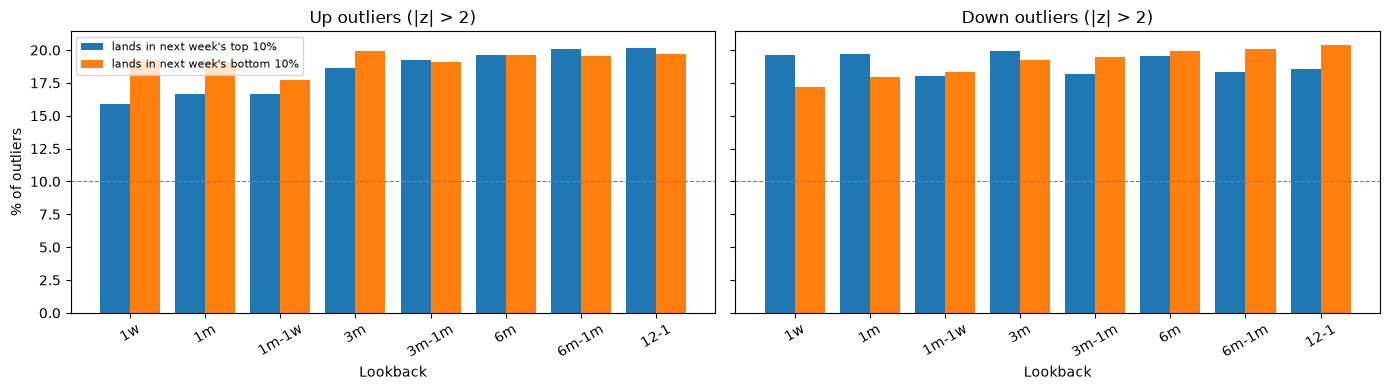

In [17]:
hits_bh = add_bh(hits, ["p_top", "p_bottom", "p_either", "p_dir"])
hcols = ["lookback", "side", "period", "outliers_per_week", "share_of_eligible", "share_next_top10", "share_next_bottom10",
         "share_next_either", "t_either", "q_either", "top_minus_bottom", "t_dir", "q_dir"]
print("Hit rates for total momentum outliers (base rates: 10% per tail, 20% either tail). Direction = top share minus bottom share;"
      " q = Benjamini–Hochberg within period")
display(hits_bh.query("component == 'total' and period in ['full', 'recent']")[hcols].round(3))

h = hits_bh.query("component == 'total' and period == 'full'")
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, side in zip(axes, ["up", "down"]):
    s = h[h.side == side].set_index("lookback").reindex(list(LOOKBACKS))
    x = np.arange(len(s))
    ax.bar(x - 0.2, s["share_next_top10"] * 100, 0.4, label="lands in next week's top 10%")
    ax.bar(x + 0.2, s["share_next_bottom10"] * 100, 0.4, label="lands in next week's bottom 10%")
    ax.axhline(10, color="grey", ls="--", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(s.index, rotation=30)
    ax.set_title(f"{side.capitalize()} outliers (|z| > {Z_OUTLIER:g})"); ax.set_xlabel("Lookback")
axes[0].set_ylabel("% of outliers"); axes[0].legend(fontsize=8)
save(fig, "10_hit_rates.png")

## 11. Dose-response: does a bigger z mean a bigger move, and in which direction?

The most direct answer to the opening question. Each week, eligible stocks are binned by their momentum z-score; for each bin we average next week's return **beyond the eligible average** (direction) and its absolute value (size of move). If the direction line is flat but the size line is U-shaped, outliers predict *that* a stock will move a lot, not *which way*.

The direction line is also shown with skip-a-day returns: if the bounce shrinks a lot, part of it was bid-ask bounce at the signal close.


Next-week return beyond the eligible average (% per week), by z bin, period = full


lookback      12-1                                           1m                                           1w                                   
measure  direction direction, skip a day size of move direction direction, skip a day size of move direction direction, skip a day size of move
bin                                                                                                                                            
< -3       -0.0030                0.1040       6.4060    0.4960                0.4990       6.1760    0.5130                0.4910       6.0210
-3 to -2   -0.0130                0.0570       4.9510    0.2460                0.2730       4.8200    0.3450                0.3160       4.7050
-2 to -1   -0.0470               -0.0130       3.7680    0.1250                0.1190       3.7940    0.1960                0.1540       3.7620
-1 to 1    -0.0210               -0.0250       2.8860   -0.0170               -0.0240       2.9760   -0.0160               -0.0210       2.9850
1 to 2      0.0770                0.0460       3.7310   -0.1150               -0.1010       3.5650   -0.1410               -0.1070       3.6090
2 to 3      0.1600                0.1070       4.8810   -0.1120               -0.0920       4.4890   -0.2050               -0.1620       4.4220
> 3         0.2210                0.1210       6.4290   -0.3200               -0.2770       6.1780   -0.3970               -0.2900       5.8070


Next-week return beyond the eligible average (% per week), by z bin, period = recent


lookback      12-1                                           1m                                           1w                                   
measure  direction direction, skip a day size of move direction direction, skip a day size of move direction direction, skip a day size of move
bin                                                                                                                                            
< -3       -0.0010               -0.0030       7.0310    0.1970                0.1890       6.4510    0.1890                0.1630       6.4900
-3 to -2    0.0300               -0.0020       5.4160    0.0610                0.0600       5.0030    0.1120                0.0890       4.9500
-2 to -1   -0.0530               -0.0540       4.0840    0.0760                0.0610       3.9370    0.1010                0.0600       3.9480
-1 to 1    -0.0100               -0.0010       3.0040   -0.0040               -0.0010       3.1220    0.0040                0.0070       3.1150
1 to 2      0.0530                0.0450       3.9590   -0.0730               -0.0690       3.8510   -0.0800               -0.0620       3.8950
2 to 3      0.1810                0.1160       5.4070   -0.0840               -0.1140       4.9700   -0.1870               -0.1450       4.9130
> 3         0.1840                0.0500       7.2710   -0.1660               -0.1630       7.0890   -0.3270               -0.3430       6.7890

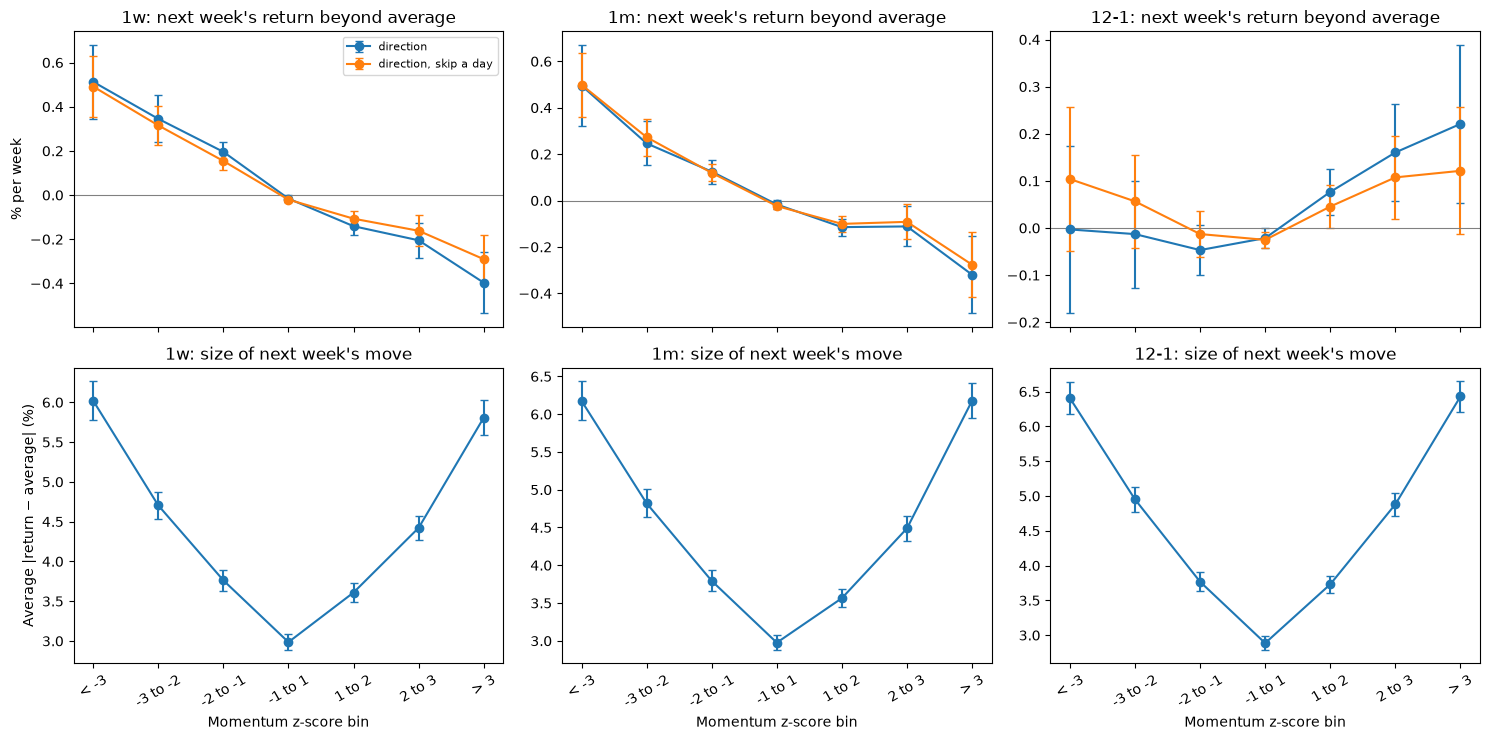

In [18]:
DOSE_LBS = ["1w", "1m", "12-1"]
BINS = [-np.inf, -3, -2, -1, 1, 2, 3, np.inf]
BIN_LABELS = ["< -3", "-3 to -2", "-2 to -1", "-1 to 1", "1 to 2", "2 to 3", "> 3"]
NRX = NR.sub(NR.mean(axis=1), axis=0)
NRXA = NRX.abs()
_n1 = R_FIRST.shift(-1).where(ELIG)
NR1X = _n1.sub(_n1.mean(axis=1), axis=0)
del _n1

dose_rows = []
for lb in DOSE_LBS:
    z = zscore(lb)
    for b, (lo, hi) in enumerate(zip(BINS[:-1], BINS[1:])):
        m = (z > lo) & (z <= hi)
        cnt = m.sum(axis=1)
        for what, X in [("direction", NRX), ("direction, skip a day", NR1X), ("size of move", NRXA)]:
            s = X.where(m).mean(axis=1)
            for per, sl in PERIODS.items():
                r = nw_mean(s.loc[sl])
                dose_rows.append({"lookback": lb, "bin": BIN_LABELS[b], "measure": what, "period": per,
                                  "mean_pct": r["mean"] * 100, "se_pct": r["se"] * 100, "t": r["t"],
                                  "stocks_per_week": cnt.loc[sl].mean()})
    del z
dose = pd.DataFrame(dose_rows)
for per in ["full", "recent"]:
    print(f"\nNext-week return beyond the eligible average (% per week), by z bin, period = {per}")
    display(dose[dose.period == per].pivot_table(index="bin", columns=["lookback", "measure"], values="mean_pct")
            .reindex(BIN_LABELS).round(3))

fig, axes = plt.subplots(2, len(DOSE_LBS), figsize=(15, 7.5), sharex=True)
x = np.arange(len(BIN_LABELS))
for j, lb in enumerate(DOSE_LBS):
    d = dose.query("lookback == @lb and period == 'full'")
    for what, ax in [("direction", axes[0, j]), ("direction, skip a day", axes[0, j]), ("size of move", axes[1, j])]:
        s = d[d.measure == what].set_index("bin").reindex(BIN_LABELS)
        ax.errorbar(x, s["mean_pct"], yerr=1.96 * s["se_pct"], marker="o", capsize=3, label=what)
    axes[0, j].axhline(0, color="grey", lw=0.8)
    axes[0, j].set_title(f"{lb}: next week's return beyond average"); axes[1, j].set_title(f"{lb}: size of next week's move")
    axes[1, j].set_xticks(x); axes[1, j].set_xticklabels(BIN_LABELS, rotation=30); axes[1, j].set_xlabel("Momentum z-score bin")
axes[0, 0].set_ylabel("% per week"); axes[1, 0].set_ylabel("Average |return − average| (%)")
axes[0, 0].legend(fontsize=8)
save(fig, "11_dose_response.png")

## 12. Steady climbers vs sudden spikers (frog in the pan)

Six named categories, set in advance:

| Category | Rule |
|---|---|
| Sudden spike / sudden drop | 1-month z beyond ±2, but no 12-1 trend (\|z\| < 1) |
| Steady climber / steady decliner | 12-1 z beyond ±2 and a smooth path: information discreteness **below the median of that week's 12-1 outliers on the same side** |
| Jumpy climber / jumpy decliner | 12-1 z beyond ±2 and at or above that median |

**Changes from v1.** The steady/jumpy split now uses the median *within* each outlier group, so the two halves are the same size every week (v1 used the all-stock median). Gross returns are shown next to net, because jumpy names cost more to trade and in v1 that cost gap drove most of the steady-minus-jumpy result.

**Frog-in-the-pan test, signed so that positive supports the hypothesis on both sides** (Da, Gurun & Warachka 2014: momentum built from many small moves persists more):
- climbers: **steady minus jumpy** (smooth winners should keep winning more),
- decliners: **jumpy minus steady** (smooth losers should keep losing more).

The event-time charts count each stock once per **entry** into a category (v1 counted every week in the category, so the n in the legend was mostly repeat weeks of long-lived members). **Read only the part after week 0:** every group drifts up before entry because a stock must still be above $5 and liquid at week 0, which selects stocks that did well before.

**New in v4:** each event-path chart has a second panel zoomed on weeks 0 to +13.

In [19]:
SPIKE_UP, STEADY_UP, JUMPY_UP = "Sudden spike (1m up, no 12-1 trend)", "Steady climber (12-1 up, smooth)", "Jumpy climber (12-1 up, jumpy)"
SPIKE_DN, STEADY_DN, JUMPY_DN = "Sudden drop (1m down, no 12-1 trend)", "Steady decliner (12-1 down, smooth)", "Jumpy decliner (12-1 down, jumpy)"

z1m, z12 = zscore("1m"), zscore("12-1")
id12 = signal("12-1", "id").where(ELIG)

def within_median_split(group, x):
    """Split a group at the median of x computed within the group each week: (below median, at or above)."""
    xm = x.where(group)
    med = xm.median(axis=1)
    return group & xm.lt(med, axis=0), group & xm.ge(med, axis=0)

_su, _ju = within_median_split(z12 > Z, id12)
_sd, _jd = within_median_split(z12 < -Z, id12)
CATS = {
    SPIKE_UP: (z1m > Z) & (z12.abs() < 1),
    STEADY_UP: _su, JUMPY_UP: _ju,
    SPIKE_DN: (z1m < -Z) & (z12.abs() < 1),
    STEADY_DN: _sd, JUMPY_DN: _jd,
}
del _su, _ju, _sd, _jd, id12
MEMBERS.update(CATS)

cat_rows = []
for name in CATS:
    for K in GRID_HOLDS:
        cat_rows += summarize(get_port(name, K), {"test": "category", "category": name, "hold": K, "variant": "base"}, K, kind="lo")
cats = pd.DataFrame(cat_rows)
print("Categories, long-only vs market")
display(cats.query("period in ['full', 'recent']")[["category", "hold"] + SHOW + ["sharpe_mkt", "sharpe_diff", "p_sharpe_diff"]].round(4))

frog_rows = []
for side, (a, b) in {"climbers: steady minus jumpy": (STEADY_UP, JUMPY_UP),
                     "decliners: jumpy minus steady": (JUMPY_DN, STEADY_DN)}.items():
    for K in GRID_HOLDS:
        ls = long_short(get_port(a, K), get_port(b, K))
        frog_rows += summarize(ls, {"test": "frog in the pan", "category": side, "hold": K, "variant": "base"}, K)
frog = pd.DataFrame(frog_rows)
frog["cost_drag_ann"] = frog["gross_ann"] - frog["net_ann"]
print("Frog in the pan (positive supports the hypothesis on both sides)")
display(frog[["category", "hold", "period", "names", "gross_ann", "t_gross", "net_ann", "t_net", "cost_drag_ann",
              "alpha7_gross_ann", "t_alpha7_gross", "sharpe_gross"]].round(4))

Categories, long-only vs market


,category,hold,period,names,gross_ann,t_gross,net_ann,t_net,sharpe,alpha7_gross_ann,t_alpha7_gross,appraisal,maxdd,cost_bps_per_side,breakeven_bps,sharpe_mkt,sharpe_diff,p_sharpe_diff
0,"Sudden spike (1m up, no 12-1 trend)",1,full,30.3774,-0.0794,-2.8193,-0.3311,-10.7806,-1.0376,-0.0106,-0.4994,-2.0770,-0.9998,38.0131,11.9834,0.5745,-1.6126,0.0000
2,"Sudden spike (1m up, no 12-1 trend)",1,recent,48.9579,-0.0750,-1.5286,-0.2193,-4.4354,-0.3598,-0.0152,-0.4344,-1.3598,-0.6918,22.8188,11.8690,0.7573,-1.1181,0.0000
3,"Sudden spike (1m up, no 12-1 trend)",4,full,78.3549,0.0223,0.9587,-0.0708,-3.0530,0.1234,0.0579,3.2296,-0.5627,-0.6244,37.0041,8.8649,0.5745,-0.4513,0.0001
5,"Sudden spike (1m up, no 12-1 trend)",4,recent,123.9253,-0.0659,-1.5562,-0.1218,-2.9062,0.0507,-0.0117,-0.4143,-0.8839,-0.5257,22.3138,26.2985,0.7573,-0.7073,0.0004
6,"Sudden spike (1m up, no 12-1 trend)",13,full,201.2286,0.0631,2.9249,0.0349,1.6436,0.6116,0.0543,4.1071,0.2284,-0.5514,36.0803,80.7798,0.5745,0.0371,0.7072
8,"Sudden spike (1m up, no 12-1 trend)",13,recent,315.8812,-0.0144,-0.3385,-0.0315,-0.7506,0.4273,0.0089,0.3737,-0.4197,-0.4396,22.1044,18.6601,0.7573,-0.3303,0.0464
9,"Steady climber (12-1 up, smooth)",1,full,39.5915,0.1194,3.8563,0.0475,1.5373,0.5078,0.0490,2.1284,0.0934,-0.7468,30.4414,50.5610,0.5745,-0.0668,0.5539
11,"Steady climber (12-1 up, smooth)",1,recent,61.4770,0.0564,0.9552,0.0124,0.2127,0.4815,0.0286,0.7381,-0.1579,-0.4053,19.6853,25.2589,0.7573,-0.2761,0.2130
12,"Steady climber (12-1 up, smooth)",4,full,56.6520,0.1118,3.7882,0.0803,2.7251,0.6297,0.0398,1.8409,0.2847,-0.6883,30.1974,106.9482,0.5745,0.0552,0.6059
14,"Steady climber (12-1 up, smooth)",4,recent,87.5613,0.0493,0.8659,0.0288,0.5076,0.5414,0.0230,0.6415,-0.0741,-0.3813,19.8208,47.6285,0.7573,-0.2161,0.3085


Frog in the pan (positive supports the hypothesis on both sides)


,category,hold,period,names,gross_ann,t_gross,net_ann,t_net,cost_drag_ann,alpha7_gross_ann,t_alpha7_gross,sharpe_gross
0,climbers: steady minus jumpy,1,full,82.0107,-0.0069,-0.2527,-0.1844,-6.4938,0.1775,-0.0499,-1.9946,-0.0402
1,climbers: steady minus jumpy,1,discovery,64.6976,0.0006,0.0184,-0.2054,-6.2200,0.2060,-0.0407,-1.3797,0.0034
2,climbers: steady minus jumpy,1,recent,126.6533,-0.0260,-0.4678,-0.1302,-2.3270,0.1042,-0.0699,-1.3766,-0.1507
3,climbers: steady minus jumpy,4,full,120.2666,0.0035,0.1504,-0.0744,-3.1554,0.0779,-0.0337,-1.5390,0.0232
4,climbers: steady minus jumpy,4,discovery,95.5416,0.0072,0.2747,-0.0821,-3.0853,0.0892,-0.0316,-1.2187,0.0487
5,climbers: steady minus jumpy,4,recent,184.0211,-0.0060,-0.1189,-0.0545,-1.0817,0.0486,-0.0451,-0.9849,-0.0373
6,climbers: steady minus jumpy,13,full,189.8271,0.0026,0.1218,-0.0352,-1.6437,0.0377,-0.0272,-1.3721,0.0193
7,climbers: steady minus jumpy,13,discovery,151.3796,-0.0029,-0.1202,-0.0461,-1.8545,0.0432,-0.0330,-1.3491,-0.0229
8,climbers: steady minus jumpy,13,recent,288.9655,0.0168,0.4068,-0.0069,-0.1666,0.0237,-0.0194,-0.5341,0.1166
9,decliners: jumpy minus steady,1,full,77.7334,0.0041,0.1486,-0.2522,-7.8712,0.2563,0.0024,0.0892,0.0252


Member-weeks (what v1's legend counted) vs entries (events)


,category,member-weeks,entries
0,"Sudden spike (1m up, no 12-1 trend)",56782,32158
1,"Steady climber (12-1 up, smooth)",74014,13269
2,"Jumpy climber (12-1 up, jumpy)",79309,16608
3,"Sudden drop (1m down, no 12-1 trend)",62182,34081
4,"Steady decliner (12-1 down, smooth)",69844,14036
5,"Jumpy decliner (12-1 down, jumpy)",75505,18017


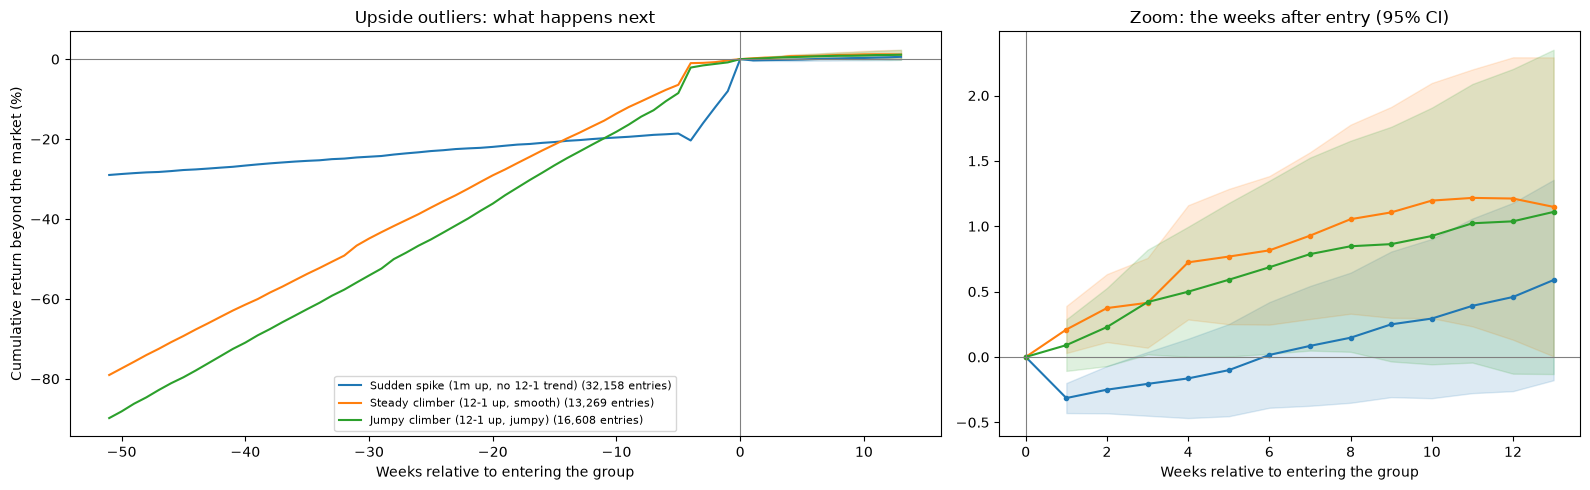

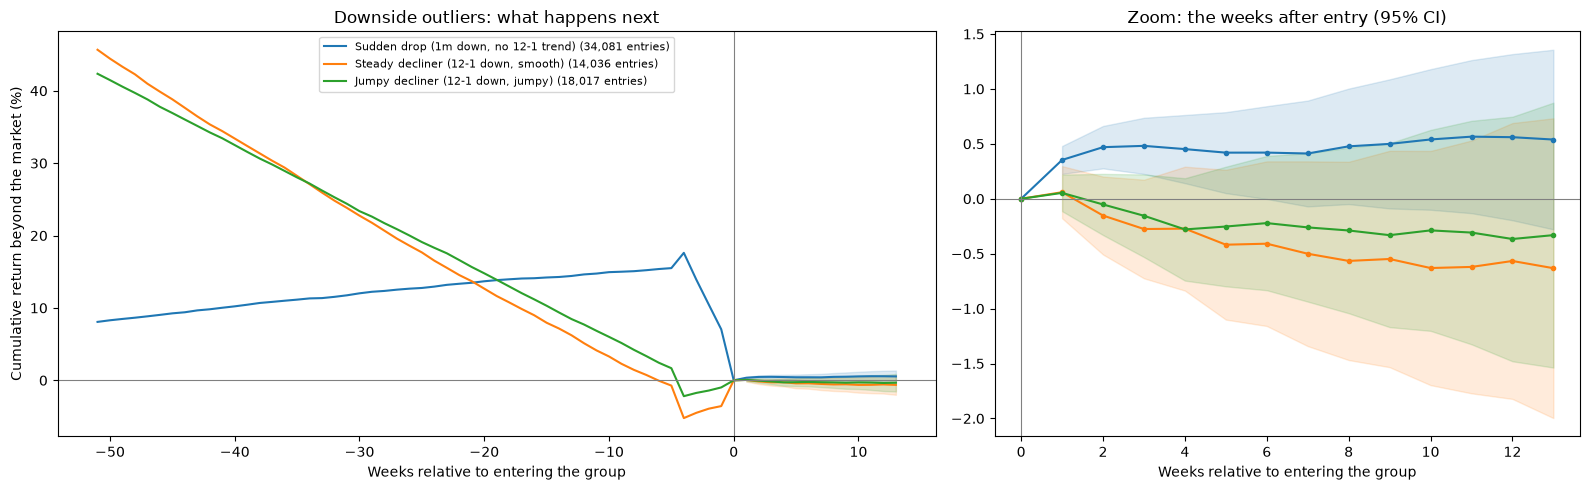

In [20]:
def entries(member):
    """Weeks in which a stock enters a group (in it this week, not last week)."""
    return member & ~member.shift(1, fill_value=False)

def event_path(member, AR, pre=52, post=13, entry_only=True):
    """Average cumulative abnormal return around the week a stock enters a group (week 0).
    Each event week is averaged across its stocks first, so every week counts once. Post-event SEs are NW with lags >= horizon."""
    m = member.reindex(index=AR.index, columns=AR.columns, fill_value=False)
    if entry_only:
        m = entries(m)
    mf = m.astype(float).where(m)
    cols = {k: (AR.shift(-k) * mf).mean(axis=1) for k in range(-pre + 1, post + 1)}
    A = pd.DataFrame(cols)[m.sum(axis=1) > 0]
    path = A.mean().cumsum()
    path = path - path.loc[0]
    post_c = A.loc[:, 1:].cumsum(axis=1)
    se = pd.Series({k: nw_mean(post_c[k], K=k)["se"] for k in post_c.columns})
    return path, se, int(m.values.sum())

def plot_paths(paths, title, fname, zoom=True):
    """Event paths; with zoom=True a second panel shows only the weeks after entry (v4)."""
    fig, axes = plt.subplots(1, 2 if zoom else 1, figsize=(16 if zoom else 10, 5), squeeze=False,
                             gridspec_kw={"width_ratios": [3, 2]} if zoom else None)
    axes = axes[0]
    for name, (path, se, n) in paths.items():
        line, = axes[0].plot(path.index, path.values * 100, label=f"{name} ({n:,} entries)")
        post = path.loc[1:]
        band = ((post - 1.96 * se) * 100, (post + 1.96 * se) * 100)
        axes[0].fill_between(post.index, *band, color=line.get_color(), alpha=0.15)
        if zoom:
            p0 = path.loc[0:]
            axes[1].plot(p0.index, p0.values * 100, marker="o", ms=3, color=line.get_color())
            axes[1].fill_between(post.index, *band, color=line.get_color(), alpha=0.15)
    for ax in axes:
        ax.axvline(0, color="grey", lw=0.8); ax.axhline(0, color="grey", lw=0.8)
        ax.set_xlabel("Weeks relative to entering the group")
    axes[0].set_ylabel("Cumulative return beyond the market (%)")
    axes[0].set_title(title); axes[0].legend(fontsize=8)
    if zoom:
        axes[1].set_title("Zoom: the weeks after entry (95% CI)")
    save(fig, fname)

cnt_rows = [{"category": n, "member-weeks": int(m.values.sum()), "entries": int(entries(m).values.sum())} for n, m in CATS.items()]
print("Member-weeks (what v1's legend counted) vs entries (events)")
display(pd.DataFrame(cnt_rows))
paths = {name: event_path(m, E) for name, m in CATS.items()}
plot_paths({k: paths[k] for k in [SPIKE_UP, STEADY_UP, JUMPY_UP]}, "Upside outliers: what happens next", "12_event_paths_up.png")
plot_paths({k: paths[k] for k in [SPIKE_DN, STEADY_DN, JUMPY_DN]}, "Downside outliers: what happens next", "12_event_paths_down.png")

## 13. Why did it move? News vs no news, and abnormal volume

Chan (2003): stocks that move on public news tend to keep drifting; stocks that move with no news tend to reverse. Two versions:

1. **Earnings news (EDGAR).** An 8-K with Item 2.02 ("Results of Operations and Financial Condition") is a company's earnings release. A stock-week is flagged if one was filed in the formation window (an 8-K accepted at or after 4 pm counts for the next day). Item 2.02 exists from late 2004, so this test starts in `NEWS_START`. It is a narrow definition of news (earnings only), so "no earnings release" is not the same as "no news".
2. **Abnormal dollar volume** (any period): dollar volume over the formation window divided by its median over the 13 weeks before. Split at the median within each outlier group, as in section 12. Heavy volume is a broad proxy for news and attention (Gervais, Kaniel & Mingelgrin 2001).

Spreads are signed so that positive supports Chan: winners **with minus without** news, losers **without minus with** news.

The first run fetches each company's filing history from EDGAR (one request per company plus older-filing pages, at most 10 a second) and caches it in `data_momentum/sec_filings/`.

**New in v4:** set `NEWS_MAX_AGE_DAYS` to re-fetch histories cached more than that many days ago, so the latest earnings releases are flagged in the dated snapshot (section 24).

In [21]:
FILINGS_DIR = DATA_DIR / "sec_filings"; FILINGS_DIR.mkdir(exist_ok=True)

def _rows_8k(block):
    """(filing date, acceptance time, items) for every 8-K in one EDGAR filings block."""
    forms = block.get("form", [])
    acc = block.get("acceptanceDateTime", [""] * len(forms))
    items = block.get("items", [""] * len(forms))
    return [[block["filingDate"][i], acc[i], items[i]] for i, f in enumerate(forms) if f == "8-K"]

def cache_stale(path):
    """True if a filing history is missing, or older than NEWS_MAX_AGE_DAYS when that is set."""
    if not path.exists():
        return True
    return bool(NEWS_MAX_AGE_DAYS) and time.time() - path.stat().st_mtime > NEWS_MAX_AGE_DAYS * 86400

def load_8k(cik):
    """All 8-K filings for a company since NEWS_START, cached as JSON. Returns None if EDGAR refused the request
    (an older cached copy, if any, is then kept)."""
    path = FILINGS_DIR / f"{int(cik)}.json"
    if not cache_stale(path):
        return json.loads(path.read_text())
    try:
        r = requests.get(f"https://data.sec.gov/submissions/CIK{int(cik):010d}.json", headers=SEC_HDR, timeout=30)
        time.sleep(0.12)
        if r.status_code == 404:
            path.write_text("[]")
            return []
        r.raise_for_status()
        j = r.json().get("filings", {})
        rows = _rows_8k(j.get("recent", {}))
        for f in j.get("files", []):
            if str(f.get("filingTo", "9999")) < NEWS_START:
                continue
            r2 = requests.get(f"https://data.sec.gov/submissions/{f['name']}", headers=SEC_HDR, timeout=30)
            time.sleep(0.12)
            r2.raise_for_status()
            rows += _rows_8k(r2.json())
    except Exception:
        return None
    rows = [x for x in rows if str(x[0]) >= NEWS_START]
    path.write_text(json.dumps(rows))
    return rows

def news_dates(rows):
    """Effective dates of earnings 8-Ks (Item 2.02). EDGAR acceptance times are US Eastern; after the 4 pm close
    the news is tradable the next day."""
    out = []
    for date, acc, items in rows:
        if "2.02" not in str(items):
            continue
        d = pd.Timestamp(date)
        acc = str(acc)
        if len(acc) >= 13 and acc[11:13].isdigit() and int(acc[11:13]) >= 16:
            d += pd.Timedelta(days=1)
        out.append(d)
    return out

def week_end(d):
    """The W-FRI week (Saturday to Friday) a date falls in."""
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7)

NEWS_OK = False
if NEWS:
    cik_of = universe.set_index("yahoo")["cik"].reindex(LR.columns).dropna().astype(int)
    todo = [c for c in sorted(set(cik_of)) if cache_stale(FILINGS_DIR / f"{c}.json")]
    print(f"EDGAR filing histories to fetch: {len(todo):,} (cached: {len(set(cik_of)) - len(todo):,})")
    fails, t0 = 0, time.time()
    for k, c in enumerate(todo):
        fails = fails + 1 if load_8k(c) is None else 0
        if fails >= 25:
            print("EDGAR is refusing requests; stopping. Re-run this cell in a few minutes to continue.")
            break
        if k % 500 == 0 and k:
            print(f"  {k:,}/{len(todo):,} ({time.time() - t0:,.0f} s)")
    arr = np.zeros(LR.shape, dtype=bool)
    col_pos = {t: j for j, t in enumerate(LR.columns)}
    n_missing = 0
    for t, c in cik_of.items():
        p = FILINGS_DIR / f"{c}.json"
        if not p.exists():
            n_missing += 1
            continue
        ws = [week_end(d) for d in news_dates(json.loads(p.read_text()))]
        if ws:
            ii = weeks.get_indexer(pd.DatetimeIndex(ws))
            arr[ii[ii >= 0], col_pos[t]] = True
    NEWSW = pd.DataFrame(arr, index=weeks, columns=LR.columns)
    del arr
    NEWS_FROM = pd.Timestamp(NEWS_START) + pd.Timedelta(weeks=8)
    per_year = (NEWSW & ELIG).loc[NEWS_FROM:].values.sum() / (ELIG.loc[NEWS_FROM:].values.sum() / 52)
    print(f"Earnings 8-Ks per eligible stock-year since {NEWS_FROM.date()}: {per_year:.2f} (about 4 expected); "
          f"companies without a filing history: {n_missing:,}")
    NEWS_OK = n_missing < 0.2 * len(cik_of)
    if not NEWS_OK:
        print("Too many filing histories missing; re-run this cell to finish the EDGAR download before reading the news results.")

EDGAR filing histories to fetch: 0 (cached: 4,097)
Earnings 8-Ks per eligible stock-year since 2005-02-26: 3.75 (about 4 expected); companies without a filing history: 0


News vs no news: gross % per year (NW t) | net. Long-only legs are vs the market; 'Chan contrast' is long-short, positive supports Chan (2003)


hold                                                               1                                              4                       
period                                                          full                  recent                   full                 recent
lookback category        leg                                                                                                              
1m       abnormal volume down, with            +16.7% (+5.1) | -4.5%   +0.5% (+0.1) | -12.5%   +7.7% (+2.8) | -0.8%   +1.5% (+0.3) | -3.9%
                         down, without         +25.8% (+5.8) | -0.2%    +5.4% (+0.7) | -9.1%  +13.1% (+3.7) | +3.4%   +1.7% (+0.2) | -3.8%
                         down: Chan contrast   +9.1% (+2.8) | -38.2%   +4.9% (+0.9) | -22.6%  +5.4% (+2.8) | -12.7%  +0.2% (+0.1) | -10.8%
                         up, with              -0.3% (-0.1) | -24.5%   -6.6% (-1.0) | -19.8%   +6.4% (+2.0) | -3.7%  -5.0% (-0.8) | -10.6%
                         up, without          -11.1% (-3.9) | -36.2%   -8.2% (-1.5) | -23.0%  -1.4% (-0.6) | -10.1%  -5.1% (-1.1) | -10.5%
                         up: Chan contrast    +10.8% (+3.5) | -38.4%   +1.6% (+0.3) | -26.4%  +7.7% (+3.5) | -11.1%  +0.1% (+0.0) | -10.9%
         earnings 8-K    down, with            +4.4% (+1.0) | -11.0%   +1.8% (+0.2) | -11.9%   +4.5% (+1.2) | -1.9%   +2.2% (+0.3) | -3.5%
                         down, without         +4.5% (+1.0) | -12.4%   -2.0% (-0.3) | -17.0%   +4.7% (+1.1) | -1.8%   +1.0% (+0.1) | -4.8%
                         down: Chan contrast   -0.3% (-0.1) | -32.7%   -3.8% (-0.7) | -32.6%  +0.1% (+0.0) | -12.7%  -1.2% (-0.3) | -12.6%
                         up, with              +3.3% (+0.9) | -13.0%   -5.3% (-0.8) | -19.6%   +2.9% (+1.0) | -3.6%   -1.3% (-0.3) | -6.9%
                         up, without           -9.5% (-2.2) | -27.1%   -6.0% (-0.9) | -21.1%  -4.0% (-1.1) | -10.6%  -5.6% (-1.0) | -11.3%
                         up: Chan contrast    +12.4% (+2.9) | -21.6%   +0.8% (+0.1) | -28.6%   +6.9% (+2.7) | -6.3%   +4.3% (+1.1) | -7.0%
1w       abnormal volume down, with            +24.7% (+6.7) | -9.7%   +4.1% (+0.5) | -17.0%  +11.2% (+4.5) | +2.4%   +0.8% (+0.2) | -4.6%
                         down, without        +24.7% (+6.0) | -13.8%   +4.9% (+0.6) | -16.8%  +11.8% (+3.9) | +2.0%   +3.0% (+0.5) | -2.6%
                         down: Chan contrast   -0.1% (-0.0) | -73.0%   +0.7% (+0.1) | -42.0%  +0.6% (+0.4) | -17.9%   +2.2% (+0.8) | -8.8%
                         up, with              -5.3% (-1.6) | -42.8%  -14.0% (-1.8) | -36.0%   +2.0% (+0.8) | -7.6%  -7.4% (-1.6) | -13.0%
                         up, without          -17.4% (-5.7) | -53.0%  -14.1% (-2.1) | -35.7%  -3.7% (-1.7) | -12.7%   -4.5% (-1.0) | -9.9%
                         up: Chan contrast    +12.1% (+4.5) | -61.0%   +0.1% (+0.0) | -43.4%  +5.7% (+3.2) | -12.7%  -2.9% (-1.1) | -13.9%
         earnings 8-K    down, with            -3.3% (-0.6) | -27.5%   +2.6% (+0.3) | -18.3%   +2.6% (+0.8) | -3.6%   +1.8% (+0.3) | -3.6%
                         down, without         +9.4% (+2.0) | -15.2%   +5.6% (+0.7) | -15.8%   +4.8% (+1.4) | -1.4%   +2.9% (+0.5) | -2.5%
                         down: Chan contrast  +12.4% (+2.4) | -36.3%   +1.9% (+0.3) | -40.4%  +2.2% (+0.9) | -10.3%   +1.1% (+0.3) | -9.8%
                         up, with              +4.1% (+0.8) | -20.8%  -12.2% (-1.3) | -34.2%   +3.7% (+1.2) | -2.8%   -3.5% (-0.7) | -9.3%
                         up, without          -14.3% (-3.5) | -39.3%  -18.7% (-2.6) | -40.3%  -5.0% (-1.8) | -11.3%  -7.4% (-1.6) | -12.8%
                         up: Chan contrast    +16.9% (+3.6) | -32.9%   +5.8% (+0.7) | -37.8%   +8.8% (+3.3) | -4.1%   +3.9% (+0.9) | -7.3%

Chan contrasts, risk-adjusted (full sample)


,lookback,category,leg,hold,names,gross_ann,t_gross,alpha7_gross_ann,t_alpha7_gross,recent_minus_disc_gross,p_recent_vs_disc_gross
6,1w,earnings 8-K,up: Chan contrast,1,102.2365,0.1693,3.5701,0.1491,3.1066,-0.2077,0.0299
15,1w,earnings 8-K,up: Chan contrast,4,358.9929,0.0876,3.2632,0.0641,2.5062,-0.0903,0.0954
24,1w,earnings 8-K,down: Chan contrast,1,101.0739,0.1236,2.4363,0.1104,2.1913,-0.1953,0.0519
33,1w,earnings 8-K,down: Chan contrast,4,352.7473,0.0216,0.8681,0.0230,0.9979,-0.0199,0.6891
42,1w,abnormal volume,up: Chan contrast,1,82.6692,0.1212,4.5442,0.1418,5.2939,-0.1664,0.0039
51,1w,abnormal volume,up: Chan contrast,4,296.2050,0.0569,3.2136,0.0636,3.6032,-0.1192,0.0005
60,1w,abnormal volume,down: Chan contrast,1,79.2918,-0.0008,-0.0272,-0.0149,-0.5119,0.0112,0.8624
69,1w,abnormal volume,down: Chan contrast,4,283.3870,0.0061,0.3543,0.0048,0.2960,0.0216,0.5387
78,1m,earnings 8-K,up: Chan contrast,1,95.8249,0.1237,2.9411,0.1090,2.6830,-0.2167,0.0092
87,1m,earnings 8-K,up: Chan contrast,4,236.5523,0.0689,2.7491,0.0517,2.1098,-0.0474,0.3466


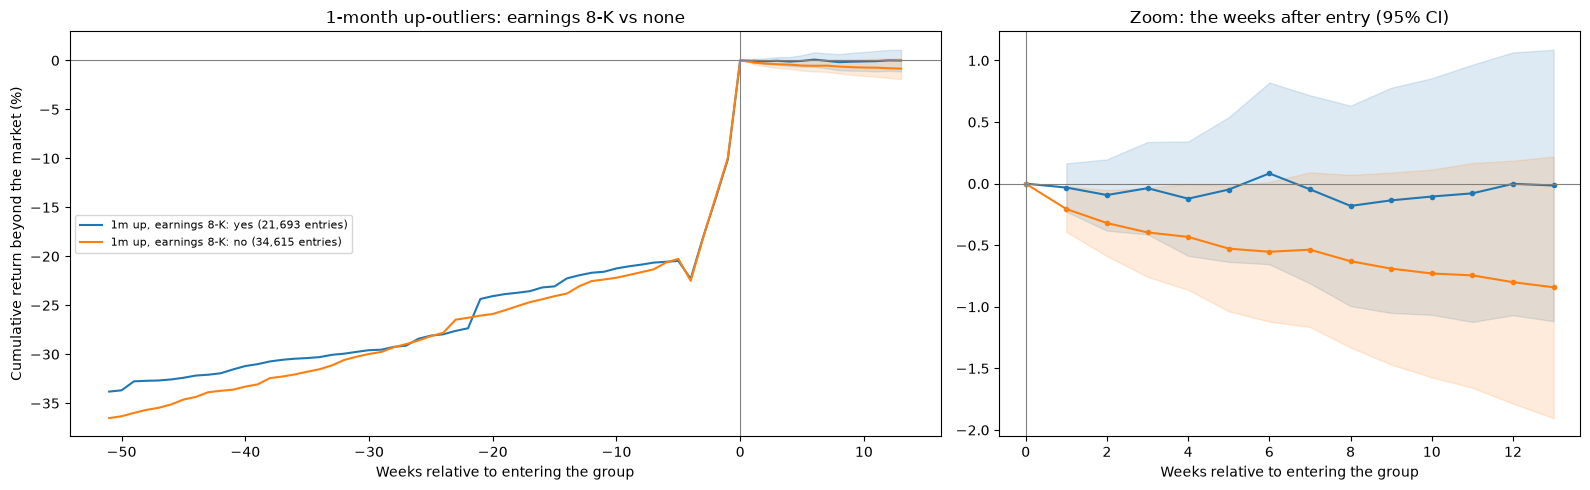

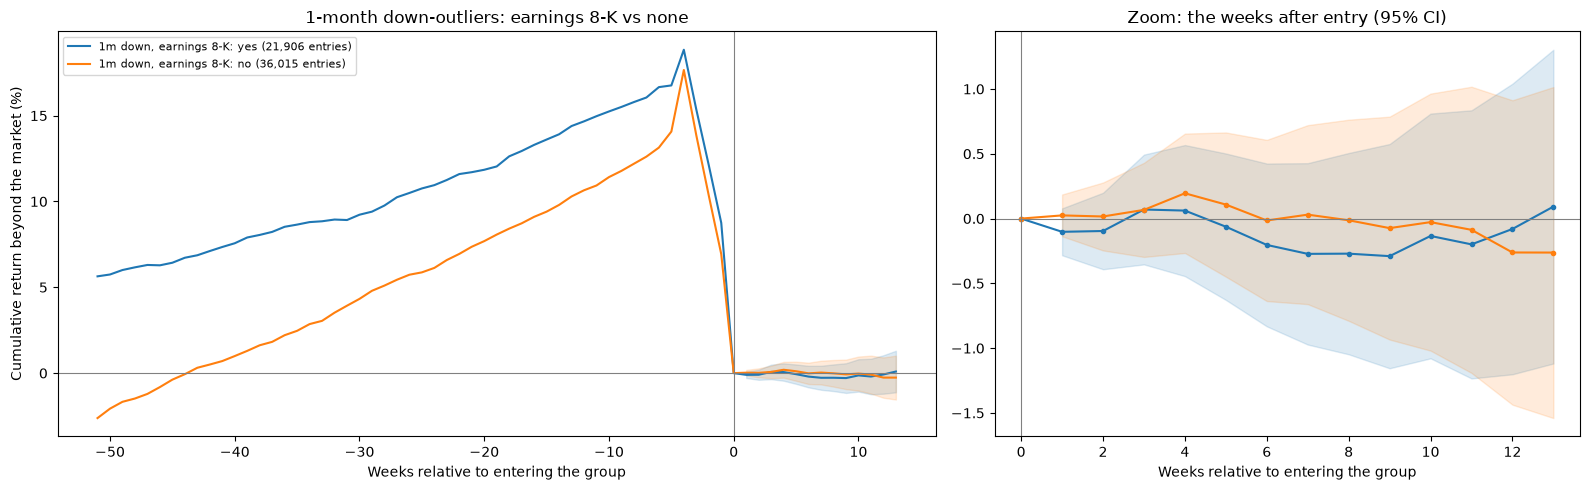

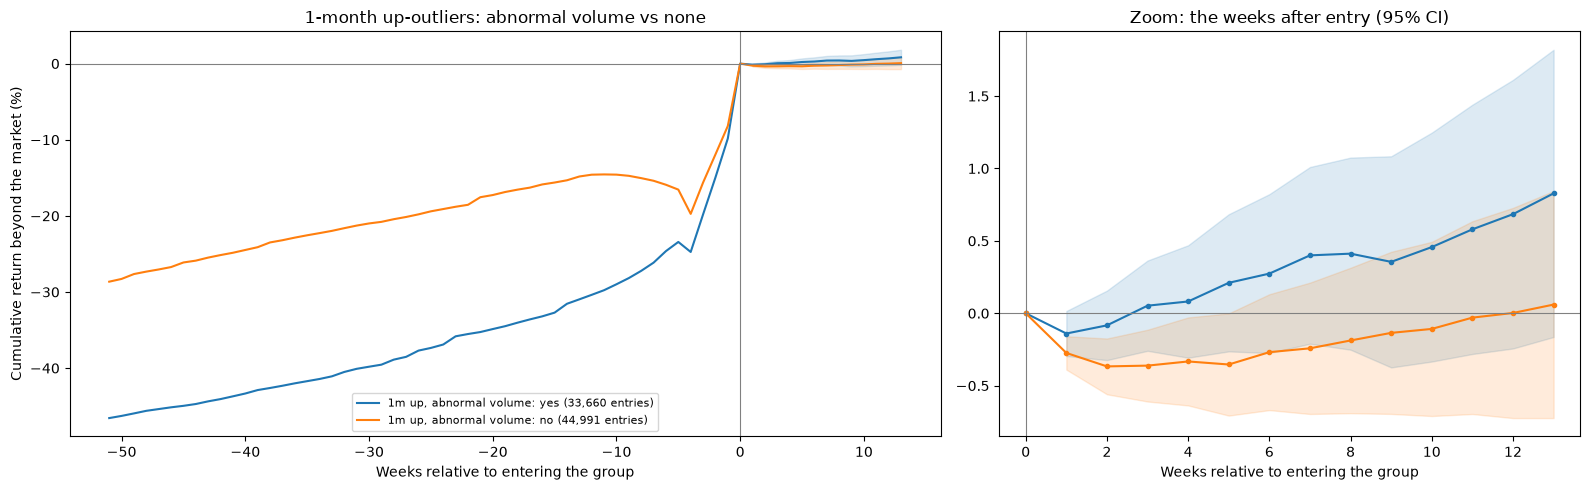

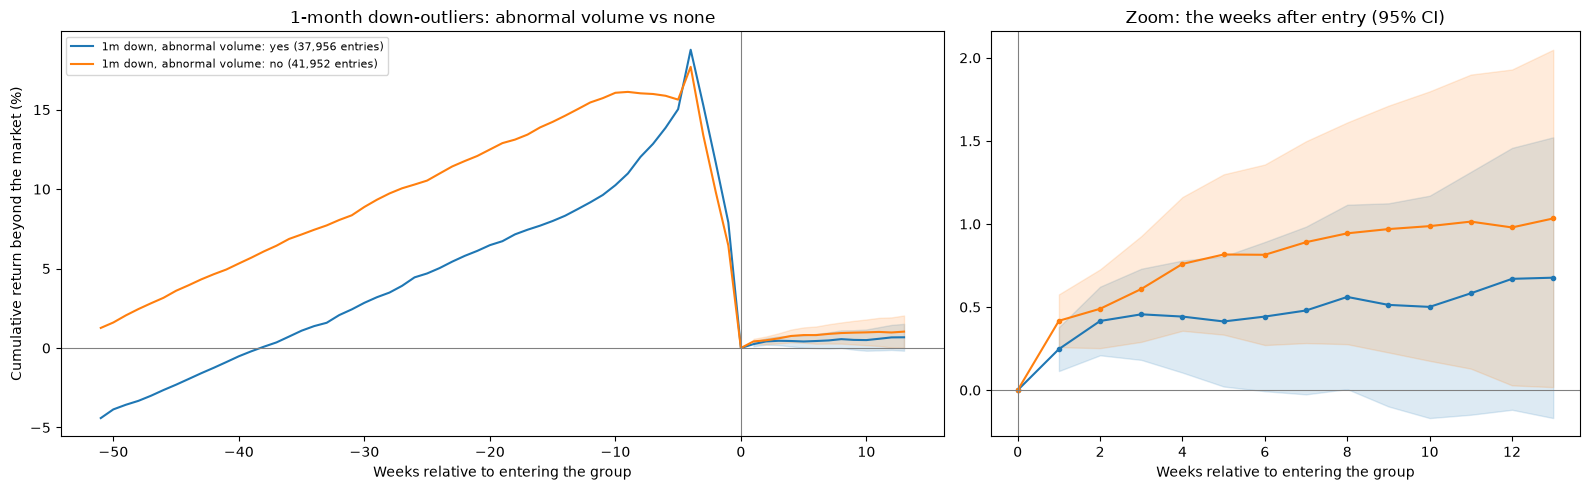

In [22]:
def after(m, start):
    m = m.copy()
    m.loc[m.index < start] = False
    return m

news_rows, NEWS_PATHS = [], {}
for lb in ["1w", "1m"]:
    L = LOOKBACKS[lb][0]
    splits = {}
    if NEWS and NEWS_OK:
        nw_win = NEWSW.astype(float).rolling(L, min_periods=1).max() > 0
        for side in ["up", "down"]:
            g = after(MEMBERS[f"{lb} {side}"], NEWS_FROM)
            splits[("earnings 8-K", side)] = (g & nw_win, g & ~nw_win)
        del nw_win
    av = abnormal_volume(L)
    for side in ["up", "down"]:
        hi_v, lo_v = within_median_split(MEMBERS[f"{lb} {side}"], av)[::-1]
        splits[("abnormal volume", side)] = (hi_v, lo_v)
    del av
    for (kind_, side), (with_, without) in splits.items():
        MEMBERS[f"{lb} {side} | {kind_}: yes"], MEMBERS[f"{lb} {side} | {kind_}: no"] = with_, without
        for K in [1, 4]:
            pw, po = get_port(f"{lb} {side} | {kind_}: yes", K), get_port(f"{lb} {side} | {kind_}: no", K)
            lab = {"test": "news", "lookback": lb, "category": kind_, "hold": K, "variant": "base"}
            news_rows += summarize(pw, {**lab, "leg": f"{side}, with"}, K, kind="lo")
            news_rows += summarize(po, {**lab, "leg": f"{side}, without"}, K, kind="lo")
            ls = long_short(pw, po) if side == "up" else long_short(po, pw)
            news_rows += summarize(ls, {**lab, "leg": f"{side}: Chan contrast"}, K)
        if lb == "1m":
            NEWS_PATHS[(kind_, side)] = {f"1m {side}, {kind_}: yes": event_path(with_, E),
                                         f"1m {side}, {kind_}: no": event_path(without, E)}
news_res = pd.DataFrame(news_rows)
news_res["cell"] = [fmt_cell(g, t, n) for g, t, n in zip(news_res.gross_ann, news_res.t_gross, news_res.net_ann)]
print("News vs no news: gross % per year (NW t) | net. Long-only legs are vs the market; "
      "'Chan contrast' is long-short, positive supports Chan (2003)")
display(news_res[news_res.period.isin(["full", "recent"])].pivot_table(
    index=["lookback", "category", "leg"], columns=["hold", "period"], values="cell", aggfunc="first"))
print("Chan contrasts, risk-adjusted (full sample)")
display(news_res[(news_res.period == "full") & news_res.leg.str.endswith("Chan contrast")][
    ["lookback", "category", "leg", "hold", "names", "gross_ann", "t_gross", "alpha7_gross_ann", "t_alpha7_gross",
     "recent_minus_disc_gross", "p_recent_vs_disc_gross"]].round(4))
for (kind_, side), pp in NEWS_PATHS.items():
    plot_paths(pp, f"1-month {side}-outliers: {kind_} vs none", f"13_news_{kind_.split()[0]}_{side}.png")

## 14. Is it just microcaps? Liquidity terciles, liquidity weighting, reverse splits

Equal-weighting the extremes leans toward small, illiquid stocks, which is where both the anomalies and the costs are largest. The headline strategies are rerun (a) within each liquidity tercile of the eligible universe (formation-week 13-week median dollar volume; 1 = least liquid), (b) liquidity-weighted across all eligible stocks, and (c) **new:** excluding stocks that did a reverse split in the past 52 weeks (known at formation, so no look-ahead). Reverse splits mark distressed names and are a common source of bad price data.

`STRATS` below is also the pre-specified **headline list** used in section 21.

**New in v4:** (d) liquidity-weighted with each stock capped at `LW_CAP` of its cohort, so a few mega-caps can't carry the result.

In [23]:
STRATS = {   # name: (long selection, short selection or None for long-only vs market)
    "1w down-outliers (buy last week's crashes)": ("1w down", None),
    "1w up minus down": ("1w up", "1w down"),
    "1m down-outliers": ("1m down", None),
    "1m up minus down": ("1m up", "1m down"),
    "12-1 up-outliers": ("12-1 up", None),
    "12-1 up minus down": ("12-1 up", "12-1 down"),
    "Steady climbers": (STEADY_UP, None),
    "Sudden spikes": (SPIKE_UP, None),
    "1w top minus bottom decile": ("1w top decile", "1w bottom decile"),
    "1m top minus bottom decile": ("1m top decile", "1m bottom decile"),
    "12-1 top minus bottom decile": ("12-1 top decile", "12-1 bottom decile"),
}

def strat(name, K=1, variant="base"):
    a, b = STRATS[name]
    if b is None:
        return get_port(a, K, variant), "lo"
    return long_short(get_port(a, K, variant), get_port(b, K, variant)), "ls"

LIQ_VARIANTS = [("t1", "tercile 1 (least liquid)"), ("t2", "tercile 2"), ("t3", "tercile 3 (most liquid)"),
                ("base", "all, equal-weighted"), ("lw", "all, liquidity-weighted"),
                ("lwcap", f"all, liquidity-weighted, capped {LW_CAP:.0%}"), ("xrs", "all, excl. recent reverse splits")]
liq_rows = []
for name in STRATS:
    for K in [1, 4]:
        for variant, vlabel in LIQ_VARIANTS:
            p, kind = strat(name, K, variant)
            liq_rows += summarize(p, {"test": "liquidity", "category": name, "hold": K, "variant": vlabel}, K, kind=kind)
liq_res = pd.DataFrame(liq_rows)
liq_res["cell"] = [fmt_cell(g, t, n) for g, t, n in zip(liq_res.gross_ann, liq_res.t_gross, liq_res.net_ann)]
VCOLS = [v for _, v in LIQ_VARIANTS]
for K in [1, 4]:
    for per in ["full", "recent"]:
        print(f"\nGross % per year (NW t) | net, {K}-week hold, period = {per}")
        display(liq_res.query("hold == @K and period == @per").pivot(index="category", columns="variant", values="cell")
                .reindex(index=list(STRATS), columns=VCOLS))
print("Average cost per side (bps), 1-week hold, full sample")
display(liq_res.query("hold == 1 and period == 'full'").pivot(index="category", columns="variant", values="cost_bps_per_side")
        .reindex(index=list(STRATS), columns=VCOLS).round(1))


Gross % per year (NW t) | net, 1-week hold, period = full


variant,tercile 1 (least liquid),tercile 2,tercile 3 (most liquid),"all, equal-weighted","all, liquidity-weighted","all, liquidity-weighted, capped 5%","all, excl. recent reverse splits"
category,,,,,,,
1w down-outliers (buy last week's crashes),+29.5% (+7.0) | -33.9%,+22.3% (+5.6) | -3.8%,+17.0% (+4.0) | +7.5%,+24.7% (+6.9) | -10.5%,+21.5% (+4.7) | +9.2%,+22.6% (+5.6) | +3.2%,+25.1% (+7.0) | -9.9%
1w up minus down,-41.5% (-7.8) | -166.8%,-32.5% (-6.8) | -84.7%,-24.8% (-5.0) | -43.8%,-36.0% (-8.5) | -106.7%,-29.3% (-4.8) | -53.8%,-34.1% (-7.1) | -71.8%,-36.3% (-8.6) | -106.5%
1m down-outliers,+25.7% (+6.4) | -14.5%,+20.9% (+5.4) | +4.7%,+12.1% (+2.9) | +6.4%,+21.0% (+6.0) | +0.1%,+7.8% (+1.7) | +0.2%,+17.3% (+4.3) | +4.9%,+21.6% (+6.2) | +0.8%
1m up minus down,-30.3% (-6.5) | -109.4%,-26.5% (-5.8) | -59.5%,-17.1% (-3.4) | -28.9%,-26.7% (-6.8) | -69.7%,-12.9% (-2.2) | -28.6%,-23.3% (-5.1) | -48.9%,-27.3% (-7.0) | -70.0%
12-1 up-outliers,+17.2% (+3.9) | +0.5%,+7.0% (+1.9) | +0.7%,+13.5% (+3.2) | +11.4%,+12.4% (+3.8) | +5.6%,+17.6% (+3.8) | +15.3%,+14.3% (+3.8) | +10.8%,+12.8% (+4.0) | +6.1%
12-1 up minus down,+17.4% (+3.4) | -18.1%,+4.3% (+0.8) | -9.9%,+11.0% (+1.7) | +6.5%,+10.3% (+2.2) | -6.3%,+18.7% (+2.8) | +12.8%,+13.0% (+2.3) | +2.9%,+10.1% (+2.1) | -6.4%
Steady climbers,+13.4% (+2.7) | -5.9%,+7.2% (+1.9) | -0.7%,+12.7% (+2.9) | +10.1%,+11.9% (+3.9) | +4.7%,+15.3% (+3.2) | +12.2%,+14.7% (+4.2) | +8.9%,+12.1% (+3.9) | +4.9%
Sudden spikes,-3.4% (-0.9) | -47.2%,-7.7% (-2.1) | -26.7%,-10.9% (-3.0) | -18.4%,-7.9% (-2.8) | -33.1%,-12.9% (-3.3) | -24.2%,-8.4% (-3.0) | -30.6%,-7.8% (-2.8) | -32.9%
1w top minus bottom decile,-32.0% (-8.5) | -145.6%,-25.5% (-7.0) | -74.5%,-23.1% (-5.9) | -43.2%,-28.4% (-8.5) | -90.6%,-26.9% (-5.2) | -50.8%,-27.3% (-6.5) | -54.4%,-28.5% (-8.6) | -90.5%



Gross % per year (NW t) | net, 1-week hold, period = recent


variant,tercile 1 (least liquid),tercile 2,tercile 3 (most liquid),"all, equal-weighted","all, liquidity-weighted","all, liquidity-weighted, capped 5%","all, excl. recent reverse splits"
category,,,,,,,
1w down-outliers (buy last week's crashes),-1.5% (-0.2) | -34.7%,+7.6% (+0.9) | -8.5%,+6.1% (+0.7) | -2.7%,+4.5% (+0.6) | -16.1%,+12.6% (+1.4) | +2.5%,+8.5% (+1.0) | -2.1%,+6.2% (+0.8) | -14.0%
1w up minus down,-14.6% (-1.4) | -80.8%,-23.7% (-2.3) | -56.0%,-10.1% (-1.0) | -27.4%,-18.6% (-1.9) | -60.2%,-5.9% (-0.4) | -25.7%,-18.7% (-1.8) | -39.8%,-19.8% (-2.0) | -60.7%
1m down-outliers,-3.4% (-0.5) | -23.7%,+5.9% (+0.8) | -3.8%,+7.4% (+1.0) | +2.2%,+2.9% (+0.4) | -9.3%,+6.9% (+0.8) | +0.6%,+3.9% (+0.5) | -2.6%,+4.8% (+0.7) | -7.2%
1m up minus down,-5.8% (-0.8) | -45.7%,-13.7% (-1.8) | -33.1%,-7.8% (-0.9) | -17.9%,-10.4% (-1.6) | -35.0%,+0.0% (+0.0) | -12.0%,-6.7% (-0.8) | -19.4%,-11.9% (-1.8) | -36.0%
12-1 up-outliers,+3.2% (+0.5) | -4.9%,+0.9% (+0.1) | -2.9%,+18.7% (+2.3) | +17.0%,+7.1% (+1.1) | +2.9%,+24.2% (+2.5) | +22.6%,+17.4% (+2.1) | +15.6%,+7.8% (+1.2) | +3.8%
12-1 up minus down,+7.9% (+1.0) | -9.0%,-2.3% (-0.3) | -9.8%,+23.0% (+2.1) | +19.6%,+8.9% (+1.1) | -0.3%,+25.5% (+1.9) | +21.5%,+19.2% (+1.7) | +14.9%,+7.5% (+0.9) | -1.4%
Steady climbers,-3.5% (-0.4) | -13.7%,+0.6% (+0.1) | -4.2%,+17.1% (+2.3) | +15.0%,+5.6% (+1.0) | +1.2%,+25.3% (+2.5) | +23.2%,+14.3% (+1.9) | +11.8%,+5.9% (+1.0) | +1.6%
Sudden spikes,-10.7% (-1.7) | -33.3%,-5.6% (-0.9) | -17.0%,-8.4% (-1.2) | -14.8%,-7.5% (-1.5) | -21.9%,-4.7% (-0.5) | -12.5%,-5.4% (-1.0) | -15.2%,-7.2% (-1.5) | -21.4%
1w top minus bottom decile,-11.4% (-1.4) | -72.2%,-15.6% (-1.9) | -47.3%,-9.3% (-1.1) | -28.3%,-12.8% (-1.6) | -51.0%,-7.4% (-0.6) | -28.1%,-12.1% (-1.3) | -33.3%,-13.6% (-1.7) | -51.3%



Gross % per year (NW t) | net, 4-week hold, period = full


variant,tercile 1 (least liquid),tercile 2,tercile 3 (most liquid),"all, equal-weighted","all, liquidity-weighted","all, liquidity-weighted, capped 5%","all, excl. recent reverse splits"
category,,,,,,,
1w down-outliers (buy last week's crashes),+13.3% (+4.7) | -2.7%,+11.2% (+3.9) | +4.6%,+8.9% (+2.9) | +6.5%,+11.5% (+4.3) | +2.6%,+8.2% (+2.6) | +5.1%,+10.5% (+3.6) | +5.7%,+11.8% (+4.5) | +3.0%
1w up minus down,-15.4% (-7.1) | -47.0%,-12.1% (-5.7) | -25.2%,-6.3% (-2.6) | -11.1%,-12.3% (-6.7) | -30.0%,-6.0% (-2.2) | -12.1%,-10.3% (-4.6) | -19.7%,-12.5% (-6.8) | -30.0%
1m down-outliers,+11.2% (+3.6) | -5.1%,+11.7% (+3.7) | +5.1%,+6.1% (+1.7) | +3.8%,+10.3% (+3.5) | +1.6%,+2.5% (+0.6) | -0.4%,+8.7% (+2.6) | +3.8%,+10.7% (+3.6) | +2.0%
1m up minus down,-7.1% (-2.4) | -39.4%,-9.6% (-2.9) | -22.8%,-3.4% (-0.9) | -7.9%,-7.7% (-2.7) | -25.5%,+0.9% (+0.2) | -4.9%,-6.8% (-2.0) | -16.5%,-8.1% (-2.9) | -25.8%
12-1 up-outliers,+13.0% (+3.4) | +5.4%,+7.4% (+2.2) | +4.4%,+13.1% (+3.3) | +12.1%,+11.0% (+3.5) | +7.8%,+17.3% (+3.8) | +16.3%,+13.6% (+3.7) | +12.1%,+11.4% (+3.7) | +8.3%
12-1 up minus down,+12.7% (+2.7) | -3.3%,+5.4% (+1.1) | -1.1%,+11.2% (+1.8) | +9.2%,+9.7% (+2.2) | +2.1%,+18.9% (+3.0) | +16.3%,+12.9% (+2.4) | +8.5%,+9.7% (+2.2) | +2.1%
Steady climbers,+13.6% (+2.8) | +5.3%,+8.0% (+2.3) | +4.6%,+13.2% (+3.3) | +12.1%,+11.2% (+3.8) | +8.0%,+14.9% (+3.2) | +13.6%,+14.0% (+4.1) | +11.6%,+11.4% (+3.9) | +8.2%
Sudden spikes,+1.9% (+0.6) | -14.2%,+4.5% (+1.6) | -2.3%,+0.8% (+0.3) | -1.9%,+2.2% (+1.0) | -7.1%,+1.3% (+0.5) | -2.4%,+2.2% (+1.0) | -5.6%,+2.2% (+0.9) | -7.1%
1w top minus bottom decile,-12.4% (-7.2) | -41.0%,-10.5% (-6.2) | -22.8%,-7.4% (-3.8) | -12.4%,-10.6% (-6.7) | -26.1%,-7.0% (-2.9) | -12.9%,-8.2% (-4.1) | -14.9%,-10.6% (-6.7) | -26.1%



Gross % per year (NW t) | net, 4-week hold, period = recent


variant,tercile 1 (least liquid),tercile 2,tercile 3 (most liquid),"all, equal-weighted","all, liquidity-weighted","all, liquidity-weighted, capped 5%","all, excl. recent reverse splits"
category,,,,,,,
1w down-outliers (buy last week's crashes),-4.0% (-0.7) | -12.5%,+3.1% (+0.5) | -1.0%,+7.4% (+1.2) | +5.1%,+1.9% (+0.3) | -3.4%,+9.0% (+1.5) | +6.5%,+6.9% (+1.2) | +4.3%,+3.3% (+0.6) | -1.8%
1w up minus down,-4.7% (-1.4) | -21.6%,-9.2% (-2.4) | -17.4%,-5.7% (-1.3) | -10.1%,-7.8% (-2.4) | -18.3%,-1.5% (-0.3) | -6.4%,-7.5% (-1.8) | -12.8%,-8.5% (-2.6) | -18.8%
1m down-outliers,-4.7% (-0.7) | -13.4%,+4.1% (+0.6) | +0.1%,+5.2% (+0.7) | +3.1%,+1.6% (+0.3) | -3.6%,+4.5% (+0.6) | +2.1%,+4.0% (+0.6) | +1.4%,+3.1% (+0.5) | -2.1%
1m up minus down,-2.3% (-0.5) | -19.4%,-8.8% (-1.5) | -16.9%,-4.4% (-0.6) | -8.4%,-6.7% (-1.3) | -17.3%,+0.4% (+0.0) | -4.3%,-5.5% (-0.8) | -10.6%,-8.0% (-1.6) | -18.4%
12-1 up-outliers,+1.2% (+0.2) | -2.8%,-0.3% (-0.0) | -2.1%,+17.3% (+2.2) | +16.5%,+5.3% (+0.8) | +3.2%,+24.6% (+2.6) | +23.8%,+16.3% (+2.0) | +15.5%,+6.1% (+1.0) | +4.2%
12-1 up minus down,+4.9% (+0.6) | -3.2%,-0.2% (-0.0) | -3.8%,+19.7% (+1.8) | +18.0%,+7.6% (+0.9) | +3.2%,+27.2% (+2.2) | +25.4%,+18.6% (+1.7) | +16.6%,+6.6% (+0.8) | +2.4%
Steady climbers,-5.8% (-0.8) | -10.3%,+1.5% (+0.2) | -0.7%,+17.2% (+2.4) | +16.2%,+4.9% (+0.9) | +2.9%,+25.8% (+2.7) | +24.8%,+14.5% (+2.0) | +13.4%,+5.4% (+1.0) | +3.4%
Sudden spikes,-12.0% (-2.4) | -20.5%,-2.8% (-0.6) | -7.2%,-3.5% (-0.6) | -5.8%,-6.6% (-1.6) | -12.2%,-0.6% (-0.1) | -3.4%,-4.5% (-1.0) | -8.1%,-6.5% (-1.5) | -12.1%
1w top minus bottom decile,-4.1% (-1.4) | -19.7%,-6.4% (-2.0) | -14.3%,-4.9% (-1.4) | -9.7%,-5.9% (-2.0) | -15.6%,-2.3% (-0.5) | -7.5%,-4.2% (-1.1) | -9.5%,-6.3% (-2.1) | -15.8%


Average cost per side (bps), 1-week hold, full sample


variant,tercile 1 (least liquid),tercile 2,tercile 3 (most liquid),"all, equal-weighted","all, liquidity-weighted","all, liquidity-weighted, capped 5%","all, excl. recent reverse splits"
category,,,,,,,
1w down-outliers (buy last week's crashes),67.3000,27.5000,9.9000,37.4000,12.6000,20.4000,37.1000
1w up minus down,66.6000,27.5000,9.9000,37.4000,12.6000,19.6000,37.2000
1m down-outliers,68.7000,28.1000,9.8000,37.8000,12.5000,21.9000,37.5000
1m up minus down,68.8000,28.1000,9.7000,38.3000,12.6000,21.9000,38.1000
12-1 up-outliers,70.3000,27.8000,9.7000,36.1000,12.0000,18.6000,35.7000
12-1 up minus down,72.3000,29.8000,10.0000,41.5000,13.3000,24.9000,41.0000
Steady climbers,63.2000,27.5000,10.0000,30.4000,11.9000,24.6000,30.3000
Sudden spikes,65.6000,27.6000,10.5000,38.0000,15.2000,32.9000,37.9000
1w top minus bottom decile,63.0000,27.0000,10.9000,34.9000,12.7000,14.6000,34.7000


### 14b. Or just a few mega-caps?

Liquidity weights follow dollar volume, so a handful of the most-traded stocks can carry a liquidity-weighted portfolio. In v3, the last-decade liquidity-weighted 12-1 up-outliers had about 9 effective names, and NVDA, TSLA, MU, SNDK and AMD supplied 79% of the return.

v4 compares three ways of holding big, liquid stocks:
- **liquidity-weighted** (as before),
- **liquidity-weighted, capped** at `LW_CAP` per stock,
- **most liquid third, equal-weighted**.

For each, it reports:
- the average largest single-stock weight, and the effective number of names (1 / sum of squared weights),
- the stocks contributing most to the last-10-year gross return (1-week hold),
- the result with those top 5 removed,
- calendar-year returns.

The top 5 are chosen after the fact, so the "without" numbers are a stress test. The capped and top-third versions were added after seeing v3, so they are robustness checks, not part of the headline list.

In [24]:
CONC_STRATS = ["12-1 up-outliers", "Steady climbers", "12-1 up minus down"]
CONC_SCHEMES = {"lw": "liquidity-weighted", "lwcap": f"liquidity-weighted, capped {LW_CAP:.0%}",
                "t3": "most liquid third, equal-weighted"}
act_next = R.shift(-1).sub(mkt.shift(-1), axis=0)          # next week's return beyond the market, on the formation row
rec = PERIODS["recent"]
n_rec = int(R.loc[rec].shape[0])

def formation_weights(member, scheme):
    """Each cohort's stock weights at formation (rows sum to 1) under a weighting scheme."""
    m = member   # at formation; DO NOT filter on next week's outcome availability (look-ahead)
    if scheme == "t3":
        m = m & (LIQ_T == 3)
        w = m.astype(float).where(m)
    else:
        w = dvol13.where(m)
    w = w.div(w.sum(axis=1), axis=0)
    if scheme == "lwcap":
        w = pd.DataFrame(cap_weights(w.fillna(0.0).to_numpy(dtype="float64"), LW_CAP),
                         index=w.index, columns=w.columns).where(w.notna())
    return w

def port_without(name, names, scheme):
    """The 1-week-hold portfolio of a strategy with `names` removed, under a weighting scheme."""
    a, b = STRATS[name]
    kw = {} if scheme == "t3" else {"weights": dvol13}
    if scheme == "lwcap":
        kw["cap"] = LW_CAP
    def sel(key):
        m = MEMBERS[key].copy()
        m.loc[:, [c for c in names if c in m.columns]] = False
        return m & (LIQ_T == 3) if scheme == "t3" else m
    pa = cohort_portfolio(sel(a), R, 1, cost1, **kw)
    if b is None:
        return pa, "lo"
    return long_short(pa, cohort_portfolio(sel(b), R, 1, cost1, **kw)), "ls"

def yearly(name, variant):
    p, kind = strat(name, 1, variant)
    g = p["gross"].dropna()
    y = (1 + g).groupby(g.index.year).prod() - 1
    if kind == "lo":
        y = y - ((1 + mkt.reindex(g.index)).groupby(g.index.year).prod() - 1)
    return y

conc_rows, TOP_CONTRIB, CONTRIB = [], {}, {}
for name in CONC_STRATS:
    a, b = STRATS[name]
    for scheme, slabel in CONC_SCHEMES.items():
        wa = formation_weights(MEMBERS[a], scheme)
        contrib = (wa * act_next).loc[rec].sum()  # observed-outcome attribution ONLY; missing returns excluded, not realized P&L
        row = {"strategy": name, "weighting": slabel, "avg largest weight": wa.loc[rec].max(axis=1).mean(),
               "avg effective names": (1 / (wa.loc[rec] ** 2).sum(axis=1).replace(0, np.nan)).mean()}
        if b is not None:
            wb = formation_weights(MEMBERS[b], scheme)
            contrib = contrib.sub((wb * act_next).loc[rec].sum(), fill_value=0)
            del wb
        del wa
        contrib = contrib / n_rec * 52                       # contribution to the annual gross return
        CONTRIB[(name, scheme)] = contrib
        top5 = contrib.nlargest(5)
        TOP_CONTRIB[(name, scheme)] = pd.DataFrame({"name": NAMES.reindex(top5.index), "contribution_ann": top5,
                                                    "share_of_total": top5 / contrib.sum()})
        p_w, kind = strat(name, 1, scheme)
        with_ = [r for r in summarize(p_w, {}, 1, kind=kind) if r["period"] == "recent"][0]
        p_x, kind = port_without(name, top5.index, scheme)
        without = [r for r in summarize(p_x, {}, 1, kind=kind) if r["period"] == "recent"][0]
        row.update({"approx. total": contrib.sum(), "top-5 share": top5.sum() / contrib.sum(),
                    "gross, last 10y": with_["gross_ann"], "t": with_["t_gross"],
                    "gross without top 5": without["gross_ann"], "t without": without["t_gross"],
                    "net without top 5": without["net_ann"]})
        conc_rows.append(row)
conc_tab = pd.DataFrame(conc_rows)
print(f"Big-stock versions, last {RECENT_YEARS} years, 1-week hold (long-only = vs the market)")
display(conc_tab.round(4))
print(f"\nTop contributors, last {RECENT_YEARS} years (% per year before costs)")
display(pd.concat({f"{n} | {CONC_SCHEMES[s]}": t for (n, s), t in TOP_CONTRIB.items()}).round(4))
YR_VARIANTS = [("base", "EW"), ("lw", "LW"), ("lwcap", "LW capped"), ("t3", "top third EW")]
yr_tab = pd.DataFrame({f"{name} | {lab}": yearly(name, v) for name in CONC_STRATS for v, lab in YR_VARIANTS})
print("Calendar-year gross returns (long-only strategies minus the market), 1-week hold")
display(yr_tab.loc[RECENT_START.year:].round(3))

Big-stock versions, last 10 years, 1-week hold (long-only = vs the market)


,strategy,weighting,avg largest weight,avg effective names,approx. total,top-5 share,"gross, last 10y",t,gross without top 5,t without,net without top 5
0,12-1 up-outliers,liquidity-weighted,0.3431,8.5409,0.2406,0.8081,0.2422,2.4755,0.1195,1.4046,0.0998
1,12-1 up-outliers,"liquidity-weighted, capped 5%",0.0500,33.2728,0.1720,0.2618,0.1737,2.0602,0.1405,1.7120,0.1223
2,12-1 up-outliers,"most liquid third, equal-weighted",0.0306,40.1456,0.1843,0.2289,0.1868,2.3013,0.1531,1.9532,0.1362
3,Steady climbers,liquidity-weighted,0.4249,6.2101,0.2517,0.8772,0.2534,2.4798,0.0992,1.1709,0.0722
4,Steady climbers,"liquidity-weighted, capped 5%",0.0500,27.3328,0.1422,0.3143,0.1431,1.9170,0.1055,1.4471,0.0795
5,Steady climbers,"most liquid third, equal-weighted",0.0512,24.2663,0.1677,0.2792,0.1706,2.3103,0.1300,1.7984,0.1089
6,12-1 up minus down,liquidity-weighted,0.3431,8.5409,0.2542,0.6181,0.2548,1.9390,0.1500,1.2792,0.1067
7,12-1 up minus down,"liquidity-weighted, capped 5%",0.0500,33.2728,0.1919,0.2526,0.1925,1.6997,0.1568,1.4156,0.1125
8,12-1 up minus down,"most liquid third, equal-weighted",0.0306,40.1456,0.2287,0.2706,0.2304,2.0876,0.1800,1.6585,0.1450



Top contributors, last 10 years (% per year before costs)


name  contribution_ann  share_of_total
                                                   Ticker                                                                
12-1 up-outliers | liquidity-weighted              NVDA                     NVIDIA CORP            0.0822          0.3415
                                                   TSLA                     Tesla, Inc.            0.0513          0.2134
                                                   MU             MICRON TECHNOLOGY INC            0.0276          0.1148
                                                   SNDK                    Sandisk Corp            0.0169          0.0704
                                                   AMD       ADVANCED MICRO DEVICES INC            0.0163          0.0679
12-1 up-outliers | liquidity-weighted, capped 5%   NVDA                     NVIDIA CORP            0.0110          0.0637
                                                   CVNA                     CARVANA CO.            0.0090          0.0521
                                                   MU             MICRON TECHNOLOGY INC            0.0089          0.0516
                                                   APP                    AppLovin Corp            0.0085          0.0497
                                                   NVAX                     NOVAVAX INC            0.0077          0.0448
12-1 up-outliers | most liquid third, equal-wei... NVAX                     NOVAVAX INC            0.0105          0.0571
                                                   CVNA                     CARVANA CO.            0.0086          0.0465
                                                   GME                   GameStop Corp.            0.0084          0.0453
                                                   NVDA                     NVIDIA CORP            0.0077          0.0420
                                                   ENPH            Enphase Energy, Inc.            0.0070          0.0379
Steady climbers | liquidity-weighted               NVDA                     NVIDIA CORP            0.1031          0.4097
                                                   TSLA                     Tesla, Inc.            0.0458          0.1818
                                                   MU             MICRON TECHNOLOGY INC            0.0333          0.1323
                                                   PLTR      Palantir Technologies Inc.            0.0209          0.0830
                                                   SNDK                    Sandisk Corp            0.0177          0.0704
Steady climbers | liquidity-weighted, capped 5%    SMCI      Super Micro Computer, Inc.            0.0122          0.0860
                                                   NVDA                     NVIDIA CORP            0.0109          0.0764
                                                   BE                 Bloom Energy Corp            0.0074          0.0517
                                                   LITE          Lumentum Holdings Inc.            0.0071          0.0501
                                                   MU             MICRON TECHNOLOGY INC            0.0071          0.0501
Steady climbers | most liquid third, equal-weig... SMCI      Super Micro Computer, Inc.            0.0123          0.0732
                                                   NVDA                     NVIDIA CORP            0.0120          0.0718
                                                   CAR          AVIS BUDGET GROUP, INC.            0.0088          0.0524
                                                   ENPH            Enphase Energy, Inc.            0.0072          0.0427
                                                   AR             ANTERO RESOURCES Corp            0.0065          0.0390
12-1 up minus down | liquidity-weighted            NVDA                     NVIDIA CORP            0.0714          0.2808
                                                   MU    

Calendar-year gross returns (long-only strategies minus the market), 1-week hold


,12-1 up-outliers | EW,12-1 up-outliers | LW,12-1 up-outliers | LW capped,12-1 up-outliers | top third EW,Steady climbers | EW,Steady climbers | LW,Steady climbers | LW capped,Steady climbers | top third EW,12-1 up minus down | EW,12-1 up minus down | LW,12-1 up minus down | LW capped,12-1 up minus down | top third EW
2016,-0.1040,-0.0060,-0.1600,-0.2180,-0.1910,-0.0480,-0.2080,-0.3240,-0.2550,-0.0850,-0.2890,-0.3390
2017,0.0910,0.2040,0.0700,0.1440,0.0140,0.2190,0.1090,0.2360,-0.0010,0.1520,0.0110,0.0820
2018,-0.0050,-0.0450,-0.0740,-0.0820,-0.0010,-0.0430,-0.0080,0.0330,0.0500,0.0730,-0.0950,-0.0760
2019,0.1110,0.2530,0.1760,0.1650,0.0180,0.0760,0.0920,0.1410,0.1330,0.1210,0.1710,0.2610
2020,0.6160,1.4000,0.7870,1.0520,0.5840,1.4020,0.8230,1.0060,-0.0550,0.5750,0.0180,0.2780
2021,-0.1160,-0.4180,-0.3210,-0.2030,-0.1860,-0.5210,-0.4270,-0.3820,0.0320,-0.2520,-0.2310,-0.1880
2022,0.1250,0.0810,0.2000,0.2740,0.1560,0.1110,0.1910,0.2890,0.5210,0.6740,0.9020,1.0380
2023,-0.1240,-0.0440,-0.0260,-0.0000,-0.1530,0.0170,-0.1050,-0.0780,-0.2210,-0.4600,-0.3020,-0.2560
2024,-0.0620,0.4920,0.3240,0.3380,-0.0290,0.4980,0.1880,0.2530,0.1520,0.7600,0.6340,0.7400
2025,0.0340,0.3100,0.3660,0.3550,0.1150,0.6320,0.4670,0.3980,0.0750,0.0040,0.1990,0.1150


## 15. Skip-a-day: is the reversal just bid-ask bounce? And which day carries the return?

In the base tests the signal is formed at Friday's close and the trade is assumed to happen at that same close. A stock that closed at the bid after a crash looks like it "bounced" when the next price prints at the mid, so some of the 1-week and 1-month reversal can be bid-ask bounce rather than a tradable return. **Skip a day:** each cohort enters at the close of the next trading day instead (its first-day return is replaced by the market's, so long-only results stay comparable with the market). Later weeks are unchanged.

**Placebo (new).** In v2, skipping the first day removed about 72% of the 12-1 long-short's 1-week-hold return, which is far more than one day's share of a week. The placebo drops the **last** day of the first week instead (hold to Thursday's close, the market on Friday). If dropping the last day costs about a fifth of the return and dropping the first day costs much more, the first day is special (a Monday or weekend effect), not a quirk of removing a day.

**Which day (new).** Each leg's next-week return beyond the market split into the first trading day, the middle days (about three) and the last day, annualized. One day's fair share is about a fifth of the week.

**v3 result (Monday effect).** The placebo settled the v2 puzzle:
- Dropping the last day kept 97% of the 12-1 long-short's one-week return; dropping the first day kept 28%.
- The first-day loss sits in the 12-1 losers: about −7.5% a year against the market on the week's first trading day (t ≈ −5).
- The 12-1 signal skips the latest month, so it is known days before Friday's close. For 12-1, the same-close version can be traded.
- Birru (2018) found no day-of-week pattern in momentum (his effect is in anomalies with a speculative short leg), so treat this as a curiosity, not a headline.

In [25]:
skip_rows = []
for name in STRATS:
    for K in [1, 4]:
        for variant, vlabel in [("base", "same close"), ("skip1", "skip a day"), ("droplast", "drop last day (placebo)")]:
            p, kind = strat(name, K, variant)
            skip_rows += summarize(p, {"test": "skip a day", "category": name, "hold": K, "variant": vlabel}, K, kind=kind)
skip_res = pd.DataFrame(skip_rows)
tab = skip_res.query("period == 'full'").pivot_table(index=["category", "hold"], columns="variant",
                                                      values=["gross_ann", "t_gross", "net_ann"])
tab[("share kept: skip a day", "")] = tab[("gross_ann", "skip a day")] / tab[("gross_ann", "same close")]
tab[("share kept: drop last day", "")] = tab[("gross_ann", "drop last day (placebo)")] / tab[("gross_ann", "same close")]
print("Full sample: same close vs skip a day vs drop last day")
display(tab.round(4))
print(f"Last {RECENT_YEARS} years, 1-week hold")
display(skip_res.query("period == 'recent' and hold == 1")[["category", "variant", "gross_ann", "t_gross", "net_ann", "t_net"]].round(4))

lm_w = np.log1p(mkt)
DAY_PARTS = {"first day": D1.sub(MD1, axis=0), "middle days": (LR - D1 - DL).sub(lm_w - MD1 - MDL, axis=0),
             "last day": DL.sub(MDL, axis=0)}
DAY_LEGS = ["1w up", "1w down", "1m up", "1m down", "12-1 up", "12-1 down", "12-1 top decile", "12-1 bottom decile",
            STEADY_UP, SPIKE_UP]
day_rows = []
for leg in DAY_LEGS:
    m = MEMBERS[leg]
    for part, X in DAY_PARTS.items():
        s = X.shift(-1).where(m).mean(axis=1)
        for per in ["full", "recent"]:
            r = nw_mean(s.loc[PERIODS[per]])
            day_rows.append({"leg": leg, "part": part, "period": per, "ann": r["mean"] * 52, "t": r["t"]})
day_tab = pd.DataFrame(day_rows)
day_tab["cell"] = [f"{a:+.1%} ({t:+.1f})" if pd.notna(a) else "" for a, t in zip(day_tab.ann, day_tab.t)]
print("Next week's log return beyond the market, by part of the week (% per year, NW t)")
display(day_tab.pivot_table(index="leg", columns=["period", "part"], values="cell", aggfunc="first")
        .reindex(index=DAY_LEGS, columns=pd.MultiIndex.from_product([["full", "recent"], list(DAY_PARTS)])))
del DAY_PARTS

Full sample: same close vs skip a day vs drop last day


gross_ann                                       net_ann                                       t_gross                        \
variant                                         drop last day (placebo) same close skip a day drop last day (placebo) same close skip a day drop last day (placebo) same close skip a day   
category                                   hold                                                                                                                                             
12-1 top minus bottom decile               1                     0.0794     0.0820     0.0219                 -0.0335    -0.0309    -0.0911                  2.2663     1.9856     0.5984   
                                           4                     0.0742     0.0749     0.0598                  0.0185     0.0191     0.0041                  1.9678     1.8819     1.5837   
12-1 up minus down                         1                     0.0957     0.1035     0.0273                 -0.0705    -0.0627    -0.1389                  2.4428     2.2168     0.6477   
                                           4                     0.0955     0.0975     0.0785                  0.0187     0.0207     0.0016                  2.3092     2.2225     1.8739   
12-1 up-outliers                           1                     0.0798     0.1241     0.1023                  0.0122     0.0564     0.0346                  2.7905     3.8304     3.8268   
                                           4                     0.0991     0.1102     0.1045                  0.0673     0.0784     0.0728                  3.3291     3.5448     3.5965   
1m down-outliers                           1                     0.1416     0.2103     0.2332                 -0.0682     0.0006     0.0234                  4.5257     6.0055     8.1874   
                                           4                     0.0858     0.1030     0.1084                 -0.0014     0.0158     0.0212                  3.0040     3.4804     3.9349   
1m top minus bottom decile                 1                    -0.1599    -0.1931    -0.2065                 -0.4920    -0.5253    -0.5387                 -5.6445    -6.0546    -7.5441   
                                           4                    -0.0620    -0.0705    -0.0737                 -0.2180    -0.2265    -0.2296                 -2.5338    -2.7734    -3.0604   
1m up minus down                           1                    -0.2271    -0.2671    -0.2693                 -0.6569    -0.6969    -0.6991                 -6.5369    -6.8330    -8.2126   
                                           4                    -0.0670    -0.0771    -0.0775                 -0.2452    -0.2553    -0.2556                 -2.4798    -2.7410    -2.9238   
1w down-outliers (buy last week's crashes) 1                     0.1854     0.2468     0.2438                 -0.1668    -0.1054    -0.1084                  5.9598     6.8531     8.2475   
                                           4                     0.0990     0.1145     0.1137                  0.0107     0.0263     0.0255                  3.9321     4.3473     4.6635   
1w top minus bottom decile                 1                    -0.2540    -0.2839    -0.2484                 -0.8759    -0.9059    -0.8703                 -8.1447    -8.5061    -8.6121   
                                           4                    -0.0983    -0.1060    -0.0972                 -0.2534    -0.2612    -0.2523                 -6.3901    -6.7329    -6.6241   
1w up minus down                           1                    -0.3218    -0.3599    -0.3148                 -1.0285    -1.0666    -1.0215                 -8.2841    -8.4628    -8.9402   
                                           4                    -0.1135    -0.1232    -0.1119                 -0.2903    -0.3000    -0.2887                 -6.4063    -6.7076    -6.5701   
Steady climbers                            1                     0.0838     0.1194     0.1020

Last 10 years, 1-week hold


,category,variant,gross_ann,t_gross,net_ann,t_net
2,1w down-outliers (buy last week's crashes),same close,0.0449,0.5876,-0.1614,-2.1808
5,1w down-outliers (buy last week's crashes),skip a day,0.0485,0.7393,-0.1578,-2.4395
8,1w down-outliers (buy last week's crashes),drop last day (placebo),0.0438,0.6371,-0.1625,-2.4712
20,1w up minus down,same close,-0.1857,-1.9123,-0.6025,-5.9728
23,1w up minus down,skip a day,-0.1729,-2.0149,-0.5897,-6.5892
26,1w up minus down,drop last day (placebo),-0.1817,-2.0018,-0.5985,-6.2268
38,1m down-outliers,same close,0.0294,0.4304,-0.0928,-1.4105
41,1m down-outliers,skip a day,0.0383,0.6939,-0.0840,-1.5542
44,1m down-outliers,drop last day (placebo),0.0224,0.3493,-0.0998,-1.6238
56,1m up minus down,same close,-0.1039,-1.5812,-0.3503,-5.0361


Next week's log return beyond the market, by part of the week (% per year, NW t)


full                                     recent                             
                                        first day    middle days      last day     first day    middle days      last day
leg                                                                                                                      
1w up                                -7.8% (-5.4)  -19.0% (-8.6)  -0.5% (-0.5)  -7.7% (-2.4)  -24.9% (-4.7)  -4.6% (-1.9)
1w down                              -3.7% (-2.3)   +6.7% (+2.9)  +3.2% (+2.6)  -6.3% (-1.7)   -8.9% (-1.7)  -3.3% (-1.4)
1m up                                -5.6% (-3.8)  -16.5% (-8.1)  -0.2% (-0.2)  -5.3% (-1.9)  -21.3% (-4.8)  -4.0% (-1.7)
1m down                              -6.3% (-3.7)   +4.4% (+1.8)  +3.7% (+3.0)  -6.8% (-1.7)  -10.7% (-2.1)  -2.6% (-1.2)
12-1 up                              -1.5% (-1.0)   -5.7% (-2.4)  +1.0% (+0.8)  -1.9% (-0.6)  -12.5% (-2.6)  -3.3% (-1.2)
12-1 down                            -9.5% (-5.4)   -8.2% (-3.0)  +0.1% (+0.1)  -5.7% (-1.3)  -17.4% (-3.1)  -3.9% (-1.3)
12-1 top decile                      -1.3% (-1.0)   -4.1% (-2.1)  +0.5% (+0.5)  -1.9% (-0.7)  -10.6% (-2.7)  -4.0% (-1.7)
12-1 bottom decile                   -7.6% (-5.1)   -6.3% (-2.7)  +0.1% (+0.1)  -5.3% (-1.3)  -15.1% (-3.0)  -3.9% (-1.5)
Steady climber (12-1 up, smooth)     -1.2% (-0.8)   -2.7% (-1.2)  +0.8% (+0.6)  -2.6% (-0.8)   -7.0% (-1.5)  -3.0% (-1.1)
Sudden spike (1m up, no 12-1 trend)  -6.4% (-4.4)  -12.1% (-6.2)  -0.8% (-0.7)  -5.4% (-2.0)  -14.0% (-3.7)  -4.8% (-2.1)

## 16. Market-wide state: when do outliers keep going?

Weekly market-wide metrics, each known at the close of week t:

| Metric | Meaning |
|---|---|
| `mkt_4w`, `mkt_52w` | market log return over the last 4 and 52 weeks |
| `bear_3y` | 1 if the market's 3-year return is negative (Cooper, Gutierrez & Hameed 2004) |
| `mkt_vol` | annualized volatility of daily market returns over the last 63 trading days |
| `disp_1m` | cross-sectional MAD of 1-month momentum (how spread out the market is) |
| `mom_gap` | average 12-1 momentum of the top decile minus the bottom decile (Huang 2022) |
| `outlier_share` | share of eligible stocks with \|z\| > 2 on 1-month momentum |

Each strategy's next-week return is regressed on one metric at a time (standardized; `bear_3y` stays 0/1), then on all of them together, with NW t and Benjamini–Hochberg within each strategy × return type × model.

**Gross as well as net.** Estimated spreads rise with volatility and dispersion, so a negative slope on `mkt_vol` or `disp_1m` in *net* returns could be the cost model, not the strategy. If the slope is there in gross returns too, it is real. (v3 also used `median_cost_bps` as a state; v4 drops it, because the pooled cost estimate mostly tracks volatility and its slope on net returns was built in.)


one at a time: slope (% per year per SD; bear_3y per switch) and NW t; * = BH q < 0.05


state                               mkt_4w         mkt_52w         bear_3y         mkt_vol         disp_1m       mom_gap   outlier_share
target             returns                                                                                                              
12-1 up minus down gross      -8.3% (-1.3)   +14.3% (+1.8)   -19.6% (-1.0)   -16.1% (-2.3)   -14.5% (-1.8)  -7.8% (-1.1)    +6.7% (+1.2)
                   net        -8.6% (-1.3)   +15.3% (+1.9)   -29.5% (-1.5)   -16.6% (-2.3)   -15.9% (-1.9)  -8.6% (-1.2)    +7.6% (+1.4)
1m up minus down   gross    +17.3% (+2.2)*  +14.8% (+2.9)*    -5.4% (-0.5)  -17.0% (-3.0)*  -24.0% (-3.0)*  -4.9% (-1.0)  +11.0% (+2.5)*
                   net       +15.6% (+2.0)  +17.7% (+3.4)*   -24.9% (-2.0)  -17.3% (-2.9)*  -26.4% (-3.4)*  -6.8% (-1.3)  +15.2% (+3.3)*
1w up minus down   gross     +23.4% (+2.0)   +13.4% (+2.0)    -3.5% (-0.3)   -21.2% (-1.9)   -34.1% (-2.6)  -0.2% (-0.1)    +9.8% (+2.1)
                   net       +20.7% (+1.7)  +16.4% (+2.3)*  -33.4% (-2.3)*   -19.7% (-1.7)  -36.5% (-2.8)*  -2.6% (-0.5)  +13.8% (+2.7)*
Steady climbers    gross      -2.2% (-0.6)    +3.3% (+0.9)    +3.9% (+0.4)    -0.5% (-0.1)    +1.2% (+0.3)  -1.3% (-0.3)    -3.6% (-1.1)
                   net        -2.4% (-0.6)    +4.7% (+1.3)    -2.1% (-0.2)    -1.5% (-0.4)    +0.6% (+0.1)  -1.4% (-0.3)    -2.8% (-0.8)
Sudden spikes      gross    +11.4% (+3.0)*    +4.4% (+1.5)    +5.7% (+0.8)    -4.8% (-1.6)    -8.2% (-1.8)  -2.5% (-0.7)    +0.3% (+0.1)
                   net      +11.7% (+3.0)*    +7.0% (+2.3)    -6.1% (-0.8)    -5.8% (-1.8)   -10.7% (-2.4)  -4.7% (-1.2)    +2.5% (+0.8)


joint: slope (% per year per SD; bear_3y per switch) and NW t; * = BH q < 0.05


state                               mkt_4w        mkt_52w        bear_3y       mkt_vol         disp_1m         mom_gap  outlier_share
target             returns                                                                                                           
12-1 up minus down gross     -15.5% (-2.3)  +11.7% (+1.5)   -2.1% (-0.1)  -3.3% (-0.3)   -11.6% (-1.0)    +1.4% (+0.2)   +2.0% (+0.3)
                   net       -16.5% (-2.4)  +12.3% (+1.5)  -12.8% (-0.8)  -1.1% (-0.1)   -13.7% (-1.2)    +0.7% (+0.1)   +2.2% (+0.4)
1m up minus down   gross     +13.6% (+2.2)   +2.4% (+0.4)  +14.2% (+1.3)  -6.0% (-0.7)   -21.2% (-1.6)    +8.4% (+1.1)   -0.1% (-0.0)
                   net       +10.4% (+1.7)   +6.8% (+1.1)   -4.8% (-0.4)  +0.2% (+0.0)   -23.3% (-1.7)    +4.2% (+0.5)   +3.5% (+0.6)
1w up minus down   gross     +14.9% (+2.2)   -7.7% (-1.0)  +11.8% (+1.0)  -7.0% (-0.8)  -52.5% (-3.1)*  +32.7% (+2.5)*  -12.2% (-1.7)
                   net       +10.1% (+1.4)   -1.5% (-0.2)  -20.5% (-1.4)  +4.3% (+0.4)  -57.0% (-3.2)*   +27.5% (+1.9)   -9.1% (-1.2)
Steady climbers    gross      -3.6% (-0.9)   +7.1% (+1.6)   +6.3% (+0.7)  +1.7% (+0.3)    +1.6% (+0.2)    -0.8% (-0.1)   -3.5% (-0.8)
                   net        -4.3% (-1.0)   +8.2% (+1.8)   +1.3% (+0.1)  +1.9% (+0.3)    +1.5% (+0.2)    -0.9% (-0.2)   -3.1% (-0.7)
Sudden spikes      gross    +11.2% (+3.1)*   -0.5% (-0.1)  +11.2% (+1.5)  -2.7% (-0.6)    -5.9% (-0.8)    +2.3% (+0.5)   -3.3% (-0.9)
                   net      +10.3% (+2.8)*   +2.6% (+0.7)   +0.6% (+0.1)  +0.8% (+0.2)    -7.4% (-1.0)    -0.8% (-0.2)   -1.7% (-0.5)

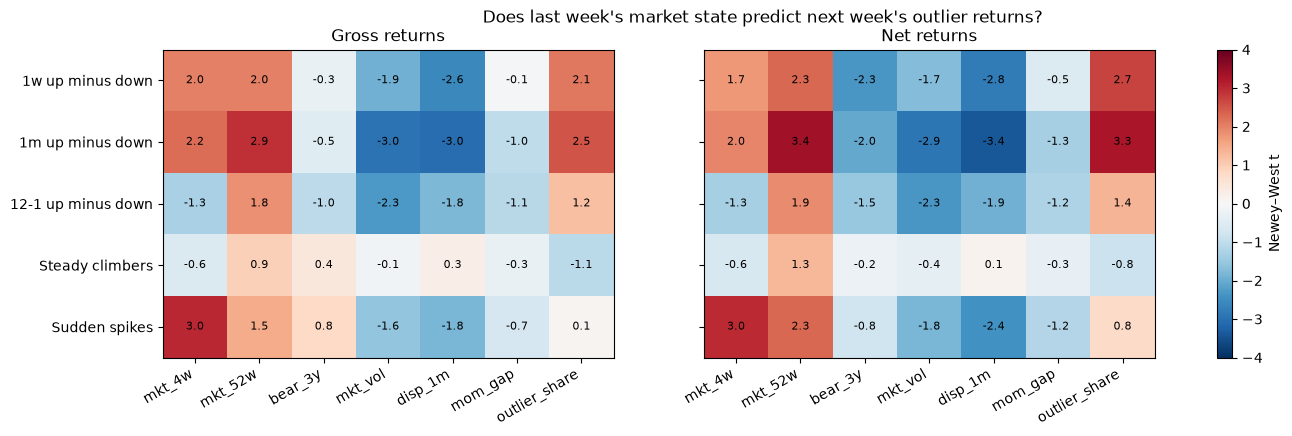

In [26]:
lm = np.log1p(mkt)
STATE = pd.DataFrame(index=weeks)
STATE["mkt_4w"] = lm.rolling(4).sum()
STATE["mkt_52w"] = lm.rolling(52).sum()
r156 = lm.rolling(156).sum()
STATE["bear_3y"] = (r156 < 0).astype(float).where(r156.notna())
STATE["mkt_vol"] = (mkt_d.rolling(63).std() * np.sqrt(252)).resample(WEEK).last().reindex(weeks)
s1m = signal("1m", "total").where(ELIG)
STATE["disp_1m"] = s1m.sub(s1m.median(axis=1), axis=0).abs().median(axis=1)
s12 = signal("12-1", "total").where(ELIG)
q12 = s12.rank(axis=1, pct=True)
STATE["mom_gap"] = s12.where(q12 > 0.9).mean(axis=1) - s12.where(q12 <= 0.1).mean(axis=1)
STATE["outlier_share"] = (z1m.abs() > Z_OUTLIER).sum(axis=1) / ELIG.sum(axis=1)
del s1m, s12, q12, r156

def target(name, col, K=1):
    """Weekly return of a strategy: long-short as is, long-only as active return vs the market."""
    p, kind = strat(name, K)
    return p[col] if kind == "ls" else p[col] - mkt

STATE_TARGETS = ["1w up minus down", "1m up minus down", "12-1 up minus down", "Steady climbers", "Sudden spikes"]
Xs = STATE.shift(1)
Xs = (Xs - Xs.mean()) / Xs.std()
Xs["bear_3y"] = STATE["bear_3y"].shift(1)
state_rows = []
for tname in STATE_TARGETS:
    for col in ["gross", "net"]:
        y = target(tname, col)
        for c in Xs.columns:
            d = pd.concat([y.rename("y"), Xs[c]], axis=1).dropna()
            r = _hac(d["y"], sm.add_constant(d[c]), 1)
            state_rows.append({"target": tname, "returns": col, "model": "one at a time", "state": c,
                               "slope_ann_per_sd": r.params[c] * 52, "t": r.tvalues[c], "p": r.pvalues[c], "weeks": len(d)})
        d = pd.concat([y.rename("y"), Xs], axis=1).dropna()
        r = _hac(d["y"], sm.add_constant(d[list(Xs.columns)]), 1)
        for c in Xs.columns:
            state_rows.append({"target": tname, "returns": col, "model": "joint", "state": c,
                               "slope_ann_per_sd": r.params[c] * 52, "t": r.tvalues[c], "p": r.pvalues[c], "weeks": len(d)})
state_tab = add_bh(pd.DataFrame(state_rows), ["p"], by=["target", "returns", "model"])
state_tab["cell"] = [f"{a:+.1%} ({t:+.1f}){'*' if q < 0.05 else ''}" for a, t, q in
                     zip(state_tab.slope_ann_per_sd, state_tab.t, state_tab.q)]
for model in ["one at a time", "joint"]:
    print(f"\n{model}: slope (% per year per SD; bear_3y per switch) and NW t; * = BH q < 0.05")
    display(state_tab[state_tab.model == model].pivot_table(index=["target", "returns"], columns="state", values="cell",
                                                             aggfunc="first").reindex(columns=list(Xs.columns)))

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["gross", "net"]):
    T_ = state_tab.query("model == 'one at a time' and returns == @col").pivot(index="target", columns="state", values="t")
    T_ = T_.reindex(index=STATE_TARGETS, columns=list(Xs.columns))
    im = ax.imshow(T_.values, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
    ax.set_xticks(range(T_.shape[1])); ax.set_xticklabels(T_.columns, rotation=30, ha="right")
    ax.set_yticks(range(T_.shape[0])); ax.set_yticklabels(T_.index)
    for i in range(T_.shape[0]):
        for j in range(T_.shape[1]):
            ax.text(j, i, f"{T_.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{col.capitalize()} returns")
fig.colorbar(im, ax=axes, label="Newey–West t")
fig.suptitle("Does last week's market state predict next week's outlier returns?")
fig.savefig(OUT_DIR / "16_market_state.png", dpi=150, bbox_inches="tight")
plt.show()

## 17. Industries

**17a. Ken French's value-weighted industries, weekly.** The same outlier rule on Ken French's 49 industry portfolios (survivorship-free): robust z of each industry's momentum against the other industries that week, outliers at |z| > 1.5, with a **quintile** baseline (top 20% minus bottom 20% of industries) so the outlier rule can be compared with plain industry momentum, and last-10-year results printed. Costs are a flat `IND_COST_BPS` per side (think sector ETFs).

**17b. Moskowitz & Grinblatt (1999), monthly.** v1's weekly 1-month industry signal *reversed* over the next week, while M–G found industry momentum even at a 1-month formation period (where individual stocks reverse). Their design: rank industries monthly on past returns, buy the top and short the bottom (3 of 20 industries; here the top and bottom 15% of 49, about 7 each side), hold 1 or 6 months. If the monthly version is positive and the weekly one negative, the difference is the horizon, not a broken signal.

**17c. Industries from our own universe, up to last week.** Ken French's industry files lag by about 6 weeks, so the "which industries are outliers right now" table is built from our own stocks (liquidity-weighted, FF49 industries from current SIC codes). Its weekly returns are checked against Ken French's over the overlap. Industries with fewer than `MIN_IND_STOCKS` eligible stocks are hidden from the table (a handful of stocks can push an industry to an extreme z).


Industries, 1-week hold, full: gross % per year (NW t) | net


category   outlier (|z| > 1.5)                                                            quintile                                             
leg             down vs market           up minus down          up vs market        down vs market          up minus down          up vs market
lookback                                                                                                                                       
1w        +6.9% (+2.7) | +2.3%   -8.7% (-2.3) | -17.9%  -1.1% (-0.4) | -5.7%  +3.3% (+2.0) | -0.7%  -5.3% (-2.3) | -13.3%  -1.9% (-1.4) | -6.0%
1m        +3.0% (+1.1) | +0.0%    -3.7% (-1.0) | -9.7%  -0.3% (-0.1) | -3.4%  -0.1% (-0.1) | -2.1%   +1.5% (+0.7) | -2.5%  +1.4% (+1.0) | -0.6%
1m-1w     -2.1% (-0.8) | -5.3%    +2.9% (+0.7) | -3.8%  -0.5% (-0.2) | -3.9%  -1.6% (-1.0) | -3.9%   +2.9% (+1.4) | -1.7%  +1.3% (+0.9) | -1.0%
3m        +0.6% (+0.2) | -1.4%    +0.7% (+0.2) | -3.5%  +1.6% (+0.6) | -0.5%  +0.1% (+0.1) | -1.0%   +1.2% (+0.5) | -1.0%  +1.4% (+0.9) | +0.2%
3m-1m     -0.8% (-0.3) | -3.1%    +8.3% (+1.9) | +3.6%  +6.3% (+2.2) | +3.9%  -0.9% (-0.5) | -2.2%   +1.8% (+0.7) | -0.9%  +0.9% (+0.6) | -0.5%
6m        -1.3% (-0.4) | -2.9%    +5.1% (+1.2) | +1.9%  +2.3% (+0.8) | +0.7%  -1.1% (-0.6) | -1.9%   +3.0% (+1.1) | +1.3%  +1.9% (+1.2) | +1.1%
6m-1m     -1.6% (-0.5) | -3.3%    +6.5% (+1.5) | +2.9%  +4.4% (+1.5) | +2.6%  -0.5% (-0.3) | -1.4%   +2.1% (+0.8) | +0.3%  +1.6% (+1.0) | +0.7%
12-1      -3.4% (-1.1) | -4.6%  +15.3% (+3.6) | +12.8%  +9.3% (+3.3) | +8.0%  -2.6% (-1.3) | -3.2%   +7.6% (+2.7) | +6.4%  +4.9% (+3.1) | +4.3%


Industries, 4-week hold, full: gross % per year (NW t) | net


category   outlier (|z| > 1.5)                                                            quintile                                            
leg             down vs market           up minus down          up vs market        down vs market         up minus down          up vs market
lookback                                                                                                                                      
1w        +1.2% (+0.7) | +0.1%    -2.2% (-1.2) | -4.6%  -1.0% (-0.6) | -2.2%  +0.3% (+0.3) | -0.7%  -0.6% (-0.5) | -2.6%  -0.3% (-0.3) | -1.3%
1m        +1.7% (+0.8) | +0.5%    -1.1% (-0.4) | -3.4%  +0.6% (+0.3) | -0.6%  -0.5% (-0.4) | -1.5%  +2.4% (+1.3) | +0.4%  +1.8% (+1.4) | +0.8%
1m-1w     +1.1% (+0.6) | -0.0%    +0.6% (+0.2) | -1.8%  +1.7% (+0.9) | +0.5%  -0.5% (-0.4) | -1.5%  +1.7% (+1.0) | -0.3%  +1.2% (+0.9) | +0.2%
3m        -1.5% (-0.6) | -2.3%    +5.4% (+1.4) | +3.7%  +4.0% (+1.6) | +3.2%  -0.8% (-0.4) | -1.3%  +2.8% (+1.1) | +1.7%  +2.1% (+1.4) | +1.5%
3m-1m     -2.0% (-0.7) | -2.9%    +7.1% (+1.8) | +5.3%  +5.0% (+2.1) | +4.1%  -1.2% (-0.7) | -1.9%  +2.4% (+1.0) | +1.1%  +1.2% (+0.8) | +0.5%
6m        -1.1% (-0.4) | -1.8%    +4.1% (+1.0) | +2.8%  +2.6% (+0.9) | +1.9%  -0.9% (-0.5) | -1.3%  +3.1% (+1.2) | +2.3%  +2.1% (+1.4) | +1.7%
6m-1m     -0.4% (-0.2) | -1.1%    +3.0% (+0.7) | +1.6%  +2.9% (+1.1) | +2.2%  -0.5% (-0.3) | -1.0%  +2.7% (+1.1) | +1.8%  +2.1% (+1.4) | +1.7%
12-1      -4.1% (-1.4) | -4.6%  +12.0% (+2.9) | +11.0%  +6.9% (+2.6) | +6.4%  -2.6% (-1.3) | -2.9%  +7.4% (+2.7) | +6.9%  +4.8% (+3.2) | +4.5%


Industries, 1-week hold, recent: gross % per year (NW t) | net


category   outlier (|z| > 1.5)                                                             quintile                                             
leg             down vs market           up minus down           up vs market        down vs market          up minus down          up vs market
lookback                                                                                                                                        
1w        +6.7% (+1.3) | +2.1%   -5.8% (-0.6) | -14.9%   +0.4% (+0.1) | -4.1%  +0.6% (+0.2) | -3.4%  -3.0% (-0.6) | -11.0%  -2.3% (-0.7) | -6.4%
1m        +5.5% (+1.1) | +2.5%    -2.5% (-0.3) | -8.5%   +0.5% (+0.1) | -2.5%  -1.0% (-0.3) | -3.0%   +1.3% (+0.3) | -2.8%  +0.4% (+0.1) | -1.7%
1m-1w     +4.8% (+1.0) | +1.5%    +1.2% (+0.2) | -5.4%   +3.6% (+0.7) | +0.3%  +0.1% (+0.0) | -2.2%   +1.1% (+0.3) | -3.6%  +1.2% (+0.4) | -1.1%
3m        +1.7% (+0.3) | -0.4%    +0.9% (+0.1) | -3.2%   +3.3% (+0.6) | +1.3%  +0.0% (+0.0) | -1.1%   -0.4% (-0.1) | -2.7%  -0.4% (-0.1) | -1.5%
3m-1m     -0.3% (-0.1) | -2.6%    +3.0% (+0.4) | -1.7%   +2.7% (+0.5) | +0.4%  -1.2% (-0.4) | -2.6%   -1.2% (-0.2) | -3.9%  -2.4% (-0.7) | -3.7%
6m        +0.7% (+0.1) | -1.0%    +1.4% (+0.2) | -1.9%   +1.9% (+0.3) | +0.3%  -1.0% (-0.3) | -1.8%   +1.4% (+0.3) | -0.3%  +0.4% (+0.1) | -0.4%
6m-1m     +1.5% (+0.3) | -0.4%    -1.0% (-0.1) | -4.6%   +0.8% (+0.1) | -1.0%  -1.0% (-0.3) | -1.9%   +0.2% (+0.0) | -1.6%  -0.9% (-0.3) | -1.8%
12-1      -3.1% (-0.5) | -4.4%  +14.1% (+1.6) | +11.4%  +11.0% (+1.9) | +9.6%  -3.0% (-0.8) | -3.6%   +6.6% (+1.3) | +5.4%  +3.6% (+1.2) | +3.0%


Industries, 4-week hold, recent: gross % per year (NW t) | net


category   outlier (|z| > 1.5)                                                          quintile                                            
leg             down vs market         up minus down          up vs market        down vs market         up minus down          up vs market
lookback                                                                                                                                    
1w        -0.5% (-0.1) | -1.7%  -0.9% (-0.2) | -3.3%  -1.4% (-0.4) | -2.6%  -0.8% (-0.4) | -1.8%  -1.2% (-0.6) | -3.2%  -2.0% (-0.9) | -3.0%
1m        +4.7% (+1.2) | +3.5%  -4.9% (-0.8) | -7.3%  -0.2% (-0.0) | -1.4%  +0.4% (+0.1) | -0.6%  -0.4% (-0.1) | -2.4%  -0.0% (-0.0) | -1.0%
1m-1w     +4.8% (+1.3) | +3.6%  -3.3% (-0.6) | -5.7%  +1.5% (+0.3) | +0.3%  -0.2% (-0.1) | -1.2%  -0.5% (-0.2) | -2.5%  -0.7% (-0.2) | -1.7%
3m        -0.0% (-0.0) | -0.9%  +2.0% (+0.3) | +0.4%  +2.3% (+0.4) | +1.5%  -0.3% (-0.1) | -0.8%  -0.5% (-0.1) | -1.6%  -0.8% (-0.2) | -1.3%
3m-1m     -1.3% (-0.2) | -2.2%  +3.0% (+0.4) | +1.1%  +1.7% (+0.3) | +0.8%  -1.8% (-0.6) | -2.5%  +0.6% (+0.1) | -0.8%  -1.3% (-0.4) | -1.9%
6m        +0.5% (+0.1) | -0.1%  +1.2% (+0.2) | -0.1%  +0.9% (+0.1) | +0.2%  +0.1% (+0.0) | -0.3%  -0.4% (-0.1) | -1.2%  -0.4% (-0.1) | -0.7%
6m-1m     +0.9% (+0.2) | +0.2%  -2.0% (-0.3) | -3.4%  -0.9% (-0.2) | -1.6%  -0.6% (-0.2) | -1.0%  -0.1% (-0.0) | -0.9%  -0.6% (-0.2) | -1.1%
12-1      -1.5% (-0.3) | -2.0%  +4.8% (+0.6) | +3.6%  +4.2% (+0.8) | +3.6%  -3.0% (-0.8) | -3.3%  +5.5% (+1.2) | +4.9%  +2.5% (+0.9) | +2.2%

Risk-adjusted, 12-1 industry up-outliers and quintile spread (1-week hold)


,category,leg,period,names,gross_ann,t_gross,net_ann,t_net,sharpe,alpha7_gross_ann,t_alpha7_gross,appraisal,maxdd,cost_bps_per_side,breakeven_bps
378,outlier (|z| > 1.5),up minus down,full,8.8910,0.1533,3.5634,0.1277,2.9684,0.4916,0.0707,2.1261,0.5378,-0.5491,5.0000,29.9570
379,outlier (|z| > 1.5),up minus down,discovery,9.1755,0.1580,3.1875,0.1331,2.6826,0.5279,0.0603,1.6695,0.5714,-0.5491,5.0000,31.6799
380,outlier (|z| > 1.5),up minus down,recent,8.1423,0.1409,1.6250,0.1136,1.3121,0.4070,0.0933,1.3447,0.4570,-0.3957,5.0000,25.8163
381,outlier (|z| > 1.5),up vs market,full,4.1659,0.0932,3.3112,0.0798,2.8342,0.7242,0.0379,1.3704,0.4594,-0.6270,5.0000,34.5764
382,outlier (|z| > 1.5),up vs market,discovery,4.2382,0.0868,2.7328,0.0737,2.3190,0.6581,0.0081,0.2504,0.4353,-0.6270,5.0000,32.9739
383,outlier (|z| > 1.5),up vs market,recent,3.9778,0.1099,1.8895,0.0956,1.6457,0.8839,0.0957,1.8753,0.5194,-0.3772,5.0000,38.4176
405,quintile,up minus down,full,20.0000,0.0759,2.6750,0.0640,2.2573,0.3662,0.0330,2.0991,0.4218,-0.5962,5.0000,32.0555
406,quintile,up minus down,discovery,20.0000,0.0797,2.3071,0.0680,1.9690,0.3872,0.0343,1.7898,0.4491,-0.5962,5.0000,34.1760
407,quintile,up minus down,recent,20.0000,0.0660,1.3228,0.0537,1.0764,0.3103,0.0327,1.0104,0.3343,-0.2882,5.0000,26.8071
408,quintile,up vs market,full,10.0000,0.0494,3.1199,0.0434,2.7354,0.7311,0.0125,0.9184,0.4599,-0.5464,5.0000,40.6675


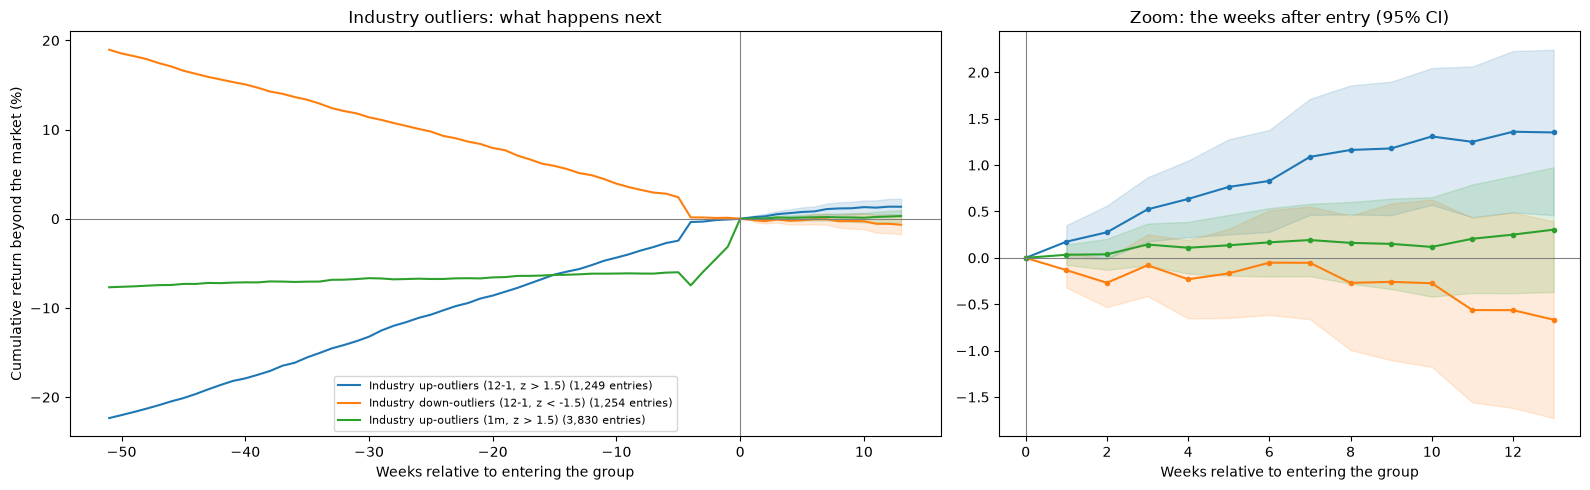

In [27]:
IR = to_weekly(kf_ind_vw)
IR = IR[IR.index <= kf_ind_vw.index.max()].reindex(weeks)     # drop a partial final week
IR = IR.loc[:, IR.notna().mean() > 0.9]
ILR = np.log1p(IR)
IELIG = IR.notna()

ind_rows, IND_Z, IND_PORTS = [], {}, {}
for lb, (L, skip) in LOOKBACKS.items():
    s = window_sum(ILR, L, skip)
    zi = robust_z(s, IELIG & s.notna())
    IND_Z[lb] = zi
    q_up, q_dn = decile_members(s, IELIG & s.notna(), q=0.2)
    for rule, (up_m, dn_m) in {f"outlier (|z| > {Z_IND:g})": (zi > Z_IND, zi < -Z_IND), "quintile": (q_up, q_dn)}.items():
        for K in GRID_HOLDS:
            up = cohort_portfolio(up_m, IR, K, flat_bps=IND_COST_BPS)
            dn = cohort_portfolio(dn_m, IR, K, flat_bps=IND_COST_BPS)
            if lb == "12-1":
                IND_PORTS[(rule, K)] = (up, dn)            # for section 22
            lab = {"test": "industry", "lookback": lb, "category": rule, "hold": K, "variant": "base"}
            ind_rows += summarize(long_short(up, dn), {**lab, "leg": "up minus down"}, K)
            ind_rows += summarize(up, {**lab, "leg": "up vs market"}, K, kind="lo")
            ind_rows += summarize(dn, {**lab, "leg": "down vs market"}, K, kind="lo")
ind_res = pd.DataFrame(ind_rows)
ind_res["cell"] = [fmt_cell(g, t, n) for g, t, n in zip(ind_res.gross_ann, ind_res.t_gross, ind_res.net_ann)]
for per in ["full", "recent"]:
    for K in [1, 4]:
        print(f"\nIndustries, {K}-week hold, {per}: gross % per year (NW t) | net")
        display(ind_res.query("period == @per and hold == @K").pivot_table(index="lookback", columns=["category", "leg"],
                values="cell", aggfunc="first").reindex(list(LOOKBACKS)))
print("Risk-adjusted, 12-1 industry up-outliers and quintile spread (1-week hold)")
display(ind_res.query("lookback == '12-1' and hold == 1 and leg != 'down vs market'")[["category", "leg"] + SHOW].round(4))

AR_ind = IR.sub(mkt, axis=0)
plot_paths({f"Industry up-outliers (12-1, z > {Z_IND:g})": event_path(IND_Z["12-1"] > Z_IND, AR_ind),
            f"Industry down-outliers (12-1, z < -{Z_IND:g})": event_path(IND_Z["12-1"] < -Z_IND, AR_ind),
            f"Industry up-outliers (1m, z > {Z_IND:g})": event_path(IND_Z["1m"] > Z_IND, AR_ind)},
           "Industry outliers: what happens next", "17_industry_event_paths.png")

In [28]:
# ---- 17b. Moskowitz & Grinblatt (1999), monthly, Ken French value-weighted industries
IRM = kf_ind_m.loc[pd.Period("1963-07", "M"):]
IRM = IRM.loc[:, IRM.notna().mean() > 0.5]
ILRM = np.log1p(IRM)
MG_DESIGNS = {"1-month formation, 1-month hold": (1, 0, 1),
              "6-month formation, 1-month hold": (6, 0, 1),
              "6-month formation, 6-month hold (M–G headline)": (6, 0, 6),
              "12-1 formation, 1-month hold": (12, 1, 1)}
MG_PERIODS = {"M–G sample (Jul 1963 – Jul 1995)": (pd.Period("1963-07", "M"), pd.Period("1995-07", "M")),
              "1990 onward (our sample)": (pd.Period("1990-01", "M"), None),
              f"last {RECENT_YEARS} years": (pd.Period(RECENT_START, "M") + 1, None)}
mg_rows = []
for dname, (L, skip, H) in MG_DESIGNS.items():
    s = window_sum(ILRM, L, skip)
    top, bot = decile_members(s, IRM.notna() & s.notna(), q=0.15)
    ls = cohort_portfolio(top, IRM, H)["gross"] - cohort_portfolio(bot, IRM, H)["gross"]
    for pname, (a, b) in MG_PERIODS.items():
        x = ls.loc[a:b].dropna()
        r = nw_mean(x, H)
        mg_rows.append({"design": dname, "period": pname, "spread_ann": r["mean"] * 12, "t": r["t"], "p": r["p"],
                        "sharpe": x.mean() / x.std() * np.sqrt(12), "months": len(x)})
mg = pd.DataFrame(mg_rows)
print("Industry momentum, monthly (top minus bottom 15% of industries, before costs)")
display(mg.pivot(index="design", columns="period", values="spread_ann").round(4))
display(mg.pivot(index="design", columns="period", values="t").round(2))

Industry momentum, monthly (top minus bottom 15% of industries, before costs)


period,1990 onward (our sample),M–G sample (Jul 1963 – Jul 1995),last 10 years
design,,,
"1-month formation, 1-month hold",0.0484,0.1220,0.0650
"12-1 formation, 1-month hold",0.0870,0.1110,0.0668
"6-month formation, 1-month hold",0.0489,0.0883,0.0303
"6-month formation, 6-month hold (M–G headline)",0.0555,0.0721,0.0579


period,1990 onward (our sample),M–G sample (Jul 1963 – Jul 1995),last 10 years
design,,,
"1-month formation, 1-month hold",2.0200,5.5900,1.3700
"12-1 formation, 1-month hold",2.7900,3.9600,1.2800
"6-month formation, 1-month hold",1.7300,3.1400,0.5400
"6-month formation, 6-month hold (M–G headline)",2.5500,3.1600,1.6700


In [29]:
# ---- 17c. industries from our own universe (current through last week)
w_lag = dvol13.where(ELIG).shift(1)
_ind_num = (R * w_lag).T.groupby(ind).sum(min_count=1).T
_ind_den = w_lag.where(R.notna()).T.groupby(ind).sum().T
OWN_IR = (_ind_num / _ind_den.where(_ind_den > 0)).drop(columns="Other", errors="ignore")
del _ind_num, _ind_den
common = OWN_IR.columns.intersection(IR.columns)
own_corr = pd.Series({c: OWN_IR[c].corr(IR[c]) for c in common})
print(f"Weekly correlation of our industry returns with Ken French's: median {own_corr.median():.2f} "
      f"(lowest: {', '.join(f'{k} {v:.2f}' for k, v in own_corr.nsmallest(3).items())})")

OWN_ILR = np.log1p(OWN_IR)
own_ok = OWN_IR.notna()
latest = {}
for lb, (L, skip) in LOOKBACKS.items():
    s = window_sum(OWN_ILR, L, skip)
    latest[lb] = robust_z(s, own_ok & s.notna()).iloc[-1]
latest = pd.DataFrame(latest)
latest["stocks"] = ELIG.iloc[-1].groupby(ind).sum().reindex(latest.index)
thin = latest.index[latest["stocks"] < MIN_IND_STOCKS]
latest_all, latest = latest, latest.drop(index=thin)
print(f"Industry momentum z-scores from our universe, week ending {weeks[-1].date()} "
      f"(Ken French's industries end {IR.dropna(how='all').index[-1].date()}).")
print(f"Hidden: {len(thin)} industries with fewer than {MIN_IND_STOCKS} eligible stocks ({', '.join(thin)}). "
      "Top and bottom 5 on 12-1, then on 1m:")
z12_sorted = latest.sort_values("12-1", ascending=False)
display(pd.concat([z12_sorted.head(5), z12_sorted.tail(5)]).round(2))
z1_sorted = latest.sort_values("1m", ascending=False)
display(pd.concat([z1_sorted.head(5), z1_sorted.tail(5)]).round(2))

Weekly correlation of our industry returns with Ken French's: median 0.91 (lowest: Agric 0.37, Soda 0.38, FabPr 0.49)
Industry momentum z-scores from our universe, week ending 2026-10-16 (Ken French's industries end 2026-08-28).
Hidden: 15 industries with fewer than 15 eligible stocks (Agric, Beer, Books, Boxes, Coal, FabPr, Gold, Guns, Paper, Rubbr, Ships, Smoke, Soda, Toys, Txtls). Top and bottom 5 on 12-1, then on 1m:


,1w,1m,1m-1w,3m,3m-1m,6m,6m-1m,12-1,stocks
sic,,,,,,,,,
Hardw,-2.5800,-2.7700,-0.9000,0.3200,2.5500,2.8900,5.1000,3.9100,34
Chips,-2.5600,-1.4700,1.0900,0.4300,1.6300,1.4500,2.6300,2.5600,106
Steel,-1.3300,-0.9500,0.1700,-1.0900,-0.2400,-0.7500,-0.3300,2.0700,28
Oil,0.8200,1.2100,0.5500,2.8500,1.8800,1.9400,1.7600,1.9700,78
LabEq,-2.1700,-0.9300,1.3700,0.3300,1.1200,0.1800,0.7900,1.7800,42
Util,0.0300,0.4000,0.3900,-0.4600,-0.6900,-0.4600,-0.7200,-1.0200,90
Autos,-1.3100,-0.5700,0.7400,-0.9500,-0.4100,-0.8600,-0.6800,-1.0600,36
RlEst,-0.0500,-0.9400,-1.5700,-1.5500,-0.7000,-0.7200,-0.3100,-1.3800,26
Clths,0.9300,1.1800,0.3500,-1.0700,-1.9000,-1.0300,-1.8500,-1.4000,21


,1w,1m,1m-1w,3m,3m-1m,6m,6m-1m,12-1,stocks
sic,,,,,,,,,
Hshld,0.7900,1.2300,0.6300,1.0600,0.1200,0.7800,0.3300,-0.2700,29
Oil,0.8200,1.2100,0.5500,2.8500,1.8800,1.9400,1.7600,1.9700,78
Clths,0.9300,1.1800,0.3500,-1.0700,-1.9000,-1.0300,-1.8500,-1.4000,21
Whlsl,0.3500,0.8700,0.6800,0.5200,-0.1200,0.1200,-0.2700,0.1200,57
Rtail,0.1500,0.7000,0.6800,0.4300,-0.0600,0.0500,-0.2600,0.0100,94
Mines,-1.2400,-1.3100,-0.5000,0.6100,1.6800,-1.2400,-0.7400,-0.1300,22
Chips,-2.5600,-1.4700,1.0900,0.4300,1.6300,1.4500,2.6300,2.5600,106
Telcm,-0.0200,-1.5000,-2.4900,-0.5600,0.7100,-1.6100,-1.0900,-0.3800,51
Banks,-0.9700,-1.8300,-1.6700,-0.3700,1.1400,-0.5400,0.3900,-0.4600,284


## 18. Crashes and January

**Drawdowns and episodes.** Maximum drawdown (with peak and trough dates), the worst 13-week window, and returns over known momentum-crash episodes, after estimated costs. For long-only strategies the drawdown against the market is shown too.

**Daniel & Moskowitz (2016) crash mechanism.** After a bear market, the loser portfolio is full of beaten-down, high-beta stocks, so when the market rebounds the losers rebound hardest and momentum crashes. Their regression, run weekly here on gross returns:

return = a + a_B·Bear + [b + Bear·(b_B + Up·b_BU)]·Market + e

with Bear = 1 if the market's past 2-year return is negative (known at t−1) and Up = 1 if the market rose this week. A strongly negative **b_BU** is the crash signature: in bear markets the strategy's beta collapses exactly when the market goes up. The predictive version asks whether bear markets *with high volatility* forecast low momentum returns. v1's `bear_3y` alone was not significant; the interaction is the mechanism to test.

**January.** Losers tend to rebound in January (tax-loss selling in December), which hurts momentum and helps "buy the losers". Also shown: November–April vs May–October (the Sell in May video).

Drawdowns and crash episodes, after estimated costs (1-week hold)


,strategy,kind,max_drawdown,peak,trough,worst_13w,worst_13w_ending,2009 rebound (Mar 6 – May 29),2020 crash (Feb 21 – Mar 20),2020 rebound (Mar 20 – Jun 5),Nov 2020 vaccine week,max_drawdown_vs_market
0,12-1 top minus bottom decile,ls,-0.9470,2000-03-10,2021-05-14,-0.5870,2009-06-05,-0.5740,0.0400,-0.3530,-0.2010,NaN
1,12-1 up minus down,ls,-0.9800,1992-01-10,2021-05-14,-0.6830,2009-06-05,-0.6700,0.0390,-0.3330,-0.2280,NaN
2,12-1 up-outliers,lo,-0.7270,2007-10-12,2009-03-20,-0.5530,2008-11-21,0.0890,-0.3930,0.6300,-0.0170,-0.6330
3,Steady climbers,lo,-0.7470,2007-10-26,2009-03-06,-0.5320,2008-10-10,0.0710,-0.3810,0.5990,-0.0310,-0.7510
4,1w up minus down,ls,-1.0000,1990-01-05,2022-03-25,-0.7830,2020-06-12,-0.4440,0.1820,-0.7490,-0.1210,NaN
5,1w down-outliers (buy last week's crashes),lo,-0.9040,2000-03-03,2020-03-20,-0.5650,2020-03-20,0.5820,-0.5470,1.4190,0.1090,-0.9910
6,1m down-outliers,lo,-0.7410,2006-04-28,2009-03-06,-0.5790,2008-11-21,0.6150,-0.5650,0.9200,0.0930,-0.9060
7,Sudden spikes,lo,-1.0000,1991-02-01,2026-10-16,-0.4850,2008-11-21,0.0820,-0.3670,0.2790,0.0070,-1.0000
8,Market,market,-0.5400,2007-10-12,2009-03-06,-0.3860,2008-11-21,0.3590,-0.3150,0.4130,0.0190,NaN


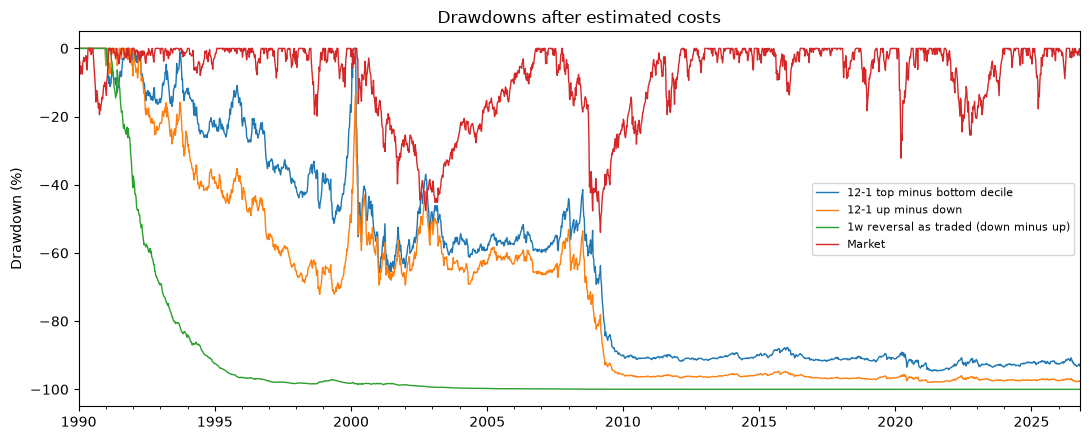

Daniel–Moskowitz regression (gross; const and bear in % per year, betas as betas)


,strategy,weeks,bear_weeks,const,t_const,bear,t_bear,mkt,t_mkt,bear_x_mkt,t_bear_x_mkt,bear_x_up_x_mkt,t_bear_x_up_x_mkt
0,12-1 top minus bottom decile,1816,274,0.1040,2.3620,0.0190,0.1070,0.1550,1.4610,-0.6050,-3.5300,-0.3180,-1.2760
1,12-1 up minus down,1816,274,0.1320,2.7790,0.0630,0.2960,0.1080,1.2260,-0.5190,-2.8020,-0.4690,-1.4520
2,12-1 up-outliers,1816,274,0.0740,2.1280,0.0690,0.5320,1.4300,27.8640,-0.2930,-3.0250,-0.0780,-0.4260
3,Steady climbers,1816,274,0.0800,2.3520,0.0000,0.0020,1.4180,28.1160,-0.2900,-3.2790,-0.0410,-0.2110
4,1w up minus down,1816,274,-0.2750,-7.5210,0.5040,2.1870,-0.2390,-4.3220,0.1300,0.7420,-1.1530,-2.4630
5,1w down-outliers (buy last week's crashes),1816,274,0.1470,4.3340,-0.2990,-1.7220,1.4120,31.3600,-0.0910,-0.7180,0.8680,2.9220
6,1m down-outliers,1816,274,0.1130,3.3530,-0.2860,-1.4960,1.4510,28.5430,-0.0490,-0.3960,0.7960,2.8030
7,Sudden spikes,1816,274,-0.0820,-2.5840,0.2910,2.4320,0.9920,28.6970,0.0730,0.6370,-0.3960,-2.2870


Predictive: next week's gross return on last week's bear flag, market volatility (standardized) and their product (% per year)


,strategy,bear,vol,bear_x_vol,t_bear,t_vol,t_bear_x_vol
0,12-1 top minus bottom decile,-0.0320,-0.0880,-0.1380,-0.2230,-1.1510,-1.0540
1,12-1 up minus down,-0.0670,-0.0690,-0.1790,-0.4310,-0.8140,-1.1740
2,12-1 up-outliers,0.0450,0.1210,-0.1700,0.3140,1.8120,-1.2140
3,Steady climbers,0.0230,0.1090,-0.1760,0.1630,1.7020,-1.2550
4,1w up minus down,0.1410,-0.0850,-0.3460,0.9620,-1.4190,-1.2890
5,1w down-outliers (buy last week's crashes),0.0060,0.1510,0.1590,0.0290,1.8590,0.5730
6,1m down-outliers,0.0210,0.1420,0.1220,0.1100,1.4710,0.4550
7,Sudden spikes,0.1480,0.0280,-0.1370,1.0480,0.4090,-1.3780


Seasonality (gross; long-only strategies vs the market)


,strategy,season,other_weeks_ann,in_season_ann,difference_ann,t_diff,p_diff,q_diff
0,1w down-outliers (buy last week's crashes),January,0.2403,0.3160,0.0757,0.5274,0.5979,0.8221
1,1w down-outliers (buy last week's crashes),Nov–Apr,0.1977,0.2970,0.0992,1.5400,0.1236,0.6504
2,1w up minus down,January,-0.3580,-0.3802,-0.0222,-0.1606,0.8724,0.9597
3,1w up minus down,Nov–Apr,-0.3193,-0.4014,-0.0822,-1.0645,0.2871,0.6504
4,1m down-outliers,January,0.1865,0.4649,0.2784,1.7531,0.0796,0.3814
5,1m down-outliers,Nov–Apr,0.1492,0.2729,0.1237,1.8394,0.0659,0.6504
6,1m up minus down,January,-0.2404,-0.5522,-0.3118,-1.9861,0.0470,0.3814
7,1m up minus down,Nov–Apr,-0.2541,-0.2804,-0.0263,-0.3437,0.7311,0.7479
8,12-1 up-outliers,January,0.1180,0.1884,0.0704,0.6116,0.5408,0.8221
9,12-1 up-outliers,Nov–Apr,0.0942,0.1547,0.0605,0.9592,0.3375,0.6504


In [30]:
CRASH_STRATS = ["12-1 top minus bottom decile", "12-1 up minus down", "12-1 up-outliers", "Steady climbers",
                "1w up minus down", "1w down-outliers (buy last week's crashes)", "1m down-outliers", "Sudden spikes"]
EPISODES = {"2009 rebound (Mar 6 – May 29)": ("2009-03-06", "2009-05-29"),
            "2020 crash (Feb 21 – Mar 20)": ("2020-02-21", "2020-03-20"),
            "2020 rebound (Mar 20 – Jun 5)": ("2020-03-20", "2020-06-05"),
            "Nov 2020 vaccine week": ("2020-11-06", "2020-11-13")}

def window_ret(x, a, b):
    s = x.loc[(x.index > pd.Timestamp(a)) & (x.index <= pd.Timestamp(b))]
    return (1 + s.fillna(0)).prod() - 1 if len(s) else np.nan

def drawdown(x):
    w = (1 + x.fillna(0)).cumprod()
    return w / w.cummax() - 1, w

crash_rows, DD = [], {}
for name in CRASH_STRATS + ["Market"]:
    if name == "Market":
        y, kind = mkt, "market"
    else:
        p, kind = strat(name, 1)
        y = p["net"]
    dd, w = drawdown(y)
    trough = dd.idxmin()
    r13 = np.log1p(y.fillna(0).clip(lower=-0.99)).rolling(13).sum()
    row = {"strategy": name, "kind": kind, "max_drawdown": dd.min(), "peak": w.loc[:trough].idxmax().date(),
           "trough": trough.date(), "worst_13w": np.expm1(r13.min()), "worst_13w_ending": r13.idxmin().date()}
    if kind == "lo":
        row["max_drawdown_vs_market"] = drawdown(y - mkt)[0].min()
    for ename, (a, b) in EPISODES.items():
        row[ename] = window_ret(y, a, b)
    crash_rows.append(row)
    DD[name] = dd
crash = pd.DataFrame(crash_rows)
print("Drawdowns and crash episodes, after estimated costs (1-week hold)")
display(crash.round(3))

REV_NAME = "1w reversal as traded (down minus up)"
_p, _ = strat("1w up minus down", 1)
DD[REV_NAME] = drawdown(-_p["gross"] - _p["tcost"])[0]          # the profitable direction, still paying costs
fig, ax = plt.subplots(figsize=(11, 4.5))
for name in ["12-1 top minus bottom decile", "12-1 up minus down", REV_NAME, "Market"]:
    (DD[name] * 100).plot(ax=ax, label=name, lw=1)
ax.set_ylabel("Drawdown (%)"); ax.set_title("Drawdowns after estimated costs"); ax.legend(fontsize=8)
save(fig, "18_drawdowns.png")

r104 = lm.rolling(104).sum()
IB = (r104 < 0).astype(float).where(r104.notna()).shift(1)
IU = (mx > 0).astype(float)
vol_z = ((STATE["mkt_vol"] - STATE["mkt_vol"].mean()) / STATE["mkt_vol"].std()).shift(1)
dm_rows, dmp_rows = [], []
for name in CRASH_STRATS:
    p, kind = strat(name, 1)
    y = p["gross"] if kind == "ls" else p["gross"] - rf
    X = pd.DataFrame({"bear": IB, "mkt": mx, "bear_x_mkt": IB * mx, "bear_x_up_x_mkt": IB * IU * mx})
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    r = _hac(d["y"], sm.add_constant(d[list(X.columns)]), 1)
    row = {"strategy": name, "weeks": len(d), "bear_weeks": int(d["bear"].sum())}
    for c in ["const"] + list(X.columns):
        row[c] = r.params[c] * (52 if c in ("const", "bear") else 1)
        row[f"t_{c}"] = r.tvalues[c]
    dm_rows.append(row)
    P = pd.DataFrame({"bear": IB, "vol": vol_z, "bear_x_vol": IB * vol_z})
    d = pd.concat([y.rename("y"), P], axis=1).dropna()
    r = _hac(d["y"], sm.add_constant(d[list(P.columns)]), 1)
    dmp_rows.append({"strategy": name, **{c: r.params[c] * 52 for c in P.columns}, **{f"t_{c}": r.tvalues[c] for c in P.columns}})
print("Daniel–Moskowitz regression (gross; const and bear in % per year, betas as betas)")
display(pd.DataFrame(dm_rows).round(3))
print("Predictive: next week's gross return on last week's bear flag, market volatility (standardized) and their product (% per year)")
display(pd.DataFrame(dmp_rows).round(3))

jan = pd.Series((weeks.month == 1).astype(float), index=weeks)
winter = pd.Series(np.isin(weeks.month, [11, 12, 1, 2, 3, 4]).astype(float), index=weeks)
cal_rows = []
for name in STRATS:
    y = target(name, "gross")
    for season, dmy in [("January", jan), ("Nov–Apr", winter)]:
        d = pd.concat([y.rename("y"), dmy.rename("dum")], axis=1).dropna()
        r = _hac(d["y"], sm.add_constant(d["dum"]), 1)
        cal_rows.append({"strategy": name, "season": season, "other_weeks_ann": r.params["const"] * 52,
                         "in_season_ann": (r.params["const"] + r.params["dum"]) * 52,
                         "difference_ann": r.params["dum"] * 52, "t_diff": r.tvalues["dum"], "p_diff": r.pvalues["dum"]})
cal = add_bh(pd.DataFrame(cal_rows), ["p_diff"], by="season")
print("Seasonality (gross; long-only strategies vs the market)")
display(cal.round(4))

## 19. How long to hold: appraisal ratio by holding period

For the headline strategies, the annualized **appraisal ratio** (CAPM alpha ÷ residual volatility) for each holding period, after estimated costs and under the flat cost grid. v1 used portfolio-minus-market, which rewards a long-only portfolio for simply having a beta above 1 in a rising market; the appraisal ratio removes the market first. The peak of each curve is "when to sell".

,strategy,hold,period,turnover,appraisal_est_cost,appraisal_gross,appraisal_0bps,appraisal_10bps,appraisal_25bps,appraisal_50bps
0,1w down-outliers (buy last week's crashes),1,full,1.8120,-0.9080,1.1280,1.1280,0.5860,-0.2260,-1.5820
2,1w down-outliers (buy last week's crashes),1,recent,1.7900,-1.2170,-0.1860,-0.1860,-0.6520,-1.3500,-2.5150
3,1w down-outliers (buy last week's crashes),2,full,0.9050,-0.4490,0.7400,0.7400,0.4210,-0.0570,-0.8550
5,1w down-outliers (buy last week's crashes),2,recent,0.8990,-0.9990,-0.4050,-0.4050,-0.6740,-1.0770,-1.7490
6,1w down-outliers (buy last week's crashes),4,full,0.4550,-0.1320,0.5130,0.5130,0.3400,0.0810,-0.3520
8,1w down-outliers (buy last week's crashes),4,recent,0.4540,-0.6130,-0.2950,-0.2950,-0.4380,-0.6540,-1.0130
9,1w down-outliers (buy last week's crashes),8,full,0.2290,-0.0650,0.2820,0.2820,0.1900,0.0520,-0.1780
11,1w down-outliers (buy last week's crashes),8,recent,0.2270,-0.5980,-0.4260,-0.4260,-0.5030,-0.6180,-0.8090
12,1w down-outliers (buy last week's crashes),13,full,0.1420,-0.0020,0.2210,0.2210,0.1630,0.0750,-0.0710
14,1w down-outliers (buy last week's crashes),13,recent,0.1390,-0.5510,-0.4410,-0.4410,-0.4890,-0.5610,-0.6810


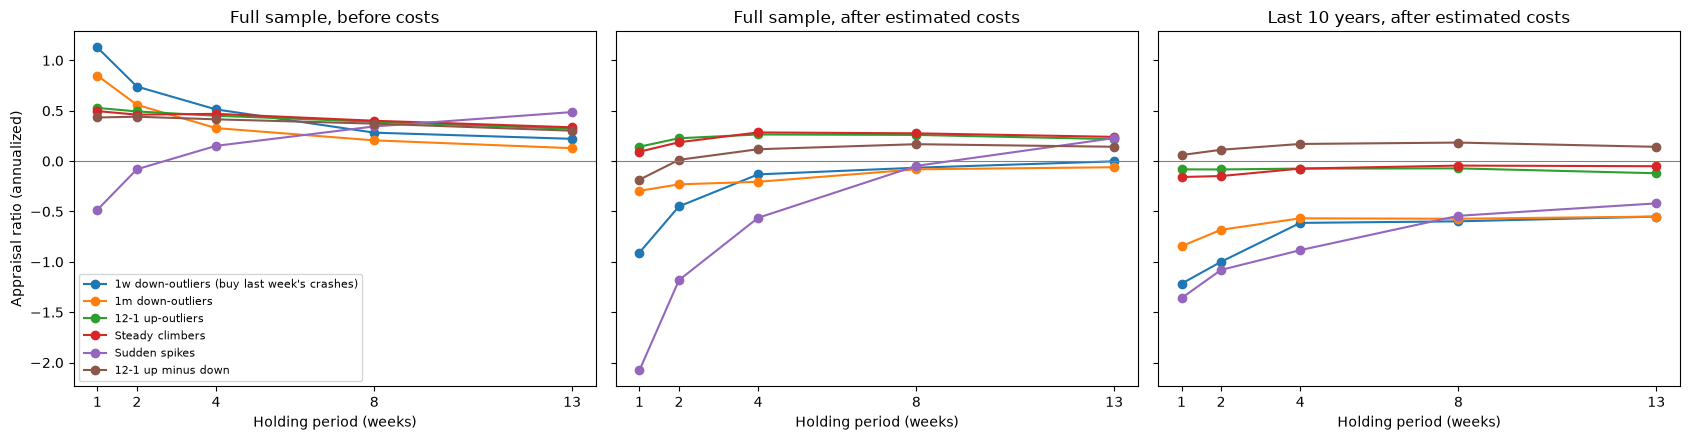

In [31]:
HP_STRATS = ["1w down-outliers (buy last week's crashes)", "1m down-outliers", "12-1 up-outliers",
             "Steady climbers", "Sudden spikes", "12-1 up minus down"]
hp_rows = []
for name in HP_STRATS:
    for K in HOLDS:
        p, kind = strat(name, K)
        for per, sl in PERIODS.items():
            q = p.loc[sl].dropna(subset=["gross"])
            if len(q) < 104:
                continue
            ex = 0.0 if kind == "ls" else rf.reindex(q.index)
            row = {"strategy": name, "hold": K, "period": per, "turnover": q["turnover"].mean(),
                   "appraisal_est_cost": capm(q["net"] - ex, K)["appraisal"],
                   "appraisal_gross": capm(q["gross"] - ex, K)["appraisal"]}
            for bps in FLAT_COST_GRID_BPS:
                row[f"appraisal_{bps}bps"] = capm(q["gross"] - ex - q["turnover"] * bps / 1e4, K)["appraisal"]
            hp_rows.append(row)
hp = pd.DataFrame(hp_rows)
display(hp.query("period in ['full', 'recent']").round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (per, col, title) in zip(axes, [("full", "appraisal_gross", "Full sample, before costs"),
                                        ("full", "appraisal_est_cost", "Full sample, after estimated costs"),
                                        ("recent", "appraisal_est_cost", f"Last {RECENT_YEARS} years, after estimated costs")]):
    for name in HP_STRATS:
        s = hp.query("strategy == @name and period == @per").set_index("hold")[col]
        ax.plot(s.index, s.values, marker="o", label=name)
    ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(HOLDS); ax.set_xlabel("Holding period (weeks)"); ax.set_title(title)
axes[0].set_ylabel("Appraisal ratio (annualized)"); axes[0].legend(fontsize=8)
save(fig, "19_holding_period.png")

## 20. How much do costs matter? Cost-model robustness

Each headline strategy under all four cost estimates and the flat grid, with the break-even cost. A result that only survives one cost model is not a result. "cost/side" is the average one-way cost actually charged per dollar traded.

In [32]:
cost_rows = []
for name in STRATS:
    for K in [1, 4]:
        for per in ["full", "recent"]:
            row = {"strategy": name, "hold": K, "period": per}
            for variant in COSTS:
                p, kind = strat(name, K, variant)
                q = p.loc[PERIODS[per]].dropna(subset=["gross"])
                g = q["gross"] - (0.0 if kind == "ls" else mkt.reindex(q.index))
                to = q["turnover"].mean()
                row["gross_ann"] = g.mean() * 52
                row[f"net_{variant}"] = (g - q["tcost"]).mean() * 52
                row[f"cost/side_{variant}_bps"] = q["tcost"].mean() / to * 1e4
            for bps in FLAT_COST_GRID_BPS:
                row[f"net_flat_{bps}bps"] = (g - q["turnover"] * bps / 1e4).mean() * 52
            row["turnover"] = to
            row["breakeven_bps"] = g.mean() / to * 1e4
            cost_rows.append(row)
cost_tab = pd.DataFrame(cost_rows)
print("Annualized returns (long-only = vs market) under each cost model; break-even = one-way bps that wipes out the gross edge")
display(cost_tab.round(4))

Annualized returns (long-only = vs market) under each cost model; break-even = one-way bps that wipes out the gross edge


,strategy,hold,period,gross_ann,net_ar_pooled,cost/side_ar_pooled_bps,net_ar,cost/side_ar_bps,net_cs_adj,cost/side_cs_adj_bps,net_cs_raw,cost/side_cs_raw_bps,net_flat_0bps,net_flat_10bps,net_flat_25bps,net_flat_50bps,turnover,breakeven_bps
0,1w down-outliers (buy last week's crashes),1,full,0.2468,-0.1054,37.3784,-0.1309,40.0924,-0.2926,57.2500,-0.2547,53.2249,0.2468,0.1526,0.0113,-0.2243,1.8118,26.1941
1,1w down-outliers (buy last week's crashes),1,recent,0.0449,-0.1614,22.1645,-0.2735,34.2123,-0.5076,59.3670,-0.4651,54.7976,0.0449,-0.0482,-0.1878,-0.4205,1.7899,4.8260
2,1w down-outliers (buy last week's crashes),4,full,0.1145,0.0263,37.2891,0.0195,40.1426,-0.0212,57.3629,-0.0135,54.0807,0.1145,0.0909,0.0554,-0.0038,0.4552,48.3888
3,1w down-outliers (buy last week's crashes),4,recent,0.0188,-0.0337,22.2543,-0.0617,34.1067,-0.1217,59.5590,-0.1122,55.5259,0.0188,-0.0048,-0.0402,-0.0991,0.4536,7.9667
4,1w up minus down,1,full,-0.3599,-1.0666,37.4402,-1.1077,39.6167,-1.4356,56.9883,-1.3578,52.8701,-0.3599,-0.5486,-0.8318,-1.3037,3.6300,-19.0650
5,1w up minus down,1,recent,-0.1857,-0.6025,22.3075,-0.8178,33.8320,-1.2970,59.4829,-1.2136,55.0156,-0.1857,-0.3725,-0.6528,-1.1199,3.5931,-9.9374
6,1w up minus down,4,full,-0.1232,-0.3000,37.3104,-0.3110,39.6153,-0.3936,57.0472,-0.3766,53.4713,-0.1232,-0.1706,-0.2417,-0.3602,0.9112,-26.0100
7,1w up minus down,4,recent,-0.0780,-0.1834,22.3281,-0.2373,33.7567,-0.3595,59.6377,-0.3406,55.6261,-0.0780,-0.1252,-0.1960,-0.3140,0.9076,-16.5354
8,1m down-outliers,1,full,0.2103,0.0006,37.7581,-0.0132,40.2279,-0.1097,57.6060,-0.0929,54.5787,0.2103,0.1548,0.0714,-0.0674,1.0683,37.8603
9,1m down-outliers,1,recent,0.0294,-0.0928,22.8374,-0.1586,35.1222,-0.2960,60.8037,-0.2728,56.4566,0.0294,-0.0241,-0.1044,-0.2382,1.0292,5.4901


## 21. Verdicts: the headline list first, then everything

Each test gets a verdict:
- **tradeable after costs:** the better direction (as built, or reversed) still makes money after estimated costs, BH q < 0.05,
- **real, but not significant after costs** (new in v4): significant before costs (q < 0.05); still positive after costs, but not significantly,
- **real, but eaten by costs:** significant before costs; zero or negative after costs,
- **nothing there:** not significant before costs.

"Reversed" means the profitable trade is the opposite of the test as built (e.g. short the up-outliers against the market), which needs shorting; borrow fees are not included (`BORROW_BPS_PER_YEAR`). Sharpe, alpha and drawdown columns describe the strategy as built; `ir_best` is the information ratio of the better direction after costs.

**21a. Headline list (developed during earlier exploration, NOT preregistered).** the 11 strategies in `STRATS` × 1 and 4-week holds × equal and liquidity weighting = 44 tests per period, with Benjamini–Hochberg across just these 44 within each period. This is the verdict to quote on camera.

**21b. Everything (exploratory).** All ~700+ strategy tests in one table, BH within each period across all of them. With this many tests, only very strong results survive, so use it to see the landscape, not to pick winners.

**21c. Big-stock momentum, post hoc (new in v4).** Capped liquidity weighting and the most liquid third, on their own small list (below the exploratory table).

**Important:** "best" direction is chosen using the *same data* being evaluated in these legacy tables. It is a descriptive upper bound, not a tradeable out-of-sample claim. See the fixed-discovery-direction tests in section 30.


In [33]:
def add_verdict(df):
    df = df.copy()
    real = df.q_gross < 0.05
    df["verdict"] = np.select([(df.q_best < 0.05) & (df.best_net_ann > 0), real & (df.best_net_ann > 0), real],
                              ["tradeable after costs", "real, but not significant after costs", "real, but eaten by costs"],
                              "nothing there")
    return df

# ---- 21a. headline list (developed during earlier exploration, NOT preregistered)
head_rows = []
for name in STRATS:
    for K in [1, 4]:
        for variant, vlabel in [("base", "equal-weighted"), ("lw", "liquidity-weighted")]:
            p, kind = strat(name, K, variant)
            head_rows += summarize(p, {"strategy": name, "hold": K, "weighting": vlabel}, K, kind=kind)
headline = add_verdict(add_bh(pd.DataFrame(head_rows), ["p_gross", "p_net", "p_best", "p_alpha7"]))
HCOLS = ["strategy", "hold", "weighting", "direction", "names", "gross_ann", "t_gross", "q_gross", "net_ann",
         "best_net_ann", "q_best", "sharpe", "appraisal", "alpha7_ann", "t_alpha7", "maxdd", "cost_bps_per_side",
         "breakeven_bps", "verdict"]
for per in ["full", "recent"]:
    print(f"\nHeadline list, period = {per} (BH across these {int((headline.period == per).sum())} tests)")
    display(headline[headline.period == per][HCOLS].round(4))
print("Verdict grid (headline list)")
display(headline[headline.period.isin(["full", "recent"])]
        .pivot_table(index=["strategy", "hold"], columns=["weighting", "period"], values="verdict", aggfunc="first")
        .reindex(list(STRATS), level=0))


Headline list, period = full (BH across these 44 tests)


,strategy,hold,weighting,direction,names,gross_ann,t_gross,q_gross,net_ann,best_net_ann,q_best,sharpe,appraisal,alpha7_ann,t_alpha7,maxdd,cost_bps_per_side,breakeven_bps,verdict
0,1w down-outliers (buy last week's crashes),1,equal-weighted,as built,79.2918,0.2468,6.8531,0.0000,-0.1054,-0.1054,0.0060,-0.0248,-0.9081,-0.1922,-8.5389,-0.9041,37.3784,26.1941,"real, but eaten by costs"
3,1w down-outliers (buy last week's crashes),1,liquidity-weighted,as built,79.2918,0.2145,4.6702,0.0000,0.0924,0.0924,0.0896,0.5031,0.1141,-0.0097,-0.2511,-0.6842,12.6315,22.1917,"real, but not significant after costs"
6,1w down-outliers (buy last week's crashes),4,equal-weighted,as built,265.5541,0.1145,4.3473,0.0001,0.0263,0.0263,0.4488,0.4395,-0.1317,-0.0443,-3.2951,-0.6915,37.2891,48.3888,"real, but not significant after costs"
9,1w down-outliers (buy last week's crashes),4,liquidity-weighted,as built,265.5541,0.0816,2.5878,0.0147,0.0511,0.0511,0.1950,0.4518,-0.0529,-0.0228,-0.9326,-0.7992,12.6631,33.8546,"real, but not significant after costs"
12,1w up minus down,1,equal-weighted,reversed,161.9609,-0.3599,-8.4628,0.0000,-1.0666,-0.3468,0.0000,-4.5310,-4.5521,-0.9122,-18.7047,-1.0000,37.4402,19.0650,"real, but eaten by costs"
15,1w up minus down,1,liquidity-weighted,reversed,161.9609,-0.2932,-4.7570,0.0000,-0.5384,0.0480,0.5919,-1.5170,-1.4405,-0.3620,-5.7242,-1.0000,12.6186,15.0903,"real, but not significant after costs"
18,1w up minus down,4,equal-weighted,reversed,545.0733,-0.1232,-6.7076,0.0000,-0.3000,-0.0535,0.0108,-2.5296,-2.4892,-0.1953,-13.7914,-1.0000,37.3104,26.0100,"real, but eaten by costs"
21,1w up minus down,4,liquidity-weighted,reversed,545.0733,-0.0600,-2.1527,0.0383,-0.1211,-0.0011,0.9861,-0.6640,-0.5349,0.0034,0.1305,-0.9926,12.6220,12.3868,"real, but eaten by costs"
24,1m down-outliers,1,equal-weighted,as built,78.5241,0.2103,6.0055,0.0000,0.0006,0.0006,0.9861,0.3062,-0.2950,-0.1207,-5.4101,-0.7406,37.7581,37.8603,"real, but not significant after costs"
27,1m down-outliers,1,liquidity-weighted,as built,78.5241,0.0779,1.6860,0.1036,0.0021,0.0021,0.9861,0.2450,-0.2511,-0.1308,-3.4128,-0.9067,12.4824,12.8314,nothing there



Headline list, period = recent (BH across these 44 tests)


,strategy,hold,weighting,direction,names,gross_ann,t_gross,q_gross,net_ann,best_net_ann,q_best,sharpe,appraisal,alpha7_ann,t_alpha7,maxdd,cost_bps_per_side,breakeven_bps,verdict
2,1w down-outliers (buy last week's crashes),1,equal-weighted,as built,131.8582,0.0449,0.5876,0.7656,-0.1614,-0.1614,0.1606,-0.0800,-1.2170,-0.1747,-4.2572,-0.6922,22.1645,4.8260,nothing there
5,1w down-outliers (buy last week's crashes),1,liquidity-weighted,as built,131.8582,0.1263,1.4323,0.3521,0.0249,0.0249,0.8830,0.3862,-0.3058,-0.0303,-0.4892,-0.6842,10.5691,13.1644,nothing there
8,1w down-outliers (buy last week's crashes),4,equal-weighted,as built,437.0038,0.0188,0.3458,0.8675,-0.0337,-0.0337,0.8637,0.3211,-0.6134,-0.0371,-1.6517,-0.5001,22.2543,7.9667,nothing there
11,1w down-outliers (buy last week's crashes),4,liquidity-weighted,as built,437.0038,0.0902,1.4729,0.3521,0.0646,0.0646,0.6308,0.5779,-0.1202,0.0196,0.4769,-0.5317,10.6065,37.3086,nothing there
14,1w up minus down,1,equal-weighted,reversed,260.6552,-0.1857,-1.9123,0.2730,-0.6025,-0.2311,0.1606,-2.3446,-2.2194,-0.5436,-7.4014,-0.9986,22.3075,9.9374,nothing there
17,1w up minus down,1,liquidity-weighted,reversed,260.6552,-0.0592,-0.4472,0.8151,-0.2573,-0.1390,0.6308,-0.6543,-0.5143,-0.1955,-1.7747,-0.9729,10.3378,3.0878,nothing there
20,1w up minus down,4,equal-weighted,reversed,867.7375,-0.0780,-2.4035,0.1429,-0.1834,-0.0273,0.7874,-1.4394,-1.2505,-0.1435,-6.5421,-0.8553,22.3281,16.5354,nothing there
23,1w up minus down,4,liquidity-weighted,reversed,867.7375,-0.0145,-0.2513,0.8896,-0.0642,-0.0352,0.8637,-0.3179,-0.1501,-0.0253,-0.5855,-0.5760,10.2996,3.0126,nothing there
26,1m down-outliers,1,equal-weighted,as built,130.3582,0.0294,0.4304,0.8151,-0.0928,-0.0928,0.5202,0.1140,-0.8448,-0.1160,-3.2380,-0.6095,22.8374,5.4901,nothing there
29,1m down-outliers,1,liquidity-weighted,as built,130.3582,0.0686,0.7577,0.6807,0.0064,0.0064,0.9645,0.3223,-0.3775,-0.0626,-0.8973,-0.6430,10.5426,11.6255,nothing there


Verdict grid (headline list)


weighting                                                               equal-weighted                                    liquidity-weighted               
period                                                                            full         recent                                   full         recent
strategy                                   hold                                                                                                            
1w down-outliers (buy last week's crashes) 1                  real, but eaten by costs  nothing there  real, but not significant after costs  nothing there
                                           4     real, but not significant after costs  nothing there  real, but not significant after costs  nothing there
1w up minus down                           1                  real, but eaten by costs  nothing there  real, but not significant after costs  nothing there
                                           4                  real, but eaten by costs  nothing there               real, but eaten by costs  nothing there
1m down-outliers                           1     real, but not significant after costs  nothing there                          nothing there  nothing there
                                           4     real, but not significant after costs  nothing there                          nothing there  nothing there
1m up minus down                           1                  real, but eaten by costs  nothing there               real, but eaten by costs  nothing there
                                           4                  real, but eaten by costs  nothing there                          nothing there  nothing there
12-1 up-outliers                           1     real, but not significant after costs  nothing there                  tradeable after costs  nothing there
                                           4                     tradeable after costs  nothing there                  tradeable after costs  nothing there
12-1 up minus down                         1                  real, but eaten by costs  nothing there  real, but not significant after costs  nothing there
                                           4     real, but not significant after costs  nothing there                  tradeable after costs  nothing there
Steady climbers                            1     real, but not significant after costs  nothing there                  tradeable after costs  nothing there
                                           4                     tradeable after costs  nothing there                  tradeable after costs  nothing there
Sudden spikes                              1                  real, but eaten by costs  nothing there  real, but not significant after costs  nothing there
                                           4                             nothing there  nothing there                          nothing there  nothing there
1w top minus bottom decile                 1                  real, but eaten by costs  nothing there  real, but not significant after costs  nothing there
                                           4                  real, but eaten by costs  nothing there  real, but not significant after costs  nothing there
1m top minus bottom decile                 1                  real, but eaten by costs  nothing there               real, but eaten by costs  nothing there
                                           4                  real, but eaten by costs  nothing there                          nothing there  nothing there
12-1 top minus bottom decile               1                             nothing there  nothing there  real, but not significant after costs  nothing there
                                           4                             nothing there  nothing there  real, but not significant after costs  nothing there

In [34]:
# ---- 21b. everything (exploratory)
parts_ = [base, grid, cats, frog, news_res.drop(columns="cell"),
          liq_res[liq_res.variant != "all, equal-weighted"].drop(columns="cell"),
          skip_res[skip_res.variant != "same close"],
          ind_res.drop(columns="cell")]
results = pd.concat(parts_, ignore_index=True)
KEY = ["test", "lookback", "component", "category", "leg", "hold", "variant"]
for c in KEY:
    if c not in results:
        results[c] = ""
    elif c != "hold":
        results[c] = results[c].fillna("")
results = add_verdict(add_bh(results, ["p_gross", "p_net", "p_best", "p_alpha7"]))
print("Verdicts by period (all tests)")
display(pd.crosstab(results.period, results.verdict))
print("Verdicts by test family (full sample)")
display(pd.crosstab(results.query("period == 'full'").test, results.query("period == 'full'").verdict))

full = results[results.period == "full"]
recent = results[results.period == "recent"][KEY + ["best_net_ann", "t_best", "q_best", "gross_ann", "t_gross", "verdict"]]
head = full.merge(recent, on=KEY, how="left", suffixes=("", "_last10y"))
COLS = KEY + ["direction", "names", "gross_ann", "t_gross", "net_ann", "best_net_ann", "t_best", "q_best", "ir_best",
              "sharpe", "appraisal", "alpha7_ann", "t_alpha7", "maxdd", "cost_bps_per_side", "breakeven_bps", "verdict",
              "best_net_ann_last10y", "t_best_last10y", "verdict_last10y", "p_recent_vs_disc_net"]
trade = head[head.verdict == "tradeable after costs"].sort_values("t_best", ascending=False)
print(f"\nTradeable after costs (full sample): {len(trade)} tests; top 25 by t (best direction, net)")
display(trade[COLS].head(25))
eaten = head[head.verdict.str.startswith("real")]
eaten = eaten.loc[eaten["t_gross"].abs().sort_values(ascending=False).index]
print(f"\nReal before costs but not tradeable after costs (full sample): {len(eaten)} tests; top 25 by |t gross|")
display(eaten[COLS].head(25))
both = head[(head.verdict == "tradeable after costs") & (head.verdict_last10y == "tradeable after costs")]
print(f"\nTradeable after costs in the full sample AND the last {RECENT_YEARS} years: {len(both)} tests")
display(both.sort_values("t_best_last10y", ascending=False)[COLS].head(25))

SAVE = {"headline.csv": headline, "results_all.csv": results, "results_full_with_last10y.csv": head,
        "hit_rates.csv": hits_bh, "dose_response.csv": dose, "fama_macbeth.csv": fm, "market_state.csv": state_tab,
        "holding_period.csv": hp, "cost_robustness.csv": cost_tab, "cost_diagnostics.csv": cost_diag,
        "survivorship_check.csv": surv, "replication_vs_ken_french_monthly.csv": rep,
        "moskowitz_grinblatt_monthly.csv": mg, "crashes.csv": crash, "seasonality.csv": cal, "news.csv": news_res,
        "skip_a_day.csv": skip_res, "day_of_week_split.csv": day_tab, "concentration.csv": conc_tab}
for fname, df in SAVE.items():
    df.to_csv(OUT_DIR / fname, index=False)
for fname, df in {"cost_by_year.csv": cost_year, "cost_by_dollar_volume_decile.csv": cost_dec,
                  "calendar_year_returns.csv": yr_tab}.items():
    df.to_csv(OUT_DIR / fname)
print(f"Tables saved to {OUT_DIR}/")

Verdicts by period (all tests)


verdict,nothing there,"real, but eaten by costs","real, but not significant after costs",tradeable after costs
period,,,,
discovery,445,142,148,41
full,476,143,122,35
recent,776,0,0,0


Verdicts by test family (full sample)


verdict,nothing there,"real, but eaten by costs","real, but not significant after costs",tradeable after costs
test,,,,
category,8,3,5,2
decile,18,6,0,0
frog in the pan,6,0,0,0
industry,133,0,5,6
liquidity,39,40,39,14
news,26,19,3,0
outlier,236,53,61,10
skip a day,10,22,9,3



Tradeable after costs (full sample): 35 tests; top 25 by t (best direction, net)


...


Real before costs but not tradeable after costs (full sample): 265 tests; top 25 by |t gross|


,test,lookback,component,category,leg,hold,variant,direction,names,gross_ann,t_gross,net_ann,best_net_ann,t_best,q_best,ir_best,sharpe,appraisal,alpha7_ann,t_alpha7,maxdd,cost_bps_per_side,breakeven_bps,verdict,best_net_ann_last10y,t_best_last10y,verdict_last10y,p_recent_vs_disc_net
51,outlier,1w,specific,,up minus down,1,base,reversed,166.0616,-0.3697,-10.0000,-1.0810,-0.3417,-9.7506,0.0000,-1.9954,-5.5362,-5.5769,-0.9593,-20.5357,-1.0000,37.9896,19.7412,"real, but eaten by costs",-0.2835,-4.1102,nothing there,0.0000
592,skip a day,,,1w up minus down,,1,skip a day,reversed,161.9609,-0.3148,-8.9402,-1.0215,-0.3920,-10.1178,0.0000,-2.0666,-5.0179,-5.0157,-0.9076,-20.4369,-1.0000,37.4402,16.6748,"real, but eaten by costs",-0.2439,-2.8084,nothing there,0.0000
620,skip a day,,,1w top minus bottom decile,,1,skip a day,reversed,279.1279,-0.2484,-8.6121,-0.8703,-0.3736,-11.6886,0.0000,-2.2342,-4.9040,-4.9039,-0.7592,-21.2615,-1.0000,34.8940,13.9339,"real, but eaten by costs",-0.2650,-3.6578,nothing there,0.0000
557,liquidity,,,1w top minus bottom decile,,1,"all, excl. recent reverse splits",reversed,275.7489,-0.2854,-8.5553,-0.9048,-0.3339,-10.0719,0.0000,-1.7837,-4.4988,-4.5382,-0.7583,-19.6061,-1.0000,34.7031,15.9927,"real, but eaten by costs",-0.2411,-3.0377,nothing there,0.0000
473,liquidity,,,1w up minus down,,1,"all, excl. recent reverse splits",reversed,159.3731,-0.3626,-8.5527,-1.0651,-0.3399,-8.1668,0.0000,-1.5619,-4.5118,-4.5339,-0.9096,-18.7794,-1.0000,37.1827,19.1938,"real, but eaten by costs",-0.2117,-2.1613,nothing there,0.0000
0,decile,1w,total,,top minus bottom,1,base,reversed,279.1279,-0.2839,-8.5061,-0.9059,-0.3380,-10.2121,0.0000,-1.8105,-4.5133,-4.5529,-0.7598,-19.5908,-1.0000,34.8940,15.9296,"real, but eaten by costs",-0.2535,-3.1995,nothing there,0.0000
552,liquidity,,,1w top minus bottom decile,,1,tercile 1 (least liquid),reversed,103.2532,-0.3199,-8.4957,-1.4560,-0.8162,-18.1120,0.0000,-3.8750,-6.1263,-6.1723,-1.3168,-21.7283,-1.0000,63.0018,17.7414,"real, but eaten by costs",-0.4942,-6.0134,nothing there,0.0000
24,outlier,1w,total,,up minus down,1,base,reversed,161.9609,-0.3599,-8.4628,-1.0666,-0.3468,-8.3360,0.0000,-1.6004,-4.5310,-4.5521,-0.9122,-18.7047,-1.0000,37.4402,19.0650,"real, but eaten by costs",-0.2311,-2.3701,nothing there,0.0000
54,outlier,1w,specific,,up minus down,4,base,reversed,559.8822,-0.1357,-8.2863,-0.3137,-0.0423,-2.6986,0.0256,-0.4617,-3.2982,-3.2855,-0.2403,-16.2900,-1.0000,37.8381,28.8547,"real, but eaten by costs",-0.0453,-1.6685,nothing there,0.0000
593,skip a day,,,1w up minus down,,1,drop last day (placebo),reversed,161.9609,-0.3218,-8.2841,-1.0285,-0.3849,-9.8354,0.0000,-1.8862,-4.6392,-4.6453,-0.8897,-18.9007,-1.0000,37.4402,17.0493,"real, but eaten by costs",-0.2351,-2.6185,nothing there,0.0000



Tradeable after costs in the full sample AND the last 10 years: 0 tests


,test,lookback,component,category,leg,hold,variant,direction,names,gross_ann,t_gross,net_ann,best_net_ann,t_best,q_best,ir_best,sharpe,appraisal,alpha7_ann,t_alpha7,maxdd,cost_bps_per_side,breakeven_bps,verdict,best_net_ann_last10y,t_best_last10y,verdict_last10y,p_recent_vs_disc_net


Tables saved to outputs_v7/


### 21c. Big-stock momentum, post hoc (new in v4)

The capped and top-third versions were designed after seeing v3. They get their own small list (4 strategies × 2 holds × 2 weightings = 16 tests per period), with Benjamini–Hochberg across just these and a *post hoc* label.

The question they answer: does momentum in big, liquid stocks survive once no single stock can dominate? The cost estimate is too high for liquid stocks (4b), so compare `breakeven_bps` with a few bps rather than leaning on `net_ann`.

In [35]:
POST_STRATS = ["12-1 up-outliers", "Steady climbers", "12-1 up minus down", "12-1 top minus bottom decile"]
POST_VARIANTS = [("lwcap", f"liquidity-weighted, capped {LW_CAP:.0%}"), ("t3", "most liquid third, equal-weighted")]
post_rows = []
for name in POST_STRATS:
    for K in [1, 4]:
        for variant, vlabel in POST_VARIANTS:
            p, kind = strat(name, K, variant)
            post_rows += summarize(p, {"strategy": name, "hold": K, "weighting": vlabel}, K, kind=kind)
posthoc = add_verdict(add_bh(pd.DataFrame(post_rows), ["p_gross", "p_net", "p_best", "p_alpha7"]))
for per in ["full", "recent"]:
    print(f"\nPost hoc big-stock momentum, period = {per} (BH across these {int((posthoc.period == per).sum())} tests)")
    display(posthoc[posthoc.period == per][HCOLS].round(4))
posthoc.to_csv(OUT_DIR / "posthoc_big_stock_momentum.csv", index=False)


Post hoc big-stock momentum, period = full (BH across these 16 tests)


,strategy,hold,weighting,direction,names,gross_ann,t_gross,q_gross,net_ann,best_net_ann,q_best,sharpe,appraisal,alpha7_ann,t_alpha7,maxdd,cost_bps_per_side,breakeven_bps,verdict
0,12-1 up-outliers,1,"liquidity-weighted, capped 5%",as built,82.0107,0.1434,3.7721,0.0009,0.1084,0.1084,0.0139,0.6410,0.3169,0.0551,1.9062,-0.7086,18.6286,76.3526,tradeable after costs
3,12-1 up-outliers,1,"most liquid third, equal-weighted",as built,26.4216,0.1347,3.1776,0.0034,0.1144,0.1144,0.0191,0.6382,0.3171,0.0549,1.5717,-0.7380,9.7201,64.4536,tradeable after costs
6,12-1 up-outliers,4,"liquidity-weighted, capped 5%",as built,108.7746,0.1364,3.6846,0.0009,0.1208,0.1208,0.0086,0.6820,0.3765,0.0648,2.2851,-0.6920,17.9862,157.8223,tradeable after costs
9,12-1 up-outliers,4,"most liquid third, equal-weighted",as built,34.7944,0.1305,3.3035,0.0025,0.1213,0.1213,0.0098,0.6584,0.3490,0.0544,1.6900,-0.6852,9.5616,135.4300,tradeable after costs
12,Steady climbers,1,"liquidity-weighted, capped 5%",as built,39.5915,0.1467,4.1836,0.0003,0.0887,0.0887,0.0264,0.6039,0.2586,0.0203,0.7414,-0.7297,24.6434,62.3622,tradeable after costs
15,Steady climbers,1,"most liquid third, equal-weighted",as built,15.6348,0.1275,2.9129,0.0072,0.1012,0.1012,0.0425,0.5940,0.2665,0.0215,0.5624,-0.7953,10.0475,48.6310,tradeable after costs
18,Steady climbers,4,"liquidity-weighted, capped 5%",as built,56.6520,0.1400,4.1497,0.0003,0.1159,0.1159,0.0086,0.7023,0.4073,0.0481,1.8539,-0.6859,23.4361,136.1902,tradeable after costs
21,Steady climbers,4,"most liquid third, equal-weighted",as built,21.8906,0.1319,3.3122,0.0025,0.1206,0.1206,0.0098,0.6608,0.3509,0.0390,1.1073,-0.6584,9.9590,116.0826,tradeable after costs
24,12-1 up minus down,1,"liquidity-weighted, capped 5%",as built,159.7441,0.1301,2.3067,0.0337,0.0293,0.0293,0.6088,0.0844,0.1283,-0.0565,-1.6216,-0.9584,24.9026,32.1362,"real, but not significant after costs"
27,12-1 up minus down,1,"most liquid third, equal-weighted",as built,45.4541,0.1101,1.6649,0.0959,0.0651,0.0651,0.4058,0.1672,0.2114,-0.0223,-0.4804,-0.9637,10.0367,24.5678,nothing there



Post hoc big-stock momentum, period = recent (BH across these 16 tests)


,strategy,hold,weighting,direction,names,gross_ann,t_gross,q_gross,net_ann,best_net_ann,q_best,sharpe,appraisal,alpha7_ann,t_alpha7,maxdd,cost_bps_per_side,breakeven_bps,verdict
2,12-1 up-outliers,1,"liquidity-weighted, capped 5%",as built,126.6533,0.1737,2.0602,0.0943,0.1562,0.1562,0.1429,0.7888,0.3574,0.1061,1.9595,-0.4224,10.0279,99.6051,nothing there
5,12-1 up-outliers,1,"most liquid third, equal-weighted",as built,40.0939,0.1868,2.3013,0.0943,0.1703,0.1703,0.1429,0.8405,0.4334,0.1291,2.3131,-0.3758,8.8523,100.2038,nothing there
8,12-1 up-outliers,4,"liquidity-weighted, capped 5%",as built,168.0153,0.1633,1.9848,0.0943,0.1550,0.1550,0.1429,0.7953,0.3640,0.1073,2.0377,-0.4290,10.0230,197.5841,nothing there
11,12-1 up-outliers,4,"most liquid third, equal-weighted",as built,52.4138,0.1729,2.2155,0.0943,0.1648,0.1648,0.1429,0.8403,0.4316,0.1266,2.3798,-0.3685,8.9844,193.3292,nothing there
14,Steady climbers,1,"liquidity-weighted, capped 5%",as built,61.4770,0.1431,1.9170,0.0982,0.1181,0.1181,0.1782,0.7406,0.2753,0.0644,1.3180,-0.4015,11.4197,65.4390,nothing there
17,Steady climbers,1,"most liquid third, equal-weighted",as built,24.2395,0.1706,2.3103,0.0943,0.1502,0.1502,0.1429,0.8339,0.4192,0.0975,1.9028,-0.3684,8.9170,74.3876,nothing there
20,Steady climbers,4,"liquidity-weighted, capped 5%",as built,87.5613,0.1451,2.0189,0.0943,0.1341,0.1341,0.1429,0.7986,0.3563,0.0835,1.7955,-0.3843,11.1863,146.7975,nothing there
23,Steady climbers,4,"most liquid third, equal-weighted",as built,33.6801,0.1716,2.3804,0.0943,0.1622,0.1622,0.1429,0.8838,0.4886,0.1169,2.4110,-0.3608,9.0821,165.0057,nothing there
26,12-1 up minus down,1,"liquidity-weighted, capped 5%",as built,255.5307,0.1925,1.6997,0.1158,0.1487,0.1487,0.2031,0.3630,0.4031,0.0632,1.0681,-0.6468,11.3893,50.0508,nothing there
29,12-1 up minus down,1,"most liquid third, equal-weighted",as built,68.2395,0.2304,2.0876,0.0943,0.1962,0.1962,0.1484,0.4749,0.5274,0.1249,1.8892,-0.5435,8.2622,55.6186,nothing there


## 22. Evergreen check: which findings held in every decade?

A video that stays useful for years should lean on findings that held in every decade, and say plainly which ones faded. Each finding below is a weekly series: 1-week hold, before costs, so the cost model plays no part. Each gets a NW t over the full sample and within each decade. The 1990s start in 1991, when the 52-week beta history first makes stocks eligible.

- **same sign:** in how many decades the estimate has the full sample's sign.
- **last 10y vs full:** the last decade's average as a fraction of the full-sample average (1 = undiminished, 0 = gone, negative = flipped).
- **weakest decade vs full** (new in v4.1): the weakest decade's average as a fraction of the full-sample average.
- **evergreen?** one of six labels:
  - *no reliable effect:* full-sample |t| < 2,
  - *faded:* the last decade is under a third of the full-sample effect, or flipped,
  - *held in every decade:* same sign in every decade, every decade at least a third of the full-sample effect, and the last decade at least half,
  - *held in every decade, but weaker lately:* as above, but the last decade is under half,
  - *same sign every decade, but uneven* (new in v4.1): same sign everywhere, but some decade is under a third of the full-sample effect. In v4 these read "held", e.g. 12-1 momentum at +0.3% (t 0.0) in the 2000s. On camera: "positive in every decade", not "held",
  - *mostly held:* anything else.

These labels summarize the evidence for the script; they are not a test. A decade is about 520 weeks (the 2020s fewer), so the decade estimates are noisy, and "weaker lately" can be noise. The rolling 5-year chart shows the same thing over time.

Each finding by decade: estimate (NW t), 1-week hold, before costs


,full sample,1990s,2000s,2010s,2020s,same sign,last 10y vs full,weakest decade vs full,evergreen?
claim,,,,,,,,,
Outliers are big movers: 1w up-outliers landing in next week's top or bottom 10% (pp above the 20% chance rate),+15.1 pp (+62.0),+14.7 pp (+40.2),+13.2 pp (+32.1),+14.8 pp (+36.2),+18.7 pp (+37.2),4 of 4 decades,1.1600,0.8800,held in every decade
"...but not a direction: 12-1 up-outliers, top-10% share minus bottom-10% share (pp)",+0.4 pp (+1.2),+1.8 pp (+2.4),-0.1 pp (-0.1),+0.3 pp (+0.5),-0.4 pp (-0.5),2 of 4 decades,0.1300,-0.9500,no reliable effect
Last week's extremes snap back: 1w top minus bottom decile (% a year),-28.4% (-8.5),-60.4% (-15.1),-25.7% (-4.1),-13.4% (-3.9),-12.2% (-1.1),4 of 4 decades,0.4500,0.4300,"held in every decade, but weaker lately"
...even entering a day later (skip a day),-24.8% (-8.6),-49.1% (-12.3),-22.8% (-4.4),-14.3% (-4.6),-11.2% (-1.1),4 of 4 decades,0.4700,0.4500,"held in every decade, but weaker lately"
Fama–MacBeth: last week's return (% a year per SD),-6.5% (-10.0),-12.7% (-14.6),-7.6% (-5.7),-3.2% (-4.8),-1.3% (-0.7),4 of 4 decades,0.3100,0.2100,faded
"Quiet moves reverse: 1w up-outliers, heavy minus light abnormal volume",+12.1% (+4.5),+23.3% (+4.3),+18.5% (+3.5),+4.7% (+1.3),-1.1% (-0.2),3 of 4 decades,0.0100,-0.0900,faded
"News sticks: 1w up-outliers, with minus without an earnings 8-K (2005 on)",+16.9% (+3.6),,+29.0% (+2.9),+16.1% (+3.4),+9.6% (+0.9),3 of 3 decades,0.3400,0.5700,"held in every decade, but weaker lately"
Sudden 1-month spikes lag the market next week,-7.9% (-2.8),-20.8% (-3.6),-2.1% (-0.4),-2.3% (-0.7),-7.7% (-1.2),4 of 4 decades,0.9500,0.2600,"same sign every decade, but uneven"
12-month winners keep winning: 12-1 top minus bottom decile,+8.2% (+2.0),+19.2% (+3.4),+0.2% (+0.0),+6.1% (+1.4),+8.4% (+0.8),4 of 4 decades,0.9000,0.0300,no reliable effect


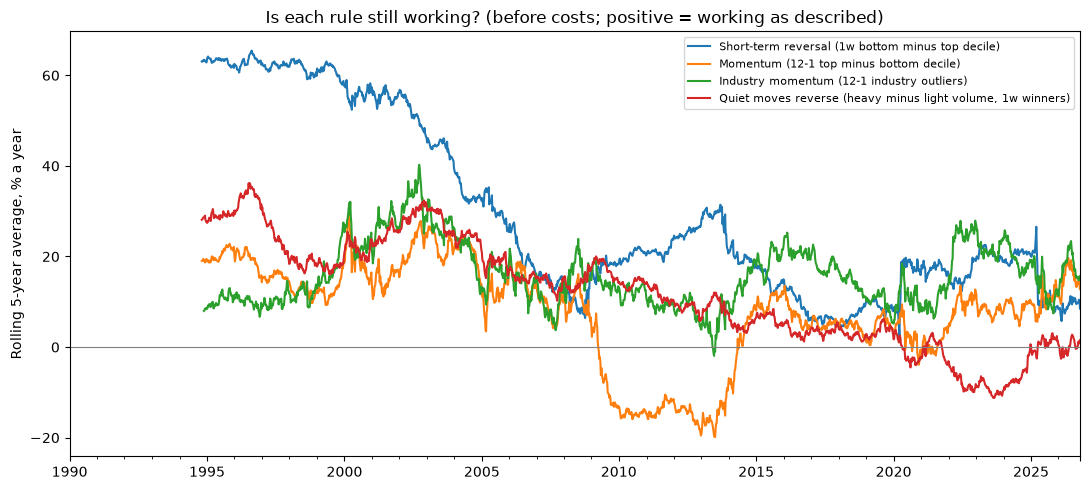

In [36]:
DECADES = {"1990s": ("1990", "1999"), "2000s": ("2000", "2009"), "2010s": ("2010", "2019"),
           "2020s": ("2020", str(weeks[-1].year))}

def ls_gross(name, K=1, variant="base"):
    """Weekly gross return of a headline strategy: long-short as is, long-only minus the market."""
    p, kind = strat(name, K, variant)
    return p["gross"] if kind == "ls" else p["gross"] - mkt

_t1, _b1 = HIT_SERIES[("1w", "up")]
_t12, _b12 = HIT_SERIES[("12-1", "up")]
_iu, _id = IND_PORTS[(f"outlier (|z| > {Z_IND:g})", 1)]
S_REV = base_curves["1w"]["gross"]
S_MOM = base_curves["12-1"]["gross"]
S_IND = long_short(_iu, _id)["gross"]
S_VOL = long_short(get_port("1w up | abnormal volume: yes"), get_port("1w up | abnormal volume: no"))["gross"]

# claim: (weekly series, scale to display units, unit)
EVERGREEN = {
    "Outliers are big movers: 1w up-outliers landing in next week's top or bottom 10% (pp above the 20% chance rate)":
        ((_t1 + _b1) - 0.20, 100, " pp"),
    "...but not a direction: 12-1 up-outliers, top-10% share minus bottom-10% share (pp)": (_t12 - _b12, 100, " pp"),
    "Last week's extremes snap back: 1w top minus bottom decile (% a year)": (S_REV, 5200, "%"),
    "...even entering a day later (skip a day)": (ls_gross("1w top minus bottom decile", 1, "skip1"), 5200, "%"),
    "Fama–MacBeth: last week's return (% a year per SD)": (FM_JOINT["r_1w"], 5200, "%"),
    "Quiet moves reverse: 1w up-outliers, heavy minus light abnormal volume": (S_VOL, 5200, "%"),
}
if NEWS and NEWS_OK:
    EVERGREEN["News sticks: 1w up-outliers, with minus without an earnings 8-K (2005 on)"] = (
        long_short(get_port("1w up | earnings 8-K: yes"), get_port("1w up | earnings 8-K: no"))["gross"], 5200, "%")
EVERGREEN.update({
    "Sudden 1-month spikes lag the market next week": (ls_gross("Sudden spikes"), 5200, "%"),
    "12-month winners keep winning: 12-1 top minus bottom decile": (S_MOM, 5200, "%"),
    "12-1 up-outliers vs market, equal-weighted": (ls_gross("12-1 up-outliers"), 5200, "%"),
    "12-1 up-outliers vs market, most liquid third": (ls_gross("12-1 up-outliers", 1, "t3"), 5200, "%"),
    f"12-1 up-outliers vs market, liquidity-weighted, capped {LW_CAP:.0%}": (ls_gross("12-1 up-outliers", 1, "lwcap"), 5200, "%"),
    "Fama–MacBeth: months 4–12 (% a year per SD)": (FM_JOINT["r_12m_ex3m"], 5200, "%"),
    "Winning industries keep winning: 12-1 industry outliers, up minus down": (S_IND, 5200, "%"),
    "Smooth vs jumpy climbers (frog in the pan): steady minus jumpy": (
        long_short(get_port(STEADY_UP), get_port(JUMPY_UP))["gross"], 5200, "%"),
})

def evergreen_label(t_full, same, n, share, weakest):
    """A summary label for the script, not a test. v4.1 adds `weakest` (the weakest decade as a fraction of the
    full-sample effect): "held" now also needs every decade to show at least a third of the effect, so a decade
    near zero (12-1 momentum in the 2000s: +0.3%, t 0.0) reads as "uneven" rather than "held"."""
    if not np.isfinite(t_full) or abs(t_full) < 2:
        return "no reliable effect"
    if not np.isfinite(share) or share < 1 / 3:
        return "faded"
    if same == n and np.isfinite(weakest) and weakest >= 1 / 3:
        return "held in every decade" if share >= 0.5 else "held in every decade, but weaker lately"
    if same == n:
        return "same sign every decade, but uneven"
    return "mostly held"

eg_rows = []
for claim, (y, scale, unit) in EVERGREEN.items():
    y = pd.Series(y).replace([np.inf, -np.inf], np.nan)
    full = nw_mean(y)
    row = {"claim": claim, "full sample": f"{full['mean'] * scale:+.1f}{unit} ({full['t']:+.1f})"}
    same, n, ratios = 0, 0, []
    for dname, (a, b) in DECADES.items():
        r = nw_mean(y.loc[a:b])
        if not np.isfinite(r["mean"]):
            row[dname] = ""
            continue
        row[dname] = f"{r['mean'] * scale:+.1f}{unit} ({r['t']:+.1f})"
        n += 1
        same += int(np.sign(r["mean"]) == np.sign(full["mean"]))
        if full["mean"]:
            ratios.append(r["mean"] / full["mean"])
    rec_ = nw_mean(y.loc[PERIODS["recent"]])
    share = rec_["mean"] / full["mean"] if full["mean"] else np.nan
    weakest = min(ratios) if ratios else np.nan
    row.update({"same sign": f"{same} of {n} decades", f"last {RECENT_YEARS}y vs full": round(share, 2),
                "weakest decade vs full": round(weakest, 2),
                "evergreen?": evergreen_label(full["t"], same, n, share, weakest)})
    eg_rows.append(row)
evergreen = pd.DataFrame(eg_rows).set_index("claim")
print("Each finding by decade: estimate (NW t), 1-week hold, before costs")
display(evergreen)
evergreen.to_csv(OUT_DIR / "evergreen_by_decade.csv")

ROLL = {"Short-term reversal (1w bottom minus top decile)": -S_REV,
        "Momentum (12-1 top minus bottom decile)": S_MOM,
        "Industry momentum (12-1 industry outliers)": S_IND,
        "Quiet moves reverse (heavy minus light volume, 1w winners)": S_VOL}
ROLL = {k: v.rolling(260, min_periods=200).mean() * 52 * 100 for k, v in ROLL.items()}
fig, ax = plt.subplots(figsize=(11, 5))
for k, v in ROLL.items():
    v.plot(ax=ax, label=k)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Rolling 5-year average, % a year")
ax.set_title("Is each rule still working? (before costs; positive = working as described)")
ax.legend(fontsize=8)
save(fig, "22_evergreen_rolling.png")

## 23. The thread: walkthrough and outlier history

`walkthrough(ticker, date)` shows what the whole-market picture said about one stock at the close of a week:
- momentum at each lookback, and its z-score against every other stock,
- the split into market, industry and stock-specific parts, and path smoothness,
- category, liquidity, abnormal volume, whether there was an earnings 8-K, and a reverse-split flag,
- the market state, and then what happened the next week.

With no date, it uses the latest week that has a following week to reveal.

`outlier_list(lookback)` lists the biggest up and down outliers in a week (default: the latest), with price, dollar volume, liquidity tercile and red flags, and returns the two tables. By default (`camera=True`) it hides two kinds of stock and says how many it hid: those with a reverse split in the past year, and those trading under `CAMERA_MIN_DVOL_M` million dollars a day. In v4 it also hides the estimated cost column, which is unreliable for liquid stocks (4b). `camera=False` shows everything. The z-scores are still computed against the whole eligible universe.

**New in v4: `outlier_history(ticker)`.** It lists every week the stock entered an outlier group: 1-week, 1-month and 12-1, up and down, plus steady climber and sudden spike. For each entry it shows how many weeks the stock stayed in the group and its return beyond the market over the next 1, 4 and 13 weeks. A summary per group compares the stock with all stocks that entered the same group. It also prints the stock's share of the recent big-stock momentum return (14b). `thread_chart(ticker)` marks the flags on the stock's total-return index (a camera figure). The walkthrough then shows the stock's most recent 12-1 entry that has a month of follow-up; that is the on-camera example.

In [37]:
def row_window(X, L, skip, i):
    """Window sum for every stock at row i only (fast)."""
    return window_sum(X.iloc[max(0, i - L - 1): i + 1], L, skip).iloc[-1]

def row_z(s, elig):
    v = s.where(elig)
    med = v.median()
    mad = (v - med).abs().median() * 1.4826
    return (s - med) / mad

def week_index(date=None, offset=1):
    if date is None:
        return len(LR.index) - 1 - offset
    return int(LR.index.get_indexer([pd.Timestamp(date)], method="pad")[0])

def row_flags(i, cols, L=4, cost=False):
    """Liquidity and red-flag columns for stocks `cols` at row i (the estimated cost only with cost=True; see 4b)."""
    dv_prev = DV.iloc[max(0, i - 13):i].median()
    out = pd.DataFrame({"price": price.iloc[i].reindex(cols),
                        "dollar_vol_13w_$M": (dvol13.iloc[i] / 1e6).reindex(cols),
                        "liq_tercile": LIQ_T.iloc[i].reindex(cols),
                        "abnormal_vol_1w": (DV.iloc[i] / dv_prev).reindex(cols),
                        "reverse_split_52w": RSPLIT52.iloc[i].reindex(cols)})
    if cost:
        out[f"cost_bps_{COST_MODEL}"] = (cost1.iloc[i] * 1e4).reindex(cols)
    if NEWS and NEWS_OK:
        out[f"earnings_8k_last_{L}w"] = NEWSW.iloc[max(0, i - L + 1): i + 1].any().reindex(cols)
    return out

def walkthrough(ticker, date=None, camera=True):
    t = ticker.upper().replace(".", "-")
    if t not in LR.columns:
        print(f"{t} is not in the panel.")
        return
    i = week_index(date, offset=1)
    d, elig = LR.index[i], ELIG.iloc[i]
    print(f"{t}  {NAMES.get(t, '')}  |  week ending {d.date()}  |  industry: {ind.get(t, 'Other')}")
    if not bool(elig.get(t, False)):
        print("Not in the eligible universe this week (price, liquidity or history filter); z-scores are still shown.")
    rows = []
    for lb, (L, skip) in LOOKBACKS.items():
        tot = row_window(LR, L, skip, i)
        mk, ic, sp = (row_window(COMPONENTS[c], L, skip, i) for c in ["market", "industry", "specific"])
        nd = row_window(FW["ndays"], L, skip, i)
        idv = np.sign(tot) * (row_window(FW["nneg"], L, skip, i) - row_window(FW["npos"], L, skip, i)) / nd.where(nd > 0)
        rows.append({"lookback": lb, "return": np.expm1(tot.get(t)), "z_total": row_z(tot, elig).get(t),
                     "market part": mk.get(t), "industry part": ic.get(t), "stock-specific part": sp.get(t),
                     "z_stock_specific": row_z(sp, elig).get(t), "smoothness ID (lower = smoother)": idv.get(t)})
    display(pd.DataFrame(rows).set_index("lookback"))
    flags = [name for name, m in CATS.items() if bool(m.iloc[i].get(t, False))]
    print("Category this week:", ", ".join(flags) if flags else "none")
    display(row_flags(i, [t], cost=not camera))
    print("Market state:")
    display(STATE.iloc[[i]])
    if i + 1 < len(LR.index):
        nxt = R.iloc[i + 1]
        pct = nxt.where(elig).rank(pct=True).get(t)
        msg = f"Next week ({LR.index[i + 1].date()}): {nxt.get(t):+.2%} vs market {mkt.iloc[i + 1]:+.2%}"
        if pd.notna(R_FIRST.iloc[i + 1].get(t)):
            msg += f" (entering a day later: {R_FIRST.iloc[i + 1].get(t):+.2%})"
        if pd.notna(pct):
            msg += f"; percentile among eligible stocks: {pct:.0%}"
        print(msg)

def outlier_list(lb="1m", comp="total", n=10, date=None, camera=True, quiet=False):
    """Biggest up and down outliers in a week; displays them (unless quiet) and returns (up table, down table)."""
    i = week_index(date, offset=0)
    L, skip = LOOKBACKS[lb]
    s = row_window(COMPONENTS[comp], L, skip, i)
    elig = ELIG.iloc[i]
    z = row_z(s, elig).where(elig).dropna().sort_values()
    move = np.expm1(s) if comp == "total" else s
    if camera:
        keep_ = ~RSPLIT52.iloc[i].reindex(z.index, fill_value=False).astype(bool) & \
                (dvol13.iloc[i].reindex(z.index) >= CAMERA_MIN_DVOL_M * 1e6)
        n_out = int((z.abs() > Z_OUTLIER).sum())
        n_hid = int(((z.abs() > Z_OUTLIER) & ~keep_).sum())
        if not quiet:
            print(f"On-camera filter: hid {n_hid} of {n_out} outliers (|z| > {Z_OUTLIER:g}) for a reverse split in the past year "
                  f"or under ${CAMERA_MIN_DVOL_M:g}M a day")
        z = z[keep_]
    def tab(zz):
        base_ = pd.DataFrame({"name": NAMES.reindex(zz.index), "industry": ind.reindex(zz.index),
                              "z": zz, "move": move.reindex(zz.index)})
        return base_.join(row_flags(i, zz.index, L=min(L - skip, 4), cost=not camera))
    up_tab, dn_tab = tab(z.iloc[::-1].head(n)), tab(z.head(n))
    if not quiet:
        print(f"Week ending {LR.index[i].date()}: biggest {lb} {comp} outliers (up, then down)")
        display(up_tab)
        display(dn_tab)
    return up_tab, dn_tab

NVDA's share of the 2016–2026 gross return of 12-1 up-outliers, liquidity-weighted: 34%
NVDA's share of the 2016–2026 gross return of 12-1 up-outliers, liquidity-weighted, capped 5%: 6%
NVDA's share of the 2016–2026 gross return of 12-1 up-outliers, most liquid third, equal-weighted: 4%

NVDA: entries into each outlier group and what happened next (returns beyond the market)


,entries,weeks flagged,NVDA: next 1w vs market,all stocks: next 1w vs market,NVDA: next 4w vs market,all stocks: next 4w vs market,NVDA: next 13w vs market,all stocks: next 13w vs market,NVDA: share beating the market over 4w
group,,,,,,,,,
1-week up-outlier,153,183,0.0158,-0.0015,0.0355,-0.0011,0.0986,0.0015,0.5621
1-week down-outlier,120,142,0.0027,0.0022,0.0153,0.0040,0.0848,0.0043,0.4917
1-month up-outlier,86,206,0.0070,-0.0012,0.0392,-0.0004,0.1199,0.0040,0.6163
1-month down-outlier,52,126,0.0075,0.0017,-0.0136,0.0039,0.0915,0.0035,0.4231
12-1 up-outlier,25,373,-0.0106,0.0027,0.0407,0.0088,0.1413,0.0174,0.6000
12-1 down-outlier,17,118,-0.0002,-0.0010,0.0022,-0.0032,0.0433,-0.0038,0.7647
steady climber,26,267,0.0101,0.0016,0.0255,0.0056,0.1219,0.0143,0.5769
sudden spike,29,56,-0.0019,-0.0015,0.0222,-0.0009,0.0925,0.0062,0.5517


Most recent entries:


,week,group,weeks in group,last week in group,next 1w vs market,next 4w vs market,next 13w vs market
493,2024-10-11,1-week up-outlier,1,2024-10-11,0.0147,0.0557,-0.0057
494,2024-10-18,1-month up-outlier,2,2024-10-25,0.0362,0.0209,-0.0380
495,2025-01-31,1-month down-outlier,1,2025-01-31,0.0840,0.0609,0.0166
496,2025-01-31,1-week down-outlier,1,2025-01-31,0.0840,0.0609,0.0166
497,2025-02-07,1-week up-outlier,1,2025-02-07,0.0551,-0.0810,-0.0380
498,2025-03-14,1-week up-outlier,1,2025-03-14,-0.0398,-0.0392,0.0988
499,2025-04-11,1-week up-outlier,1,2025-04-11,-0.0722,-0.0101,0.3067
500,2025-04-18,1-week down-outlier,1,2025-04-18,0.0458,0.1999,0.4945
501,2025-05-16,1-week up-outlier,1,2025-05-16,-0.0038,0.0453,0.2440
502,2025-05-30,1-month up-outlier,2,2025-06-06,0.0319,0.1201,0.1863


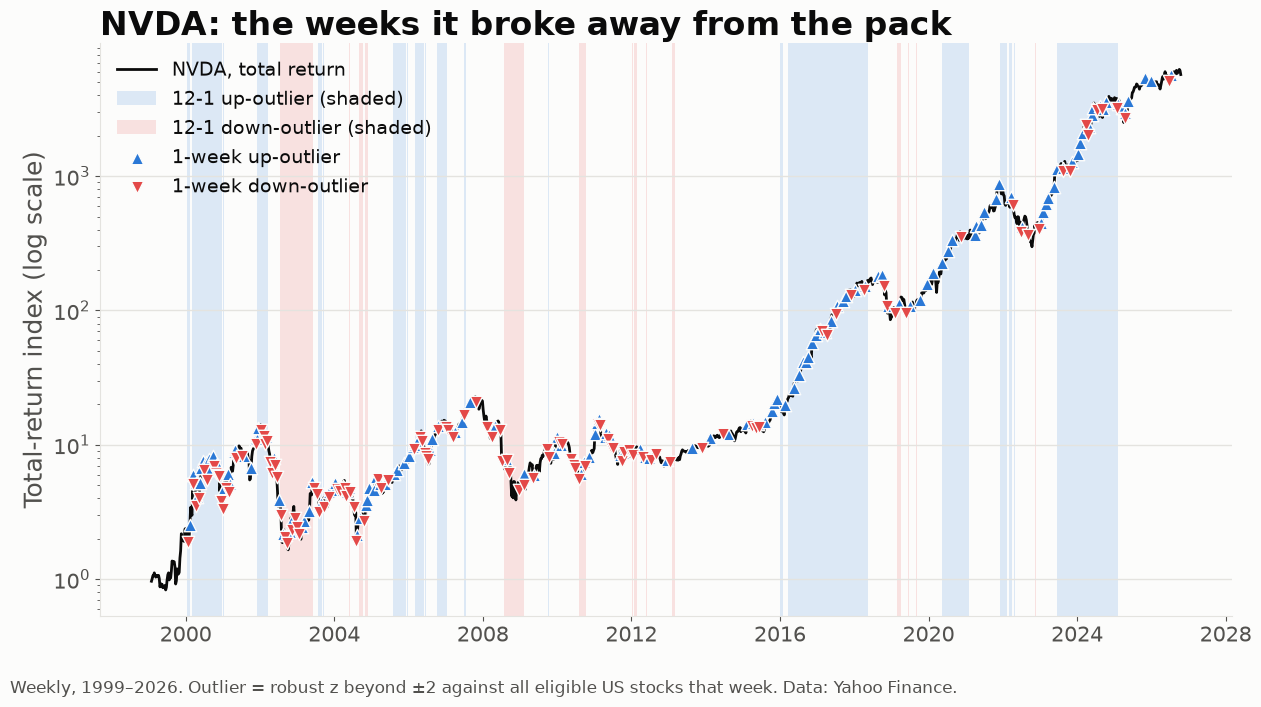

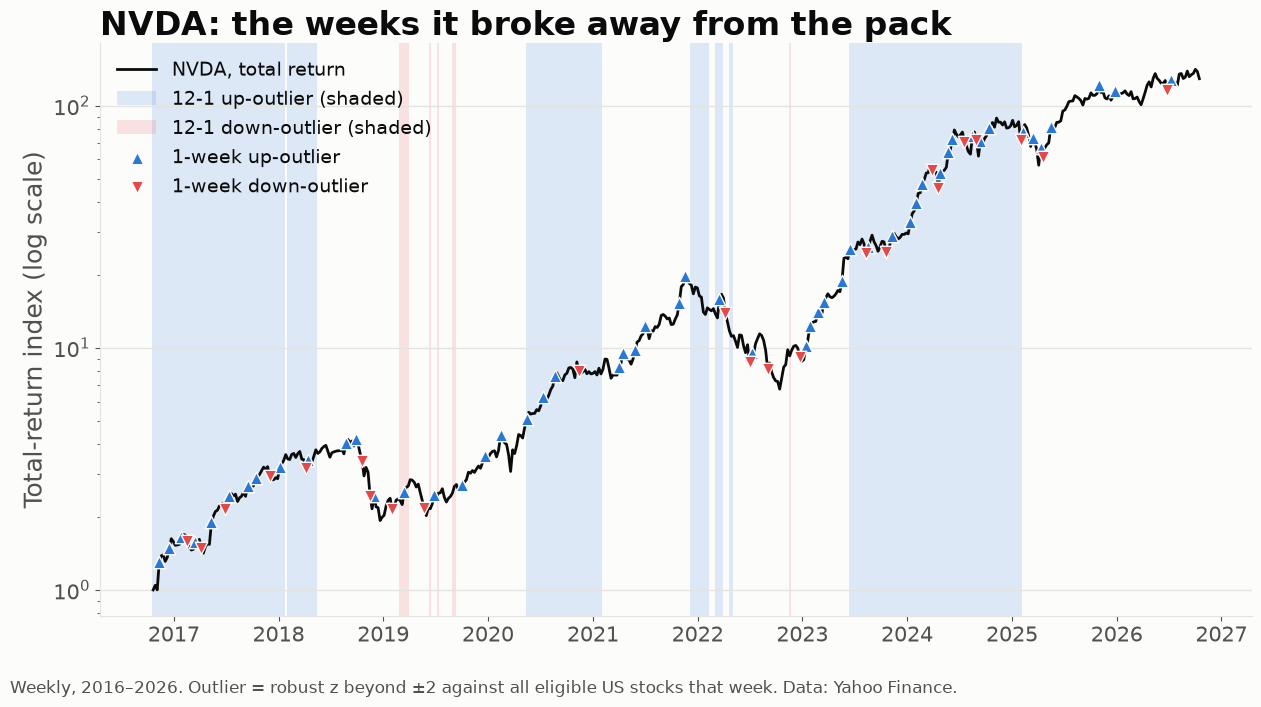


On-camera example: NVDA at its most recent 12-1 up-outlier entry with a month of follow-up
NVDA  NVIDIA CORP  |  week ending 2023-06-16  |  industry: Chips


,return,z_total,market part,industry part,stock-specific part,z_stock_specific,smoothness ID (lower = smoother)
lookback,,,,,,,
1w,0.1012,2.5234,0.0477,-0.0033,0.0557,1.7420,-0.6000
1m,0.3657,3.6419,0.1027,0.0318,0.2042,3.2895,-0.0526
1m-1w,0.2402,2.8051,0.0550,0.0351,0.1485,2.7947,0.1429
3m,0.6597,3.2970,0.2249,-0.0242,0.3322,2.6958,-0.1429
3m-1m,0.2153,1.4063,0.1222,-0.0560,0.1280,1.1780,-0.1818
6m,1.5770,4.3562,0.2486,0.0245,0.7235,4.0377,-0.1613
6m-1m,0.8870,3.0377,0.1459,-0.0074,0.5193,2.9035,-0.1810
12-1,0.9702,2.0725,0.2564,0.0784,0.4375,1.7270,-0.0909


Category this week: Steady climber (12-1 up, smooth)


,price,dollar_vol_13w_$M,liq_tercile,abnormal_vol_1w,reverse_split_52w,earnings_8k_last_4w
Ticker,,,,,,
NVDA,426.9200,"11,549.3253",3.0000,2.1575,False,True


Market state:


...

Category this week: none


,price,dollar_vol_13w_$M,liq_tercile,abnormal_vol_1w,reverse_split_52w,earnings_8k_last_4w
Ticker,,,,,,
NVDA,229.2800,"26,039.3533",3.0000,0.9135,False,False


Market state:


,mkt_4w,mkt_52w,bear_3y,mkt_vol,disp_1m,mom_gap,outlier_share
2026-10-09,0.0174,0.1779,0.0000,0.1121,0.0495,1.6094,0.1384


Next week (2026-10-16): -6.61% vs market -2.06% (entering a day later: -5.48%); percentile among eligible stocks: 21%


In [38]:
HIST_GROUPS = {"1w up": "1-week up-outlier", "1w down": "1-week down-outlier",
               "1m up": "1-month up-outlier", "1m down": "1-month down-outlier",
               "12-1 up": "12-1 up-outlier", "12-1 down": "12-1 down-outlier",
               STEADY_UP: "steady climber", SPIKE_UP: "sudden spike"}
FWD_WEEKS = [1, 4, 13]
_lmk = np.log1p(mkt)
FWD = {k: np.expm1(LR.rolling(k).sum().shift(-k)).sub(np.expm1(_lmk.rolling(k).sum().shift(-k)), axis=0).astype("float32")
       for k in FWD_WEEKS}        # return over the next k weeks minus the market's, on the formation week's row
GROUP_AVG = {}

def spells(m):
    """(entry week, last week, length) for each run of consecutive True weeks in a boolean Series."""
    m = m.fillna(False).astype(bool)
    sid = (m & ~m.shift(1, fill_value=False)).cumsum().where(m).dropna()
    return [(g.index[0], g.index[-1], len(g)) for _, g in sid.groupby(sid)]

def group_average(key):
    """Average return beyond the market after entering a group, pooled over all stocks and entries."""
    if key not in GROUP_AVG:
        ent = entries(MEMBERS[key])
        GROUP_AVG[key] = {k: float(np.nanmean(FWD[k].where(ent).to_numpy(dtype="float64"))) for k in FWD_WEEKS}
    return GROUP_AVG[key]

def outlier_history(ticker, groups=None):
    """Every week `ticker` entered an outlier group, how long it stayed, and its return beyond the market afterwards.
    Returns (one row per entry, one row per group)."""
    groups = groups or HIST_GROUPS
    t = ticker.upper().replace(".", "-")
    if t not in LR.columns:
        print(f"{t} is not in the panel.")
        return None, None
    rows, summ = [], []
    for key, label in groups.items():
        sp = spells(MEMBERS[key][t])
        mine = []
        for a, b, n in sp:
            i = LR.index.get_loc(a)
            mine.append({"week": a, "group": label, "weeks in group": n, "last week in group": b,
                         **{f"next {k}w vs market": float(FWD[k][t].iloc[i]) for k in FWD_WEEKS}})
        rows += mine
        h = pd.DataFrame(mine)
        avg = group_average(key)
        srow = {"group": label, "entries": len(sp), "weeks flagged": int(MEMBERS[key][t].sum())}
        for k in FWD_WEEKS:
            col = f"next {k}w vs market"
            srow[f"{t}: {col}"] = h[col].mean() if len(h) else np.nan
            srow[f"all stocks: {col}"] = avg[k]
        x4 = h["next 4w vs market"].dropna() if len(h) else pd.Series(dtype=float)
        srow[f"{t}: share beating the market over 4w"] = (x4 > 0).mean() if len(x4) else np.nan
        summ.append(srow)
    hist = pd.DataFrame(rows).sort_values("week").reset_index(drop=True) if rows else pd.DataFrame()
    summary = pd.DataFrame(summ).set_index("group")
    for (name, scheme), c in CONTRIB.items():
        if name == "12-1 up-outliers" and t in c.index and c.sum() != 0:
            print(f"{t}'s share of the {RECENT_START.year}–{weeks[-1].year} gross return of 12-1 up-outliers, "
                  f"{CONC_SCHEMES[scheme]}: {c[t] / c.sum():.0%}")
    return hist, summary

def thread_chart(ticker, start=None):
    """Camera figure: the stock's total-return index with its outlier flags."""
    t = ticker.upper().replace(".", "-")
    lv = np.exp(LR[t].fillna(0).cumsum()).where(LR[t].notna().cummax()).dropna()
    if start is not None:
        lv = lv.loc[pd.Timestamp(start):]
        lv = lv / lv.iloc[0]
    with plt.rc_context(CAM_RC):
        fig, ax = plt.subplots()
        ax.plot(lv.index, lv.values, color=INK, lw=2, label=f"{t}, total return")
        ax.set_yscale("log")
        for key, col, lab in [("12-1 up", POS, "12-1 up-outlier (shaded)"), ("12-1 down", NEG, "12-1 down-outlier (shaded)")]:
            first = True
            for a, b, n in spells(MEMBERS[key][t]):
                if b < lv.index[0]:
                    continue
                ax.axvspan(max(a, lv.index[0]) - pd.Timedelta(days=3), b + pd.Timedelta(days=4), color=col, alpha=0.15,
                           lw=0, label=lab if first else None)
                first = False
        for key, col, mk, lab in [("1w up", POS, "^", "1-week up-outlier"), ("1w down", NEG, "v", "1-week down-outlier")]:
            m_ = MEMBERS[key][t].fillna(False).astype(bool)
            e_ = m_ & ~m_.shift(1, fill_value=False)
            d_ = e_.index[e_.values]
            d_ = d_[d_ >= lv.index[0]]
            ax.scatter(d_, lv.reindex(d_), marker=mk, s=80, color=col, edgecolor=SURFACE, linewidth=1, zorder=3, label=lab)
        ax.set_title(f"{t}: the weeks it broke away from the pack")
        ax.set_ylabel("Total-return index (log scale)")
        ax.legend(loc="upper left", fontsize=14)
        suffix = "" if start is None else f"_from_{pd.Timestamp(start).year}"
        cam_save(fig, f"thread_{t}{suffix}.png",
                 note=f"Weekly, {lv.index[0].year}–{lv.index[-1].year}. Outlier = robust z beyond ±{Z_OUTLIER:g} against all "
                      "eligible US stocks that week. Data: Yahoo Finance.")

hist, hist_sum = outlier_history(THREAD_TICKER)
if hist is not None:
    print(f"\n{THREAD_TICKER}: entries into each outlier group and what happened next (returns beyond the market)")
    display(hist_sum.round(4))
    print("Most recent entries:")
    display(hist.tail(15).round(4))
    thread_chart(THREAD_TICKER)
    thread_chart(THREAD_TICKER, start=RECENT_START)
    recent12 = hist[(hist["group"] == HIST_GROUPS["12-1 up"]) & hist["next 4w vs market"].notna()]
    if len(recent12):
        print(f"\nOn-camera example: {THREAD_TICKER} at its most recent 12-1 up-outlier entry with a month of follow-up")
        walkthrough(THREAD_TICKER, recent12["week"].iloc[-1])
    print(f"\n{THREAD_TICKER} in the latest week with a following week:")
    walkthrough(THREAD_TICKER)

## 24. This week: the dated segment

Everything time-sensitive lives here, so the rest of the video stays true for years. It describes the week ending `AS_OF` (default: the latest complete week). To refresh on recording day, set `UPDATE_PRICES_TO` (and optionally `NEWS_MAX_AGE_DAYS`) and re-run the notebook.

- **Market state vs its history:** each section-16 metric this week, with its percentile among all weeks since 1990.
- **Weeks like this one:** the headline strategies' average next-week return in past weeks whose market volatility and cross-sectional dispersion were in the same thirds as this week, next to their all-weeks average. This is descriptive, not a forecast: the thirds are set with hindsight, and similar weeks cluster.
- **This week's outliers** (camera-filtered), **industries** and the thread stock.
- **`snapshot_<date>.md`** in the outputs folder: the same content, ready to paste into the pinned comment or a community post. It says what history suggests, not what to buy. **New in v4.1:** it is written in plain English (no variable names or industry codes), with returns as simple percentages and a note that industry labels come from current SEC codes.

In [39]:
i_now = week_index(AS_OF, offset=0)
d_now = LR.index[i_now]
d_label = f"{d_now:%b} {d_now.day}, {d_now.year}"
print(f"Snapshot: week ending {d_label} ({int(ELIG.iloc[i_now].sum()):,} eligible stocks)")

# ---- market state vs its history
STATE_MEANING = {"mkt_4w": "market log return, last 4 weeks", "mkt_52w": "market log return, last 52 weeks",
                 "bear_3y": "1 if the market is down over 3 years", "mkt_vol": "market volatility, last 63 days (annualized)",
                 "disp_1m": "how spread out stocks' 1-month returns are", "mom_gap": "12-1 return of the top decile minus the bottom",
                 "outlier_share": "share of stocks that are 1-month outliers"}
state_now = pd.DataFrame({"this week": STATE.iloc[i_now], "percentile since 1990": STATE.rank(pct=True).iloc[i_now],
                          "what it measures": pd.Series(STATE_MEANING)}).reindex(list(STATE.columns))
display(state_now)

# ---- what happened after weeks like this one
TERC_NAMES = {1: "lowest", 2: "middle", 3: "highest"}
terc = np.ceil(STATE[["mkt_vol", "disp_1m"]].rank(pct=True) * 3)
now_t = terc.iloc[i_now]
like = (terc == now_t).all(axis=1)
like.iloc[i_now:] = False                          # past weeks only, each with a following week
LIKE_STRATS = ["1w down-outliers (buy last week's crashes)", "1w up minus down", "1m up minus down",
               "12-1 up-outliers", "12-1 up minus down", "Sudden spikes"]
like_rows = []
for name in LIKE_STRATS:
    yn = target(name, "gross").shift(-1)           # next week's return, on the formation week's row
    a_, b_ = nw_mean(yn.iloc[:i_now]), nw_mean(yn[like])
    like_rows.append({"strategy": name, "all weeks (% a year)": a_["mean"] * 5200, "t": a_["t"],
                      "weeks like this one (% a year)": b_["mean"] * 5200, "t (like)": b_["t"]})
like_tab = pd.DataFrame(like_rows).set_index("strategy")
like_text = (f"market volatility in the {TERC_NAMES.get(now_t['mkt_vol'], '?')} third and the spread between stocks' "
             f"returns in the {TERC_NAMES.get(now_t['disp_1m'], '?')} third of all weeks since {weeks[0].year} "
             f"({int(like.sum()):,} past weeks)")
print(f"Weeks like this one: {like_text}. Gross, before costs; long-only legs are vs the market.")
display(like_tab.round(2))

# ---- outliers this week
cnt_rows = []
for lb in MAIN_LBS:
    L, skip = LOOKBACKS[lb]
    zz = row_z(row_window(LR, L, skip, i_now), ELIG.iloc[i_now]).where(ELIG.iloc[i_now])
    typ = hits_bh.query("component == 'total' and lookback == @lb and period == 'recent'").set_index("side")["outliers_per_week"]
    cnt_rows.append({"lookback": lb, "up-outliers": int((zz > Z_OUTLIER).sum()), "typical up (last 10y)": typ.get("up"),
                     "down-outliers": int((zz < -Z_OUTLIER).sum()), "typical down (last 10y)": typ.get("down")})
display(pd.DataFrame(cnt_rows).set_index("lookback").round(0))
SNAP_LISTS = {lb: outlier_list(lb, date=AS_OF, n=10) for lb in MAIN_LBS}

# ---- industries this week (our universe, so it is current)
_ind_now = {}
for lb, (L, skip) in LOOKBACKS.items():
    s = row_window(OWN_ILR, L, skip, i_now)
    ok_ = own_ok.iloc[i_now] & s.notna()
    _ind_now[lb] = row_z(s, ok_).where(ok_)
IND_NOW = pd.DataFrame(_ind_now)
IND_NOW["stocks"] = ELIG.iloc[i_now].groupby(ind).sum().reindex(IND_NOW.index)
IND_NOW = IND_NOW[IND_NOW["stocks"] >= MIN_IND_STOCKS].sort_values("12-1", ascending=False)
print(f"Industries this week (our universe, liquidity-weighted): z against the other industries; outliers beyond ±{Z_IND:g}")
display(pd.concat([IND_NOW.head(5), IND_NOW.tail(5)]).round(2))

# ---- the thread stock this week
_tt = THREAD_TICKER.upper()
thread_now = pd.Series({lb: row_z(row_window(LR, L, skip, i_now), ELIG.iloc[i_now]).get(_tt)
                        for lb, (L, skip) in LOOKBACKS.items()}, name=f"{_tt} z-score")
display(thread_now.to_frame().T.round(2))

# ---- Markdown for the pinned comment or a community post
def md_table(df, digits=2):
    """A DataFrame as a Markdown table (no extra packages)."""
    def fmt(v):
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else ""
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        if isinstance(v, (float, np.floating)):
            return "" if np.isnan(v) else f"{v:,.{digits}f}"
        return str(v)
    head = [str(df.index.name or "")] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    for idx, r in df.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [fmt(v) for v in r.values]) + " |")
    return "\n".join(lines)

def short_list(tab_, k=5):
    t_ = tab_.head(k)[["name", "industry", "z", "move"]].copy()
    t_["industry"] = t_["industry"].map(lambda c: FF49_NAMES.get(c, c))
    t_["z"] = t_["z"].map(lambda v: f"{v:+.1f}")
    t_["move"] = t_["move"].map(lambda v: f"{v:+.0%}")
    t_.index.name = "ticker"
    return t_

# v4.1: plain English for viewers (v4 printed variable names such as mkt_4w, industry codes and counts as 34.00).
# Every cell is pre-formatted as text, so md_table can't turn a count into a float.
_pct = lambda v: f"{v:.0%}" if pd.notna(v) else ""
_zf = lambda v: f"{v:+.1f}" if pd.notna(v) else "n/a"
STATE_PLAIN = {   # state: (label, how to show this week's value)
    "mkt_4w": ("Market, last 4 weeks", lambda v: f"{np.expm1(v):+.1%}"),
    "mkt_52w": ("Market, last 52 weeks", lambda v: f"{np.expm1(v):+.1%}"),
    "bear_3y": ("Market down over the last 3 years?", lambda v: "yes" if v >= 0.5 else "no"),
    "mkt_vol": ("Market volatility, last 3 months (annualized)", lambda v: f"{v:.0%}"),
    "disp_1m": ("How spread out stocks' 1-month returns are", lambda v: f"{v:.1%}"),
    "mom_gap": ("How far apart 12-month winners and losers are (log-return gap)", lambda v: f"{v:.2f}"),
    "outlier_share": ("Share of stocks that are 1-month outliers", lambda v: f"{v:.0%}"),
}
_st = pd.DataFrame(
    {"this week": [STATE_PLAIN[k][1](v) if (k in STATE_PLAIN and pd.notna(v)) else ("" if pd.isna(v) else f"{v:.3g}")
                   for k, v in state_now["this week"].items()],
     f"percentile since {weeks[0].year}": [_pct(p) for p in state_now["percentile since 1990"]]},
    index=[STATE_PLAIN.get(k, (k,))[0] for k in state_now.index])
_st.index.name = "the market this week"
STRAT_PLAIN = {"1w down-outliers (buy last week's crashes)": "Buy last week's biggest losers",
               "1w up minus down": "Last week's biggest winners minus losers",
               "1m up minus down": "Last month's biggest winners minus losers",
               "12-1 up-outliers": "Buy the biggest 12-month winners",
               "12-1 up minus down": "12-month winners minus losers",
               "Sudden spikes": "Buy sudden 1-month spikes"}
_like = pd.DataFrame({"all weeks": like_tab["all weeks (% a year)"].map(lambda v: f"{v:+.1f}%"),
                      "weeks like this one": like_tab["weeks like this one (% a year)"].map(lambda v: f"{v:+.1f}%")})
_like.index = [STRAT_PLAIN.get(k, k) for k in like_tab.index]
_like.index.name = "rule (% a year, before costs)"
_indp = pd.concat([IND_NOW.head(3), IND_NOW.tail(3)])
_ind = pd.DataFrame({"12-month trend (z)": _indp["12-1"].map(_zf), "last month (z)": _indp["1m"].map(_zf),
                     "stocks": _indp["stocks"].map(lambda v: f"{int(v)}")})
_ind.index = [FF49_NAMES.get(k, k) for k in _indp.index]
_ind.index.name = "industry"
thread_line = (f"{_tt}'s z-score against all eligible stocks: last week {_zf(thread_now.get('1w'))}, "
               f"last month {_zf(thread_now.get('1m'))}, 12-month trend {_zf(thread_now.get('12-1'))}. "
               f"An outlier is beyond ±{Z_OUTLIER:g}.")
up12, dn12 = SNAP_LISTS["12-1"]
up1w, dn1w = SNAP_LISTS["1w"]
snap_lines = [
    f"# Momentum-outlier screen: week ending {d_label}", "",
    "What the screen from the video flags this week, and what history says about weeks like it. "
    "These are historical tendencies, not forecasts or advice. An outlier is a stock whose move is more than "
    f"{Z_OUTLIER:g} robust standard deviations from the typical stock that week, among liquid US stocks over "
    f"${MIN_PRICE:g}.", "",
    "## The market this week", "", md_table(_st), "",
    "## Weeks like this one", "",
    f"Past weeks with {like_text}. Before costs; rules that only buy are measured against the market. "
    "Descriptive, not a forecast.", "", md_table(_like), "",
    "## Biggest 12-month outliers (skipping the latest month)", "",
    "Up:", "", md_table(short_list(up12)), "", "Down:", "", md_table(short_list(dn12)), "",
    "## Biggest 1-week outliers", "",
    "Up:", "", md_table(short_list(up1w)), "", "Down:", "", md_table(short_list(dn1w)), "",
    "## Industries breaking from the pack", "",
    f"z-score against the other industries; an industry outlier is beyond ±{Z_IND:g}.", "", md_table(_ind), "",
    "Industry labels come from each company's current SEC industry code, so a company that changed its business "
    "can sit in an odd industry.", "",
    f"## {_tt}", "", thread_line, "",
]
snap_path = OUT_DIR / f"snapshot_{d_now.date()}.md"
snap_path.write_text("\n".join(snap_lines), encoding="utf-8")
print(f"Wrote {snap_path}")
print("\n".join(snap_lines))

Snapshot: week ending Oct 16, 2026 (2,558 eligible stocks)


,this week,percentile since 1990,what it measures
mkt_4w,-0.0011,0.3448,"market log return, last 4 weeks"
mkt_52w,0.1398,0.5206,"market log return, last 52 weeks"
bear_3y,0.0000,0.4303,1 if the market is down over 3 years
mkt_vol,0.1144,0.3193,"market volatility, last 63 days (annualized)"
disp_1m,0.0566,0.7919,how spread out stocks' 1-month returns are
mom_gap,1.5709,0.8422,12-1 return of the top decile minus the bottom
outlier_share,0.1247,0.7747,share of stocks that are 1-month outliers


Weeks like this one: market volatility in the lowest third and the spread between stocks' returns in the highest third of all weeks since 1990 (47 past weeks). Gross, before costs; long-only legs are vs the market.


,all weeks (% a year),t,weeks like this one (% a year),t (like)
strategy,,,,
1w down-outliers (buy last week's crashes),24.6800,6.8500,4.6400,0.2600
1w up minus down,-35.9900,-8.4600,-13.5600,-0.8000
1m up minus down,-26.7100,-6.8300,-13.2400,-0.7200
12-1 up-outliers,12.4100,3.8300,-1.0700,-0.0600
12-1 up minus down,10.3500,2.2200,13.7700,0.8700
Sudden spikes,-7.9400,-2.8200,0.4900,0.0300


,up-outliers,typical up (last 10y),down-outliers,typical down (last 10y)
lookback,,,,
1w,29,129.0000,353,132.0000
1m,80,123.0000,239,131.0000
12-1,127,127.0000,143,129.0000


...

,name,industry,z,move,price,dollar_vol_13w_$M,liq_tercile,abnormal_vol_1w,reverse_split_52w,earnings_8k_last_4w
Ticker,,,,,,,,,,
SMR,NUSCALE POWER Corp,FabPr,-5.5718,-0.8131,5.8300,283.0278,3.0000,0.7511,False,False
METC,"Ramaco Resources, Inc.",Coal,-5.3408,-0.7986,7.8300,21.2182,2.0000,0.9553,False,False
CCOI,"COGENT COMMUNICATIONS HOLDINGS, INC.",Telcm,-5.2342,-0.7915,8.0700,17.7546,1.0000,0.9449,False,False
OKLO,Oklo Inc.,Util,-4.8960,-0.7674,27.9700,391.0955,3.0000,0.8170,False,False
BRBR,"BELLRING BRANDS, INC.",Food,-4.4107,-0.7279,9.4300,35.0294,2.0000,1.1108,False,False
TTD,"Trade Desk, Inc.",Softw,-4.3390,-0.7215,12.2300,258.0161,3.0000,0.8860,False,False
XXI,"Twenty One Capital, Inc.",Banks,-4.1994,-0.7086,5.6200,10.7030,1.0000,1.2100,False,False
VITL,"Vital Farms, Inc.",Food,-4.1768,-0.7065,8.4000,16.1843,1.0000,0.9081,False,False
NNE,Nano Nuclear Energy Inc.,Util,-3.8260,-0.6712,12.8800,33.0753,2.0000,0.9244,False,False


Industries this week (our universe, liquidity-weighted): z against the other industries; outliers beyond ±1.5


,1w,1m,1m-1w,3m,3m-1m,6m,6m-1m,12-1,stocks
sic,,,,,,,,,
Hardw,-2.5800,-2.7700,-0.9000,0.3200,2.5500,2.8900,5.1000,3.9100,34
Chips,-2.5600,-1.4700,1.0900,0.4300,1.6300,1.4500,2.6300,2.5600,106
Steel,-1.3300,-0.9500,0.1700,-1.0900,-0.2400,-0.7500,-0.3300,2.0700,28
Oil,0.8200,1.2100,0.5500,2.8500,1.8800,1.9400,1.7600,1.9700,78
LabEq,-2.1700,-0.9300,1.3700,0.3300,1.1200,0.1800,0.7900,1.7800,42
Util,0.0300,0.4000,0.3900,-0.4600,-0.6900,-0.4600,-0.7200,-1.0200,90
Autos,-1.3100,-0.5700,0.7400,-0.9500,-0.4100,-0.8600,-0.6800,-1.0600,36
RlEst,-0.0500,-0.9400,-1.5700,-1.5500,-0.7000,-0.7200,-0.3100,-1.3800,26
Clths,0.9300,1.1800,0.3500,-1.0700,-1.9000,-1.0300,-1.8500,-1.4000,21


,1w,1m,1m-1w,3m,3m-1m,6m,6m-1m,12-1
NVDA z-score,-1.3800,-0.2400,0.7800,0.5900,0.8800,0.2600,0.3700,0.2200


Wrote outputs_v7/snapshot_2026-10-16.md
# Momentum-outlier screen: week ending Oct 16, 2026

What the screen from the video flags this week, and what history says about weeks like it. These are historical tendencies, not forecasts or advice. An outlier is a stock whose move is more than 2 robust standard deviations from the typical stock that week, among liquid US stocks over $5.

## The market this week

| the market this week | this week | percentile since 1990 |
|---|---|---|
| Market, last 4 weeks | -0.1% | 34% |
| Market, last 52 weeks | +15.0% | 52% |
| Market down over the last 3 years? | no | 43% |
| Market volatility, last 3 months (annualized) | 11% | 32% |
| How spread out stocks' 1-month returns are | 5.7% | 79% |
| How far apart 12-month winners and losers are (log-return gap) | 1.57 | 84% |
| Share of stocks that are 1-month outliers | 12% | 77% |

## Weeks like this one

Past weeks with market volatility in the lowest third and the spread between stocks' returns in the h

## 25. Camera figures

1920×1080 PNGs in `outputs_v7/camera/`, numbered in the order of the video plan at the top. They have large type, plain-English titles and a source line on a light background. The colors are set once in the config cell (`SERIES`, `POS`, `NEG`, `INK`), so you can match them to your thumbnails.

The numbers come from the analysis above. Every number in a title is filled in from the results, so a re-run with new data updates the titles too. The wording of a title can't update, though, so read each one against its table before recording. Each figure has its own cell, so one failure doesn't stop the rest.

**New in v4.1**
- **Nothing is cut off.** The notebook previews figures with a tight bounding box, so text past the edge still showed there, but the saved PNG cut it off: most of v4's titles and several source lines. `cam_save` now shrinks any title or note that is too wide (to 80% of its size at most), then wraps it, and makes room for a wrapped note. The preview and the file now match.
- **06** is titled around the v4 result: recent momentum leaned on a few mega-caps, but survives without them when spread out (the title flips if a re-run says otherwise). Each bar group shows its effective number of names.
- **06b (new):** the most-liquid-third version by calendar year, because spread out is not the same as smooth.
- **07:** crash labels moved off the line.
- **08:** names the range of holds within 5% of the best one ("4–8 weeks" rather than "about 4"), and says what buying crashes does after costs at each hold.
- **09:** the title runs from the left edge, so the date always fits.
- **02:** the chance line is in the legend instead of on the bars.

Open a couple of PNGs before recording. The previews should now look the same as the files.

In [40]:
CAM_NOTE = (f"US-listed stocks over $5, weekly, {weeks[0].year}–{weeks[-1].year}. "
            "Data: Yahoo Finance, Ken French Data Library, SEC EDGAR.")
LB_NAMES = {"1w": "last week", "1m": "last month", "12-1": "12-month trend"}
# FF49_NAMES (plain-English industry names) now lives in the config cell, so section 24's snapshot can use it too.

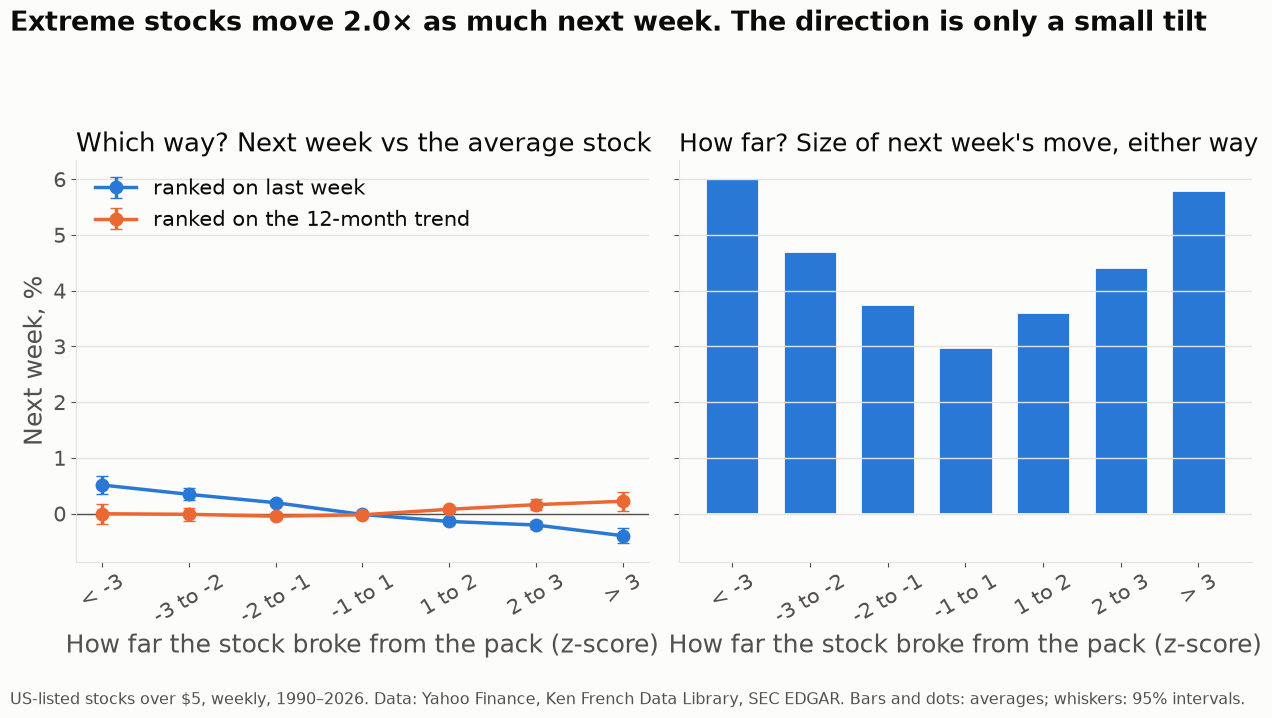

In [41]:
# ---- 01: size, not direction (the hook)
_d = dose.query("period == 'full'")
_size = _d.query("lookback == '1w' and measure == 'size of move'").set_index("bin").reindex(BIN_LABELS)
_big = _size.loc[["< -3", "> 3"], "mean_pct"].mean()
_typ = _size.loc["-1 to 1", "mean_pct"]
with plt.rc_context(CAM_RC):
    fig, axes = plt.subplots(1, 2, sharey=True)
    x = np.arange(len(BIN_LABELS))
    for lb, col, lab in [("1w", SERIES[0], "ranked on last week"), ("12-1", SERIES[1], "ranked on the 12-month trend")]:
        s = _d.query("lookback == @lb and measure == 'direction'").set_index("bin").reindex(BIN_LABELS)
        axes[0].errorbar(x, s["mean_pct"], yerr=1.96 * s["se_pct"], color=col, marker="o", ms=9, capsize=4, label=lab)
    axes[0].axhline(0, color=INK2, lw=1)
    axes[1].bar(x, _size["mean_pct"], color=SERIES[0], width=0.7, edgecolor=SURFACE, linewidth=2)
    axes[0].set_title("Which way? Next week vs the average stock", fontsize=19, fontweight="normal")
    axes[1].set_title("How far? Size of next week's move, either way", fontsize=19, fontweight="normal")
    axes[0].set_ylabel("Next week, %")
    for ax in axes:
        ax.set_xticks(x); ax.set_xticklabels(BIN_LABELS, rotation=30)
        ax.set_xlabel("How far the stock broke from the pack (z-score)")
    axes[0].legend(loc="upper left")
    fig.suptitle(f"Extreme stocks move {_big / _typ:.1f}× as much next week. The direction is only a small tilt",
                 x=0.01, ha="left", fontsize=24, fontweight="bold")
    cam_save(fig, "01_size_not_direction.png", note=CAM_NOTE + " Bars and dots: averages; whiskers: 95% intervals.", top=0.92)

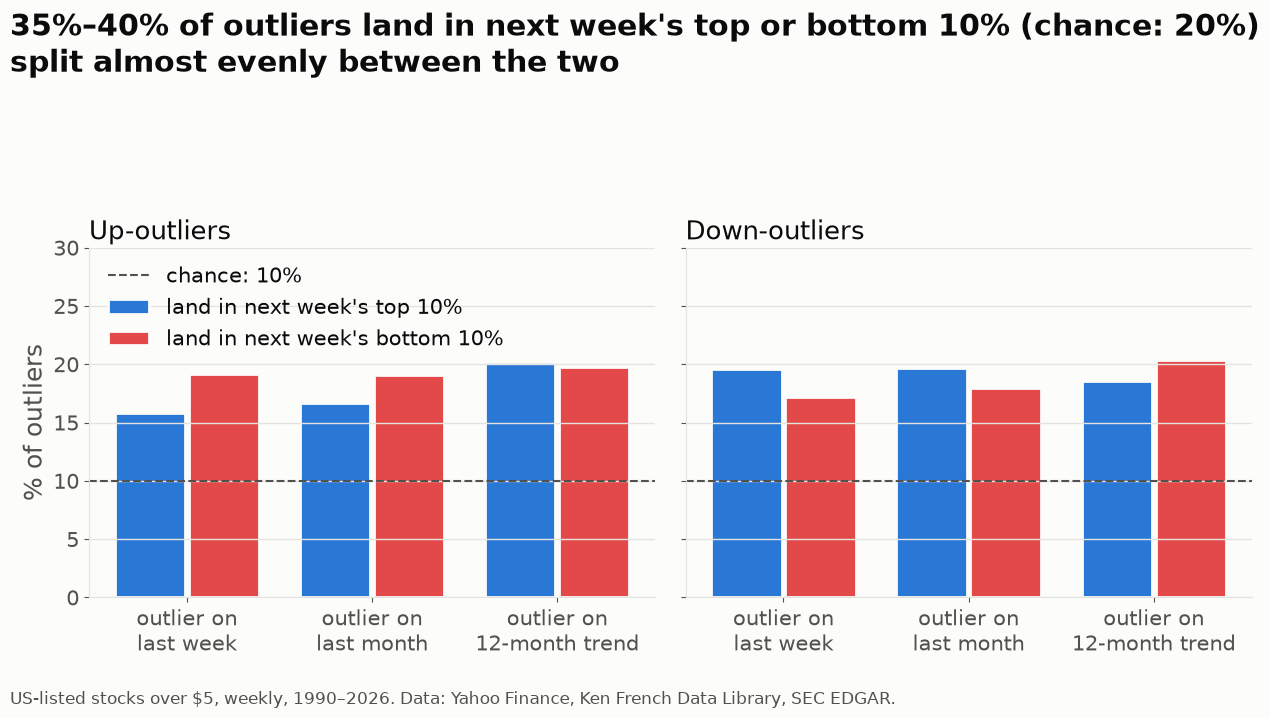

In [42]:
# ---- 02: hit rates (outliers land in both tails)
_h = hits_bh.query("component == 'total' and period == 'full' and lookback in @MAIN_LBS")
_either = _h["share_next_either"]
with plt.rc_context(CAM_RC):
    fig, axes = plt.subplots(1, 2, sharey=True)
    for ax, side in zip(axes, ["up", "down"]):
        s = _h[_h.side == side].set_index("lookback").reindex(MAIN_LBS)
        x = np.arange(len(s))
        ax.bar(x - 0.2, s["share_next_top10"] * 100, 0.38, color=POS, edgecolor=SURFACE, linewidth=2,
               label="land in next week's top 10%")
        ax.bar(x + 0.2, s["share_next_bottom10"] * 100, 0.38, color=NEG, edgecolor=SURFACE, linewidth=2,
               label="land in next week's bottom 10%")
        ax.axhline(10, color=INK2, ls="--", lw=1.5, label="chance: 10%")     # v4.1: in the legend, not on the bars
        ax.set_xticks(x); ax.set_xticklabels([f"outlier on\n{LB_NAMES[l]}" for l in s.index])
        ax.set_title(f"{side.capitalize()}-outliers", fontsize=19, fontweight="normal")
        ax.set_ylim(0, 30)
    axes[0].set_ylabel("% of outliers")
    axes[0].legend(loc="upper left")
    fig.suptitle(f"{_either.min():.0%}–{_either.max():.0%} of outliers land in next week's top or bottom 10% "
                 "(chance: 20%)\nsplit almost evenly between the two", x=0.01, ha="left", fontsize=22, fontweight="bold")
    cam_save(fig, "02_hit_rates.png", note=CAM_NOTE, top=0.86)

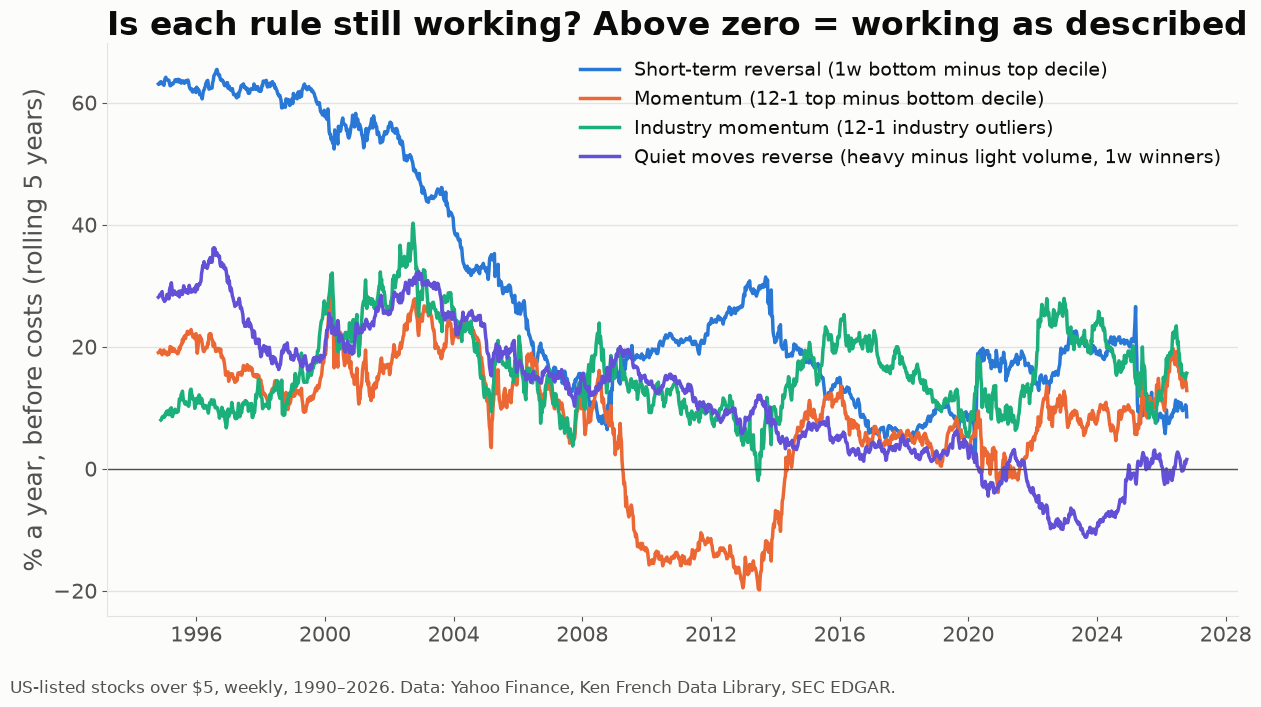

In [43]:
# ---- 03: is each rule still working? (rolling 5 years, from section 22)
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    for (k, v), col in zip(ROLL.items(), SERIES):
        ax.plot(v.index, v.values, color=col, label=k)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_ylabel("% a year, before costs (rolling 5 years)")
    ax.set_title("Is each rule still working? Above zero = working as described")
    ax.legend(loc="upper right", fontsize=14)
    cam_save(fig, "03_is_it_still_working.png", note=CAM_NOTE)

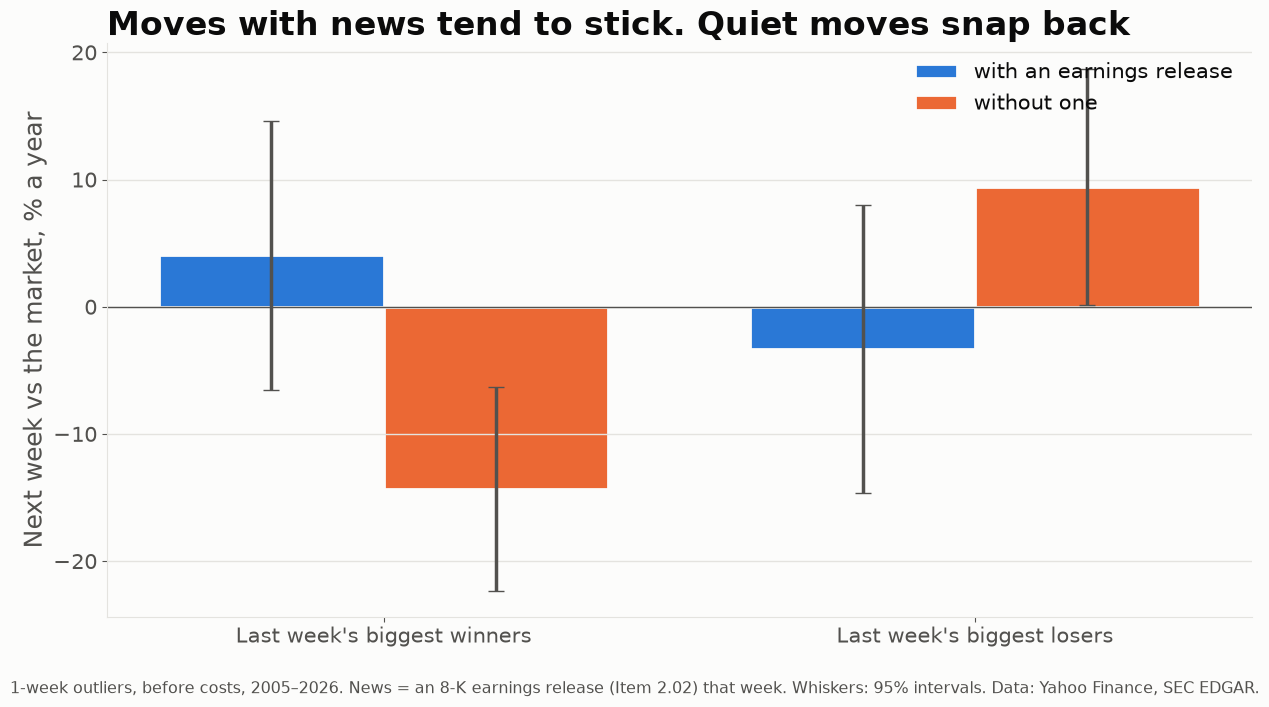

In [44]:
# ---- 04: news vs no news (Chan 2003)
_cat = "earnings 8-K" if (NEWS and NEWS_OK) else "abnormal volume"
_n = news_res.query("lookback == '1w' and category == @_cat and hold == 1 and period == 'full'").set_index("leg")
_with = "with an earnings release" if _cat == "earnings 8-K" else "on heavy volume"
_without = "without one" if _cat == "earnings 8-K" else "on light volume"
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    x = np.arange(2)
    for j, (suffix, col, lab) in enumerate([("with", SERIES[0], _with), ("without", SERIES[1], _without)]):
        g = np.array([_n.loc[f"{side}, {suffix}", "gross_ann"] for side in ["up", "down"]]) * 100
        t = np.array([_n.loc[f"{side}, {suffix}", "t_gross"] for side in ["up", "down"]])
        err = 1.96 * np.abs(g / t)
        ax.bar(x + (j - 0.5) * 0.38, g, 0.38, yerr=err, capsize=6, color=col, edgecolor=SURFACE, linewidth=2,
               error_kw={"ecolor": INK2}, label=lab)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(x); ax.set_xticklabels(["Last week's biggest winners", "Last week's biggest losers"])
    ax.set_ylabel("Next week vs the market, % a year")
    ax.set_title("Moves with news tend to stick. Quiet moves snap back")
    ax.legend(loc="upper right")
    _y0 = NEWS_FROM.year if _cat == "earnings 8-K" else weeks[0].year
    cam_save(fig, "04_news_vs_no_news.png",
             note=f"1-week outliers, before costs, {_y0}–{weeks[-1].year}. News = an 8-K earnings release (Item 2.02) "
                  "that week. Whiskers: 95% intervals. Data: Yahoo Finance, SEC EDGAR.")

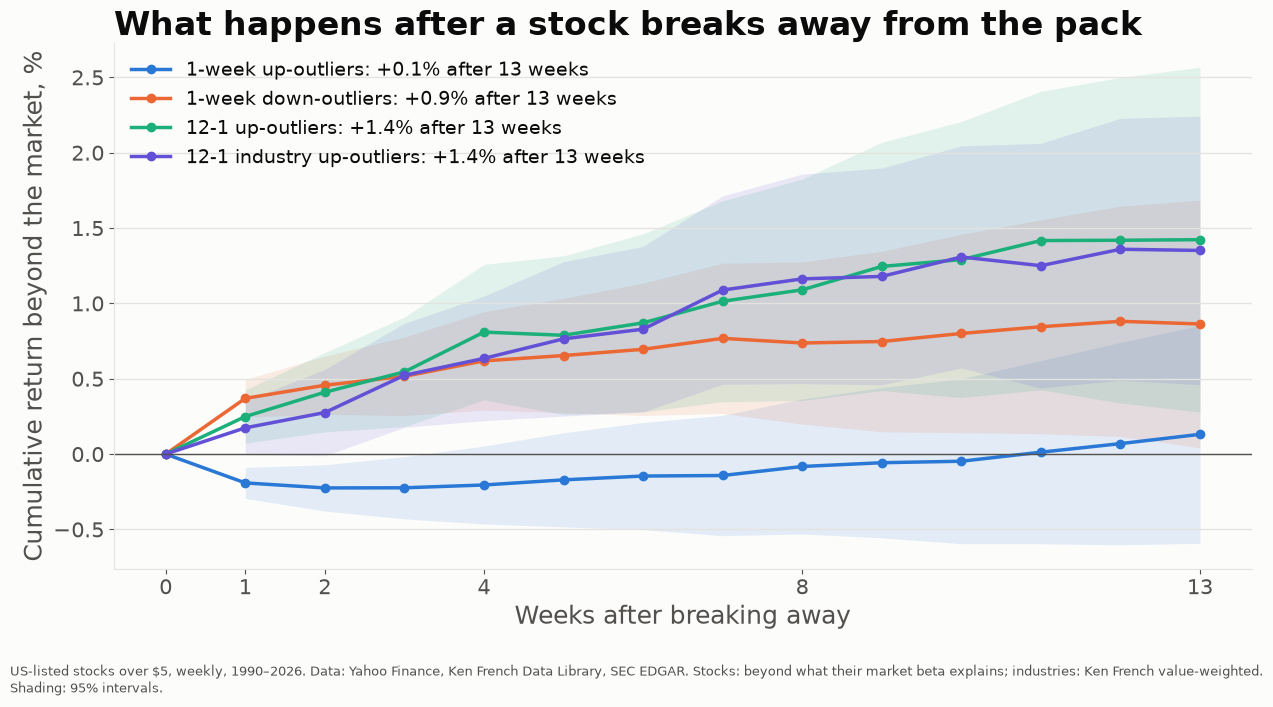

In [45]:
# ---- 05: what happens after entry (13 weeks)
_ev = {"1-week up-outliers": (MEMBERS["1w up"], E), "1-week down-outliers": (MEMBERS["1w down"], E),
       "12-1 up-outliers": (MEMBERS["12-1 up"], E), "12-1 industry up-outliers": (IND_Z["12-1"] > Z_IND, AR_ind)}
_evp = {k: event_path(m, A, pre=1, post=13) for k, (m, A) in _ev.items()}
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    for (k, (path, se, n)), col in zip(_evp.items(), SERIES):
        ax.plot(path.index, path.values * 100, color=col, marker="o", ms=6,
                label=f"{k}: {path.iloc[-1] * 100:+.1f}% after 13 weeks")
        post = path.loc[1:]
        ax.fill_between(post.index, (post - 1.96 * se) * 100, (post + 1.96 * se) * 100, color=col, alpha=0.12, lw=0)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks([0, 1, 2, 4, 8, 13])
    ax.set_xlabel("Weeks after breaking away"); ax.set_ylabel("Cumulative return beyond the market, %")
    ax.set_title("What happens after a stock breaks away from the pack")
    ax.legend(loc="best", fontsize=14)
    cam_save(fig, "05_after_entry.png",
             note=CAM_NOTE + " Stocks: beyond what their market beta explains; industries: Ken French value-weighted. "
                  "Shading: 95% intervals.")

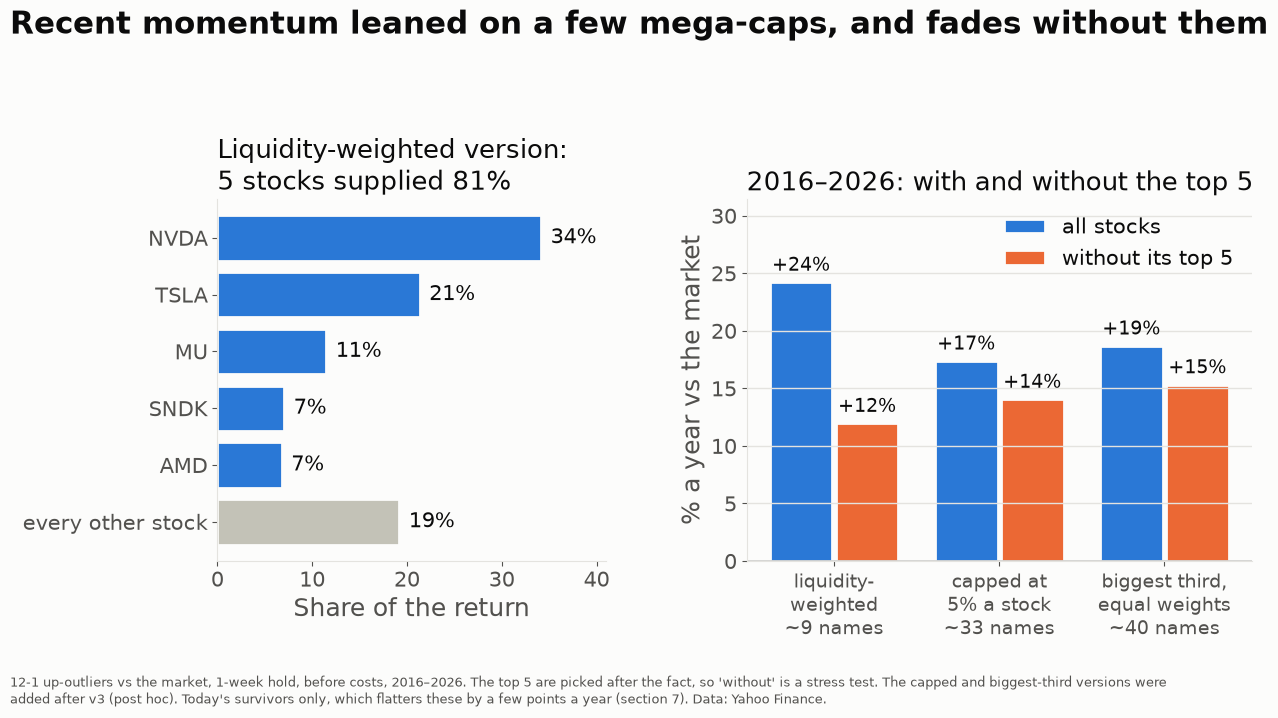

In [46]:
# ---- 06: recent big-stock momentum leaned on a few names, but does it survive without them? (14b)
# v4.1: titled around the v4 result (it survives without the top 5 when spread out), effective names under each bar,
# bar values printed, and labels that no longer overlap.
_tc = TOP_CONTRIB[("12-1 up-outliers", "lw")]
_ct = conc_tab[conc_tab.strategy == "12-1 up-outliers"].set_index("weighting")
_share5 = _tc["share_of_total"].sum()
_sch = list(CONC_SCHEMES.values())
_div = _ct.loc[CONC_SCHEMES["t3"]]                        # the most spread-out big-stock version
_survives = bool(_div["gross without top 5"] > 0 and _div["t without"] >= 2)
_tick = {CONC_SCHEMES["lw"]: "liquidity-\nweighted", CONC_SCHEMES["lwcap"]: f"capped at\n{LW_CAP:.0%} a stock",
         CONC_SCHEMES["t3"]: "biggest third,\nequal weights"}
with plt.rc_context(CAM_RC):
    fig, axes = plt.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.3]})
    shares = list(_tc["share_of_total"] * 100) + [100 - _share5 * 100]
    labels = list(_tc.index) + ["every other stock"]
    y = np.arange(len(shares))[::-1]
    axes[0].barh(y, shares, color=[SERIES[0]] * len(_tc) + [MUTED], edgecolor=SURFACE, linewidth=2)
    for yy, v in zip(y, shares):
        axes[0].text(v + 1, yy, f"{v:.0f}%", va="center", fontsize=15, color=INK)
    axes[0].set_yticks(y); axes[0].set_yticklabels(labels)
    axes[0].set_xlim(0, max(shares) * 1.2)
    axes[0].set_xlabel("Share of the return")
    axes[0].set_title(f"Liquidity-weighted version:\n5 stocks supplied {_share5:.0%}", fontsize=19, fontweight="normal")
    axes[0].grid(False)

    xx = np.arange(len(_sch))
    w_ = _ct.reindex(_sch)
    _all_vals = []
    for off, col_, lab, colr in [(-0.2, "gross, last 10y", "all stocks", SERIES[0]),
                                 (0.2, "gross without top 5", "without its top 5", SERIES[1])]:
        vals = w_[col_].to_numpy(dtype=float) * 100
        _all_vals += list(vals)
        axes[1].bar(xx + off, vals, 0.38, color=colr, edgecolor=SURFACE, linewidth=2, label=lab)
        for x_, v in zip(xx + off, vals):
            axes[1].text(x_, v + (0.6 if v >= 0 else -0.6), f"{v:+.0f}%", ha="center",
                         va="bottom" if v >= 0 else "top", fontsize=14, color=INK)
    axes[1].axhline(0, color=INK2, lw=1)
    axes[1].set_ylim(min(0, min(_all_vals) * 1.3), max(_all_vals) * 1.3)
    axes[1].set_xticks(xx)
    axes[1].set_xticklabels([f"{_tick.get(s_, s_)}\n~{w_.loc[s_, 'avg effective names']:.0f} names" for s_ in _sch],
                            fontsize=14)
    axes[1].set_ylabel("% a year vs the market")
    axes[1].set_title(f"{RECENT_START.year}–{weeks[-1].year}: with and without the top 5", fontsize=19,
                      fontweight="normal")
    axes[1].legend(loc="upper right")
    fig.suptitle("Recent momentum leaned on a few mega-caps, "
                 + ("but survives without them" if _survives else "and fades without them"),
                 x=0.01, ha="left", fontsize=24, fontweight="bold")
    cam_save(fig, "06_concentration.png", top=0.92, w_pad=3,
             note=(f"12-1 up-outliers vs the market, 1-week hold, before costs, {RECENT_START.year}–{weeks[-1].year}. "
                   "The top 5 are picked after the fact, so 'without' is a stress test. The capped and biggest-third "
                   "versions were added after v3 (post hoc). Today's survivors only, which flatters these by a few "
                   "points a year (section 7). Data: Yahoo Finance."))

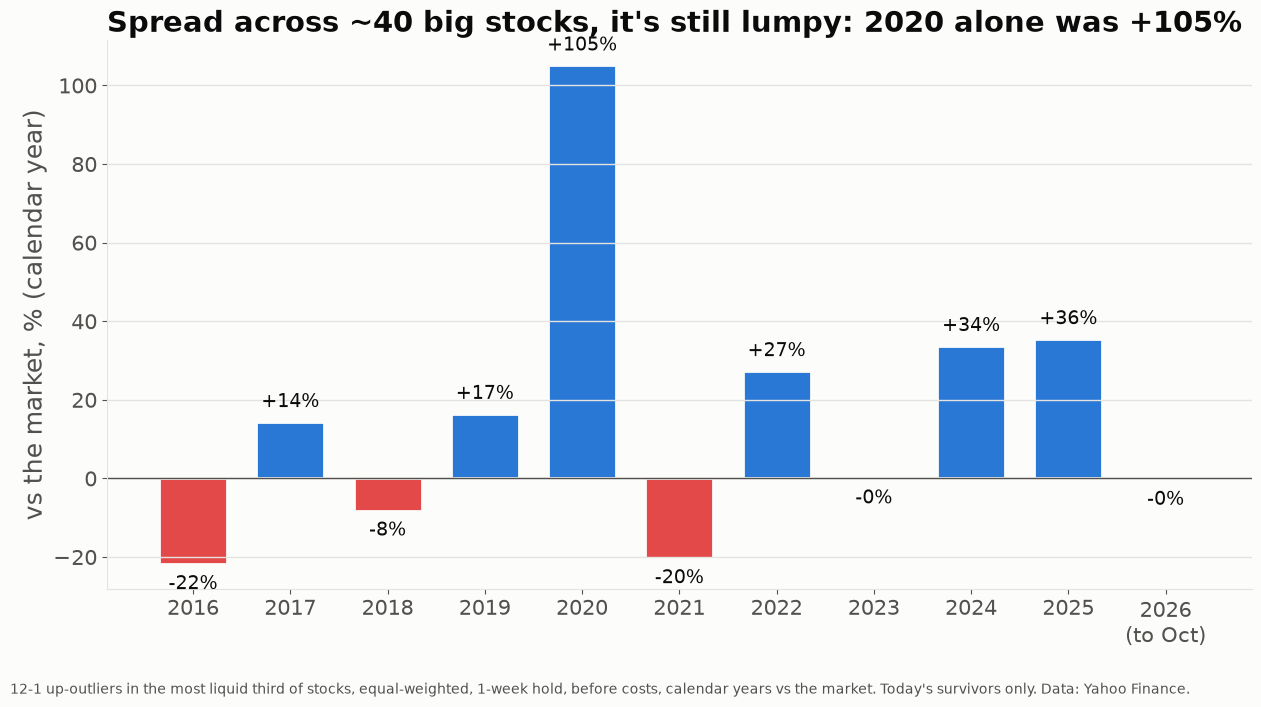

In [47]:
# ---- 06b (new in v4.1): spread out is not the same as smooth. Big-stock momentum year by year (14b)
_yr = yr_tab["12-1 up-outliers | top third EW"].loc[RECENT_START.year:].dropna() * 100
_best = int(_yr.idxmax())
_neff = conc_tab.query("strategy == '12-1 up-outliers'").set_index("weighting").loc[
    CONC_SCHEMES["t3"], "avg effective names"]
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    x = np.arange(len(_yr))
    ax.bar(x, _yr.values, color=[POS if v >= 0 else NEG for v in _yr.values], width=0.7, edgecolor=SURFACE,
           linewidth=2)
    _pad = 0.02 * (_yr.max() - min(_yr.min(), 0))
    for x_, v in zip(x, _yr.values):
        ax.text(x_, v + (_pad if v >= 0 else -_pad), f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top",
                fontsize=14, color=INK)
    ax.axhline(0, color=INK2, lw=1)
    _labs = [str(y_) for y_ in _yr.index]
    if weeks[-1].month < 12:
        _labs[-1] += f"\n(to {weeks[-1]:%b})"
    ax.set_xticks(x); ax.set_xticklabels(_labs)
    ax.set_ylabel("vs the market, % (calendar year)")
    ax.set_title(f"Spread across ~{_neff:.0f} big stocks, it's still lumpy: {_best} alone was {_yr.loc[_best]:+.0f}%")
    cam_save(fig, "06b_big_stock_years.png",
             note="12-1 up-outliers in the most liquid third of stocks, equal-weighted, 1-week hold, before costs, "
                  "calendar years vs the market. Today's survivors only. Data: Yahoo Finance.")

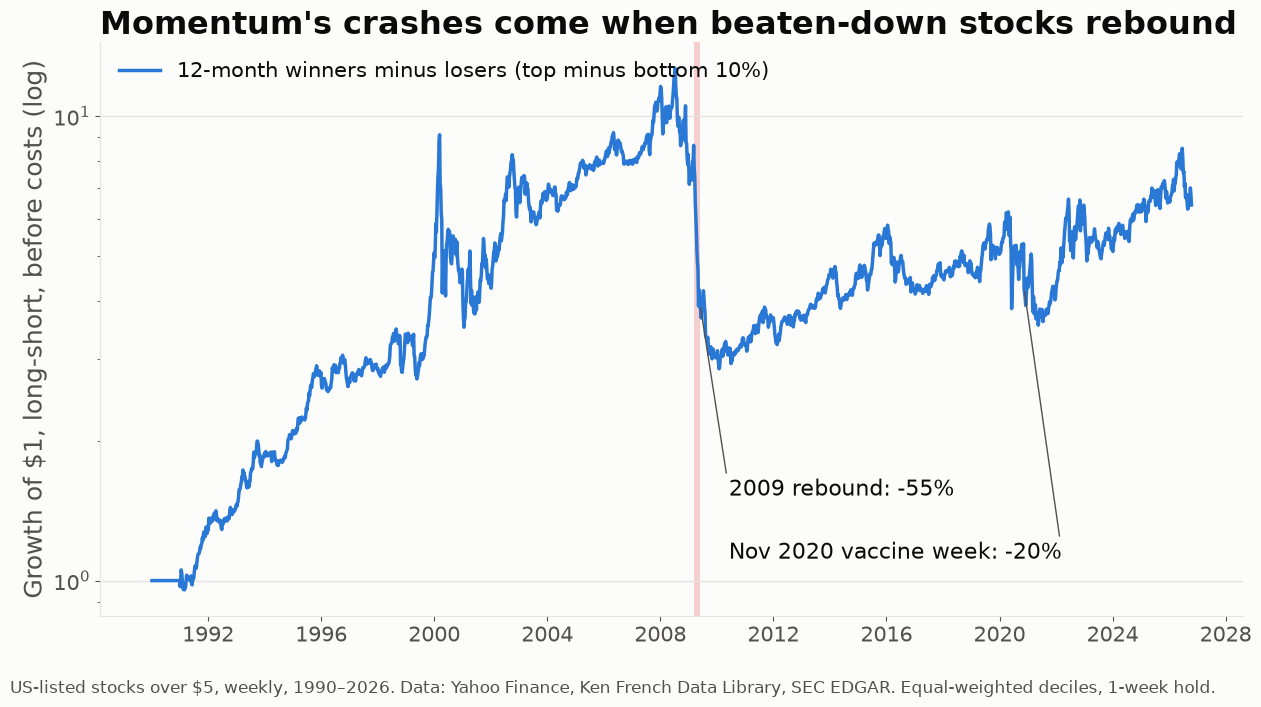

In [48]:
# ---- 07: momentum crashes
_g = strat("12-1 top minus bottom decile", 1)[0]["gross"].fillna(0)
_lvl = (1 + _g).cumprod()
CRASH_SHOW = {"2009 rebound": EPISODES["2009 rebound (Mar 6 – May 29)"],
              "Nov 2020 vaccine week": EPISODES["Nov 2020 vaccine week"]}
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    ax.plot(_lvl.index, _lvl.values, color=SERIES[0], label="12-month winners minus losers (top minus bottom 10%)")
    ax.set_yscale("log")
    # v4.1: labels sit in the empty lower-right corner (axes fractions) so they never cover the line
    for (lab, (a, b)), ypos, rel in zip(CRASH_SHOW.items(), [0.22, 0.11], [(0, 0.5), (1, 0.5)]):
        r = window_ret(_g, a, b)
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=3), color=NEG, alpha=0.25, lw=0)
        ax.annotate(f"{lab}: {r:+.0%}", xy=(pd.Timestamp(b), _lvl.loc[:b].iloc[-1]), xytext=(0.55, ypos),
                    textcoords="axes fraction", fontsize=16, color=INK, va="center",
                    arrowprops={"arrowstyle": "-", "color": INK2, "relpos": rel})
    ax.set_ylabel("Growth of $1, long-short, before costs (log)")
    ax.set_title("Momentum's crashes come when beaten-down stocks rebound")
    ax.legend(loc="upper left")
    cam_save(fig, "07_momentum_crashes.png", note=CAM_NOTE + " Equal-weighted deciles, 1-week hold.")

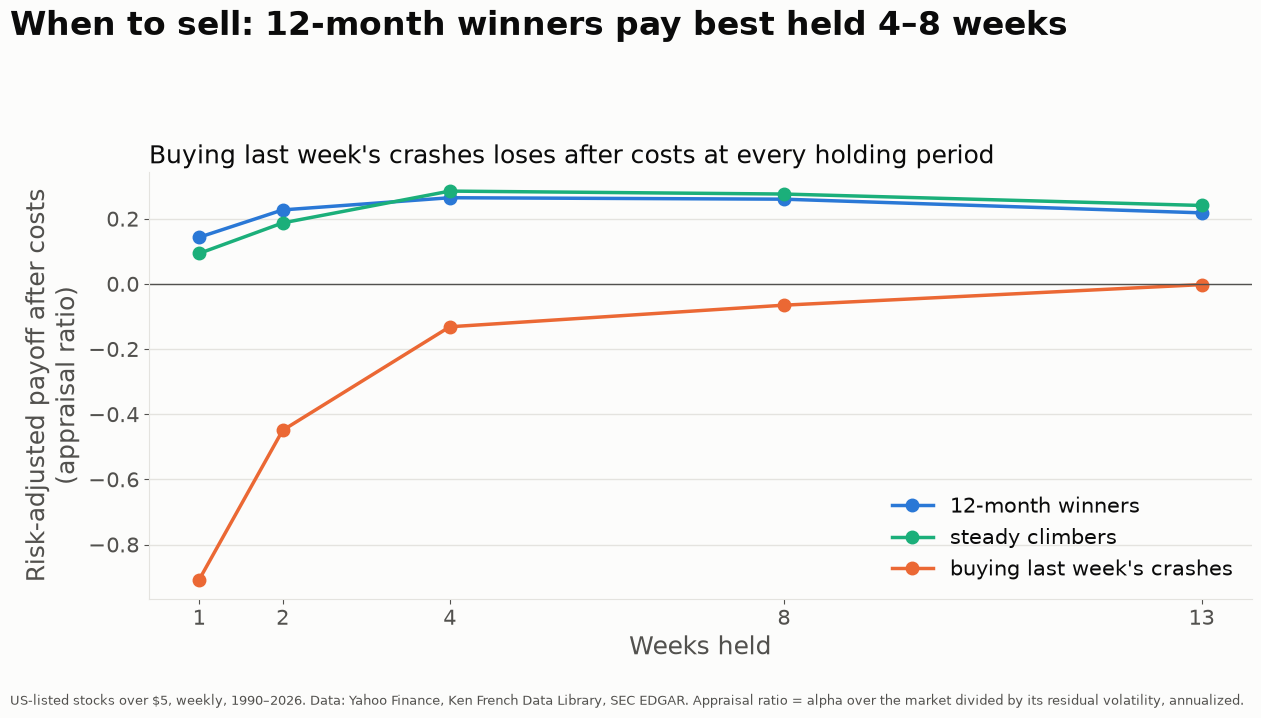

In [49]:
# ---- 08: when to sell (appraisal ratio by holding period, after estimated costs)
HP_SHOW = [("12-1 up-outliers", SERIES[0], "12-month winners"), ("Steady climbers", SERIES[2], "steady climbers"),
           ("1w down-outliers (buy last week's crashes)", SERIES[1], "buying last week's crashes")]
_hp = hp.query("period == 'full'")
_s12 = _hp.query("strategy == '12-1 up-outliers'").set_index("hold")["appraisal_est_cost"]
_crash = _hp[_hp.strategy == "1w down-outliers (buy last week's crashes)"].set_index("hold")["appraisal_est_cost"]

# v4.1: name the range of holds within 5% of the best one (v4 said "about 4 weeks"; 4 and 8 weeks were level)
if _s12.max() > 0:
    _near = _s12[_s12 >= 0.95 * _s12.max()].index
    _lo, _hi = int(_near.min()), int(_near.max())
    ttl = f"When to sell: 12-month winners pay best held {_lo}–{_hi} weeks" if _lo < _hi else \
          f"When to sell: 12-month winners pay best held about {_lo} weeks"
else:
    ttl = "When to sell: 12-month winners don't pay after costs at any holding period"
# ...and say what buying crashes actually does at each hold
_pos = _crash[_crash > 0]
if _pos.empty:
    sub = "Buying last week's crashes loses after costs at every holding period"
elif _crash.max() < 0.1:
    sub = (f"Buying last week's crashes loses after costs unless held {int(_pos.index.min())} weeks, "
           "and then only breaks even")
else:
    sub = f"Buying last week's crashes pays after costs only when held {int(_pos.index.min())} weeks or longer"

with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    for name, col, lab in HP_SHOW:
        s = _hp.query("strategy == @name").set_index("hold")
        ax.plot(s.index, s["appraisal_est_cost"], color=col, marker="o", ms=9, label=lab)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(HOLDS); ax.set_xlabel("Weeks held")
    ax.set_ylabel("Risk-adjusted payoff after costs\n(appraisal ratio)")
    ax.set_title(sub, fontsize=18, fontweight="normal")
    fig.suptitle(ttl, x=0.01, ha="left", fontsize=24, fontweight="bold")
    ax.legend(loc="lower right")
    cam_save(fig, "08_holding_period.png", top=0.91,
             note=CAM_NOTE + " Appraisal ratio = alpha over the market divided by its residual volatility, annualized.")

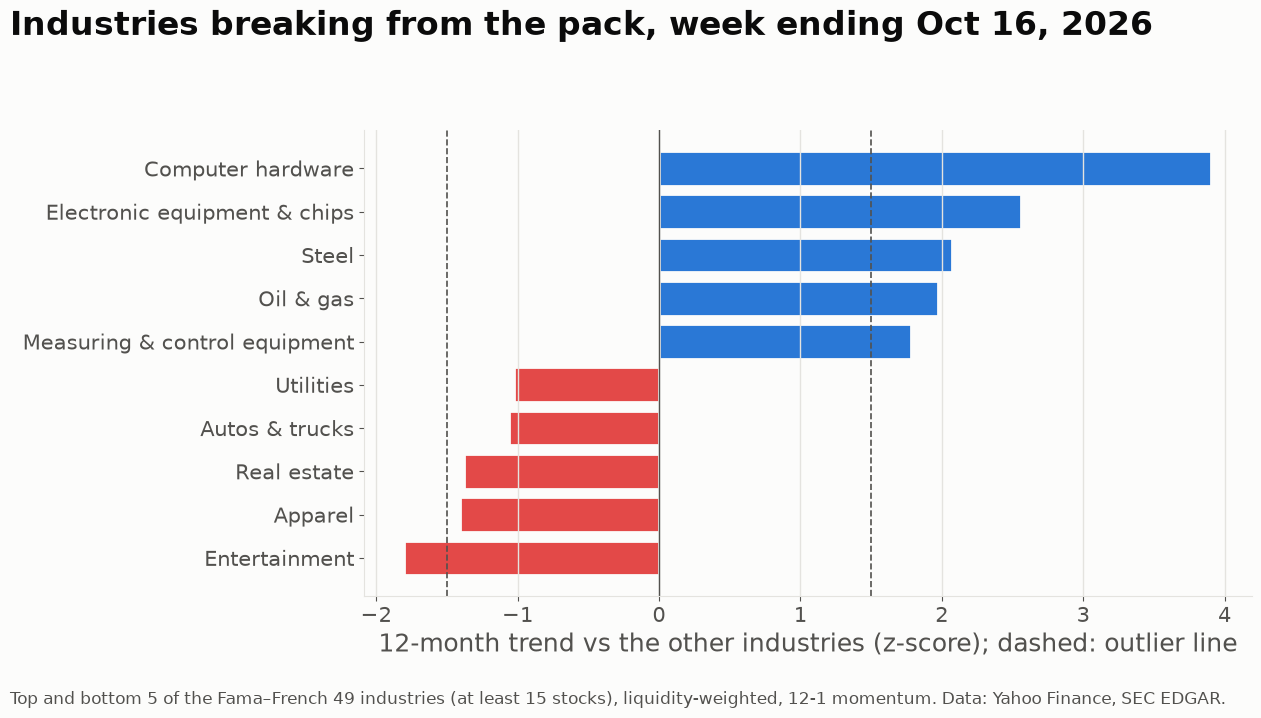

In [50]:
# ---- 09: industries this week (dated; from section 24)
_top = pd.concat([IND_NOW.head(5), IND_NOW.tail(5)])["12-1"].sort_values()
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    y = np.arange(len(_top))
    ax.barh(y, _top.values, color=[POS if v > 0 else NEG for v in _top.values], edgecolor=SURFACE, linewidth=2)
    ax.set_yticks(y); ax.set_yticklabels([FF49_NAMES.get(k, k) for k in _top.index])
    for v in [-Z_IND, Z_IND]:
        ax.axvline(v, color=INK2, ls="--", lw=1.2)
    ax.axvline(0, color=INK2, lw=1)
    ax.grid(False); ax.xaxis.grid(True, color=GRID)
    ax.set_xlabel("12-month trend vs the other industries (z-score); dashed: outlier line")
    # v4.1: a figure title starts at the left edge, so the date has the full width (v4's axes title lost it)
    fig.suptitle(f"Industries breaking from the pack, week ending {d_label}", x=0.01, ha="left", fontsize=24,
                 fontweight="bold")
    cam_save(fig, "09_industries_now.png", top=0.93,
             note=f"Top and bottom 5 of the Fama–French 49 industries (at least {MIN_IND_STOCKS} stocks), liquidity-weighted, "
                  "12-1 momentum. Data: Yahoo Finance, SEC EDGAR.")

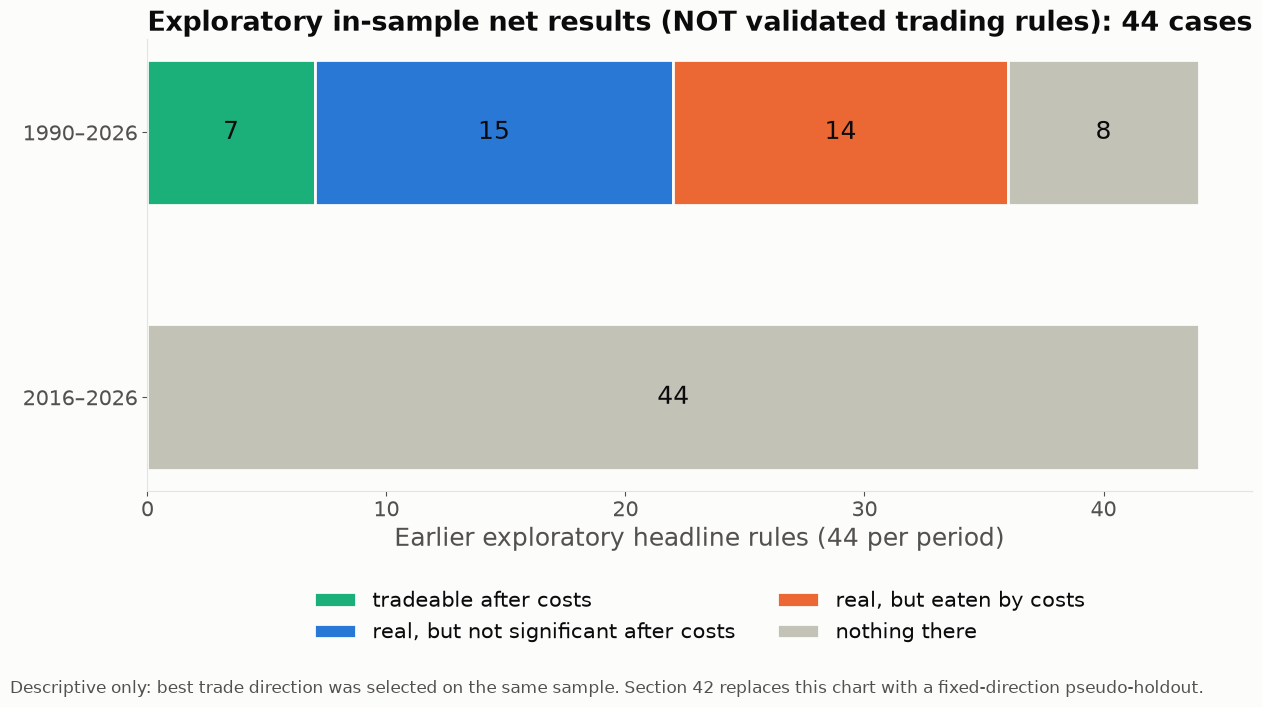

Camera figures: 01_size_not_direction.png, 02_hit_rates.png, 03_is_it_still_working.png, 04_news_vs_no_news.png, 05_after_entry.png, 06_concentration.png, 06b_big_stock_years.png, 07_momentum_crashes.png, 08_holding_period.png, 09_industries_now.png, 10_scoreboard.png, thread_NVDA.png, thread_NVDA_from_2016.png


In [51]:
# ---- 10: IN-SAMPLE exploratory headline scorecard (21a); section 42 overwrites this camera file using fixed directions
VERDICT_ORDER = [("tradeable after costs", SERIES[2]), ("real, but not significant after costs", SERIES[0]),
                 ("real, but eaten by costs", SERIES[1]), ("nothing there", MUTED)]
_cnt = pd.crosstab(headline.period, headline.verdict).reindex(index=["full", "recent"],
                                                              columns=[v for v, _ in VERDICT_ORDER], fill_value=0)
_plab = {"full": f"{weeks[0].year}–{weeks[-1].year}", "recent": f"{RECENT_START.year}–{weeks[-1].year}"}
with plt.rc_context(CAM_RC):
    fig, ax = plt.subplots()
    y = np.arange(2)[::-1]
    left = np.zeros(2)
    for v, col in VERDICT_ORDER:
        vals = _cnt[v].to_numpy(dtype=float)
        ax.barh(y, vals, left=left, color=col, edgecolor=SURFACE, linewidth=2, height=0.55, label=v)
        for yy, l_, w_ in zip(y, left, vals):
            if w_ >= 2:
                ax.text(l_ + w_ / 2, yy, f"{int(w_)}", ha="center", va="center", fontsize=18, color=INK)
        left += vals
    ax.set_yticks(y); ax.set_yticklabels([_plab[p] for p in _cnt.index])
    ax.set_xlabel(f"Earlier exploratory headline rules ({int(_cnt.loc['full'].sum())} per period)")
    ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    ax.set_title(f"Exploratory in-sample net results (NOT validated trading rules): {int(_cnt.loc['full'].sum())} cases")
    cam_save(fig, "10_scoreboard.png",
             note="Descriptive only: best trade direction was selected on the same sample. Section 42 replaces this chart with a fixed-direction pseudo-holdout.")
print("Camera figures:", ", ".join(sorted(p.name for p in CAM_DIR.glob("*.png"))))

## 26. Consistency checks

In [52]:
checks = {}
checks["1-week signal equals that week's own return (no look-ahead)"] = bool(np.allclose(window_sum(LR, 1, 0).values, LR.values, equal_nan=True))

chk = cohort_portfolio(ELIG, R, 1)
ew_next = R.where(ELIG.shift(1, fill_value=False)).mean(axis=1)
ok = chk["gross"].notna()
checks["portfolio engine matches a direct equal-weighted mean"] = bool(np.allclose(chk.loc[ok, "gross"], ew_next[ok], atol=1e-10))
checks["turnover between 0 and 2"] = bool(chk.loc[ok, "turnover"].between(0, 2 + 1e-9).all())
chk_w = cohort_portfolio(ELIG, R, 1, weights=ELIG.astype(float))
checks["weights=1 reproduces equal weighting"] = bool(np.allclose(chk_w.loc[ok, "gross"], chk.loc[ok, "gross"], atol=1e-10))
chk_s = cohort_portfolio(ELIG, R, 4, R_first=R)
chk_4 = cohort_portfolio(ELIG, R, 4)
ok4 = chk_4["gross"].notna()
checks["skip-a-day engine with R_first = R reproduces the base engine"] = bool(np.allclose(chk_s.loc[ok4, "gross"], chk_4.loc[ok4, "gross"], atol=1e-10))
del chk, chk_w, chk_s, chk_4

checks["robust z is centred every week"] = bool(np.nanmax(np.abs(z1m.median(axis=1).values)) < 1e-6)
ev = int(entries(CATS[STEADY_UP]).values.sum()); mw = int(CATS[STEADY_UP].values.sum())
checks[f"event counts are entries, not member-weeks ({ev:,} entries <= {mw:,} member-weeks)"] = ev <= mw
gs = cats.query("period == 'full' and hold == 1").set_index("category")["names"]
checks[f"steady and jumpy climbers are balanced ({gs[STEADY_UP]:.0f} vs {gs[JUMPY_UP]:.0f} names)"] = bool(
    abs(gs[STEADY_UP] - gs[JUMPY_UP]) <= 0.15 * max(gs[STEADY_UP], gs[JUMPY_UP]))

c = pd.concat([lw_univ, mkt], axis=1).dropna().corr().iloc[0, 1]
checks[f"universe tracks the survivorship-free market (corr {c:.2f} > 0.9)"] = bool(c > 0.9)
def rep_row(lb, leg, univ="filtered", w="equal"):
    m = (rep.lookback == lb) & (rep.universe == univ) & rep.weighting.str.startswith(w) & (rep.leg == leg)
    return rep[m].iloc[0]
r12 = rep_row("12-1", "spread")
checks[f"monthly 12-1 spread (filtered, EW) tracks UMD (corr {r12['corr_with_UMD']:.2f} > 0.8)"] = bool(r12["corr_with_UMD"] > 0.8)
for w in ["equal", "liquidity"]:
    rr = rep_row("12-1", "spread", w=w)
    checks[f"monthly 12-1 spread level matches Ken French ({w}-weighted gap {rr['gap_ann']:+.1%}, |t| {abs(rr['t_gap']):.1f} < 2)"] = bool(abs(rr["t_gap"]) < 2)
gl_loose = rep_row("12-1", "losers", univ="loose")["gap_ann"]
checks[f"loose universe no longer swamped by bad data (12-1 loser gap {gl_loose:+.1%}, under 20%/yr)"] = bool(abs(gl_loose) < 0.2)
print("Survivorship gaps, filtered universe, ours minus Ken French (% per year): "
      + ", ".join(f"{lb} {leg} {rep_row(lb, leg, w=w)['gap_ann']:+.1%} ({'EW' if w == 'equal' else 'LW'})"
                  for lb in ["12-1", "1m"] for leg in ["winners", "losers"] for w in ["equal", "liquidity"]))

fw = fac_w.index[fac_w.index >= weeks[0]]
checks["factor weeks line up with return weeks"] = bool(fw.isin(weeks).mean() > 0.99)
for name, C in COSTS.items():
    cv = C.values[~np.isnan(C.values)]
    checks[f"{name}: costs between the floor and the cap"] = bool(((cv >= COST_FLOOR_BPS / 1e4 - 1e-9) & (cv <= COST_CAP + COMMISSION_BPS / 1e4 + 1e-6)).all())
early, late = cost_year[COST_MODEL].loc[:2000].median(), cost_year[COST_MODEL].loc[weeks[-1].year - RECENT_YEARS:].median()
checks[f"{COST_MODEL}: costs fell after decimalization ({early:.0f} -> {late:.0f} bps)"] = bool(late < early)
top_dec = cost_dec.loc[10, f"{COST_MODEL}, last 3 years"]
bot_dec = cost_dec.loc[1, f"{COST_MODEL}, last 3 years"]
known = {f"{COST_MODEL}: most liquid decile costs under 10 bps in the last 3 years ({top_dec:.1f} bps; daily prices "
         "can't resolve spreads this small, so quote break-even costs)": bool(top_dec < 10)}
checks[f"{COST_MODEL}: least liquid decile costs more than the most liquid ({bot_dec:.1f} vs {top_dec:.1f} bps)"] = bool(bot_dec > top_dec)
prem = cost_diag.query("model == @COST_MODEL and period == 'full'")["outlier premium (x)"].iloc[0]
checks[f"{COST_MODEL}: last week's outliers cost at least as much as the average stock (x{prem:.2f})"] = bool(prem >= 1.0)
if NEWS and NEWS_OK:
    checks[f"about four earnings 8-Ks per stock-year ({per_year:.1f})"] = bool(2.5 <= per_year <= 5.5)

# ---- v4 additions
_wc = formation_weights(MEMBERS["12-1 up"], "lwcap")
_nn = _wc.notna().sum(axis=1)
_ok = _nn > 0
checks["capped weights sum to 1 in every cohort"] = bool(np.allclose(_wc.sum(axis=1)[_ok], 1.0, atol=1e-6))
checks[f"capped weights stay at or under {LW_CAP:.0%} (or 1/n in small cohorts)"] = bool(
    (_wc.max(axis=1)[_ok] <= np.maximum(LW_CAP, 1.0 / _nn[_ok]) + 1e-4).all())
del _wc
checks[f"thread stock {THREAD_TICKER} is in the panel"] = THREAD_TICKER.upper() in LR.columns
checks[f"snapshot week has a full cross-section ({int(ELIG.iloc[i_now].sum()):,} eligible stocks)"] = bool(ELIG.iloc[i_now].sum() > 500)
checks["evergreen table covers four decades"] = bool((evergreen["same sign"].str.contains("of 4")).any())
if UPDATE_PRICES_TO:
    checks[f"panel reaches UPDATE_PRICES_TO (last week {weeks[-1].date()})"] = bool(
        weeks[-1] >= pd.Timestamp(UPDATE_PRICES_TO) - pd.Timedelta(days=7))
    _ew = R.where(ELIG.shift(1, fill_value=False)).mean(axis=1).tail(8)
    checks["no market-wide jump where the update was spliced on (last 8 weeks' average stock within ±25%)"] = bool(
        (_ew.abs() < 0.25).all())

for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
for k, v in known.items():
    print(("PASS  " if v else "KNOWN ") + k)

Survivorship gaps, filtered universe, ours minus Ken French (% per year): 12-1 winners +2.0% (EW), 12-1 winners +5.3% (LW), 12-1 losers +2.8% (EW), 12-1 losers +1.9% (LW), 1m winners +7.2% (EW), 1m winners +7.4% (LW), 1m losers -0.4% (EW), 1m losers -0.1% (LW)
PASS  1-week signal equals that week's own return (no look-ahead)
PASS  portfolio engine matches a direct equal-weighted mean
PASS  turnover between 0 and 2
PASS  weights=1 reproduces equal weighting
PASS  skip-a-day engine with R_first = R reproduces the base engine
PASS  robust z is centred every week
PASS  event counts are entries, not member-weeks (13,269 entries <= 74,014 member-weeks)
PASS  steady and jumpy climbers are balanced (40 vs 42 names)
PASS  universe tracks the survivorship-free market (corr 0.96 > 0.9)
PASS  monthly 12-1 spread (filtered, EW) tracks UMD (corr 0.91 > 0.8)
PASS  monthly 12-1 spread level matches Ken French (equal-weighted gap -0.8%, |t| 0.3 < 2)
PASS  monthly 12-1 spread level matches Ken French (l

## 27. Assumption audit: independent tests, not a retroactive correction to the discovery process

This appendix checks **five different questions**, keeping them separate:

1. **Volatility clustering versus momentum information.** Does an outlier's next-week tail probability exceed the probability for comparably volatile stocks? Coarsened matches plus a week-clustered logistic regression; tail definitions use the *formation-date* universe, not next week's eligibility.
2. **Execution and missing returns.** What changes when weights drift between rebalances, a missing security is not redistributed retrospectively, the first trade waits until the following daily close, turnover uses the *post-return* portfolio, and borrowing costs are nonzero?
3. **Out-of-sample direction.** Select direction using discovery only, apply unchanged to 2016-onward data, and adjust the *holdout* family for multiple tests.
4. **Historical-composition and industry assumptions.** Sensitivity to price/liquidity filters; historical Ken French VW/EW long/short legs and an explicit feasibility grid for industry-portfolio implementation.
5. **Point-in-time true counterfactual (optional).** With externally supplied, permissioned security-level weekly returns **including delistings**, compare a dynamically eligible universe to end-of-sample survivors on the same data and same rule. Without that file, **the magnitude of survivorship bias is unidentifiable** here.

**Leakage note:** The original section 14b used `act_next.notna()` in `formation_weights`; that filter has been removed. Its contribution table still omits unpriced outcomes, so it is **observed-outcome attribution only**, not a fully specified strategy backtest. Neither original Friday-close nor skip-first-day variant proves executable fills at those prices.

**Cache note:** Sections 27-33 need only the already built panel plus Ken French data; they do not trigger their own Yahoo/SEC downloads, except the pre-existing notebook setup. These are *new exploratory robustness checks*, not preregistered tests.

In [53]:
from scipy.special import expit

AUDIT_DIR = OUT_DIR / "assumption_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
RUN_MATCHED_LOGIT = True            # sampled, clustered logistic association test (takes longer than matched bins)
LOGIT_NAMES_PER_WEEK = 100          # deterministic random sample, per formation week; lower if memory constrained
LOGIT_SEED = 20261016
MIN_MATCHED_CONTROLS = 5            # per week and covariate bin
RUN_PIT_PANEL = True                # will skip cleanly if optional point-in-time file is absent
PIT_FILE = DATA_DIR / "pit_weekly_returns.csv"
PIT_FLAT_TRADING_BPS = 10.0
BORROW_SENS_BPS = [0, 100, 300, 800]  # annual borrowing fee for shorted STOCK exposure; scenario, not a forecast
MISSING_RETURN_SHOCKS = {"zero (optimistic)": 0.0, "minus 30%": -0.30, "total loss": -1.0}

print("Audit outputs:", AUDIT_DIR)
print("Date range actually in cached panel:", weeks.min().date(), "through", weeks.max().date())
print("Caveat: existing plot and main-table results use the legacy engine; corrected sensitivity results are below.")

Audit outputs: outputs_v7/assumption_audit
Date range actually in cached panel: 1990-01-05 through 2026-10-16
Caveat: existing plot and main-table results use the legacy engine; corrected sensitivity results are below.


## 28. Volatility clustering: do outliers still predict tails after matching?

The raw 35% versus 20% comparison can arise if certain stocks are consistently volatile, not because an unusually positive or negative *momentum signal* contains extra information. Below, define next week's top/bottom decile **among stocks eligible at signal formation, conditional on a recorded next-week return**. Compare each outlier to *non-outliers in the same week and bins* of previously observed 13-week volatility, liquidity, and price. Missing next returns are **not silently treated as non-events**; section 29 measures them.

Matching can fail when cells are too sparse. We report the share of outliers with a valid match. Estimates are time-series averages of matched weekly percentage-point differences, with HAC/Newey–West uncertainty. Matching is observational and cannot prove causal or independently tradeable predictability. The pooled logistic regression is a separate conditional-association check with standard errors clustered by week.

In [54]:
# Formation-date eligible stocks and *observed* next-week returns: no next-week ELIG filter.
AUDIT_NEXT = R.shift(-1).where(ELIG)
AUDIT_VALID = ELIG & AUDIT_NEXT.notna()
_AUDIT_PCT = AUDIT_NEXT.rank(axis=1, pct=True)
AUDIT_TAILS = {
    "top": (_AUDIT_PCT > 0.9),
    "bottom": (_AUDIT_PCT <= 0.1),
}
AUDIT_TAILS["either"] = AUDIT_TAILS["top"] | AUDIT_TAILS["bottom"]
AUDIT_BASE = {k: v.where(AUDIT_VALID).mean(axis=1) for k, v in AUDIT_TAILS.items()}

# Approximate daily realized volatility from pre-formation daily log returns.
vol13_a = np.sqrt(FW["ss"].rolling(13, min_periods=8).sum() /
                  FW["ndays"].rolling(13, min_periods=8).sum().replace(0, np.nan))
vol52_a = np.sqrt(FW["ss"].rolling(52, min_periods=26).sum() /
                  FW["ndays"].rolling(52, min_periods=26).sum().replace(0, np.nan))

def week_bins(value, n):
    return np.ceil(value.where(ELIG).rank(axis=1, pct=True) * n).clip(1, n).fillna(0).astype("uint8")

VOL_B = week_bins(vol13_a, 5)
DV_B = week_bins(dvol13, 3)
PRICE_B = week_bins(price, 3)
AUDIT_Z = {lb: zscore(lb).where(ELIG) for lb in ("1w", "12-1")}
AUDIT_MEMBER = {(lb, direction): (AUDIT_Z[lb] > Z_OUTLIER if direction == "up"
                                else AUDIT_Z[lb] < -Z_OUTLIER)
                for lb in AUDIT_Z for direction in ("up", "down")}
MATCH_CODES = {
    "volatility only": VOL_B.astype("int32"),
    "volatility + liquidity": ((VOL_B.astype("int32") - 1) * 3 + DV_B).where(
        (VOL_B > 0) & (DV_B > 0), 0),
    "volatility + liquidity + price": ((VOL_B.astype("int32") - 1) * 9 +
                                       (DV_B.astype("int32") - 1) * 3 + PRICE_B).where(
        (VOL_B > 0) & (DV_B > 0) & (PRICE_B > 0), 0),
}

_a_valid = AUDIT_VALID.to_numpy(dtype=bool)
_a_tail = {k: v.fillna(False).to_numpy(dtype=bool) for k, v in AUDIT_TAILS.items()}
_a_member = {key: m.fillna(False).to_numpy(dtype=bool) for key, m in AUDIT_MEMBER.items()}
match_week_rows = []
for matched_on, codes in MATCH_CODES.items():
    C = codes.to_numpy(dtype=np.int32)
    nc = max(int(C.max()), 1) + 1
    for i in range(len(weeks) - 1):
        known = _a_valid[i] & (C[i] > 0)
        if known.sum() < 100:
            continue
        for lb in AUDIT_Z:
            control = known & ~_a_member[(lb, "up")][i] & ~_a_member[(lb, "down")][i]
            ctrl_n = np.bincount(C[i, control], minlength=nc)
            for direction in ("up", "down"):
                member = known & _a_member[(lb, direction)][i]
                matched = member & (ctrl_n[C[i]] >= MIN_MATCHED_CONTROLS)
                n_signal = int(member.sum())
                n_matched = int(matched.sum())
                if n_matched < 5:
                    continue
                for tail, yy in _a_tail.items():
                    ctrl_hits = np.bincount(C[i, control], weights=yy[i, control].astype(float), minlength=nc)
                    ctrl_rate = ctrl_hits / np.maximum(ctrl_n, 1)
                    actual = float(yy[i, matched].mean())
                    expected = float(ctrl_rate[C[i, matched]].mean())
                    match_week_rows.append({
                        "week": weeks[i], "lookback": lb, "direction": direction,
                        "matching": matched_on, "outcome": tail,
                        "n_signal_with_outcome": n_signal, "n_matched": n_matched,
                        "coverage": n_matched / n_signal if n_signal else np.nan,
                        "hit_rate": actual, "matched_control_rate": expected,
                        "difference_pp": (actual - expected) * 100.0,
                        "unconditional_rate": AUDIT_BASE[tail].iloc[i],
                    })
match_week = pd.DataFrame(match_week_rows)
match_week.to_csv(AUDIT_DIR / "volatility_matching_weekly.csv", index=False)
match_summary = []
for keys, dd in match_week.groupby(["lookback", "direction", "matching", "outcome"], sort=False):
    for period in ("full", "discovery", "recent"):
        v = dd.set_index("week").loc[PERIODS[period]]
        if v.empty:
            continue
        fit = nw_mean(v["difference_pp"])
        match_summary.append(dict(zip(("lookback", "direction", "matching", "outcome"), keys),
                                  period=period, weeks=fit["n"],
                                  mean_hit_pct=100 * v["hit_rate"].mean(),
                                  matched_nonoutlier_pct=100 * v["matched_control_rate"].mean(),
                                  delta_pp=fit["mean"], t=fit["t"], p=fit["p"],
                                  mean_coverage=v["coverage"].mean(),
                                  total_matched=int(v["n_matched"].sum())))
match_summary = pd.DataFrame(match_summary)
match_summary["q_bh"] = np.nan
for per, ix in match_summary.groupby("period").groups.items():
    valid_ix = match_summary.loc[ix].index[match_summary.loc[ix, "p"].notna()]
    if len(valid_ix):
        match_summary.loc[valid_ix, "q_bh"] = multipletests(match_summary.loc[valid_ix, "p"], method="fdr_bh")[1]
match_summary.to_csv(AUDIT_DIR / "volatility_matching_summary.csv", index=False)
print("Matched outliers minus controls (percentage points; NW t, BH q). Matching applied within each week:")
display(match_summary.query("period in ['full','recent'] and outcome == 'either'")
        [["period", "lookback", "direction", "matching", "weeks", "delta_pp", "t", "q_bh", "mean_coverage", "total_matched"]]
        .round(3))

missing_rows = []
for (lb, direction), mask in AUDIT_MEMBER.items():
    at_risk = (mask & ELIG).iloc[:-1]
    next_observed = R.shift(-1).notna().iloc[:-1]
    for period, sl in PERIODS.items():
        a = at_risk.loc[sl]
        available = next_observed.reindex(index=a.index, columns=a.columns)
        nm = int(a.to_numpy().sum())
        lost = int((a & ~available).to_numpy().sum())
        missing_rows.append({"lookback": lb, "direction": direction, "period": period,
                             "formation_positions": nm, "no_return_next_week": lost,
                             "fraction_missing": lost / nm if nm else np.nan})
missing_diag = pd.DataFrame(missing_rows)
missing_diag.to_csv(AUDIT_DIR / "next_week_missing_return_rates.csv", index=False)
print("Missing next-week returns among outlier positions (cannot infer delisting losses):")
display(missing_diag.round(4))

Matched outliers minus controls (percentage points; NW t, BH q). Matching applied within each week:


,period,lookback,direction,matching,weeks,delta_pp,t,q_bh,mean_coverage,total_matched
6,full,1w,up,volatility only,1868,5.7690,27.0110,0.0000,1.0000,154426
8,recent,1w,up,volatility only,521,7.4360,17.2940,0.0000,1.0000,67187
15,full,1w,down,volatility only,1866,7.2550,35.3320,0.0000,1.0000,148113
17,recent,1w,down,volatility only,521,7.0660,21.1800,0.0000,1.0000,68687
24,full,12-1,up,volatility only,1868,9.1690,38.6620,0.0000,1.0000,153196
26,recent,12-1,up,volatility only,521,10.2210,21.9900,0.0000,1.0000,66037
33,full,12-1,down,volatility only,1867,7.6170,29.5370,0.0000,1.0000,145202
35,recent,12-1,down,volatility only,521,7.7230,24.2160,0.0000,1.0000,67140
42,full,1w,up,volatility + liquidity,1868,5.6730,26.4510,0.0000,1.0000,154420
44,recent,1w,up,volatility + liquidity,521,7.3300,17.0140,0.0000,1.0000,67187


Missing next-week returns among outlier positions (cannot infer delisting losses):


,lookback,direction,period,formation_positions,no_return_next_week,fraction_missing
0,1w,up,full,154426,0,0.0000
1,1w,up,discovery,87239,0,0.0000
2,1w,up,recent,67187,0,0.0000
3,1w,down,full,148117,0,0.0000
4,1w,down,discovery,79430,0,0.0000
5,1w,down,recent,68687,0,0.0000
6,12-1,up,full,153196,0,0.0000
7,12-1,up,discovery,87159,0,0.0000
8,12-1,up,recent,66037,0,0.0000
9,12-1,down,full,145206,0,0.0000


### 28b. Logistic regression (optional but enabled by default)
The logistic model samples up to `LOGIT_NAMES_PER_WEEK` names uniformly *within each week*, uses only observed formation-date predictors and next-week outcomes, and clusters standard errors by week. Odds ratios are **associations conditional on covariates**, not incremental tradeable Sharpe. Current SEC industry labels are not included in this model because their historical labels may be wrong.

In [55]:
logit_res = pd.DataFrame()
if RUN_MATCHED_LOGIT:
    rng = np.random.default_rng(LOGIT_SEED)
    sample = []
    v13 = vol13_a.to_numpy(dtype=float)
    dv = dvol13.to_numpy(dtype=float)
    pr = price.to_numpy(dtype=float)
    absret = LR.abs().to_numpy(dtype=float)
    for i in range(len(weeks) - 1):
        eligible = _a_valid[i] & (v13[i] > 0) & (dv[i] > 0) & (pr[i] > 0) & np.isfinite(absret[i])
        ix = np.flatnonzero(eligible)
        if len(ix) < 100:
            continue
        take = rng.choice(ix, size=min(LOGIT_NAMES_PER_WEEK, len(ix)), replace=False)
        sample.append(pd.DataFrame({
            "week_num": i,
            "up_1w": _a_member[("1w", "up")][i, take].astype(float),
            "down_1w": _a_member[("1w", "down")][i, take].astype(float),
            "up_12_1": _a_member[("12-1", "up")][i, take].astype(float),
            "down_12_1": _a_member[("12-1", "down")][i, take].astype(float),
            "log_vol": np.log(v13[i, take]),
            "log_dvol": np.log(dv[i, take]),
            "log_price": np.log(pr[i, take]),
            "abs_week_return": absret[i, take],
            "top": _a_tail["top"][i, take].astype(int),
            "bottom": _a_tail["bottom"][i, take].astype(int),
            "either": _a_tail["either"][i, take].astype(int),
        }))
    LOGIT_DATA = pd.concat(sample, ignore_index=True) if sample else pd.DataFrame()
    if not LOGIT_DATA.empty:
        control_names = ["log_vol", "log_dvol", "log_price", "abs_week_return"]
        for name in control_names:
            a, sd = LOGIT_DATA[name].mean(), LOGIT_DATA[name].std()
            LOGIT_DATA[name] = (LOGIT_DATA[name] - a) / (sd if sd > 0 else 1.0)
        outcome_rows = []
        for lb in ("1w", "12-1"):
            f1, f2 = ("up_1w", "down_1w") if lb == "1w" else ("up_12_1", "down_12_1")
            X = sm.add_constant(LOGIT_DATA[[f1, f2] + control_names], has_constant="add")
            for outcome in ("top", "bottom", "either"):
                model = sm.GLM(LOGIT_DATA[outcome], X, family=sm.families.Binomial())
                try:
                    result = model.fit(cov_type="cluster", cov_kwds={"groups": LOGIT_DATA["week_num"]},
                                       maxiter=50, disp=0)
                    for term in (f1, f2):
                        b, se = result.params[term], result.bse[term]
                        outcome_rows.append({
                            "lookback": lb, "outcome": outcome, "indicator": term,
                            "n_stock_weeks_sampled": len(LOGIT_DATA),
                            "n_weeks": LOGIT_DATA["week_num"].nunique(),
                            "odds_ratio": np.exp(b), "OR_lower95": np.exp(b - 1.96 * se),
                            "OR_upper95": np.exp(b + 1.96 * se),
                            "clustered_z": result.tvalues[term], "p": result.pvalues[term]
                        })
                except Exception as ex:
                    print(f"Logistic regression failed for {lb}/{outcome}: {type(ex).__name__}: {ex}")
        logit_res = pd.DataFrame(outcome_rows)
        if not logit_res.empty:
            logit_res["q_bh"] = multipletests(logit_res["p"], method="fdr_bh")[1]
            logit_res.to_csv(AUDIT_DIR / "volatility_adjusted_logit.csv", index=False)
            print("Logistic odds ratios with weekly-clustered uncertainty (controls standardized to 1 SD):")
            display(logit_res.round(3))
    else:
        print("No eligible weeks for clustered logistic regression.")
else:
    print("Pooled logistic regression disabled; matched and week-HAC analyses above still run.")

Logistic odds ratios with weekly-clustered uncertainty (controls standardized to 1 SD):


,lookback,outcome,indicator,n_stock_weeks_sampled,n_weeks,odds_ratio,OR_lower95,OR_upper95,clustered_z,p,q_bh
0,1w,top,up_1w,186800,1868,1.3160,1.2230,1.4160,7.3410,0.0000,0.0000
1,1w,top,down_1w,186800,1868,1.6390,1.5270,1.7580,13.7500,0.0000,0.0000
2,1w,bottom,up_1w,186800,1868,1.6160,1.5090,1.7300,13.7370,0.0000,0.0000
3,1w,bottom,down_1w,186800,1868,1.4480,1.3480,1.5540,10.1980,0.0000,0.0000
4,1w,either,up_1w,186800,1868,1.5840,1.4940,1.6790,15.4450,0.0000,0.0000
5,1w,either,down_1w,186800,1868,1.7060,1.6080,1.8100,17.6710,0.0000,0.0000
6,12-1,top,up_12_1,186800,1868,1.6760,1.5780,1.7810,16.7080,0.0000,0.0000
7,12-1,top,down_12_1,186800,1868,1.3290,1.2450,1.4190,8.5140,0.0000,0.0000
8,12-1,bottom,up_12_1,186800,1868,1.6190,1.5220,1.7220,15.2490,0.0000,0.0000
9,12-1,bottom,down_12_1,186800,1868,1.4360,1.3480,1.5300,11.2350,0.0000,0.0000


## 29. Drift-aware execution and delisting/missing-return stress
The original engine rebalance turnover equals the change in **target weights**, ignoring the weights that drifted after stock returns; it also renormalizes next week's returns over surviving prices, as if missing securities could be removed from holdings after seeing their absence.

This alternative marks to market, rebalances from previous period's **post-return weights**, and leaves unmatched positions in cash instead of retrospectively distributing them. For an unexpectedly missing next return it tests 0%, −30%, and −100% outcomes and liquidates the position into cash after that week. The −30% and −100% policies are **stress scenarios, not estimates of average delisting losses**. They can overstate merger-related missingness while still failing to capture firms omitted from today's universe. All exposures are set from past information only. A fresh portfolio is rebalanced weekly to the legacy overlapping-cohort targets; it does not claim execution at Yahoo close.

The `skip1` scenario uses the existing first-trading-day *market rather than stock* proxy (`R_FIRST`) for a 1-week hold, assuming the actual stock purchase occurs at that first day's close. No order-book, intraday slippage, short availability, ETF replication, or financing assumptions are inferred from Yahoo bars.

In [56]:
def audit_target_weights(member, returns, K=1, weights=None, cap=None):
    """Weekly target weights from formation-date members, averaged over the last K cohorts.
    Does not inspect returns after the formation date; no exclusion based on future returns.
    """
    if K < 1:
        raise ValueError("K must be >= 1")
    member = member.reindex(index=returns.index, columns=returns.columns, fill_value=False).fillna(False)
    Wc = member.to_numpy(dtype="float64", copy=True)
    if weights is not None:
        w = weights.reindex_like(returns).to_numpy(dtype="float64")
        Wc *= np.maximum(np.nan_to_num(w, nan=0.0, posinf=0.0, neginf=0.0), 0.0)
    n = Wc.sum(axis=1)
    np.divide(Wc, n[:, None], out=Wc, where=n[:, None] > 0)
    if cap is not None:
        Wc = cap_weights(Wc, cap)
    targets = np.zeros_like(Wc)
    counts = np.zeros(len(Wc))
    for k in range(1, K + 1):
        targets[k:] += Wc[:-k]
        counts[k:] += (n[:-k] > 0)
    np.divide(targets, np.maximum(counts, 1)[:, None], out=targets)
    return targets


def drift_portfolio(member, returns, K=1, cost=None, flat_bps=0.0, weights=None, cap=None,
                    missing_return=0.0, cash_weekly=None):
    """Weekly rebalanced long-only book with actual pre-trade drift and cash for missing securities.

    Formation at close t; target and full-week return t+1. Uses information through t to decide target.
    When a return is unexpectedly missing during the next week, mark at missing_return (a scenario),
    then liquidate into cash without a sale-cost estimate; this is an assumption, not a true delist feed.
    Previously unpriced stocks cannot be deliberately bought again until a new valid price exists.
    All gross/net figures are approximate period returns, with costs subtracted once in that period.
    """
    if not (-1 <= missing_return <= 0):
        raise ValueError("missing_return must be in [-1, 0]")
    T, N = returns.shape
    W = audit_target_weights(member, returns, K, weights, cap)
    rv = returns.to_numpy(dtype="float64")
    if cash_weekly is None:
        cash = np.zeros(T)
    else:
        cash = cash_weekly.reindex(returns.index).fillna(0).to_numpy(dtype="float64")
    if cost is None:
        cc = np.full((T, N), flat_bps / 1e4)
    else:
        cc = cost.reindex_like(returns).shift(1).to_numpy(dtype="float64")
        fallback = np.nanmedian(cc[np.isfinite(cc)]) if np.isfinite(cc).any() else 0.0
        cc = np.maximum(np.where(np.isfinite(cc), cc, fallback), 0)
    prev_post = np.zeros(N)
    records = []
    live_started = False
    for i in range(T):
        target = W[i].copy()
        if i > 0:
            # It is known by week i-1 close if a stock had no return/last price that week.
            # Do not re-invest in a security with stale price merely because an old K-week cohort contains it.
            target[~np.isfinite(rv[i - 1])] = 0.0  # leftover weight stays in cash
        target[np.abs(target) < 1e-15] = 0.0
        if (target > 0).any():
            live_started = True
        prev_post = np.maximum(prev_post, 0.0)
        turnover = float(np.abs(target - prev_post).sum())
        tcost = float((np.abs(target - prev_post) * cc[i]).sum())
        missing = ~np.isfinite(rv[i]) & (target > 0)
        r_eff = np.where(np.isfinite(rv[i]), rv[i], missing_return)
        r_eff = np.maximum(r_eff, -1.0)
        wcash = max(0.0, 1.0 - target.sum())
        gross = float(np.dot(target, r_eff) + wcash * cash[i])
        post_asset = target * (1 + r_eff)
        post_asset[missing] = 0.0  # assumed liquidated into cash on missing-return week
        if 1 + gross <= 0:
            post_asset[:] = 0.0
        else:
            post_asset /= (1 + gross)
        post_asset = np.maximum(post_asset, 0.0)
        if post_asset.sum() > 1 + 1e-10:
            raise AssertionError("Post-return weights exceed portfolio assets")
        prev_post = post_asset
        records.append((gross if live_started else np.nan,
                        turnover if live_started else np.nan,
                        tcost if live_started else np.nan,
                        int((target > 0).sum()), int(missing.sum()),
                        float(target[missing].sum()), wcash))
    result = pd.DataFrame(records, index=returns.index,
                          columns=["gross", "turnover", "tcost", "names", "missing_names",
                                   "missing_weight", "cash_weight"])
    result["net"] = result["gross"] - result["tcost"]
    return result


def audit_strategy(name, K=1, variant="base", missing_return=0.0, exec_mode="friday_close"):
    """Build a strategy from fixed signals, with drift-aware cost accounting.
    exec_mode='first_daily_close' is only supported for K=1, via original R_FIRST proxy.
    """
    if exec_mode not in ("friday_close", "first_daily_close"):
        raise ValueError(exec_mode)
    if exec_mode == "first_daily_close" and K != 1:
        raise ValueError("First-day close proxy is only implemented for a one-week holding strategy")
    rr = R if exec_mode == "friday_close" else R_FIRST
    a, b = STRATS[name]
    def one(selection):
        sel = MEMBERS[selection]
        kw = {}
        if variant in ("lw", "lwcap"):
            kw["weights"] = dvol13
        if variant == "lwcap":
            kw["cap"] = LW_CAP
        if variant == "t3":
            sel = sel & (LIQ_T == 3)
        elif variant == "xrs":
            sel = sel & ~RSPLIT52
        elif variant not in ("base", "lw", "lwcap"):
            raise ValueError(variant)
        return drift_portfolio(sel, rr, K=K, cost=cost1, cash_weekly=rf,
                               missing_return=missing_return, **kw)
    pa = one(a)
    if b is None:
        return pa, "lo", pa, None
    pb = one(b)
    p = long_short(pa, pb)
    p["missing_names"] = pa["missing_names"] + pb["missing_names"]
    p["missing_weight"] = pa["missing_weight"] + pb["missing_weight"]
    return p, "ls", pa, pb


def active_gross_net(port, kind, direction=1, borrow_bps_year=0, short_book_active=None):
    """Signed active return and net-of-explicit-costs; reversed LO = short stocks / long market.
    Synthetic market-leg execution cost is excluded (reported as optimistic for reverse LO).
    """
    if direction not in (1, -1):
        raise ValueError("Direction must be +1 or -1")
    g = port["gross"] if kind == "ls" else (port["gross"] - mkt.reindex(port.index))
    short_active = (port["names"] > 0) if short_book_active is None else short_book_active
    fee = short_active.astype(float) * borrow_bps_year / 1e4 / 52
    if kind == "lo" and direction == 1:
        fee = fee * 0.0
    return pd.DataFrame({"gross_active": direction * g,
                         "net_active": direction * g - port["tcost"] - fee,
                         "turnover": port["turnover"], "tcost": port["tcost"]}, index=port.index)

In [57]:
# Tests are deliberately independent of Yahoo/SEC and should run even when no live data are downloadable.
_tidx = pd.date_range("2020-01-03", periods=5, freq="W-FRI")
_toy_m = pd.DataFrame(False, index=_tidx, columns=["A", "B"])
_toy_m.loc[_tidx[0:3], :] = True
_toy_r = pd.DataFrame(0.0, index=_tidx, columns=["A", "B"])
_toy_r.loc[_tidx[1], "A"] = 1.0
_toy_legacy = cohort_portfolio(_toy_m, _toy_r, K=1, flat_bps=10)
_toy_fixed = drift_portfolio(_toy_m, _toy_r, K=1, flat_bps=10)
assert np.isclose(_toy_fixed.loc[_tidx[2], "turnover"], 1 / 3, atol=1e-10)
assert np.isclose(_toy_legacy.loc[_tidx[2], "turnover"], 0, atol=1e-10)
assert np.isclose(_toy_fixed.loc[_tidx[1], "gross"], 0.5, atol=1e-10)
_miss_m = _toy_m.copy(); _miss_m[:] = False; _miss_m.loc[_tidx[0], "A"] = True
_miss_r = _toy_r.copy(); _miss_r.loc[_tidx[1], "A"] = np.nan
_miss0 = drift_portfolio(_miss_m, _miss_r, missing_return=0).iloc[1]
_miss30 = drift_portfolio(_miss_m, _miss_r, missing_return=-.3).iloc[1]
_miss100 = drift_portfolio(_miss_m, _miss_r, missing_return=-1).iloc[1]
assert np.isclose(_miss0["gross"], 0)
assert np.isclose(_miss30["gross"], -.3)
assert np.isclose(_miss100["gross"], -1)
assert _miss30["missing_names"] == 1
print("PASS synthetic execution tests: target drift turnover 0 -> 1/3; missing asset outcomes 0%, -30%, -100%.")

AUDIT_TRADES = [
    ("1w down-outliers (buy last week's crashes)", 1, "base"),
    ("1w top minus bottom decile", 1, "base"),
    ("12-1 up-outliers", 1, "base"),
    ("12-1 up-outliers", 4, "base"),
    ("12-1 up-outliers", 1, "lwcap"),
    ("12-1 up minus down", 1, "base"),
    ("12-1 top minus bottom decile", 1, "base"),
    ("Steady climbers", 1, "base"),
]
trade_rows = []
for name, K, variant in AUDIT_TRADES:
    old, k = strat(name, K, variant)
    for shock_name, shock in MISSING_RETURN_SHOCKS.items():
        scenarios = [("Friday close proxy", "friday_close")]
        if K == 1 and shock_name == "zero (optimistic)":
            scenarios += [("first daily close proxy", "first_daily_close")]
        for exec_label, exec_mode in scenarios:
            new, kind, pa, pb = audit_strategy(name, K, variant, shock, exec_mode)
            for period in ("full", "recent"):
                d = new.loc[PERIODS[period]].dropna(subset=["gross"])
                oldd = old.reindex(d.index).dropna(subset=["gross"])
                if d.empty or oldd.empty:
                    continue
                new_a = active_gross_net(d, kind, 1, BORROW_BPS_PER_YEAR)
                old_a = active_gross_net(oldd, k, 1, BORROW_BPS_PER_YEAR)
                delta = (new_a["net_active"] - old_a["net_active"]).dropna()
                di = nw_mean(delta, K)
                trade_rows.append({
                    "strategy": name, "K_weeks": K, "weighting": variant, "period": period,
                    "missing_assumption": shock_name, "execution": exec_label,
                    "strict_gross_active_ann": new_a["gross_active"].mean() * 52,
                    "strict_net_active_ann": new_a["net_active"].mean() * 52,
                    "old_net_active_ann": old_a["net_active"].mean() * 52,
                    "strict_avg_turnover": d["turnover"].mean(),
                    "legacy_avg_turnover": oldd["turnover"].mean(),
                    "strict_missing_positions_per_week": d["missing_names"].mean(),
                    "strict_missing_weight_per_week": d["missing_weight"].mean(),
                    "delta_strict_minus_legacy_net_ann": di["mean"] * 52,
                    "t_delta": di["t"], "p_delta": di["p"],
                    "weeks_for_comparison": di["n"],
                })
trade_sens = pd.DataFrame(trade_rows)
trade_sens.to_csv(AUDIT_DIR / "drift_missing_execution_sensitivity.csv", index=False)
print("Drift-adjusted active strategy returns. Scenarios are sensitivity bounds, NOT delisting-loss estimates:")
display(trade_sens.query("period == 'recent'")
        [["strategy", "K_weeks", "weighting", "missing_assumption", "execution",
          "strict_gross_active_ann", "strict_net_active_ann", "old_net_active_ann",
          "strict_avg_turnover", "legacy_avg_turnover", "strict_missing_weight_per_week"]]
        .round(4))

PASS synthetic execution tests: target drift turnover 0 -> 1/3; missing asset outcomes 0%, -30%, -100%.
Drift-adjusted active strategy returns. Scenarios are sensitivity bounds, NOT delisting-loss estimates:


,strategy,K_weeks,weighting,missing_assumption,execution,strict_gross_active_ann,strict_net_active_ann,old_net_active_ann,strict_avg_turnover,legacy_avg_turnover,strict_missing_weight_per_week
1,1w down-outliers (buy last week's crashes),1,base,zero (optimistic),Friday close proxy,0.0449,-0.1629,-0.1614,1.8033,1.7899,0.0000
3,1w down-outliers (buy last week's crashes),1,base,zero (optimistic),first daily close proxy,0.0485,-0.1589,-0.1614,1.8000,1.7899,0.0000
5,1w down-outliers (buy last week's crashes),1,base,minus 30%,Friday close proxy,0.0449,-0.1629,-0.1614,1.8033,1.7899,0.0000
7,1w down-outliers (buy last week's crashes),1,base,total loss,Friday close proxy,0.0449,-0.1629,-0.1614,1.8033,1.7899,0.0000
9,1w top minus bottom decile,1,base,zero (optimistic),Friday close proxy,-0.1282,-0.5129,-0.5098,3.4139,3.3861,0.0000
11,1w top minus bottom decile,1,base,zero (optimistic),first daily close proxy,-0.1166,-0.5007,-0.5098,3.4079,3.3861,0.0000
13,1w top minus bottom decile,1,base,minus 30%,Friday close proxy,-0.1282,-0.5129,-0.5098,3.4139,3.3861,0.0000
15,1w top minus bottom decile,1,base,total loss,Friday close proxy,-0.1282,-0.5129,-0.5098,3.4139,3.3861,0.0000
17,12-1 up-outliers,1,base,zero (optimistic),Friday close proxy,0.0705,0.0272,0.0294,0.3643,0.3453,0.0000
19,12-1 up-outliers,1,base,zero (optimistic),first daily close proxy,0.0340,-0.0090,0.0294,0.3608,0.3453,0.0000


## 30. Fixed training direction: **one-sided profit tests**, pseudo-holdout 2016 onward

The trade direction is chosen only using returns **before 2016**, then evaluated without changing direction. For the research claim *"net active returns are positive"*, the relevant directional null is `H0: mean net active <= 0`, tested using `scipy.stats.norm.sf(Newey_West_t)`. Keep the **two-sided** p-value separately for the nondirectional null. Perform BH correction over the designated 44 headline rules (and separately the 16 post-hoc large-stock variants) for **each borrow-cost scenario**; **100 bps/year** is the primary assumption and the other settings are descriptive sensitivity checks. Negative strategies must have **large** one-sided positive-return p-values even if their two-sided p-value is near zero.

This corrects the v6 situation where very significant **losing** strategies could lower BH-adjusted q-values for positive strategies in a cost-sensitivity slice. There is no look-ahead direction selection within 2016 onward, but prior research inspection means this is **pseudo** out-of-sample, not prospective or preregistered evidence. The reversed-stock-short direction also has omitted market-leg execution costs and financing.


In [58]:
# Fixed, easy-to-audit pseudo-holdout boundary (not the rolling last-10-years boundary).
OOS_START = pd.Timestamp("2016-01-01")
TRAIN_SL = slice(None, OOS_START - pd.Timedelta(days=1))
TEST_SL = slice(OOS_START, None)
print(f"Chronological split: training before {OOS_START.date()}; test on/after that date.")
print("WARNING: because the researcher has already explored the later dates, this is PSEUDO out-of-sample, not untouched prospective evidence.")

_oos_rows = []
OOS_FAMILIES = {
    "headline_44": [(name, K, variant, label)
                    for name in STRATS for K in (1, 4)
                    for variant, label in (("base", "equal-weighted"), ("lw", "liquidity-weighted"))],
    "posthoc_big_stock_16": [(name, K, variant, label)
                              for name in POST_STRATS for K in (1, 4)
                              for variant, label in POST_VARIANTS],
}
for family, rules in OOS_FAMILIES.items():
    for name, K, variant, vlabel in rules:
            p, kind, long_book, short_book = audit_strategy(name, K, variant, missing_return=0.0)
            g = p["gross"] if kind == "ls" else p["gross"] - mkt.reindex(p.index)
            train = g.loc[TRAIN_SL].dropna()
            test = g.loc[TEST_SL].dropna()
            if len(train) < 104 or len(test) < 104:
                continue
            sign = 1 if train.mean() >= 0 else -1
            # Which STOCK side is short? Reverse LO requires borrowing the selected stock basket.
            if kind == "lo":
                short_active = (long_book["names"] > 0) if sign < 0 else (long_book["names"] > 0) & False
            else:
                short_active = (short_book["names"] > 0) if sign > 0 else (long_book["names"] > 0)
            for borrow in BORROW_SENS_BPS:
                d = active_gross_net(p, kind, sign, borrow, short_book_active=short_active)
                dtr, dte = d.loc[TRAIN_SL].dropna(), d.loc[TEST_SL].dropna()
                if dte.empty:
                    continue
                ni = nw_mean(dte["net_active"], K)
                gg = nw_mean(dte["gross_active"], K)
                cost = dte["tcost"].mean()
                bfee = (short_active.reindex(dte.index).astype(float) * borrow / 1e4 / 52).mean()
                turnover = dte["turnover"].mean()
                _oos_rows.append({
                    "strategy": name, "K_weeks": K, "weighting": vlabel, "kind": kind, "test_family": family,
                    "fixed_train_sign": sign, "train_direction": "as built" if sign == 1 else "reversed",
                    "train_gross_ann": train.mean() * 52,
                    "borrow_bps_per_year": borrow, "train_weeks": len(train), "test_weeks": len(test),
                    "test_gross_active_ann": gg["mean"] * 52,
                    "test_net_active_ann": ni["mean"] * 52,
                    "test_net_t": ni["t"], "test_net_p": ni["p"],
                    "test_net_p_one_sided_positive": float(norm.sf(ni["t"])) if pd.notna(ni["t"]) else np.nan,
                    "test_turnover": turnover,
                    "test_trading_cost_ann": cost * 52,
                    "test_borrow_fee_ann": bfee * 52,
                    "breakeven_oneway_bps_after_borrow":
                        (gg["mean"] - bfee) / turnover * 1e4 if turnover > 0 else np.nan,
                    "test_best_sign_chosen_with_future_gross_ann_INVALID":
                        abs(test.mean()) * 52,
                })
oos = pd.DataFrame(_oos_rows)
if not oos.empty:
    oos["test_net_q_bh_two_sided"] = np.nan
    oos["test_net_q_bh_positive"] = np.nan
    for (family, bps), ix in oos.groupby(["test_family", "borrow_bps_per_year"]).groups.items():
        for input_col, output_col in [
            ("test_net_p", "test_net_q_bh_two_sided"),
            ("test_net_p_one_sided_positive", "test_net_q_bh_positive")]:
            valid = oos.loc[ix].index[oos.loc[ix, input_col].notna()]
            if len(valid):
                oos.loc[valid, output_col] = multipletests(
                    oos.loc[valid, input_col].to_numpy(dtype=float), method="fdr_bh")[1]
    # Legacy column name preserved for downstream compatibility, but now explicitly one-sided.
    oos["test_net_q_bh"] = oos["test_net_q_bh_positive"]
    oos["positive_and_q_lt_005"] = (oos["test_net_active_ann"] > 0) & (oos["test_net_q_bh_positive"] < 0.05)
    # Catch the original failure: very strong losing strategies are not one-sided profit discoveries.
    assert not oos.loc[oos.test_net_t <= 0, "positive_and_q_lt_005"].any()
    oos.to_csv(AUDIT_DIR / "frozen_direction_chronological_split.csv", index=False)
    print("Frozen training direction, recent period (borrow=100 bps/year; q separately for headline 44 and post-hoc 16):")
    display(oos.query("borrow_bps_per_year == 100")
            [["test_family", "strategy", "K_weeks", "weighting", "train_direction", "train_gross_ann",
              "test_gross_active_ann", "test_net_active_ann", "test_net_t", "test_net_p_one_sided_positive", "test_net_q_bh_positive",
              "breakeven_oneway_bps_after_borrow", "positive_and_q_lt_005"]].round(4))
    print("Positive net returns AND one-sided positive-return BH q<0.05 (100 bps/year is primary; others are exploratory):")
    display(oos.groupby(["test_family", "borrow_bps_per_year"])["positive_and_q_lt_005"].agg(["sum", "count"]))
else:
    print("Insufficient data to evaluate the chronological train/test split.")

Chronological split: training before 2016-01-01; test on/after that date.
Frozen training direction, recent period (borrow=100 bps/year; q separately for headline 44 and post-hoc 16):


,test_family,strategy,K_weeks,weighting,train_direction,train_gross_ann,test_gross_active_ann,test_net_active_ann,test_net_t,test_net_p_one_sided_positive,test_net_q_bh_positive,breakeven_oneway_bps_after_borrow,positive_and_q_lt_005
1,headline_44,1w down-outliers (buy last week's crashes),1,equal-weighted,as built,0.3405,0.0302,-0.1698,-2.4293,0.9924,0.9999,3.2252,False
5,headline_44,1w down-outliers (buy last week's crashes),1,liquidity-weighted,as built,0.2607,0.1078,0.0121,0.1505,0.4402,0.9999,11.2147,False
9,headline_44,1w down-outliers (buy last week's crashes),4,equal-weighted,as built,0.1532,0.0251,-0.0301,-0.5924,0.7232,0.9999,9.7836,False
13,headline_44,1w down-outliers (buy last week's crashes),4,liquidity-weighted,as built,0.0810,0.0828,0.0570,0.9986,0.1590,0.7773,31.9372,False
17,headline_44,1w up minus down,1,equal-weighted,reversed,-0.4476,0.1570,-0.2544,-2.7953,0.9974,0.9999,7.8689,False
21,headline_44,1w up minus down,1,liquidity-weighted,reversed,-0.3934,0.0615,-0.1348,-1.1082,0.8661,0.9999,2.6893,False
25,headline_44,1w up minus down,4,equal-weighted,reversed,-0.1409,0.0824,-0.0353,-1.1740,0.8798,0.9999,14.5037,False
29,headline_44,1w up minus down,4,liquidity-weighted,reversed,-0.0766,0.0215,-0.0378,-0.7079,0.7605,0.9999,2.2725,False
33,headline_44,1m down-outliers,1,equal-weighted,as built,0.2849,0.0378,-0.0813,-1.3016,0.9035,0.9999,6.9597,False
37,headline_44,1m down-outliers,1,liquidity-weighted,as built,0.0807,0.0714,0.0124,0.1480,0.4412,0.9999,12.0092,False


Positive net returns AND one-sided positive-return BH q<0.05 (100 bps/year is primary; others are exploratory):


sum  count
test_family          borrow_bps_per_year            
headline_44          0                      0     44
                     100                    0     44
                     300                    0     44
                     800                    0     44
posthoc_big_stock_16 0                      0     16
                     100                    0     16
                     300                    0     16
                     800                    0     16

## 31. Eligibility sensitivity within the *survivor* sample
Re-form signals and portfolios under different historic price and dollar-volume thresholds. These changes can reveal fragility to microcaps and liquidity, but **none can add delisted companies missing from SEC's current ticker list**. These are not different point-in-time universes. The most-liquid-third and 5%-cap variants already appear in sections 14/14b; here we explicitly vary the basic universe selection itself.

In [59]:
_price_floors = [1.0, 5.0, 10.0, 20.0]
_liquidity_cuts = [0.20, 0.50]
sens_rows = []
AUDIT_SIGS = {"1w": signal("1w", "total"), "12-1": signal("12-1", "total")}
for floor in _price_floors:
    for liq in _liquidity_cuts:
        cut = dvol13.where(price >= floor).quantile(liq, axis=1)
        historical_eligible = ((price >= floor) & dvol13.ge(cut, axis=0) &
                               beta.notna() & R.notna())
        z_1w = robust_z(AUDIT_SIGS["1w"], historical_eligible)
        z_12 = robust_z(AUDIT_SIGS["12-1"], historical_eligible)
        w1, l1 = decile_members(AUDIT_SIGS["1w"], historical_eligible & AUDIT_SIGS["1w"].notna())
        w12, l12 = decile_members(AUDIT_SIGS["12-1"], historical_eligible & AUDIT_SIGS["12-1"].notna())
        selections = {
            "last week's losing decile (reversal)": (l1, None),
            "1-week loser minus winner deciles (reversal)": (l1, w1),
            "12-1 momentum winner minus loser deciles": (w12, l12),
            "12-1 up-outliers": (z_12 > Z_OUTLIER, None),
        }
        for test_name, (long_sel, short_sel) in selections.items():
            p1 = drift_portfolio(long_sel, R, cost=cost1, cash_weekly=rf)
            kind = "lo"
            if short_sel is not None:
                p2 = drift_portfolio(short_sel, R, cost=cost1, cash_weekly=rf)
                q = long_short(p1, p2)
                q["missing_weight"] = p1["missing_weight"] + p2["missing_weight"]
                kind = "ls"
            else:
                q = p1
            gross = q["gross"] if kind == "ls" else q["gross"] - mkt.reindex(q.index)
            net = q["net"] if kind == "ls" else q["net"] - mkt.reindex(q.index)
            for per, sl in PERIODS.items():
                g = gross.loc[sl].dropna()
                n = net.loc[sl].dropna()
                t = nw_mean(n)
                sens_rows.append({
                    "test": test_name, "period": per, "price_floor": floor,
                    "dvol_percentile_removed": liq, "median_eligible": historical_eligible.loc[sl].sum(axis=1).median(),
                    "gross_active_ann": g.mean() * 52, "net_active_ann": n.mean() * 52,
                    "net_t": t["t"], "net_p": t["p"], "n_weeks": len(n),
                    "avg_missing_weight": q["missing_weight"].loc[sl].mean(),
                })
elig_sens = pd.DataFrame(sens_rows)
elig_sens.to_csv(AUDIT_DIR / "price_liquidity_universe_sensitivity.csv", index=False)
print("Eligibility sensitivity (note: all cells STILL exclude historical delisted firms):")
display(elig_sens.query("period == 'recent'")
        [["test", "price_floor", "dvol_percentile_removed", "median_eligible",
          "gross_active_ann", "net_active_ann", "net_t", "n_weeks"]].round(3))

Eligibility sensitivity (note: all cells STILL exclude historical delisted firms):


,test,price_floor,dvol_percentile_removed,median_eligible,gross_active_ann,net_active_ann,net_t,n_weeks
2,last week's losing decile (reversal),1.0000,0.2000,"2,592.0000",0.0330,-0.2390,-3.1540,522
5,1-week loser minus winner deciles (reversal),1.0000,0.2000,"2,592.0000",0.1190,-0.4100,-4.5050,522
8,12-1 momentum winner minus loser deciles,1.0000,0.2000,"2,592.0000",0.1000,-0.0070,-0.0880,522
11,12-1 up-outliers,1.0000,0.2000,"2,592.0000",0.0610,0.0040,0.0620,522
14,last week's losing decile (reversal),1.0000,0.5000,"1,660.0000",0.0430,-0.0940,-1.3490,522
17,1-week loser minus winner deciles (reversal),1.0000,0.5000,"1,660.0000",0.1010,-0.1690,-1.8940,522
20,12-1 momentum winner minus loser deciles,1.0000,0.5000,"1,660.0000",0.0700,0.0220,0.2760,522
23,12-1 up-outliers,1.0000,0.5000,"1,660.0000",0.0800,0.0520,0.7320,522
26,last week's losing decile (reversal),5.0000,0.2000,"2,291.0000",0.0270,-0.1670,-2.7640,522
29,1-week loser minus winner deciles (reversal),5.0000,0.2000,"2,291.0000",0.1280,-0.2570,-3.2370,522


## 32. External French comparison and feasibility limits
Ken French's CRSP-based momentum and reversal monthly deciles contain historical listed stocks, and offer much stronger **independent evidence for the existence of a momentum premium** than the present-day SEC universe alone. They still cannot give the specific **counterfactual bias amount** in your weekly current-survivor strategy: portfolios differ in universe, NYSE breakpoints, filtering, cap versus dollar-volume weights, reconstitution, and transaction costs.

Re-report monthly winner/loser/spread gaps separately before and after the frozen split, *without* interpreting those gaps as pure survivorship bias. Independently vary assumed per-side costs and financing for the Ken French 49-industry synthetic value-weighted strategy. These industry-portfolio returns are **not ETF fills** and remain gross research series.

In [60]:
def monthly_legs_no_future_filter(sig, elig, weight=None, missing_return=0.0):
    """Build at t-1, keep all eligible formation weights through t (incl. missing monthly t)."""
    ref_cols = [c for c in nyse_cols if c in sig.columns] if nyse_cols else None
    hi, lo = decile_members(sig, elig & sig.notna(), ref_cols)
    rr = RM.fillna(missing_return)
    legs = {}
    for leg, mask in (("winners", hi), ("losers", lo)):
        ww = mask.astype(float)
        if weight is not None:
            ww *= weight.reindex_like(ww).fillna(0.0).clip(lower=0)
        denom = ww.sum(axis=1).replace(0, np.nan)
        ww = ww.div(denom, axis=0).shift(1)
        legs[leg] = (ww * rr).sum(axis=1).where(ww.sum(axis=1) > 0)
    legs["spread"] = legs["winners"] - legs["losers"]
    return legs

benchmark_rows = []
for lb, (sig, kf_pf, fac, factor_name) in REP_SIGNALS.items():
    for universe_name in ("loose", "filtered"):
        for weighting, weights, kfw in (("equal", None, "EW"), ("dollar-volume", DVM, "VW")):
            legs = monthly_legs_no_future_filter(sig, UNIV_M[universe_name], weights)
            ref = {"winners": kf_pf[kfw].iloc[:, -1], "losers": kf_pf[kfw].iloc[:, 0]}
            ref["spread"] = ref["winners"] - ref["losers"]
            for leg in ("winners", "losers", "spread"):
                d = pd.concat([legs[leg].rename("current_survivors"), ref[leg].rename("French")], axis=1).dropna()
                for period, subset in (("before 2016", d[d.index.to_timestamp() < OOS_START]),
                                       ("2016 onward", d[d.index.to_timestamp() >= OOS_START])):
                    if len(subset) < 24:
                        continue
                    dd = subset["current_survivors"] - subset["French"]
                    fit = nw_mean(dd)
                    benchmark_rows.append({
                        "lookback": lb, "leg": leg, "universe": universe_name,
                        "our_weighting": weighting, "Ken_French_weighting": kfw, "period": period,
                        "months": len(subset), "ours_gross_ann": subset["current_survivors"].mean() * 12,
                        "French_gross_ann": subset["French"].mean() * 12,
                        "gap_NOT_pure_survivorship_ann": dd.mean() * 12,
                        "gap_NW_t": fit["t"], "gap_NW_p": fit["p"],
                        "correlation": subset["current_survivors"].corr(subset["French"]),
                    })
bench = pd.DataFrame(benchmark_rows)
bench.to_csv(AUDIT_DIR / "ken_french_comparison_NOT_bias_estimate.csv", index=False)
print("Ken French decile validation (gaps conflate many methodological differences; NOT bias estimates):")
display(bench.query("universe == 'filtered' and leg == 'spread'")
        [["lookback", "period", "our_weighting", "ours_gross_ann", "French_gross_ann",
          "gap_NOT_pure_survivorship_ann", "gap_NW_t", "correlation", "months"]].round(3))

industry_cost_rows = []
for label, (u, d) in (("12-1 industry z-outliers", IND_PORTS[(f"outlier (|z| > {Z_IND:g})", 1)]),
                      ("12-1 industry quintiles", IND_PORTS[("quintile", 1)])):
    pair = long_short(u, d)
    for period, sl in PERIODS.items():
        if period not in ("full", "recent"):
            continue
        a = pair.loc[sl].dropna(subset=["gross"])
        for one_way_bps in (5, 10, 25, 50):
            for borrow_bps in BORROW_SENS_BPS:
                # No actual tracking ETF: synthetic basket turnover from Ken French portfolio performance series.
                drag = a["turnover"] * one_way_bps / 1e4
                short_fee = (d["names"].reindex(a.index) > 0).astype(float) * borrow_bps / 1e4 / 52
                net = a["gross"] - drag - short_fee
                fit = nw_mean(net)
                industry_cost_rows.append({
                    "strategy": label, "period": period, "per_side_bps": one_way_bps,
                    "annual_short_borrow_bps": borrow_bps,
                    "synthetic_gross_ann": a["gross"].mean() * 52,
                    "synthetic_net_scenario_ann": net.mean() * 52,
                    "net_t": fit["t"], "net_p": fit["p"],
                    "weekly_turnover": a["turnover"].mean(), "weeks": len(a),
                })
industry_cost_grid = pd.DataFrame(industry_cost_rows)
industry_cost_grid.to_csv(AUDIT_DIR / "ken_french_industry_cost_grid_SYNTHETIC.csv", index=False)
print("Industry synthetic-portfolio cost and borrow sensitivity (not ETF replicability):")
display(industry_cost_grid.query("period == 'recent' and annual_short_borrow_bps == 100")
        [["strategy", "per_side_bps", "synthetic_gross_ann", "synthetic_net_scenario_ann", "net_t"]].round(3))

Ken French decile validation (gaps conflate many methodological differences; NOT bias estimates):


,lookback,period,our_weighting,ours_gross_ann,French_gross_ann,gap_NOT_pure_survivorship_ann,gap_NW_t,correlation,months
16,12-1,before 2016,equal,0.0890,0.0700,0.0190,0.5440,0.7310,300
17,12-1,2016 onward,equal,0.0180,0.0900,-0.0720,-1.3300,0.6820,128
22,12-1,before 2016,dollar-volume,0.1340,0.1180,0.0160,0.4240,0.8340,300
23,12-1,2016 onward,dollar-volume,0.1080,0.0310,0.0770,1.5390,0.8830,128
40,1m,before 2016,equal,-0.0620,-0.1680,0.1050,3.6200,0.7380,311
41,1m,2016 onward,equal,-0.0310,-0.0360,0.0050,0.1040,0.7840,128
46,1m,before 2016,dollar-volume,0.1060,0.0040,0.1010,3.3750,0.7870,311
47,1m,2016 onward,dollar-volume,0.0270,0.0170,0.0110,0.2120,0.7970,128


Industry synthetic-portfolio cost and borrow sensitivity (not ETF replicability):


,strategy,per_side_bps,synthetic_gross_ann,synthetic_net_scenario_ann,net_t
17,12-1 industry z-outliers,5,0.1410,0.1040,1.1970
21,12-1 industry z-outliers,10,0.1410,0.0760,0.8830
25,12-1 industry z-outliers,25,0.1410,-0.0060,-0.0640
29,12-1 industry z-outliers,50,0.1410,-0.1420,-1.6500
49,12-1 industry quintiles,5,0.0660,0.0440,0.8760
53,12-1 industry quintiles,10,0.0660,0.0310,0.6290
57,12-1 industry quintiles,25,0.0660,-0.0060,-0.1110
61,12-1 industry quintiles,50,0.0660,-0.0670,-1.3450


## 33. Historical security selection (legacy section, superseded in v6)

The earlier optional comparison accepted a final-week observation as a proxy for surviving to the end of the dataset and covered only strategy returns. **That can misclassify halted or temporarily nontrading securities and misses the main outlier probability question.** It is disabled in v6.

Use **sections 37–39** for a strict point-in-time input contract, verified terminal returns and end-date survivor membership, paired extreme-move probability comparisons, and an optional aggregate video figure. Missing licensed data yields a transparent skip, not an estimate.

In [61]:
pit_bias = pd.DataFrame()
print('Legacy PIT calculation disabled; see v6 sections 37–39 for strict delisting-inclusive comparison.')

Legacy PIT calculation disabled; see v6 sections 37–39 for strict delisting-inclusive comparison.


## 34. Audit checks and saved outputs
The synthetic examples deliberately create an appreciation-driven rebalance and a missing return; they are designed to catch look-ahead and retrospective survivor-renormalization. Other checks verify train/test separation, metric identities, matching and date boundaries. The audit writes its standalone CSVs under `outputs_v7/assumption_audit/`. Old charts/tables remain explicitly labeled **legacy**.

In [62]:
audit_checks = {
    "match never reports more signals matched than signals observed": bool(
        (match_week["n_matched"] <= match_week["n_signal_with_outcome"]).all()),
    "match coverage stays within 0-1": bool(match_week["coverage"].between(0, 1).all()),
    "volatility and price bins based on formation week's data": bool(
        VOL_B.index.equals(weeks) and DV_B.index.equals(weeks) and PRICE_B.index.equals(weeks)),
    "outcomes formed using same week's eligible securities, not future eligible flags": bool(
        AUDIT_VALID.equals(ELIG & R.shift(-1).notna())),
    "train/test are disjoint": bool(
        (weeks[weeks < OOS_START].max() < weeks[weeks >= OOS_START].min())
        if len(weeks[weeks < OOS_START]) and len(weeks[weeks >= OOS_START]) else False),
    "no corrected returns before first investable formation cohort": bool(
        _toy_fixed.loc[_tidx[0], "gross"] != _toy_fixed.loc[_tidx[0], "gross"]),
    "drift adds 1/3 rebalance turnover after a 100% one-stock gain": bool(
        np.isclose(_toy_fixed.loc[_tidx[2], "turnover"], 1 / 3)),
    "a missing 100%-loss position cannot be renormalized away": bool(
        np.isclose(_miss100["gross"], -1)),
    "missing-return shocks are monotonic in the toy case": bool(
        _miss0["gross"] >= _miss30["gross"] >= _miss100["gross"]),
    "OOS directions are fixed from training, not test": bool(
        oos.empty or (oos.groupby(["strategy", "K_weeks", "weighting"])["fixed_train_sign"].nunique() == 1).all()),
    "OOS FDR is separately adjusted by borrowing assumption": bool(
        oos.empty or all(len(gp) == (44 if name == "headline_44" else 16)
                         for (name, _), gp in oos.groupby(["test_family", "borrow_bps_per_year"]))),
    "optional point-in-time missing-data path does not fabricate a bias estimate": bool(
        PIT_FILE.exists() or pit_bias.empty),
}
for k, passed in audit_checks.items():
    print(("PASS" if passed else "FAIL") + " | " + k)
if not all(audit_checks.values()):
    raise AssertionError("One or more audit tests failed; do not publish new results until resolved.")
print("\nSaved audit CSVs:")
for path in sorted(AUDIT_DIR.glob("*.csv")):
    print("-", path.name)
print("\nInterpretation priority:")
print("(1) Original results describe present-day survivors; they do NOT quantify survivorship bias.")
print("(2) Weekly matched tails + logistic estimates test whether the 35% headline survives volatility controls.")
print("(3) Drift, missing outcome and first-day-entry tests show implementation sensitivity, not exact fills.")
print("(4) Fixed-sign chronological tests are PSEUDO out-of-sample because later dates were previously explored.")
print("(5) Ken French is independent historical support; only a validated PIT panel can estimate direct selection bias.")

PASS | match never reports more signals matched than signals observed
PASS | match coverage stays within 0-1
PASS | volatility and price bins based on formation week's data
PASS | outcomes formed using same week's eligible securities, not future eligible flags
PASS | train/test are disjoint
PASS | no corrected returns before first investable formation cohort
PASS | drift adds 1/3 rebalance turnover after a 100% one-stock gain
PASS | a missing 100%-loss position cannot be renormalized away
PASS | missing-return shocks are monotonic in the toy case
PASS | OOS directions are fixed from training, not test
PASS | OOS FDR is separately adjusted by borrowing assumption
PASS | optional point-in-time missing-data path does not fabricate a bias estimate

Saved audit CSVs:
- drift_missing_execution_sensitivity.csv
- frozen_direction_chronological_split.csv
- ken_french_comparison_NOT_bias_estimate.csv
- ken_french_industry_cost_grid_SYNTHETIC.csv
- next_week_missing_return_rates.csv
- price_liqui

## 35. Longer-horizon volatility, beta, industry and block confidence intervals

This adds **only three preselected matching schemes** for the four headline outlier groups. Matching controls are determined at the *formation-week close*; the outcome is the next-week return percentile among securities eligible at formation. Weekly Newey–West t-statistics are supplemented by a **26-week circular-block bootstrap** (sensitivity, not a cure for selection). Report match coverage: an industry-stratified comparison that loses most outliers is not a robust population estimate.

The original SEC SIC mapping reflects **current** industry data, not historical point-in-time industries. Historical industry matching in section 38 can instead use a licensed dated industry column.

In [63]:
# This section deliberately evaluates a small, fixed set of headline signals.
# Conditional probability associations do NOT establish a profitable trading rule.
from numpy.random import default_rng

V6_DIR = OUT_DIR / 'v6_robustness'
V6_DIR.mkdir(parents=True, exist_ok=True)
V6_SIGNALS = [('1w', 'up'), ('1w', 'down'), ('12-1', 'up'), ('12-1', 'down')]
V6_OUTCOMES = ['either', 'top', 'bottom']
V6_MIN_CONTROL = 5
V6_BOOT_REPS = 700
V6_BOOT_BLOCK_WEEKS = 26


def v6_quantile_bin(values, elig, q):
    return np.ceil(values.where(elig).rank(axis=1, pct=True) * q).clip(1, q).fillna(0).astype('int16')


def v6_strata(spec, eligible):
    '''Combine formation-date categorical predictors into non-overlapping positive stratum IDs.
    Zero denotes missing controls and cannot match. All ranks use ONLY current-week features.
    spec is an ordered list of (pre-binned dataframe, number of levels).
    '''
    out = np.zeros(eligible.shape, dtype='int32')
    good = eligible.to_numpy(dtype=bool, copy=False).copy()
    for binned, n in spec:
        b = binned.reindex_like(eligible).to_numpy(dtype='int32')
        good &= (b >= 1) & (b <= n)
        out = out * n + (b - 1)
    return np.where(good, out + 1, 0)


def v6_weekly_match(returns, eligible, signals, bin_schemes,
                    min_controls=5, min_stocks=100):
    '''Same-week outlier/non-outlier comparisons matched on lag-free formation covariates.
    signals maps (lookback, side) to boolean DataFrames in the eligible universe.
    Rank next-week outcomes within all stocks eligible at formation; do not filter
    by next-week eligibility. Missing outcome coverage is reported separately.
    '''
    future = returns.shift(-1)
    valid = eligible & future.notna()
    pct = future.where(eligible).rank(axis=1, pct=True)
    targets = {'top': pct.gt(.9), 'bottom': pct.le(.1)}
    targets['either'] = targets['top'] | targets['bottom']
    valid_np = valid.to_numpy(dtype=bool)
    yy = {n: mask.fillna(False).to_numpy(dtype=bool) for n, mask in targets.items()}
    mm = {k: v.reindex_like(eligible).fillna(False).to_numpy(dtype=bool)
          for k, v in signals.items()}
    rows = []
    for control_name, bins in bin_schemes.items():
        code = v6_strata(bins, eligible)
        ngroups = int(code.max()) + 1
        for i, week in enumerate(eligible.index[:-1]):
            in_sample = valid_np[i] & (code[i] != 0)
            if in_sample.sum() < min_stocks:
                continue
            for lb in sorted({k[0] for k in signals}):
                no_signal = in_sample & ~mm[(lb, 'up')][i] & ~mm[(lb, 'down')][i]
                cnt = np.bincount(code[i, no_signal], minlength=ngroups)
                for side in ['up', 'down']:
                    is_member = in_sample & mm[(lb, side)][i]
                    matched = is_member & (cnt[code[i]] >= min_controls)
                    if matched.sum() < 3:
                        continue
                    for outcome, arr in yy.items():
                        successes = np.bincount(code[i, no_signal], weights=arr[i, no_signal], minlength=ngroups)
                        control_prob = successes / np.maximum(cnt, 1)
                        rows.append({'week': week, 'lookback': lb, 'direction': side,
                                     'matching': control_name, 'outcome': outcome,
                                     'n_signal': int(is_member.sum()), 'n_matched': int(matched.sum()),
                                     'coverage': matched.sum() / is_member.sum(),
                                     'hit_rate': float(arr[i, matched].mean()),
                                     'control_rate': float(control_prob[code[i, matched]].mean()),
                                     'delta_pp': float((arr[i, matched].mean() - control_prob[code[i, matched]].mean()) * 100)})
    return pd.DataFrame(rows)


def v6_circular_boot_ci(series, reps=700, block=26, seed=20261016):
    '''Week-block bootstrap of a weekly average; keeps within-block serial dependence.'''
    y = pd.Series(series).dropna().to_numpy(dtype=float)
    n = len(y)
    if n < max(52, 2 * block):
        return (np.nan, np.nan)
    rng = default_rng(seed)
    nblocks = int(np.ceil(n / block))
    out = np.empty(reps)
    for b in range(reps):
        starts = rng.integers(0, n, size=nblocks)
        ix = ((starts[:, None] + np.arange(block)) % n).ravel()[:n]
        out[b] = y[ix].mean()
    return tuple(np.quantile(out, [.025, .975]))


def v6_match_summary(weekly, label, period_slices):
    results = []
    if weekly.empty:
        return pd.DataFrame()
    for keys, dd in weekly.groupby(['lookback', 'direction', 'matching', 'outcome']):
        for period, sl in period_slices.items():
            w = dd.set_index('week').loc[sl].sort_index()
            if len(w) < 52:
                continue
            fit = nw_mean(w['delta_pp'])
            ci = v6_circular_boot_ci(w['delta_pp'], V6_BOOT_REPS, V6_BOOT_BLOCK_WEEKS)
            results.append({**dict(zip(['lookback', 'direction', 'matching', 'outcome'], keys)),
                            'source': label, 'period': period, 'weeks': len(w),
                            'outlier_hit_pct': 100 * w.hit_rate.mean(),
                            'matched_control_pct': 100 * w.control_rate.mean(),
                            'excess_pp': fit['mean'], 'NW_t': fit['t'], 'NW_p': fit['p'],
                            'block_CI_low_pp': ci[0], 'block_CI_high_pp': ci[1],
                            'mean_coverage': w.coverage.mean(),
                            'outlier_stock_weeks_matched': int(w.n_matched.sum())})
    df = pd.DataFrame(results)
    if not df.empty:
        df['BH_q'] = np.nan
        for period, ix in df.groupby('period').groups.items():
            qix = [j for j in ix if pd.notna(df.loc[j, 'NW_p'])]
            if qix:
                df.loc[qix, 'BH_q'] = multipletests(df.loc[qix, 'NW_p'].astype(float), method='fdr_bh')[1]
    return df

V6_13BIN = v6_quantile_bin(vol13_a, ELIG, 5)
V6_52BIN = v6_quantile_bin(vol52_a, ELIG, 5)
V6_DVBIN = v6_quantile_bin(dvol13, ELIG, 3)
V6_PBIN = v6_quantile_bin(price, ELIG, 3)
V6_BETABIN = v6_quantile_bin(beta, ELIG, 3)
# Existing SIC-to-industry assignments are CURRENT codes, not historical industry membership.
V6_IND_LABEL = ind.reindex(R.columns)
V6_IND_CODES = pd.Categorical(V6_IND_LABEL.fillna('missing'))
V6_IND_N = len(V6_IND_CODES.categories)
V6_INDBIN = pd.DataFrame(np.tile(V6_IND_CODES.codes + 1, (len(weeks), 1)), index=weeks, columns=R.columns)
V6_INDBIN.loc[:, V6_IND_LABEL.isna()] = 0
V6_BIN_SCHEMES = {
    '52w volatility + liquidity + price': [(V6_52BIN, 5), (V6_DVBIN, 3), (V6_PBIN, 3)],
    '13w + 52w volatility + liquidity': [(V6_13BIN, 5), (V6_52BIN, 5), (V6_DVBIN, 3)],
    '52w volatility + beta + industry': [(V6_52BIN, 5), (V6_BETABIN, 3), (V6_INDBIN, V6_IND_N)],
}
V6_WEEKLY = v6_weekly_match(R, ELIG, AUDIT_MEMBER, V6_BIN_SCHEMES,
                            min_controls=V6_MIN_CONTROL, min_stocks=100)
V6_MATCHED = v6_match_summary(V6_WEEKLY, 'current-listing survivor panel', PERIODS)
V6_WEEKLY.to_csv(V6_DIR / '52w_controls_weekly.csv', index=False)
V6_MATCHED.to_csv(V6_DIR / '52w_controls_summary.csv', index=False)
print('Outlier tail-risk beyond longer-term volatility controls (different match coverage by design):')
if not V6_MATCHED.empty:
    display(V6_MATCHED.query("period == 'recent' and outcome == 'either'")
            [['lookback', 'direction', 'matching', 'weeks', 'excess_pp', 'block_CI_low_pp',
              'block_CI_high_pp', 'BH_q', 'mean_coverage']].round(3))
    print('Caution: current SEC SIC industry labels are not a point-in-time classification.')
else:
    print('Not enough complete matching weeks. No new inference.')

Outlier tail-risk beyond longer-term volatility controls (different match coverage by design):


,lookback,direction,matching,weeks,excess_pp,block_CI_low_pp,block_CI_high_pp,BH_q,mean_coverage
5,12-1,down,13w + 52w volatility + liquidity,521,5.4970,4.8740,6.1200,0.0000,0.9820
14,12-1,down,52w volatility + beta + industry,521,6.1360,4.8420,7.3750,0.0000,0.5440
23,12-1,down,52w volatility + liquidity + price,521,6.1700,5.4880,6.8460,0.0000,0.9980
32,12-1,up,13w + 52w volatility + liquidity,521,7.5060,6.3370,8.7780,0.0000,0.9800
41,12-1,up,52w volatility + beta + industry,521,6.9040,5.4460,8.2410,0.0000,0.5050
50,12-1,up,52w volatility + liquidity + price,521,9.3860,7.9250,11.0310,0.0000,0.9910
59,1w,down,13w + 52w volatility + liquidity,521,5.8990,5.2900,6.5600,0.0000,0.9840
68,1w,down,52w volatility + beta + industry,521,6.0490,5.4960,6.5750,0.0000,0.5510
77,1w,down,52w volatility + liquidity + price,521,7.1660,6.4300,8.0040,0.0000,0.9960
86,1w,up,13w + 52w volatility + liquidity,521,6.1510,5.3790,7.1490,0.0000,0.9870


Caution: current SEC SIC industry labels are not a point-in-time classification.


## 36. Next market session **opening** fill (optional)

The original v5 *first-day-close* entry was NOT Monday-open execution. Open was absent from the v5 Yahoo cache, so this section explicitly downloads/stores **Open, Close, Adjusted Close** only after you set `RUN_OPEN_FETCH=True`. Without those data it skips. For an entry at the first trading session's open, the numerator uses week-final adjusted close and the denominator uses **that first session's adjusted open**. It never quietly waits until a different stock's first available observation later in the week.

Returns from signal Friday-close until the next market open are excluded for both stocks and the SPY comparator. Slippage is sensitized. This is a first-open *price* proxy, **not a guaranteed opening-auction fill**, and missing opens may indicate suspended/delisted securities. Inspect portfolio-weighted fill coverage; treating missing opens as 0% is an assumption, not a correction to survivorship bias. These returns are evaluated using directions frozen from training results.

In [64]:
# Open-to-week-close returns are distinct from v5's first-day-close approximation.
# Existing Yahoo cache did not include Open, so these must be sourced separately.
# Never silently substitute the day's high/low for an actual opening auction price.
OPEN_DIR = DATA_DIR / 'daily_open_cache'
OPEN_DIR.mkdir(exist_ok=True)
RUN_OPEN_FETCH = False             # set True to request OPEN/OHLC data from Yahoo under applicable terms
OPEN_TEST_START = '2015-12-01'     # pre-roll buffer; models form signals from the existing history
OPEN_TEST_END = None              # if None, through latest complete notebook week
OPEN_BPS_SENS = [0.0, 10.0, 25.0]  # extra adverse opening slippage, per side
OPEN_MAX_TICKERS = None           # None = complete existing universe (use same selection as v5)
OPEN_BORROW_BPS_YEAR = 100


def v6_open_cache_path(symbols, first, last):
    key = hashlib.md5(('|'.join(symbols) + '|' + first + '|' + str(last)).encode()).hexdigest()[:14]
    return OPEN_DIR / (key + '.pkl')


def v6_download_daily_open(symbols, first, last, allow_fetch):
    '''Read cached adjusted OHLC; opt-in yfinance fetch (not a license grant).'''
    symbols = list(symbols)
    p = v6_open_cache_path(symbols, first, last)
    if p.exists():
        data = pd.read_pickle(p)
    elif allow_fetch:
        end_exclusive = str((pd.Timestamp(last) + pd.Timedelta(days=7)).date())
        batch = yf.download(symbols, start=first, end=end_exclusive,
                            auto_adjust=False, actions=False, progress=False,
                            threads=True, group_by='column')
        if batch.empty:
            raise RuntimeError(f'No OHLC data returned for batch of {len(symbols)} symbols')
        if not isinstance(batch.columns, pd.MultiIndex):
            batch.columns = pd.MultiIndex.from_product([batch.columns, [symbols[0]]])
        data = {field: batch[field].copy() for field in ['Open', 'Close', 'Adj Close']}
        pd.to_pickle(data, p)
    else:
        return None
    if not {'Open', 'Close', 'Adj Close'}.issubset(data):
        raise ValueError('Daily open cache must contain Open, Close, Adj Close')
    return data


def v6_adj_open_to_last_close(bars, trading_calendar):
    '''Trade strictly on FIRST MARKET SESSION after signal, not first available stock session.
    No forward fill of untraded/delisted securities. Adj Open = Open*(Adj Close/Close).
    '''
    o, c, ac = (bars[k].copy() for k in ['Open', 'Close', 'Adj Close'])
    for q in [o, c, ac]:
        q.index = pd.to_datetime(q.index).tz_localize(None).normalize()
    o, c, ac = o.sort_index(), c.sort_index(), ac.sort_index()
    adj_open = o * ac.div(c.where(c > 0))
    adj_open = adj_open.where((o > 0) & (ac > 0) & (c > 0))
    last_adj = ac.where(ac > 0)
    market_day = pd.DatetimeIndex(pd.to_datetime(trading_calendar)).normalize().unique().sort_values()
    next_week_labels = pd.Series(market_day, index=market_day).groupby(pd.Grouper(freq='W-FRI')).min().dropna()
    # Only market's first session of each week can provide the opening fill.
    first_session_dates = pd.DatetimeIndex(next_week_labels.values)
    filtered_open = adj_open.copy()
    filtered_open.loc[~filtered_open.index.isin(first_session_dates), :] = np.nan
    week_open = filtered_open.resample('W-FRI').first()
    week_last = last_adj.resample('W-FRI').last()
    result = week_last.div(week_open).sub(1)
    return result.where(week_open.gt(0) & week_last.gt(0))


def v6_open_data():
    end = str(weeks[-1].date()) if OPEN_TEST_END is None else OPEN_TEST_END
    names = list(R.columns[:OPEN_MAX_TICKERS]) if OPEN_MAX_TICKERS else list(R.columns)
    names = [x for x in names if x != 'SPY']
    benchmark = v6_download_daily_open(['SPY'], OPEN_TEST_START, end, RUN_OPEN_FETCH)
    if benchmark is None:
        return None, None, 'No SPY open cache. Set RUN_OPEN_FETCH=True if authorized to fetch.'
    spy_dates = benchmark['Open']['SPY'].dropna().index
    spy_week = v6_adj_open_to_last_close(benchmark, spy_dates)['SPY'].reindex(weeks)
    pieces = []
    missing_chunks = 0
    for i in range(0, len(names), 100):
        ns = names[i:i + 100]
        data = v6_download_daily_open(ns, OPEN_TEST_START, end, RUN_OPEN_FETCH)
        if data is None:
            missing_chunks += 1
            continue
        pieces.append(v6_adj_open_to_last_close(data, spy_dates))
    if not pieces:
        return None, None, f'{missing_chunks} open-cache batches absent; no Yahoo fetch performed.'
    table = pd.concat(pieces, axis=1).reindex(index=weeks, columns=R.columns)
    table.attrs['all_symbol_batches_cached'] = missing_chunks == 0
    completeness = table.loc[table.index >= pd.Timestamp('2016-01-01')].notna().sum().sum()
    return table, spy_week, f'Open data: {len(pieces)} batches; {completeness:,} stock-week prices; {missing_chunks} cache batches missing.'


def v6_fixed_train_direction(strategy, weighting):
    if oos.empty:
        return 1, 'UNAVAILABLE: direction not frozen; ignore inferential result'
    z = oos[(oos.strategy == strategy) & (oos.weighting == weighting)]
    if z.empty:
        return 1, 'UNAVAILABLE: direction not frozen; ignore inferential result'
    sign = int(z.fixed_train_sign.iloc[0])
    return sign, 'frozen before 2016 from Friday-close historical results'

V6_OPEN_RET, V6_SPY_OPEN, v6_open_status = v6_open_data()
print(v6_open_status)
v6_open_results = pd.DataFrame()
if V6_OPEN_RET is not None:
    open_rows = []
    open_strategies = ['1w down-outliers (buy last week\'s crashes)', '12-1 up-outliers',
                       '12-1 up minus down', '12-1 top minus bottom decile']
    for strategy in open_strategies:
        long_name, short_name = STRATS[strategy]
        for weighting, variant in [('equal-weighted', 'base'),
                                   (f'liquidity-weighted, capped {LW_CAP:.0%}', 'lwcap')]:
            members = [MEMBERS[long_name]] + ([MEMBERS[short_name]] if short_name else [])
            wkw = {'weights': dvol13, 'cap': LW_CAP} if variant == 'lwcap' else {}
            target = [audit_target_weights(mm, R, K=1, **wkw) for mm in members]
            for slip in OPEN_BPS_SENS:
                cost = cost1 + slip / 10000.0
                books = [drift_portfolio(mm, V6_OPEN_RET, cost=cost, cash_weekly=rf,
                                         missing_return=0.0, **wkw) for mm in members]
                if len(books) == 2:
                    kind = 'ls'
                    gross = books[0].gross - books[1].gross
                    trade_cost = books[0].tcost + books[1].tcost
                else:
                    kind = 'lo'
                    gross = books[0].gross - V6_SPY_OPEN
                    trade_cost = books[0].tcost
                sign, direction_note = v6_fixed_train_direction(strategy, weighting)
                fee = (OPEN_BORROW_BPS_YEAR / 10000 / 52) if (kind == 'ls' or sign < 0) else 0
                coverage = []
                observed = V6_OPEN_RET.notna().to_numpy()
                for T in target:
                    denominator = T.sum(axis=1)
                    covered = np.divide((T * observed).sum(axis=1), denominator,
                                        out=np.full(len(denominator), np.nan), where=denominator > 0)
                    coverage.append(pd.Series(covered, index=weeks))
                good = pd.concat(coverage, axis=1).min(axis=1).loc[TEST_SL]
                active = (sign * gross - trade_cost - fee).loc[TEST_SL].dropna()
                comparison = active.reindex(good.index)
                # Never run significance tests on a return series with assumed zero-return
                # missing fills. Conditioning only on "filled" future weeks would also be selection.
                # Leave those numbers as descriptive stress scenarios, NOT verified execution.
                complete_cache = bool(V6_OPEN_RET.attrs.get('all_symbol_batches_cached', False))
                full_fill = bool(comparison.notna().sum() >= 104 and
                                 good.loc[comparison.notna()].ge(1 - 1e-9).all())
                valid_inference = complete_cache and full_fill
                fit = (nw_mean(comparison.dropna()) if valid_inference
                       else {'mean': np.nan, 't': np.nan, 'p': np.nan})
                open_rows.append({'strategy': strategy, 'weighting': weighting, 'extra_slippage_bps_per_side': slip,
                                  'pseudo_OOS_start': str(OOS_START.date()), 'execution': 'first market session OPEN to final weekly close',
                                  'benchmark_long_only': 'SPY first-session open to final weekly close',
                                  'fixed_direction': sign, 'train_direction_provenance': direction_note,
                                  'weeks': int(comparison.notna().sum()),
                                  'net_active_ann_verified_only': 52 * fit['mean'], 'NW_t_verified_only': fit['t'],
                                  'NW_p_verified_only': fit['p'], 'passed_full_fill_quality_gate': valid_inference,
                                  'scenario_net_active_ann_NOT_EXECUTABLE': 52 * comparison.mean(),
                                  'all_symbol_batches_cached': complete_cache,
                                  'min_open_coverage_of_target_weight': good.min(),
                                  'median_open_coverage_of_target_weight': good.median(),
                                  'weeks_below_99pct_open_coverage': int((good < .99).sum()),
                                  'note': 'Only all-observed fills receive significance testing; missing open scenarios are not executable.'})
    v6_open_results = pd.DataFrame(open_rows)
    v6_open_results.to_csv(V6_DIR / 'next_session_open_execution.csv', index=False)
    print('Opening-fill test: NW inference is WITHHELD unless full target-weight coverage exists every tested week and all batches are cached.')
    display(v6_open_results.round(4))
else:
    print('Actual next-session-open test correctly SKIPPED; first-day-close proxy in v5 is not an open fill.')

No SPY open cache. Set RUN_OPEN_FETCH=True if authorized to fetch.
Actual next-session-open test correctly SKIPPED; first-day-close proxy in v5 is not an open fill.


## 37. Optional licensed historical US common-stock data — no API credentials or proprietary data bundled

Preferred input: a local `data_momentum/pit_weekly_returns.csv` with one row per **unique permanent security ID per Friday-ending week**, columns `week,security_id,ret,price,dvol,eligible_asof,survives_to_end,terminal_event,terminal_return_verified[,industry]`. `ret` must be a decimal total return including verified termination proceeds/loss, `price` nominal unadjusted, `dvol` as-observed historical dollar volume, `eligible_asof` the as-of market/listing status (not outcome), `survives_to_end` explicit **end-of-study active security membership**, and `industry` optionally a dated classification. Use genuine identifiers (CRSP `PERMNO`), not current tickers that may have been reused.

**For updated CRSP data through 2025–2026, use `V6_PIT_SOURCE='crsp_ciz_csv'`.** Export CRSP CIZ daily rows with `permno,dlycaldt,dlyret,dlyprc,dlyvol,dlydelflg,eligiblepit[,industrypit]`. The `eligiblepit` flag must be derived from a **dated** join to `crsp.stksecurityinfohist`, using `sharetype='NS', securitytype='EQTY', securitysubtype='COM', usincflg='Y', issuertype in ('ACOR','CORP'), primaryexch in ('N','A','Q'), conditionaltype='RW'`; retain the delisting-payment (`DlyDelFlg='Y'`) return rows even when no longer eligible to form positions. `DlyRet` already includes the delisting impact: **never add DLRET again.** Provide an explicit end-date active PERMNO file (`crsp_end_date_active_permnos.csv`). Follow WRDS/CRSP's current CIZ documentation when exporting.

For OLD CRSP releases (frozen after 2024), optional `V6_PIT_SOURCE='crsp_daily_csv'` builds weekly observations from an **authorized LEGACY CRSP** daily CSV (`permno,date,ret,prc,vol[,shrcd,industry]`), delisting CSV (`permno,dlstdt,dlret`), and an independently exported ending active-PERMNO CSV (`permno`). It compounds daily RET with DLRET once; it must **not** be used unmodified with CRSP's newer integrated-return CIZ extracts, where doing so could double count delisting proceeds. Unverified terminal outcomes invalidate the strict inference flag. The converter may require substantial memory for large daily history; it is optional.

An **illustrative WRDS CIZ SQL export** (run only in an authorized institutional environment; verify schema and policies) retains all return rows, even after the historically tradable security is no longer eligible to form a new position. `EligiblePIT` uses dated security classifications, while `DlyRet` already includes terminal returns.

```sql
WITH eligible_ids AS (
    SELECT DISTINCT permno
    FROM crsp.stksecurityinfohist
    WHERE sharetype = 'NS' AND securitytype = 'EQTY'
      AND securitysubtype = 'COM' AND usincflg = 'Y'
      AND issuertype IN ('ACOR', 'CORP') AND primaryexch IN ('N', 'A', 'Q')
      AND conditionaltype = 'RW'
)
SELECT d.permno, d.dlycaldt, d.dlyret, d.dlyprc, d.dlyvol, d.dlydelflg,
       CASE WHEN h.sharetype = 'NS' AND h.securitytype = 'EQTY'
                 AND h.securitysubtype = 'COM' AND h.usincflg = 'Y'
                 AND h.issuertype IN ('ACOR', 'CORP')
                 AND h.primaryexch IN ('N', 'A', 'Q')
                 AND h.conditionaltype = 'RW' AND h.tradingstatusflg = 'A'
            THEN 1 ELSE 0 END AS eligiblepit
FROM crsp.stkdlysecurityprimarydata AS d
JOIN eligible_ids q ON q.permno = d.permno
LEFT JOIN crsp.stksecurityinfohist AS h ON d.permno = h.permno
  AND d.dlycaldt BETWEEN h.secinfostartdt
                      AND COALESCE(h.secinfoenddt, DATE '9999-12-31')
WHERE d.dlycaldt BETWEEN DATE '2003-01-01' AND DATE '2026-10-09';
```

Separately export `permno` values **active and historically common-equity eligible on the exact study end date**, using the security-information history. Check that joining the dated security table does not duplicate `permno`-date rows. The notebook refuses duplicates. This is a query template, **not proof of authorization** and not a substitute for verifying CRSP's documentation.


**Licensing:** A paid/personal data subscription does *not* necessarily permit commercial research or derivative visualizations. A small commentary segment and no raw redistribution reduce copyright concerns but do not override contracts. Only turn on chart-publication flags after permissions are checked.

In [65]:
# Licensing is independently determined by the data owner's agreement; this code does
# not grant redistribution or publication rights.
V6_PIT_SOURCE = 'weekly_csv'        # 'weekly_csv' / 'crsp_ciz_csv' (2025+) / 'crsp_daily_csv' (legacy <=2024)
V6_PIT_WEEKLY_FILE = DATA_DIR / 'pit_weekly_returns.csv'
V6_CIZ_DAILY_FILE = DATA_DIR / 'crsp_ciz_daily.csv.gz'
V6_CRSP_DAILY_FILE = DATA_DIR / 'crsp_daily.csv.gz'
V6_CRSP_DELIST_FILE = DATA_DIR / 'crsp_delist.csv.gz'
V6_CRSP_END_MEMBERS_FILE = DATA_DIR / 'crsp_end_date_active_permnos.csv'
V6_PIT_MIN_MATCH_CONTROL = 5
V6_PIT_MISSING_OUTCOME_MAX = .02  # suppress direct bias interpretation when excess missing outcomes
V6_PIT_UNRESOLVED_DELIST_MAX = 0.0 # strict: require verified terminal returns for every known event
V6_PIT_MAX_SECURITY_WEEKS = None  # optional cap for debugging, not for publication
V6_AGGREGATE_CHART_PUBLICATION_AUTHORIZED = False  # set only after checking signed license

PIT_COLS = ['week', 'security_id', 'ret', 'price', 'dvol', 'eligible_asof',
            'survives_to_end', 'terminal_event', 'terminal_return_verified', 'industry']
SCHEMA_FILE = V6_DIR / 'pit_weekly_schema_header.csv'
if not SCHEMA_FILE.exists():
    pd.DataFrame(columns=PIT_COLS).to_csv(SCHEMA_FILE, index=False)


def v6_parse_bool(s):
    return s.astype(str).str.strip().str.lower().isin(['true', '1', 'yes', 'y', 't'])


def v6_crsp_num(values, minval=None):
    x = pd.to_numeric(values, errors='coerce')
    if minval is not None:
        x = x.where(x >= minval)
    return x


def v6_build_pit_from_crsp(daily_file, delist_file, end_members_file):
    '''Convert YOUR AUTHORIZED legacy CRSP daily+delisting exports to point-in-time weekly rows.

    daily columns: permno,date,ret,prc,vol[,shrcd,industry]
    delisting columns: permno,dlstdt,dlret
    ending-membership columns: permno (ONLY active at dataset's final reference date)
    DLRET is added once as a separate date-stamped multiplicative return, and compounded
    with daily RET if both occur on the same date. Special CRSP negative missing codes
    (< -1) become NA and invalidate the affected terminal observation. The new CIZ
    CRSP integrated-returns product is NOT compatible with this conversion without
    reviewing its return-field semantics; do NOT double-count integrated DLRET.
    '''
    if not all(Path(p).exists() for p in [daily_file, delist_file, end_members_file]):
        raise FileNotFoundError('Need authorized daily, delist and as-of end-membership CSV files')
    d = pd.read_csv(daily_file, dtype={'permno': str}, low_memory=False)
    l = pd.read_csv(delist_file, dtype={'permno': str}, low_memory=False)
    m = pd.read_csv(end_members_file, dtype={'permno': str}, low_memory=False)
    required_d = {'permno', 'date', 'ret', 'prc', 'vol'}
    required_l = {'permno', 'dlstdt', 'dlret'}
    if not required_d.issubset(d) or not required_l.issubset(l) or 'permno' not in m:
        raise ValueError('Bad CRSP exports. See documented column names above; no field silently substituted.')
    if d.duplicated(['permno', 'date']).any():
        raise ValueError('Daily CRSP export has duplicate permno/date; check share-class joins')
    d['date'] = pd.to_datetime(d['date']).dt.normalize()
    l['dlstdt'] = pd.to_datetime(l['dlstdt']).dt.normalize()
    d['ret'] = v6_crsp_num(d['ret'], -1)
    d['price'] = v6_crsp_num(d['prc']).abs().where(lambda x: x > 0)
    d['dvol'] = d['price'] * v6_crsp_num(d['vol'], 0)
    if 'shrcd' in d:
        sh = pd.to_numeric(d['shrcd'], errors='coerce')
        d = d[sh.isin([10, 11])].copy()
        print('CRSP daily: selected share codes 10/11 using historically dated codes.')
    else:
        print('WARNING: no historically dated SHRCD in export; share-type exclusions unverified.')
    l['ret'] = v6_crsp_num(l['dlret'], -1)
    l['missing_terminal'] = l['ret'].isna()
    l = l[l['permno'].isin(d['permno'])].copy()  # only eligible historic common-stock identifiers
    dlst = l.rename(columns={'permno': 'security_id', 'dlstdt': 'date'}).copy()
    dlst['terminal_event'] = True
    dlst['price'] = np.nan
    dlst['dvol'] = np.nan
    d = d.rename(columns={'permno': 'security_id'}).copy()
    d['terminal_event'] = False
    d['missing_terminal'] = False
    common = ['security_id', 'date', 'ret', 'price', 'dvol', 'terminal_event', 'missing_terminal']
    e = pd.concat([d[common], dlst[common]], ignore_index=True).sort_values(['security_id', 'date', 'terminal_event'])
    e['week'] = e['date'].dt.to_period('W-FRI').dt.end_time.dt.normalize()
    e['gross_factor'] = 1 + e['ret']  # retains a legitimate -100% as factor zero
    group = e.groupby(['week', 'security_id'], sort=True)
    out = group.agg(ret_gross=('gross_factor', 'prod'),
                    price=('price', 'last'), dvol=('dvol', 'mean'),
                    terminal_event=('terminal_event', 'any'),
                    missing_terminal=('missing_terminal', 'any'),
                    last_observation=('date', 'max')).reset_index()
    out['ret'] = out['ret_gross'] - 1
    # All-missing daily return groups must not be mislabeled as a 0% return.
    ret_count = group['gross_factor'].count().to_numpy()
    out.loc[ret_count == 0, 'ret'] = np.nan
    out.loc[out['missing_terminal'], 'ret'] = np.nan
    out.loc[out['terminal_event'], 'price'] = np.nan # cannot form fresh position after last listing week
    out['terminal_return_verified'] = out['terminal_event'] & ~out['missing_terminal']
    out['eligible_asof'] = ~out['terminal_event'] & out['price'].gt(0)
    end_members = set(m['permno'].dropna().astype(str))
    out['survives_to_end'] = out['security_id'].isin(end_members)
    if 'industry' in d:
        # If historical SIC/industry is supplied, recover last as-of observation per week.
        inds = (d.assign(week=d['date'].dt.to_period('W-FRI').dt.end_time.dt.normalize())
                .groupby(['week', 'security_id'])['industry'].last())
        out = out.join(inds, on=['week', 'security_id'])
    else:
        out['industry'] = np.nan
    unknown = int(out['missing_terminal'].sum())
    print(f'CRSP converter: {len(out):,} security-weeks, {int(out.terminal_event.sum()):,} terminal weeks, '
          f'{unknown:,} unresolved terminal weeks (these cannot be set to zero).')
    return out[PIT_COLS]


def v6_build_pit_from_crsp_ciz(daily_file, end_members_file):
    '''Modern CRSP CIZ importer. Daily DlyRet ALREADY includes terminal delisting payouts.

    AUTHORIZED exported CSV columns (case-insensitive):
      PERMNO,DlyCalDt,DlyRet,DlyPrc,DlyVol,DlyDelFlg,EligiblePIT
    EligiblePIT is a boolean computed by a dated join to StkSecurityInfoHist;
    it must be supplied for EVERY daily row and must not be today's stock type.
    Optional IndustryPIT is a dated classification.
    Supply final end-date active PERMNO list separately (one permno per row).

    Do not restrict daily extracts to 'currently trading' stocks: you would
    discard the very delisting payment rows this test needs. When building the
    point-in-time list, qualify the active-period common share but KEEP all
    return rows (including DlyDelFlg='Y') for those PERMNOs.

    This adapter NEVER adds DLRET to CIZ DlyRet.
    '''
    if not Path(daily_file).exists() or not Path(end_members_file).exists():
        raise FileNotFoundError('Modern CIZ daily and explicit end-date active PERMNO files are required')
    d = pd.read_csv(daily_file, dtype={'permno': str}, low_memory=False)
    d.columns = [str(x).lower().strip() for x in d.columns]
    final = pd.read_csv(end_members_file, dtype={'permno': str}, low_memory=False)
    final.columns = [str(x).lower().strip() for x in final.columns]
    required = {'permno','dlycaldt','dlyret','dlyprc','dlyvol','dlydelflg','eligiblepit'}
    if not required.issubset(d) or 'permno' not in final:
        raise ValueError('CIZ CSV must include '+str(required)+' and active-end file must have permno.')
    if d.duplicated(['permno','dlycaldt']).any():
        raise ValueError('Duplicate PERMNO/date rows from a bad dated security-info join')
    d['date'] = pd.to_datetime(d['dlycaldt']).dt.normalize()
    d['ret'] = v6_crsp_num(d['dlyret'], -1)
    d['price'] = v6_crsp_num(d['dlyprc'], 0).where(lambda x: x > 0)
    d['dvol'] = d['price'] * v6_crsp_num(d['dlyvol'], 0)
    d['eligible_asof_day'] = v6_parse_bool(d['eligiblepit'])
    event_flag = d['dlydelflg'].astype(str).str.upper().str.strip()
    if not event_flag.isin(['Y','N']).all():
        raise ValueError('DlyDelFlg must be Y/N for every row, including terminal-return rows')
    d['terminal_event'] = event_flag == 'Y'
    d['terminal_return_verified'] = d['terminal_event'] & d['ret'].notna()
    d['week'] = d['date'].dt.to_period('W-FRI').dt.end_time.dt.normalize()
    d['gross_factor'] = 1 + d['ret']
    group = d.groupby(['week','permno'],sort=True)
    tab = group.agg(gross=('gross_factor','prod'), nret=('gross_factor','count'),
                    price=('price','last'), dvol=('dvol','mean'),
                    terminal_event=('terminal_event','any'),
                    terminal_return_verified=('terminal_return_verified','any'),
                    last_pit_eligible=('eligible_asof_day','last')).reset_index()
    tab['ret'] = tab['gross'] - 1
    tab.loc[tab['nret'] == 0, 'ret'] = np.nan
    tab.loc[tab['terminal_event'] & ~tab['terminal_return_verified'], 'ret'] = np.nan
    tab.loc[tab['terminal_event'], 'price'] = np.nan
    tab['eligible_asof'] = tab['last_pit_eligible'] & ~tab['terminal_event'] & tab['price'].gt(0)
    tab['security_id'] = tab['permno']
    active_end = set(final['permno'].astype(str).dropna())
    tab['survives_to_end'] = tab['security_id'].isin(active_end)
    if 'industrypit' in d:
        sectors = group['industrypit'].last().rename('industry')
        tab = tab.join(sectors, on=['week','permno'])
    else:
        tab['industry'] = np.nan
    if not tab['terminal_event'].any():
        print('WARNING: CIZ feed contains no DlyDelFlg=Y; check query range and whether terminal rows were removed.')
    print(f'CRSP CIZ importer: {len(tab):,} security-weeks, '
          f'{int(tab.terminal_event.sum()):,} terminal-return weeks. Delisting returns are IN DlyRet.')
    return tab[PIT_COLS]


def v6_load_pit_panel():
    if V6_PIT_SOURCE == 'weekly_csv':
        if not V6_PIT_WEEKLY_FILE.exists():
            return None, f'No licensed historical stock file at {V6_PIT_WEEKLY_FILE}. Historical test skipped.'
        source = pd.read_csv(V6_PIT_WEEKLY_FILE, dtype={'security_id': str})
    elif V6_PIT_SOURCE == 'crsp_ciz_csv':
        if not V6_CIZ_DAILY_FILE.exists() or not V6_CRSP_END_MEMBERS_FILE.exists():
            return None, 'CRSP CIZ daily and explicit end-membership files not found.'
        source = v6_build_pit_from_crsp_ciz(V6_CIZ_DAILY_FILE, V6_CRSP_END_MEMBERS_FILE)
    elif V6_PIT_SOURCE == 'crsp_daily_csv':
        if not all(p.exists() for p in [V6_CRSP_DAILY_FILE, V6_CRSP_DELIST_FILE, V6_CRSP_END_MEMBERS_FILE]):
            return None, 'CRSP export files not present; no historical bias estimate.'
        source = v6_build_pit_from_crsp(V6_CRSP_DAILY_FILE, V6_CRSP_DELIST_FILE, V6_CRSP_END_MEMBERS_FILE)
    else:
        raise ValueError(f'Unknown PIT source: {V6_PIT_SOURCE}')
    required = set(PIT_COLS) - {'industry'}
    absent = required - set(source.columns)
    if absent:
        raise ValueError(f'PIT input missing {absent}. No end-of-file survivor proxies accepted.')
    source['week'] = pd.to_datetime(source['week']).dt.normalize()
    if (source.week.dt.dayofweek != 4).any():
        raise ValueError('PIT date field must be a Friday-ending WEEK LABEL')
    if source.duplicated(['week', 'security_id']).any():
        raise ValueError('Duplicate security/week rows: identifier mapping likely broken')
    for field in ['ret', 'price', 'dvol']:
        source[field] = pd.to_numeric(source[field], errors='coerce')
    if (source['ret'].dropna() < -1).any():
        raise ValueError('PIT returns must be decimal total returns >= -1, including terminal payoffs')
    if (source['ret'].dropna().abs() > 100).any():
        raise ValueError('PIT returns look like percentages or bad ticks (>100x)')
    if (source['price'].dropna() < 0).any() or (source['dvol'].dropna() < 0).any():
        raise ValueError('Negative price or dollar volume')
    for f in ['eligible_asof', 'survives_to_end', 'terminal_event', 'terminal_return_verified']:
        source[f] = v6_parse_bool(source[f])
    bad_endflags = source.groupby('security_id')['survives_to_end'].nunique()
    if (bad_endflags != 1).any():
        raise ValueError('survives_to_end MUST be time-invariant explicit end-date membership per security')
    missing_term = source.terminal_event & (~source.terminal_return_verified | source.ret.isna())
    frac_missing_term = missing_term.sum() / max(1, int(source.terminal_event.sum()))
    if missing_term.any():
        print(f'WARNING: {int(missing_term.sum())} / {int(source.terminal_event.sum())} terminal observations unverified.')
    else:
        print(f'Terminal delisting returns: {int(source.terminal_event.sum())} flagged, all verified where flagged.')
    # If an entire delisting event is MISSING from vendor data, this alone cannot detect it.
    coverage_ok = bool(frac_missing_term <= V6_PIT_UNRESOLVED_DELIST_MAX)
    weekly_range = pd.date_range(source.week.min(), source.week.max(), freq='W-FRI')
    if len(weekly_range) < 104:
        print('WARNING: less than two years of historical panel; main lookbacks and inference will be weak.')
    source.attrs['terminal_complete_where_identified'] = coverage_ok
    source.attrs['terminal_missing_fraction'] = frac_missing_term
    return source, 'Loaded point-in-time weekly prices/returns with EXPLICIT end-date security status; ' + (
        'known delisting returns verified.' if coverage_ok else 'missing delisting returns: inference blocked.')

V6_PIT_RAW, v6_pit_status = v6_load_pit_panel()
print(v6_pit_status)

No licensed historical stock file at data_momentum/pit_weekly_returns.csv. Historical test skipped.


## 38. Direct selection-bias comparison: all historical securities vs end-date survivors

For identical weekly dates, calculate the four outlier groups' probability of entering the top, bottom, or either next-week return decile in two populations: all *historically eligible* common stocks, and the **same data restricted retrospectively to identifiers still active on the explicit study end date**. Breakpoints are formed separately in each population to mimic the respective backtest; results compare *mean weekly probabilities*, not imaginary individual-matched security pairs. Also compare after historical 52-week volatility matching and show missing-future-return rates.

This can isolate **end-date survivor selection conditional on input coverage and methodology**; it cannot prove the vendor's security master contains every defunct stock. `v6_pit_ready_for_inference` is False if flagged terminal returns are unverified or more than 2% of a headline cohort's next-week outcomes are missing. No point estimate should be promoted from those diagnostic outputs.

Portfolio comparisons are secondary sensitivities (three rules only; 10 bps one-way turnover, 100 bps borrow fee for long/short, same-date data). Revaluation, merger treatment, execution assumptions, exchange/OTC transitions and data rights still matter.

In [66]:
def v6_pit_prepare(df):
    '''Same-date sample eligibility for all companies; winner ranks re-formed per universe.'''
    if df is None:
        return None
    dates = pd.date_range(df.week.min(), df.week.max(), freq='W-FRI')
    ids = pd.Index(sorted(df.security_id.unique()))
    def w(field, fill=None):
        t = df.pivot(index='week', columns='security_id', values=field).reindex(index=dates, columns=ids)
        return t.fillna(fill) if fill is not None else t
    ret, price, dv = w('ret'), w('price'), w('dvol')
    status = w('eligible_asof', False).astype(bool)
    survivors = df.groupby('security_id')['survives_to_end'].first().reindex(ids).astype(bool)
    term = w('terminal_event', False).astype(bool)
    verified = w('terminal_return_verified', False).astype(bool)
    # Formation-dated 13w liquidity cut and 104w beta avoid a more lenient historical universe.
    dvol13 = dv.rolling(13, min_periods=8).median()
    c = dvol13.where(price >= MIN_PRICE).quantile(MIN_DVOL_PCTILE, axis=1)
    mask = (status & (price >= MIN_PRICE) & dvol13.ge(c, axis=0) & ret.notna())
    # Do not require beta just to study tail probabilities; avoid losing IPOs. Report as separate eligibility difference.
    return {'ret': ret, 'price': price, 'dvol': dv, 'eligible': mask,
            'surv': survivors, 'terminal': term, 'terminal_verified': verified,
            'industry': w('industry') if 'industry' in df else None}


def v6_pit_events(prepared, panel_name):
    ret = prepared['ret']
    eligibility = prepared['eligible']
    if panel_name == 'survivors':
        eligibility = eligibility & prepared['surv'].reindex(ret.columns).fillna(False)
    ln = np.log1p(ret.where(ret > -1))
    signal = {'1w': ln, '12-1': window_sum(ln, 52, 4)}
    outlier = {}
    for lb, sig in signal.items():
        z = robust_z(sig, eligibility & sig.notna())
        outlier[(lb, 'up')] = z > Z_OUTLIER
        outlier[(lb, 'down')] = z < -Z_OUTLIER
    nextret = ret.shift(-1)
    valid = eligibility & nextret.notna()
    pct = nextret.where(eligibility).rank(axis=1, pct=True)
    tails = {'top': pct > .9, 'bottom': pct <= .1}
    tails['either'] = tails['top'] | tails['bottom']
    rows = []
    for (lb, side), mask in outlier.items():
        chosen = (mask & valid)
        for outcome, yy in tails.items():
            n = chosen.sum(axis=1)
            successes = (chosen & yy).sum(axis=1)
            prob = (successes / n.where(n > 0)) * 100
            for date in ret.index[:-1]:
                if pd.notna(prob.loc[date]):
                    rows.append({'week': date, 'lookback': lb, 'direction': side, 'outcome': outcome,
                                 'n_stock_positions': int(n.loc[date]), 'pct': prob.loc[date],
                                 'composition': panel_name})
    v13 = ret.rolling(13, min_periods=8).std()
    v52 = ret.rolling(52, min_periods=26).std()
    dvol13 = prepared['dvol'].rolling(13, min_periods=8).median()
    bins = {'52w volatility + liquidity + price': [
        (v6_quantile_bin(v52, eligibility, 5), 5),
        (v6_quantile_bin(dvol13, eligibility, 3), 3),
        (v6_quantile_bin(prepared['price'], eligibility, 3), 3)]}
    if prepared['industry'] is not None and prepared['industry'].notna().to_numpy().any():
        # Historical point-in-time industry labels can be provided weekly; missing names cannot match.
        ii = prepared['industry'].fillna('')
        labels = pd.Categorical(ii.to_numpy().ravel())
        ib = pd.DataFrame(labels.codes.reshape(ii.shape) + 1, index=ii.index, columns=ii.columns)
        ib = ib.where(ii.ne(''), 0)
        bins['52w volatility + historical industry'] = [
            (v6_quantile_bin(v52, eligibility, 5), 5), (ib, len(labels.categories))]
        # Beta requires 52 trailing observations. The benchmark (FF market) is fixed,
        # historically recorded, and aligned by date; it is NOT a future-index-membership filter.
        market_hist = mkt.reindex(ret.index)
        beta_pit = ret.rolling(104, min_periods=52).cov(market_hist).div(
            market_hist.rolling(104, min_periods=52).var().replace(0, np.nan), axis=0)
        bins['52w volatility + beta + historical industry'] = [
            (v6_quantile_bin(v52, eligibility, 5), 5),
            (v6_quantile_bin(beta_pit, eligibility, 3), 3), (ib, len(labels.categories))]
    match = v6_weekly_match(ret, eligibility, outlier, bins, min_controls=V6_PIT_MIN_MATCH_CONTROL,
                            min_stocks=30)
    if not match.empty:
        match['composition'] = panel_name
    return outlier, eligibility, pd.DataFrame(rows), match


def v6_paired_stat(df, measure, source_col='composition'):
    out = []
    if df.empty:
        return pd.DataFrame()
    for keys, g in df.groupby(['lookback', 'direction', 'outcome']):
        x = g.pivot_table(index='week', columns=source_col, values=measure, aggfunc='first')
        if not {'all_history', 'survivors'}.issubset(x):
            continue
        for period, sl in {'full': slice(None), '2016 onward': slice(pd.Timestamp('2016-01-01'), None)}.items():
            a = x.loc[sl].dropna()
            if len(a) < 52:
                continue
            gap = a['survivors'] - a['all_history']
            z = nw_mean(gap)
            ci = v6_circular_boot_ci(gap)
            out.append({'lookback': keys[0], 'direction': keys[1], 'outcome': keys[2],
                        'period': period, 'n_paired_weeks': len(a),
                        'all_history': a.all_history.mean(), 'end_survivors': a.survivors.mean(),
                        'survivor_minus_full': gap.mean(), 'NW_t': z['t'], 'NW_p': z['p'],
                        'block_CI_low': ci[0], 'block_CI_high': ci[1]})
    return pd.DataFrame(out)

v6_pit_outlier = pd.DataFrame()
v6_pit_matched = pd.DataFrame()
v6_pit_bias = pd.DataFrame()
v6_pit_matched_bias = pd.DataFrame()
v6_pit_profit = pd.DataFrame()
v6_pit_diagnostics = pd.DataFrame()
v6_pit_ready_for_inference = False

if V6_PIT_RAW is not None:
    p = v6_pit_prepare(V6_PIT_RAW)
    hist = {}
    for composition in ['all_history', 'survivors']:
        hist[composition] = v6_pit_events(p, composition)
    v6_pit_outlier = pd.concat([hist[z][2] for z in hist], ignore_index=True)
    v6_pit_matched = pd.concat([hist[z][3] for z in hist if not hist[z][3].empty], ignore_index=True) if any(not hist[z][3].empty for z in hist) else pd.DataFrame()
    v6_pit_bias = v6_paired_stat(v6_pit_outlier, 'pct')
    if not v6_pit_matched.empty:
        stratified = []
        for control, data in v6_pit_matched.groupby('matching'):
            dd = v6_paired_stat(data, 'delta_pp')
            if not dd.empty:
                dd['matching'] = control
                stratified.append(dd)
        v6_pit_matched_bias = pd.concat(stratified, ignore_index=True) if stratified else pd.DataFrame()
    # Missing NEXT-week outcome rates cannot be hidden by survivor re-normalization.
    future_present = p['ret'].shift(-1).notna()
    diagnostic = []
    for comp, (members, elig, _, _) in hist.items():
        for label, mask in members.items():
            at_risk = (mask & elig).iloc[:-1]
            missing = at_risk & ~future_present.iloc[:-1]
            n = int(at_risk.to_numpy().sum())
            diagnostic.append({'composition': comp, 'lookback': label[0], 'direction': label[1],
                               'positions': n, 'unobserved_next_week': int(missing.to_numpy().sum()),
                               'missing_fraction': int(missing.to_numpy().sum()) / n if n else np.nan})
    v6_pit_diagnostics = pd.DataFrame(diagnostic)
    max_missing = v6_pit_diagnostics.missing_fraction.max()
    has_terminal = bool(V6_PIT_RAW.terminal_event.any())
    n_total = int(p['ret'].shape[1])
    n_survivors = int(p['surv'].sum())
    unique_term = int(V6_PIT_RAW.loc[V6_PIT_RAW.terminal_event, 'security_id'].nunique())
    v6_pit_coverage = pd.DataFrame([{
        'historical_ids': n_total, 'end_date_active_ids': n_survivors,
        'end_date_absent_ids': n_total - n_survivors,
        'distinct_ids_with_terminal_event': unique_term,
        'terminal_event_rows': int(V6_PIT_RAW.terminal_event.sum()),
        'unverified_terminal_rows': int((V6_PIT_RAW.terminal_event &
            ~V6_PIT_RAW.terminal_return_verified).sum()),
        'max_missing_next_week_fraction': max_missing,
        'first_week': str(p['ret'].index.min().date()),
        'last_week': str(p['ret'].index.max().date()),
        'provenance': 'User-supplied historical securities; completeness beyond flagged events needs vendor verification'
    }])
    v6_pit_ready_for_inference = bool(V6_PIT_RAW.attrs['terminal_complete_where_identified'] and
                                      has_terminal and 0 < n_survivors < n_total and
                                      max_missing <= V6_PIT_MISSING_OUTCOME_MAX)
    v6_pit_coverage['passes_internal_quality_gates'] = v6_pit_ready_for_inference
    v6_pit_coverage.to_csv(V6_DIR / 'pit_coverage_and_quality.csv', index=False)
    print('Data coverage and known terminal outcomes (vendor-wide coverage still unverified):')
    display(v6_pit_coverage)
    if not has_terminal:
        print('WARNING: no terminal events flagged; delisting coverage cannot be verified from this file.')
    if max_missing > V6_PIT_MISSING_OUTCOME_MAX:
        print(f'WARNING: maximum missing-next-week rate {max_missing:.2%} exceeds the {V6_PIT_MISSING_OUTCOME_MAX:.0%} threshold.')
    if not v6_pit_ready_for_inference:
        print('POINT-IN-TIME BIAS OUTPUTS ARE DIAGNOSTIC ONLY (not validated / publication-ready).')
    for name, obj in [('pit_tail_probabilities', v6_pit_outlier),
                      ('pit_survivor_minus_full_tail', v6_pit_bias),
                      ('pit_matched_weekly', v6_pit_matched),
                      ('pit_survivor_minus_full_matched', v6_pit_matched_bias),
                      ('pit_missing_outcomes', v6_pit_diagnostics)]:
        if not obj.empty:
            obj.to_csv(V6_DIR / f'{name}.csv', index=False)
    print('Paired survivorship differences in extreme-return probabilities (percentage points):')
    if not v6_pit_bias.empty:
        display(v6_pit_bias.query("period == '2016 onward' and outcome == 'either'").round(3))
    print('Missing-outcome audit:')
    display(v6_pit_diagnostics)
    # A small portfolio sensitivity, NOT part of 776-strategy discovery grid.
    v6_profit_rows = []
    for comp, (members, elig, _, _) in hist.items():
        for strategy, long_key, short_key in [
            ('1w negative outliers reversal', ('1w', 'down'), None),
            ('12-1 upward outliers', ('12-1', 'up'), None),
            ('12-1 upward minus downward outliers', ('12-1', 'up'), ('12-1', 'down'))]:
            one = drift_portfolio(members[long_key], p['ret'], flat_bps=10.0,
                                  missing_return=0.0, cash_weekly=rf)
            two = (drift_portfolio(members[short_key], p['ret'], flat_bps=10.0,
                                   missing_return=0.0, cash_weekly=rf) if short_key else None)
            gross = one.gross - (two.gross if two is not None else mkt.reindex(one.index))
            net = gross - one.tcost - (two.tcost if two is not None else 0)
            if two is not None:
                net -= 100 / 1e4 / 52 # 100 bps annual stock borrowing, exploratory
            for period, sl in {'full': slice(None), '2016 onward': slice(pd.Timestamp('2016-01-01'), None)}.items():
                x = net.loc[sl].dropna()
                if len(x) < 52:
                    continue
                v6_profit_rows.append(dict(composition=comp, strategy=strategy, period=period,
                                           weeks=len(x), net_active_ann=x.mean() * 52,
                                           NW_t=nw_mean(x)['t'], NW_p=nw_mean(x)['p']))
    v6_pit_profit = pd.DataFrame(v6_profit_rows)
    if not v6_pit_profit.empty:
        v6_pit_profit.to_csv(V6_DIR / 'pit_three_strategy_sensitivity.csv', index=False)
        display(v6_pit_profit.round(3))
else:
    print('No PIT prices used. Existing Ken French comparison is NOT a direct survivor-bias estimate.')

No PIT prices used. Existing Ken French comparison is NOT a direct survivor-bias estimate.


## 39. One small optional video curiosity graphic, only if data and rights are confirmed

An aggregate-only historical comparison can make a short educational comment about selection bias. It does **not** reproduce an index of delisted tickers, raw returns, price files, or the licensed database. Chart generation requires BOTH a valid, delisting-return-complete panel and `V6_AGGREGATE_CHART_PUBLICATION_AUTHORIZED=True`. That flag is a reminder to confirm the vendor/WRDS institution's actual publication rights; it is **not** a grant or legal opinion.

In [67]:
# A single optional aggregate-only 'curiosity' visualization. Results are not licensed
# for publication merely because they are reduced to one number or called educational.
if (V6_PIT_RAW is not None and v6_pit_ready_for_inference and
        V6_AGGREGATE_CHART_PUBLICATION_AUTHORIZED and not v6_pit_bias.empty):
    frame = v6_pit_bias.query("period == '2016 onward' and outcome == 'either' and lookback == '12-1'")
    frame = frame.set_index('direction').reindex(['up', 'down'])
    if frame['all_history'].notna().all():
        with plt.rc_context(CAM_RC):
            fig, ax = plt.subplots()
            xx = np.arange(2)
            ax.bar(xx - .18, frame['all_history'], width=.36, label='All historically eligible stocks')
            ax.bar(xx + .18, frame['end_survivors'], width=.36, label='Only end-date survivors')
            ax.set_xticks(xx, ['Upward outliers', 'Downward outliers'])
            ax.set_ylabel('Chance of next-week top or bottom return decile (%)')
            ax.set_title('How much does survivorship selection change the finding?')
            ax.legend(loc='upper left')
            cam_save(fig, '11_optional_delisting_curiosity.png',
                     note='Aggregate research finding only; delisting-inclusive historical data, authorized use. No individual price data.')
        print('Aggregate-only optional camera chart generated. Review vendor attribution and permission scope.')
else:
    print('Curiosity chart withheld: needs validated PIT data AND explicit permission to publish derived graphics.')

Curiosity chart withheld: needs validated PIT data AND explicit permission to publish derived graphics.


## 40. Self-contained synthetic unit checks and reporting limits

The toy cases check that a -100% terminal return is preserved; a historically delisted identifier is not an end-date survivor; same-date regular and delisting returns combine multiplicatively; and a stock that starts trading Tuesday does NOT receive a fictional Monday opening fill. No paid-source result is simulated or substituted for historical data.

In [68]:
def v6_test_historical_helpers():
    # Survivorship never creates observations that weren't in the full universe.
    d = pd.date_range('2020-01-03', periods=130, freq='W-FRI')
    ids = list('ABCDE')
    toy = pd.DataFrame(.01, index=d, columns=ids)
    toy.loc[d[60], 'E'] = -1.0 # delisting return realized in next holding interval
    toy.loc[d[61]:, 'E'] = np.nan
    qual = pd.DataFrame(True, index=d, columns=ids)
    surv = pd.Series([True, True, True, True, False], index=ids)
    assert (qual & surv).to_numpy().sum() <= qual.to_numpy().sum()
    assert np.isclose(toy.loc[d[60], 'E'], -1)
    # CRSP same-day daily return and DLRET compound, NOT simple-add.
    assert np.isclose((1 + .1) * (1 - .5) - 1, -.45)
    # Opening entry must use first MARKET session only, not first available per-stock day.
    td = pd.to_datetime(['2020-01-06', '2020-01-07', '2020-01-08', '2020-01-09', '2020-01-10'])
    oo = pd.DataFrame({'A': [np.nan, 10, 10, 10, 10], 'B': [10, 10, 10, 10, 10]}, index=td)
    cc = pd.DataFrame({'A': [np.nan, 10, 10, 10, 10], 'B': [10, 10, 10, 10, 10]}, index=td)
    aa = pd.DataFrame({'A': [np.nan, 10, 10, 10, 11], 'B': [10, 10, 10, 10, 11]}, index=td)
    rr = v6_adj_open_to_last_close({'Open': oo, 'Close': cc, 'Adj Close': aa}, td)
    assert np.isnan(rr.iloc[0]['A']), 'Tuesday first observation must not be treated as Monday fill'
    assert np.isclose(rr.iloc[0]['B'], .1)
    # Matching status codes must be based on formation-date bins (not next-week return availability).
    idx = pd.date_range('2022-01-07', periods=3, freq='W-FRI')
    elig = pd.DataFrame(True, index=idx, columns=['A','B'])
    bins = pd.DataFrame([[1,2],[1,2],[1,2]], index=idx, columns=elig.columns)
    codes = v6_strata([(bins, 2)], elig)
    assert list(codes[0]) == [1,2]
    # Do not infer survivor labels by looking for an observed return on the final week.
    assert not surv['E']
    return True

assert v6_test_historical_helpers()
assert V6_PIT_RAW is None or all(v6_pit_diagnostics.missing_fraction.between(0, 1))
print('V6 synthetic checks: PASS (historic survival, terminal payoff, first-open timing, formation stratum).')
print('Historical source status:', v6_pit_status)
print('Rights: a monetized educational video is not automatically a permitted use of personal-licensed market data.')
print('Saved V6 files under:', V6_DIR)

V6 synthetic checks: PASS (historic survival, terminal payoff, first-open timing, formation stratum).
Historical source status: No licensed historical stock file at data_momentum/pit_weekly_returns.csv. Historical test skipped.
Rights: a monetized educational video is not automatically a permitted use of personal-licensed market data.
Saved V6 files under: outputs_v7/v6_robustness


## 41. Survivorship-bias **stress quantification** without restricted historical prices

**Not a direct estimate.** We do not have historical names, formation-time selection probabilities, or delisting-inclusive security-level returns for this specific stock universe. A French-return gap mixes sampling, price filters, size, weighting, formation rules and liquidity constraints, so treating that gap as the "survivorship effect" would be invalid.

Instead, we use v6's measured **52-week-volatility + liquidity + price matched probabilities**, and ask: *What missing-outlier fraction and missing-stock event rate would be required to erase the observed excess extreme-move probability?* We explicitly assume (i) a **hypothetical fraction** `f` of eligible outlier observations is absent from today's survivor dataset, (ii) non-outlier/control outcomes stay at their observed frequency, (iii) adding missing names does not change ranks, z-scoring, or matching groups, and (iv) the selected 2016-onward weekly means adequately summarize the signal. These are **strong assumptions**, so outputs are stress scenarios, not a corrected market-wide estimate.

Under these assumptions, with observed outlier hit probability `s`, observed matched-control hit probability `c`, and unknown excluded-stock hit probability `h`, the counterfactual difference is:

\\[\\Delta(f,h)=100\\left[(1-f)s+fh-c\\right]\\text{ percentage points}.\\]

If `h < c < s`, the missing share needed to erase the finding is `f*=(s-c)/(s-h)`. This is a **tipping threshold**, not the historical fraction of delisted securities. We also report mathematical worst-case bounds when *both* missing-signal and missing-control outcomes are unrestricted and both groups are assumed to have the same missing share `f`: `[(1-f)Δ_observed - 100f, (1-f)Δ_observed + 100f]` in percentage points. Those bounds are intentionally broad.

The only **direct empirical** bias calculation remains the optional paired all-historical-versus-end-survivors comparison in section 38, which **must stay unavailable** without genuinely complete, authorized point-in-time records. No external paid-data dependency or data download is introduced.


In [69]:
# Self-contained assumption-based selection stress; does not touch paid sources or fabricate delisted returns.
V7_BIAS_DIR = OUT_DIR / 'survivorship_sensitivity'
V7_BIAS_DIR.mkdir(parents=True, exist_ok=True)
V7_BIAS_MATCH = '52w volatility + liquidity + price'
V7_MISSING_SHARES = (0.00, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.75, 1.00)
V7_MISSING_OUTLIER_HITS = (0.00, 0.10, 0.20, 0.35, 0.50)  # HYPOTHETICAL probabilities, not actual delisted-stock rates


def v7_sensitivity_from_observed(s, c, missing_fractions=V7_MISSING_SHARES,
                                 missing_event_rates=V7_MISSING_OUTLIER_HITS):
    """s,c are FRACTIONS in [0,1]; control risk c is held fixed by assumption.
    This is NOT a point-in-time universe reconstruction or an empirical bias estimator.
    """
    if not all(np.isfinite(v) and 0 <= v <= 1 for v in (s,c)):
        raise ValueError('Observed event rates must be valid fractions.')
    rows, tipping, partial = [], [], []
    for f in missing_fractions:
        if not 0 <= f <= 1:
            raise ValueError('Hypothetical missing fraction must be between 0 and 1')
        obs_delta = 100 * (s - c)
        partial.append({'missing_share_ASSUMED': f, 'observed_difference_pp': obs_delta,
                        'worst_case_lower_pp': (1-f) * obs_delta - 100*f,
                        'worst_case_upper_pp': (1-f) * obs_delta + 100*f,
                        'bound_assumption': 'equal missing share in signals and controls; unknown missing hit rates each in [0,1]'})
        for h in missing_event_rates:
            if not 0 <= h <= 1:
                raise ValueError('Hypothetical missing hit rate must be between 0 and 1')
            full_signal = (1-f) * s + f * h
            rows.append({'missing_outlier_share_ASSUMED': f,
                         'missing_outlier_tail_hit_probability_ASSUMED': h,
                         'observed_outlier_hit_pct': 100*s, 'observed_matched_control_pct': 100*c,
                         'counterfactual_outlier_hit_pct_MODEL': 100*full_signal,
                         'counterfactual_excess_pp_MODEL': 100*(full_signal-c),
                         'difference_from_observed_pp_MODEL': 100*(full_signal-s)})
    for h in missing_event_rates:
        # For a positive survivor signal, a reversal is only feasible if the excluded
        # population has a lower tail risk than the observed matched controls.
        threshold = (s-c) / (s-h) if s > c and h < c and s > h else np.nan
        tipping.append({'missing_outlier_tail_hit_probability_ASSUMED': h,
                        'missing_share_required_to_erase_excess_MODEL': (threshold if np.isfinite(threshold) and 0 <= threshold <= 1 else np.nan),
                        'is_tipping_mathematically_possible': bool(np.isfinite(threshold) and 0 <= threshold <= 1)})
    return pd.DataFrame(rows), pd.DataFrame(tipping), pd.DataFrame(partial)

V7_BIAS_SCENARIOS = pd.DataFrame()
V7_BIAS_TIPPING = pd.DataFrame()
V7_BIAS_BOUNDS = pd.DataFrame()
V7_OBSERVED_ANCHORS = pd.DataFrame()
if V6_MATCHED is not None and not V6_MATCHED.empty:
    source = V6_MATCHED.query('period == "recent" and outcome == "either" and matching == @V7_BIAS_MATCH').copy()
    results, tips, bounds, anchor = [], [], [], []
    for r in source.itertuples(index=False):
        if not (pd.notna(r.outlier_hit_pct) and pd.notna(r.matched_control_pct)):
            continue
        s, c = r.outlier_hit_pct/100.0, r.matched_control_pct/100.0
        scenarios, tipping, partial = v7_sensitivity_from_observed(s,c)
        idcols = dict(lookback=r.lookback, direction=r.direction, period=r.period,
                      matched_on=r.matching)
        for tbl, output in [(scenarios,results),(tipping,tips),(partial,bounds)]:
            output.append(tbl.assign(**idcols))
        anchor.append({**idcols, 'observed_outlier_hit_pct':r.outlier_hit_pct,
                       'observed_matched_control_pct':r.matched_control_pct,
                       'observed_excess_pp':r.excess_pp,
                       'empirical_block_CI_low_pp':r.block_CI_low_pp,
                       'empirical_block_CI_high_pp':r.block_CI_high_pp,
                       'outlier_match_coverage':r.mean_coverage,
                       'weeks':r.weeks,
                       'data_limitation':'Today\'s survivors only; hypothetical missing share is NOT measured'})
    if results:
        V7_BIAS_SCENARIOS = pd.concat(results,ignore_index=True)
        V7_BIAS_TIPPING = pd.concat(tips,ignore_index=True)
        V7_BIAS_BOUNDS = pd.concat(bounds,ignore_index=True)
        V7_OBSERVED_ANCHORS = pd.DataFrame(anchor)
        for filename, obj in [
            ('scenarios_ASSUMPTIONS_NOT_BIAS_ESTIMATES.csv',V7_BIAS_SCENARIOS),
            ('tipping_fractions_ASSUMPTIONS_NOT_ESTIMATES.csv',V7_BIAS_TIPPING),
            ('worst_case_bounds_ASSUMPTIONS_NOT_ESTIMATES.csv',V7_BIAS_BOUNDS),
            ('observed_survivor_sample_rates.csv',V7_OBSERVED_ANCHORS)]:
            obj.to_csv(V7_BIAS_DIR/filename,index=False)
        print('Measured survivor-only results (rolling last 10 years; strict 52w vol/liquidity/price matching):')
        display(V7_OBSERVED_ANCHORS.round(3))
        print('Hypothetical excluded-stock share needed to erase observed excess (NaN = not feasible under that assumed hit rate):')
        display(V7_BIAS_TIPPING.pivot(index=['lookback','direction'],
                  columns='missing_outlier_tail_hit_probability_ASSUMED',
                  values='missing_share_required_to_erase_excess_MODEL').round(3))
        print('NO ACTUAL SURVIVORSHIP-BIAS ESTIMATE: missing-stock fraction and event rates are unknown.')
else:
    print('Volatility-matched evidence unavailable. Run section 35; no imputed bias or fake stress results produced.')

# Explicit status even if external benchmark data exist; benchmark gap never becomes a bias estimate.
V7_DIRECT_BIAS_STATUS = ('DIRECT HISTORICAL UNIVERSE AVAILABLE' if (
    'v6_pit_ready_for_inference' in globals() and v6_pit_ready_for_inference and
    'v6_pit_bias' in globals() and not v6_pit_bias.empty) else
    'NOT IDENTIFIABLE FROM CURRENT SURVIVORS OR KEN FRENCH AGGREGATES')
print('Direct quantification:', V7_DIRECT_BIAS_STATUS)


Measured survivor-only results (rolling last 10 years; strict 52w vol/liquidity/price matching):


,lookback,direction,period,matched_on,observed_outlier_hit_pct,observed_matched_control_pct,observed_excess_pp,empirical_block_CI_low_pp,empirical_block_CI_high_pp,outlier_match_coverage,weeks,data_limitation
0,12-1,down,recent,52w volatility + liquidity + price,40.4790,34.3090,6.1700,5.4880,6.8460,0.9980,521,Today's survivors only; hypothetical missing s...
1,12-1,up,recent,52w volatility + liquidity + price,42.0940,32.7080,9.3860,7.9250,11.0310,0.9910,521,Today's survivors only; hypothetical missing s...
2,1w,down,recent,52w volatility + liquidity + price,36.9770,29.8110,7.1660,6.4300,8.0040,0.9960,521,Today's survivors only; hypothetical missing s...
3,1w,up,recent,52w volatility + liquidity + price,37.4310,29.7650,7.6650,6.5850,9.1250,0.9950,521,Today's survivors only; hypothetical missing s...


Hypothetical excluded-stock share needed to erase observed excess (NaN = not feasible under that assumed hit rate):


missing_outlier_tail_hit_probability_ASSUMED  0.0000  0.1000  0.2000  0.3500  0.5000
lookback direction                                                                  
12-1     down                                 0.1520  0.2020  0.3010     NaN     NaN
         up                                   0.2230  0.2920  0.4250     NaN     NaN
1w       down                                 0.1940  0.2660  0.4220     NaN     NaN
         up                                   0.2050  0.2790  0.4400     NaN     NaN

NO ACTUAL SURVIVORSHIP-BIAS ESTIMATE: missing-stock fraction and event rates are unknown.
Direct quantification: NOT IDENTIFIABLE FROM CURRENT SURVIVORS OR KEN FRENCH AGGREGATES


## 42. Corrected, presentation-ready figures and integrity checks

These charts deliberately run **after** the corrected directional inference and 52-week-volatility tests. Figure 10 is now a **fixed pre-2016 direction** / 2016-onward pseudo-holdout scorecard (100 bps annual short borrowing), not the old sample-selected trading verdict. Figure 12 uses **observed matched survivor-sample rates** and 26-week block intervals. Figure 13 is explicitly labeled a **hypothetical survivorship stress scenario**, not a measured historical result. No licensed-security results are shown without actual authorized files.

For publication, rerun the whole notebook and verify that the prices and SEC/FF caches have updated to the intended last week; the code will print freshness diagnostics. Benchmark portfolio differences are separately labeled as **NOT** estimates of missing-stock bias.


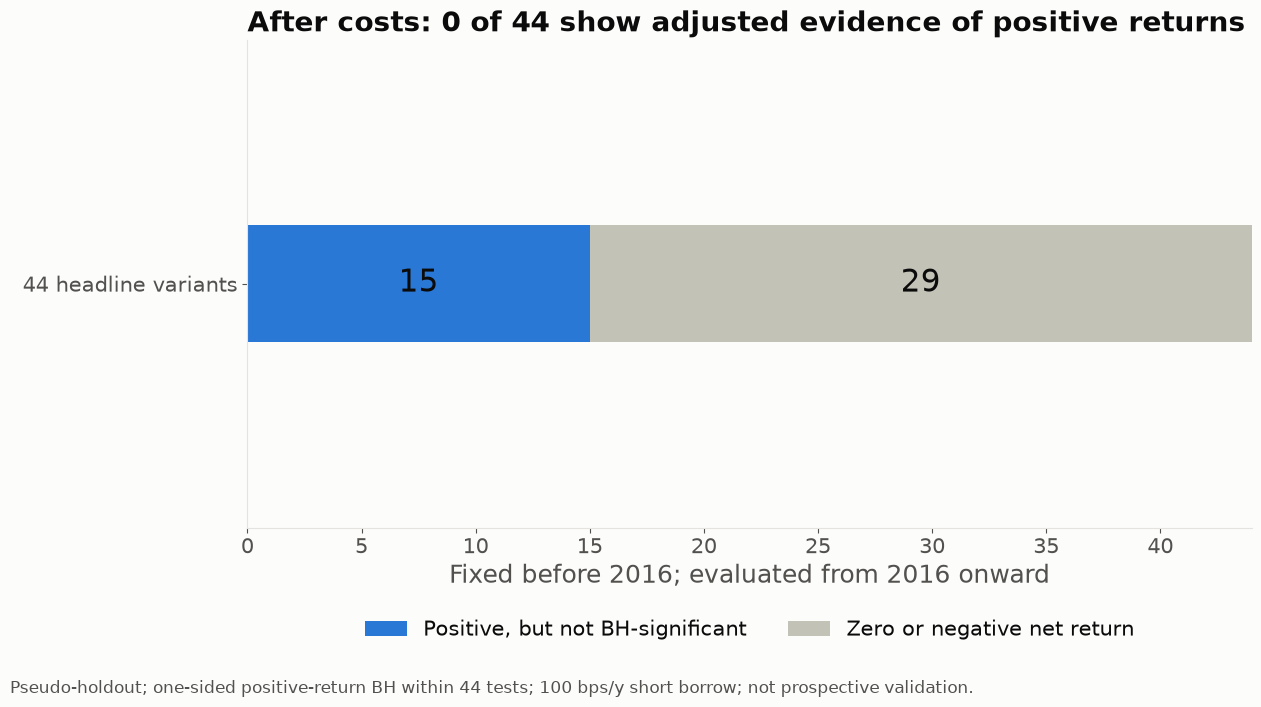

Replaced camera 10 with correctly adjusted fixed-sign profitability scorecard.


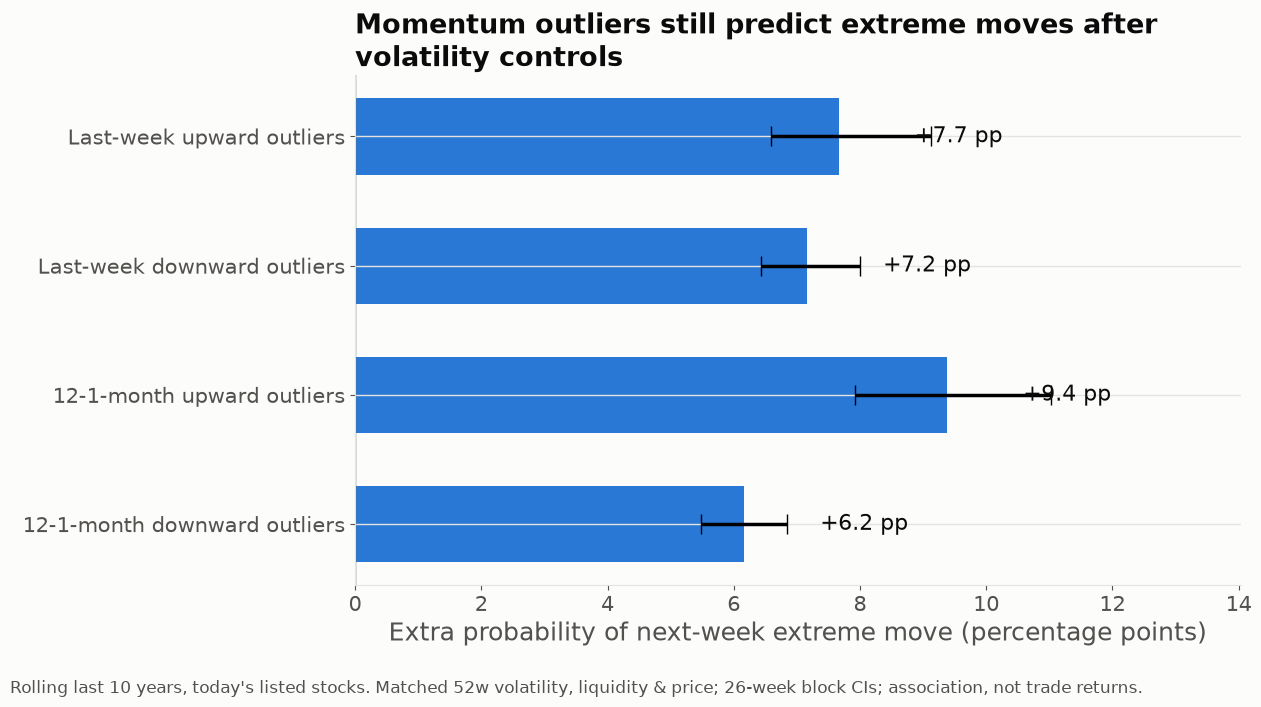

Camera 12: longer-volatility-adjusted conditional tail risk.


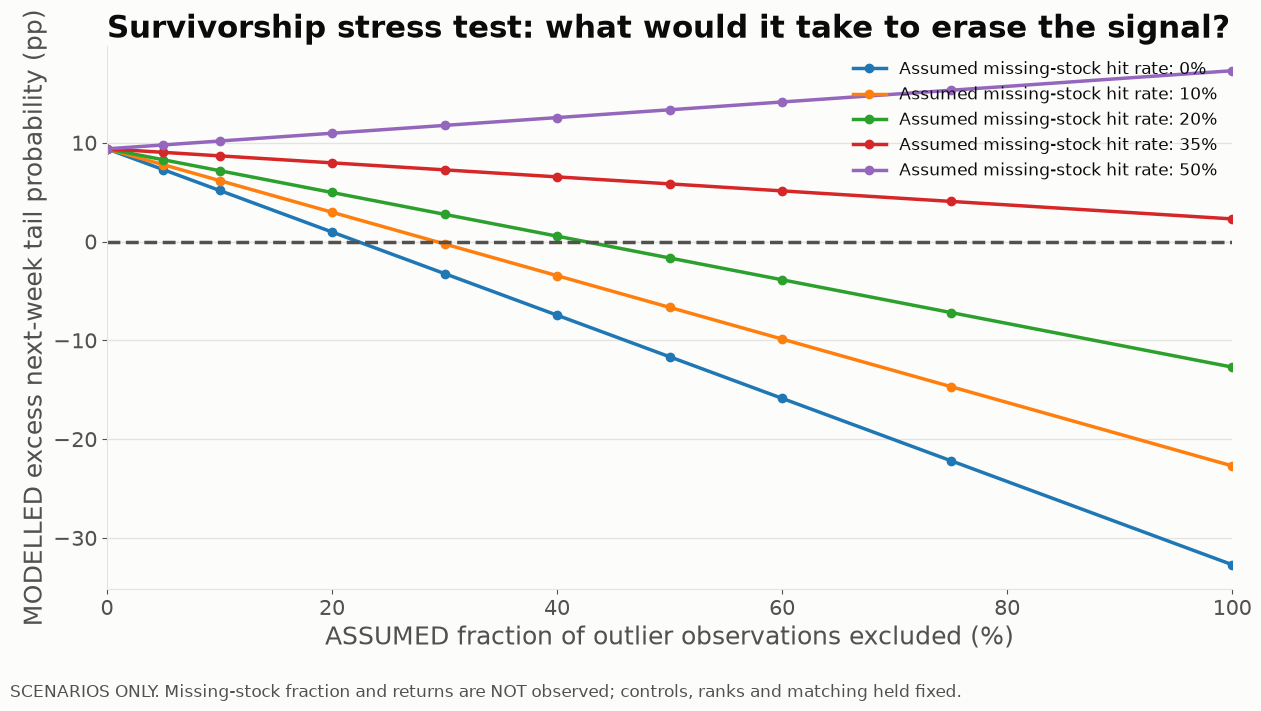

Camera 13 is a HYPOTHETICAL stress-test chart, not a measured historical-survivorship estimate.
Price coverage through 2026-10-16 ; verify same-date factor and corporate-action updates.
Direct bias conclusion: NOT IDENTIFIABLE FROM CURRENT SURVIVORS OR KEN FRENCH AGGREGATES
Validated v7 inference and scenario code. Output files: outputs_v7


In [70]:
# Camera figures are written to outputs_v7/camera/, never reusing outputs_v6.
if not oos.empty:
    selected = oos[(oos.test_family=='headline_44') & (oos.borrow_bps_per_year==100)].copy()
    winners = int(selected.positive_and_q_lt_005.sum())
    pos_not_sig = int(((selected.test_net_active_ann > 0) & ~selected.positive_and_q_lt_005).sum())
    nonpositive = int((selected.test_net_active_ann <= 0).sum())
    if len(selected) == 44 and winners + pos_not_sig + nonpositive == 44:
        with plt.rc_context(CAM_RC):
            fig, ax = plt.subplots()
            cs = [winners, pos_not_sig, nonpositive]
            colors = [SERIES[2], SERIES[0], MUTED]
            labels = ['Positive and one-sided BH q < 0.05',
                      'Positive, but not BH-significant', 'Zero or negative net return']
            left = 0
            for count, color, label in zip(cs, colors, labels):
                if count:
                    ax.barh([0], [count], left=left, height=.43, color=color, label=label)
                    if count >= 2:
                        ax.text(left+count/2,0,str(count),ha='center',va='center',fontsize=22,color=INK)
                    left += count
            ax.set_xlim(0,44)
            ax.set_ylim(-.9,.9)
            ax.set_yticks([0],['44 headline variants'])
            ax.set_xlabel('Fixed before 2016; evaluated from 2016 onward')
            ax.set_title(f'After costs: {winners} of 44 show adjusted evidence of positive returns')
            ax.grid(False)
            ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
            cam_save(fig,'10_scoreboard.png',
                     note='Pseudo-holdout; one-sided positive-return BH within 44 tests; 100 bps/y short borrow; not prospective validation.')
        print('Replaced camera 10 with correctly adjusted fixed-sign profitability scorecard.')
    else:
        print('Scorecard not regenerated: missing/incomplete pseudo-holdout family; old in-sample figure must NOT be used.')
else:
    print('Scorecard not regenerated: no valid pseudo-holdout results.')

if not V6_MATCHED.empty:
    d = V6_MATCHED.query('period=="recent" and outcome=="either" and matching=="52w volatility + liquidity + price"').copy()
    ords=[('1w','up'),('1w','down'),('12-1','up'),('12-1','down')]
    d['key'] = list(zip(d.lookback,d.direction))
    d=d.set_index('key').reindex(ords)
    if d.excess_pp.notna().all():
        y=np.arange(len(d))[::-1]
        diff=d.excess_pp.to_numpy(dtype=float)
        low=np.clip(diff-d.block_CI_low_pp.to_numpy(dtype=float),0,None)
        high=np.clip(d.block_CI_high_pp.to_numpy(dtype=float)-diff,0,None)
        with plt.rc_context(CAM_RC):
            fig,ax=plt.subplots()
            ax.barh(y,diff,color=SERIES[0],height=.59,xerr=np.vstack([low,high]),capsize=7)
            ax.axvline(0,color=INK2,linewidth=1)
            ax.set_yticks(y,['Last-week upward outliers','Last-week downward outliers',
                             '12-1-month upward outliers','12-1-month downward outliers'])
            ax.set_xlabel('Extra probability of next-week extreme move (percentage points)')
            ax.set_title('Momentum outliers still predict extreme moves after volatility controls')
            ax.set_xlim(min(0, np.nanmin(diff-low)-1), np.nanmax(diff+high)+3)
            for pos,r in zip(y,d.itertuples()):
                ax.text(r.excess_pp+1.2,pos,f'+{r.excess_pp:.1f} pp',ha='left',va='center',fontsize=16)
            cam_save(fig,'12_volatility_adjusted_extreme_move_risk.png',
                     note='Rolling last 10 years, today\'s listed stocks. Matched 52w volatility, liquidity & price; 26-week block CIs; association, not trade returns.')
        print('Camera 12: longer-volatility-adjusted conditional tail risk.')

if not V7_BIAS_SCENARIOS.empty:
    pick=V7_BIAS_SCENARIOS.query('lookback=="12-1" and direction=="up"').copy()
    with plt.rc_context(CAM_RC):
        fig,ax=plt.subplots()
        for h in (0.0,.1,.2,.35,.5):
            line=pick[pick.missing_outlier_tail_hit_probability_ASSUMED==h].sort_values('missing_outlier_share_ASSUMED')
            if not line.empty:
                ax.plot(100*line.missing_outlier_share_ASSUMED,line.counterfactual_excess_pp_MODEL,
                        marker='o',label=f'Assumed missing-stock hit rate: {h:.0%}')
        ax.axhline(0,color=INK2,linestyle='--')
        ax.set_xlim(0,100)
        ax.set_xlabel('ASSUMED fraction of outlier observations excluded (%)')
        ax.set_ylabel('MODELLED excess next-week tail probability (pp)')
        ax.set_title('Survivorship stress test: what would it take to erase the signal?')
        ax.legend(loc='upper right',fontsize=12)
        cam_save(fig,'13_survivorship_HYPOTHETICAL_sensitivity.png',
                 note='SCENARIOS ONLY. Missing-stock fraction and returns are NOT observed; controls, ranks and matching held fixed.')
    print('Camera 13 is a HYPOTHETICAL stress-test chart, not a measured historical-survivorship estimate.')

# Regression test: negative significant tests cannot improve one-sided profit BH ranks.
_dummy_t=np.array([3.0, 2.8, -12.0, -11.0])
_pplus=norm.sf(_dummy_t)
_qplus=multipletests(_pplus,method='fdr_bh')[1]
assert all(_pplus[_dummy_t<=0] >= .5)
assert all(_qplus[_dummy_t<=0] >= .5)

# Stress function: f=0 gives observed difference, f=1 gives assumed missing population difference.
_s,_t,_b=v7_sensitivity_from_observed(.275,.20,missing_fractions=[0.,1.],missing_event_rates=[.10])
assert np.isclose(_s.iloc[0].counterfactual_excess_pp_MODEL,7.5)
assert np.isclose(_s.iloc[1].counterfactual_excess_pp_MODEL,-10.0)
assert np.isclose(_t.iloc[0].missing_share_required_to_erase_excess_MODEL,7.5/17.5)
assert _b.iloc[1].worst_case_lower_pp <= -90
if not oos.empty:
    assert 'test_net_q_bh_positive' in oos
    assert oos.query('borrow_bps_per_year==100').positive_and_q_lt_005.equals(
        ((oos.query('borrow_bps_per_year==100').test_net_active_ann > 0) &
         (oos.query('borrow_bps_per_year==100').test_net_q_bh_positive < .05)))
last_week=pd.Timestamp(weeks[-1])
ref_date=pd.Timestamp('2026-10-16')
if last_week < ref_date:
    print(f'PRICE DATA WARNING: last complete source week is {last_week.date()}, before 2026-10-16. Re-run section 2 with UPDATE_PRICES_TO set and verify sources.')
else:
    print('Price coverage through',last_week.date(),'; verify same-date factor and corporate-action updates.')
print('Direct bias conclusion:',V7_DIRECT_BIAS_STATUS)
print('Validated v7 inference and scenario code. Output files:',OUT_DIR)


## Sources (for the description)

- Jegadeesh & Titman (1993), Returns to Buying Winners and Selling Losers, *Journal of Finance*.
- Jegadeesh (1990), Evidence of Predictable Behavior of Security Returns, *Journal of Finance*; Lehmann (1990), Fads, Martingales, and Market Efficiency, *Quarterly Journal of Economics*.
- Moskowitz & Grinblatt (1999), Do Industries Explain Momentum?, *Journal of Finance*.
- Da, Gurun & Warachka (2014), Frog in the Pan: Continuous Information and Momentum, *Review of Financial Studies*.
- Chan (2003), Stock Price Reaction to News and No-News: Drift and Reversal After Headlines, *Journal of Financial Economics*.
- Gervais, Kaniel & Mingelgrin (2001), The High-Volume Return Premium, *Journal of Finance*.
- Blitz, Huij & Martens (2011), Residual Momentum, *Journal of Empirical Finance*.
- Cooper, Gutierrez & Hameed (2004), Market States and Momentum, *Journal of Finance*; Daniel & Moskowitz (2016), Momentum Crashes, *Journal of Financial Economics*.
- Stivers & Sun (2010), Cross-Sectional Return Dispersion and Time Variation in Value and Momentum Premiums, *JFQA*; Huang (2022), The Momentum Gap and Return Predictability, *Review of Financial Studies*.
- Fama & MacBeth (1973), Risk, Return, and Equilibrium: Empirical Tests, *Journal of Political Economy*.
- Birru (2018), Day of the Week and the Cross-Section of Returns, *Journal of Financial Economics*.
- Corwin & Schultz (2012), A Simple Way to Estimate Bid-Ask Spreads from Daily High and Low Prices, *Journal of Finance*; Abdi & Ranaldo (2017), A Simple Estimation of Bid-Ask Spreads from Daily Close, High, and Low Prices, *Review of Financial Studies*.
- Blume & Stambaugh (1983), Biases in Computed Returns: An Application to the Size Effect, *Journal of Financial Economics*.
- Newey & West (1987, 1994); Lo (2002), The Statistics of Sharpe Ratios, *Financial Analysts Journal*; Ledoit & Wolf (2008), Robust Performance Hypothesis Testing with the Sharpe Ratio, *Journal of Empirical Finance*; Benjamini & Hochberg (1995).
- Data: Yahoo Finance via yfinance; Kenneth R. French Data Library; SEC EDGAR (company tickers, exchanges, SIC codes, state of incorporation, 8-K filings).
- Kenneth R. French Data Library: https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html (historical CRSP-based membership; not an exact matched sample to this notebook).

- CRSP/Fama-French methodology: https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2_daily.html ; https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_6_port_form_sz_pr_12_2_daily.html (historic listings, formation rules).

- US Copyright Office fair use explanation: https://www.copyright.gov/fair-use/
- 17 USC 107: https://uscode.house.gov/us/usc/119-118/t17/s107/
- WRDS CIZ change notice: https://wrds-www.wharton.upenn.edu/pages/data-announcements/changes-to-crsp-data/
- WRDS CIZ compounding: https://wrds-www.wharton.upenn.edu/pages/wrds-research/macros/wrds-macro-compound-ciz/
- CRSP via WRDS: confirm your institution's and vendor's **specific** permitted publication/use terms.

The notebook includes **NO paid-provider raw data or API keys**. Any sample in unit tests is explicitly synthetic.
- **Quantitative survivorship stress test (section 41):** user-specified missing-outlier shares and conditional outcomes, not measured selection rates. Interval arithmetic is an assumption-based partial identification exercise, not a vendor-data estimate.
